# Terraform Benchmark Pipeline (streamlined)

## Dependencies (run once per environment)

## §0 Configuration & Imports

In [1]:
import os
import re
import io
import json
import time
import shutil
import signal
import random
import hashlib
import difflib
import pathlib
import tempfile
import threading
import subprocess
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import tiktoken
import hcl2
from IPython.display import display
from tqdm.auto import tqdm

plt.style.use('ggplot')
sns.set_palette('muted')

BASE_DIR       = pathlib.Path('./iac_benchmark')
REPOS_DIR      = BASE_DIR / 'repos'
DATASET_DIR    = BASE_DIR / 'dataset'
MULTI_ROOT_DIR = BASE_DIR / 'scenarios'
GREENFIELD_DIR = Path('iac_benchmark/scenarios_greenfield')

for d in [REPOS_DIR, DATASET_DIR, MULTI_ROOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LICENCE_CACHE           = DATASET_DIR / 'licence_cache.csv'
CLONE_CACHE_FILE        = DATASET_DIR / 'clone_cache.json'
TERRADS_CACHE_FILE      = DATASET_DIR / 'terrads_scenarios.csv'
MULTI_IAC_EVAL_TF_CACHE = DATASET_DIR / 'multi_iac_eval_tf_cache.json'
AWS_CHECK_CACHE         = DATASET_DIR / 'aws_scrub_cache.csv'
PARSE_CACHE_FILE        = DATASET_DIR / 'ast_parse_cache.csv'
AWS_SERVICES_CACHE      = DATASET_DIR / 'aws_services_cache.csv'
MANUAL_FIX_FINGERPRINTS = DATASET_DIR / 'manual_fix_fingerprints.json'
VALIDATION_QUEUE        = DATASET_DIR / 'validation_pipeline_batch.csv'
TFLINT_CACHE_FILE       = DATASET_DIR / 'tflint_cache.csv'
TFLINT_PASSED_CSV       = DATASET_DIR / 'tflint_passed_batch.csv'
TF_VALIDATE_CACHE       = DATASET_DIR / 'tf_validate_cache.csv'
TF_VALIDATE_PASSED_CSV  = DATASET_DIR / 'tf_validate_passed_batch.csv'
TRIVY_CACHE_FILE        = DATASET_DIR / 'trivy_cache.csv'
TRIVY_SCANNED_CSV       = DATASET_DIR / 'trivy_scanned_batch.csv'
TRIVY_FILTERED_CSV      = DATASET_DIR / 'trivy_filtered_batch.csv'
DEPLOY_CACHE_FILE       = DATASET_DIR / 'deploy_cache.csv'
DEPLOY_PASSED_CSV       = DATASET_DIR / 'deploy_passed_batch.csv'
GT_DEPLOY_CACHE_PATH    = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'
REAL_AWS_POOL_CSV       = DATASET_DIR / 'tf_real_aws_candidate_pool.csv'
REAL_AWS_PROMPTS_CSV    = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
REAL_AWS_CUSTOM_CSV     = DATASET_DIR / 'final_benchmark_real_aws_custom.csv'
FINAL_EVAL_CSV          = DATASET_DIR / 'tf_eval_benchmark_real_aws.csv'

env = os.environ.copy()
env["PATH"] = f"/opt/homebrew/bin:{env['PATH']}"
TF_PLUGIN_CACHE_DIR = (BASE_DIR / ".tf_plugin_cache").resolve()
TF_PLUGIN_CACHE_DIR.mkdir(parents=True, exist_ok=True)

AWS_PROFILE = os.environ.get('AWS_PROFILE', 'senatwo')
AWS_REGION = os.environ.get('AWS_REGION', 'us-east-1')
os.environ['AWS_PROFILE'] = AWS_PROFILE
os.environ['AWS_REGION'] = AWS_REGION


import os
import requests

if os.environ.get('GITHUB_TOKEN'):
    GITHUB_TOKEN = os.environ['GITHUB_TOKEN']
    print('✅ Using GITHUB_TOKEN from environment.')
else:
    import getpass
    print('No GITHUB_TOKEN found in environment.')
    GITHUB_TOKEN = getpass.getpass('Paste a GitHub personal access token (leave blank to continue unauthenticated): ').strip()
    if GITHUB_TOKEN:
        os.environ['GITHUB_TOKEN'] = GITHUB_TOKEN
        print('✅ Token captured for this session (not written to disk).')
    else:
        print('⚠️  Continuing unauthenticated -- 60 req/hr (core) / 10 req/min (search) limits apply.')

GH_HEADERS = {'Authorization': f'token {GITHUB_TOKEN}'} if GITHUB_TOKEN else {}

try:
    r = requests.get('https://api.github.com/rate_limit', headers=GH_HEADERS, timeout=15)
    if r.status_code == 200:
        core = r.json()['resources']['core']
        search = r.json()['resources']['search']
        auth_state = 'authenticated' if GITHUB_TOKEN else 'unauthenticated'
        print(f'\nGitHub API quota ({auth_state}):')
        print(f'  core   : {core["remaining"]}/{core["limit"]} per hour')
        print(f'  search : {search["remaining"]}/{search["limit"]} per minute-window')
    elif r.status_code == 401:
        print('\n❌ Token rejected (401 Unauthorized) -- check it was copied correctly / has not expired.')
        print('   Falling back to unauthenticated GH_HEADERS for the rest of this session.')
        GITHUB_TOKEN = ''
        GH_HEADERS = {}
    else:
        print(f'\n⚠️  Could not verify quota (HTTP {r.status_code}) -- proceeding with current GH_HEADERS anyway.')
except requests.exceptions.RequestException as e:
    print(f'\n⚠️  Could not reach GitHub to verify quota ({e}) -- proceeding with current GH_HEADERS anyway.')


MIN_LOC    = 5
MAX_TOKENS = 8_000
DISCARD_MIN_LOC       = 10
DISCARD_MIN_RESOURCES = 1
TOKENIZER = tiktoken.get_encoding('cl100k_base')

TARGET_SAMPLE_PER_LEVEL = 100
TARGETS_PER_LEVEL = {1: 50, 2: 50, 3: 50, 4: 50, 5: 50}
DUP_THRESHOLD = 0.90

VALIDATE_WORKERS        = 6
VALIDATE_INIT_BACKEND   = False
VALIDATE_INIT_TIMEOUT_S = 300
VALIDATE_GIT_MODULE_INIT_TIMEOUT_S = 1800
VALIDATE_TIMEOUT_S      = 120
VALIDATE_MAX_NEW        = None
LAZY_VALIDATE_QUEUE     = True

PLAN_GATE_QUEUE         = True
PLAN_WORKERS            = 2
PLAN_TIMEOUT_S          = 900
MIN_AWS_RESOURCES       = 1
PLAN_RESOURCE_CACHE     = DATASET_DIR / 'tf_plan_resource_cache.csv'

RUN_REPO_CLEANUP        = True
PURGE_STALE_MANUAL_FIX_CACHES = False
RUN_VALIDATE_CANARY     = True
RUN_LOCALSTACK          = False
RUN_LOCALSTACK_DEBUG    = False
RUN_PREFLIGHT_SETUP     = True
RUN_REAL_AWS_DEBUG_PLAN = True
RUN_DEPLOYMENT          = True
RUN_NUKE_SWEEP          = False
RUN_POSTFLIGHT_TEARDOWN = True
ASSEMBLY_DRY_RUN        = True
ALLOW_MASS_DROP         = True
MASS_DROP_THRESHOLD     = 0.10

RESTORE_REFERENCE_COMPOSITION = True
RESTORE_REFERENCE_CSV   = DATASET_DIR / 'final_benchmark_real_aws_with_prompts_12Sep.csv'
PROMPT_OVERRIDES_CSV    = DATASET_DIR / 'manual_fix_prompt_overrides.csv'

DEBUG_SCENARIO_ID = None

ALLOWED_SPDX  = {'MIT', 'MIT-0', 'Apache-2.0', 'BSD-2-Clause', 'BSD-3-Clause',
                  'ISC', 'MPL-2.0', 'CC0-1.0', 'Unlicense', 'WTFPL'}
COPYLEFT_SPDX = {'GPL-2.0', 'GPL-3.0', 'LGPL-2.1', 'LGPL-3.0', 'AGPL-3.0'}
ALLOWED_SPDX_LICENCE = ALLOWED_SPDX
COPYLEFT_SPDX_LICENCE = COPYLEFT_SPDX
ELIGIBLE_SPDX = ALLOWED_SPDX | COPYLEFT_SPDX
EXEMPT_LICENCE_SOURCES = {'Zenodo/TerraDS', 'autoiac-project/iac-eval', 'AmazonScience/Multi-IaC-Eval'}

if LICENCE_CACHE.exists():
    licence_map = pd.read_csv(LICENCE_CACHE, index_col='slug')['spdx'].to_dict()
else:
    licence_map = {}

MANUAL_EXCLUDE_FOLDER_PATHS = {
    'near_duplicate': [
        'iac_benchmark/scenarios/terrads_559e5c90c3ea',
        'iac_benchmark/scenarios/terrads_ebaf7a67fef3',
        'iac_benchmark/scenarios/terrads_79d499359f89',
        'iac_benchmark/scenarios/terrads_586a9474fd96',
        'iac_benchmark/scenarios/terrads_f06187331dff',
        'iac_benchmark/scenarios/terrads_39c90624ffed',
        'iac_benchmark/scenarios/terrads_c92b260bc738',
        'iac_benchmark/scenarios/terrads_84f64c0c2376',
        'iac_benchmark/scenarios/terrads_c6dcc9b29983',
        'iac_benchmark/scenarios/terrads_916c37ccf307',
        'iac_benchmark/scenarios/terrads_6f97821a57ad',
        'iac_benchmark/scenarios/terrads_f86afb58a0d5',
        'iac_benchmark/scenarios/terrads_2d7923019d0c',
        'iac_benchmark/scenarios/terrads_48ad8a91b6a4',
        'iac_benchmark/scenarios/terrads_71c036ff15e5',
        'iac_benchmark/scenarios/terrads_8ac6bda76d9a',
        'iac_benchmark/scenarios/terrads_e3a38ad9c4b0',
        'iac_benchmark/scenarios/terrads_6bc966772840',
        'iac_benchmark/scenarios/terrads_dcfd05f3ba14',
    ],
    'deployer_policy_hazard': {
        'iac_benchmark/scenarios/gh_60daefa3',
    },
    'trivy_suppression': {
        'iac_benchmark/scenarios_greenfield/terrads_01334dedc4eb',
        'iac_benchmark/scenarios_greenfield/terrads_251b1cc05888',
        'iac_benchmark/scenarios_greenfield/terrads_9eab77581581',
        'iac_benchmark/scenarios_greenfield/terrads_d85ca07b31c2',
    },
}

MANUAL_EXCLUDE_SET = {p for paths in MANUAL_EXCLUDE_FOLDER_PATHS.values() for p in paths}

def calculate_difficulty_values(loc, n_resources):
    if loc >= 400 and n_resources >= 12: return 5
    elif loc >= 250 and n_resources >= 8: return 4
    elif loc >= 150 and n_resources >= 4: return 3
    elif loc >= 80 and n_resources >= 2: return 2
    else: return 1

def calculate_difficulty(row):
    return calculate_difficulty_values(row['loc'], row['n_resources'])


AWS_PATTERN = re.compile(r'(provider\s+"aws"|resource\s+"aws_|data\s+"aws_)', re.MULTILINE)

class TimeoutException(Exception):
    pass

def timeout_handler(signum, frame):
    raise TimeoutException("Parser timed out!")

def parse_hcl2_safe(content, timeout_sec=2):
    if len(content.encode('utf-8')) > 150_000:
        return None
    old_handler = signal.signal(signal.SIGALRM, timeout_handler)
    signal.alarm(timeout_sec)
    try:
        return hcl2.load(io.StringIO(content))
    except Exception:
        return None
    finally:
        signal.alarm(0)
        signal.signal(signal.SIGALRM, old_handler)

def is_aws_scenario(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return False
        
    for tf_file in folder.glob('*.tf'):
        content = tf_file.read_text(encoding='utf-8', errors='ignore')
        
        ast = parse_hcl2_safe(content)
        if ast:
            for p in ast.get('provider', []):
                if 'aws' in p or '"aws"' in p: return True
            for r in ast.get('resource', []):
                if any(str(rtype).strip('"').startswith('aws_') for rtype in r.keys()): return True
            for d in ast.get('data', []):
                if any(str(dtype).strip('"').startswith('aws_') for dtype in d.keys()): return True
        
        if AWS_PATTERN.search(content):
            return True
            
    return False

def get_aws_services(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return ""
    services = set()
    for tf_file in folder.glob('*.tf'):
        content = tf_file.read_text(encoding='utf-8', errors='ignore')
        services.update(re.findall(r'(?:resource|data)\s+"(aws_[a-zA-Z0-9_]+)"', content))
    return ", ".join(sorted(services))

def sample_diverse(df_candidates, target, group_col='aws_services', seed=42, existing_group_counts=None):
    df_shuffled = df_candidates.sample(frac=1, random_state=seed).reset_index(drop=True)
    grouped = [(k, g.to_dict('records')) for k, g in df_shuffled.groupby(group_col)]
    import random
    random.seed(seed)
    random.shuffle(grouped)
    if existing_group_counts:
        grouped.sort(key=lambda kg: existing_group_counts.get(kg[0], 0))
    group_rows = [g for _, g in grouped]
    sampled = []
    while len(sampled) < target and group_rows:
        next_group_rows = []
        for g_list in group_rows:
            if len(sampled) >= target: break
            if g_list: sampled.append(g_list.pop(0))
            if g_list: next_group_rows.append(g_list)
        group_rows = next_group_rows
    return pd.DataFrame(sampled)

def _block_key(row):
    return (row['n_resources'], frozenset(str(row.get('aws_services', '')).split(', ')))

def read_tf_content(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return ""
    tf_files = sorted(folder.glob('*.tf'))
    return "\n\n".join(f.read_text(encoding='utf-8', errors='ignore').strip() for f in tf_files)


def is_aws_scenario_fast(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return False
    for tf_file in folder.glob('*.tf'):
        try:
            if AWS_PATTERN.search(tf_file.read_text(encoding='utf-8', errors='ignore')):
                return True
        except Exception:
            continue
    return is_aws_scenario(folder_path_str)


def is_licence_eligible(source):
    if source in EXEMPT_LICENCE_SOURCES:
        return True
    return licence_map.get(source) in ELIGIBLE_SPDX


def _append_rows_to_cache(path, rows, columns):
    if not rows:
        return
    path = Path(path)
    df = pd.DataFrame(rows)
    if path.exists() and path.stat().st_size > 0:
        header = pd.read_csv(path, nrows=0).columns
        df.reindex(columns=header).to_csv(path, mode='a', header=False, index=False)
    else:
        df.reindex(columns=columns).to_csv(path, index=False)


def _as_bool_series(s):
    return s.fillna('').astype(str).str.strip().str.lower() == 'true'


def _base_id(sid):
    return re.sub(r'_manualfix$', '', str(sid))


_VAR_BLOCK_RE = re.compile(r'^\s*variable\s+("?)([A-Za-z0-9_\-]+)\1\s*\{', re.MULTILINE)

def find_undefaulted_vars(folder_path):
    names = []
    for tf_file in sorted(Path(folder_path).glob('*.tf')):
        text = tf_file.read_text(encoding='utf-8', errors='ignore')
        text = re.sub(r'/\*.*?\*/', '', text, flags=re.DOTALL)
        text = '\n'.join(l for l in text.splitlines() if not l.lstrip().startswith(('#', '//')))
        for m in _VAR_BLOCK_RE.finditer(text):
            depth, i = 0, m.end() - 1
            while i < len(text):
                if text[i] == '{':
                    depth += 1
                elif text[i] == '}':
                    depth -= 1
                    if depth == 0:
                        break
                i += 1
            block = text[m.end():i]
            if not re.search(r'\bdefault\s*=', block):
                names.append(m.group(2))
    return names


def pick_debug_row(prefer_id=None, allow_manualfix=False):
    sid = prefer_id or DEBUG_SCENARIO_ID
    sources = [REAL_AWS_PROMPTS_CSV, TRIVY_FILTERED_CSV, TFLINT_CACHE_FILE, PARSE_CACHE_FILE]
    for src_path in sources:
        if not src_path.exists():
            continue
        df_src = pd.read_csv(src_path, usecols=['scenario_id', 'folder_path'], low_memory=False)
        if sid:
            hit = df_src[df_src['scenario_id'] == sid]
            if not hit.empty:
                return hit.iloc[0].to_dict()
            continue
        for _, r in df_src.iterrows():
            if not allow_manualfix and str(r['scenario_id']).endswith('_manualfix'):
                continue
            if Path(r['folder_path']).exists():
                return r.to_dict()
    raise LookupError(f"Could not find a debug scenario (DEBUG_SCENARIO_ID={sid!r}).")


def cached_row(path, scenario_id, usecols=None):
    path = Path(path)
    if not path.exists():
        return None
    df_c = pd.read_csv(path, usecols=usecols, low_memory=False)
    hit = df_c[df_c['scenario_id'] == scenario_id]
    return None if hit.empty else hit.iloc[-1].to_dict()


print('✅ Configuration loaded.')
print(f'  Workspace   : {BASE_DIR.resolve()}')
print(f'  Limits      : MIN_LOC={MIN_LOC}, MAX_TOKENS={MAX_TOKENS}')
print(f'  AWS profile : {AWS_PROFILE!r} (region {AWS_REGION!r})')
print(f'  AWS-touching flags: preflight={RUN_PREFLIGHT_SETUP} deploy={RUN_DEPLOYMENT} '
      f'nuke={RUN_NUKE_SWEEP} postflight={RUN_POSTFLIGHT_TEARDOWN} localstack={RUN_LOCALSTACK}')

No GITHUB_TOKEN found in environment.


Paste a GitHub personal access token (leave blank to continue unauthenticated):  ········


✅ Token captured for this session (not written to disk).

❌ Token rejected (401 Unauthorized) -- check it was copied correctly / has not expired.
   Falling back to unauthenticated GH_HEADERS for the rest of this session.
✅ Configuration loaded.
  Workspace   : /Users/iksena/Documents/research/data_analysis/iac_benchmark
  Limits      : MIN_LOC=5, MAX_TOKENS=8000
  AWS profile : 'senatwo' (region 'us-east-1')
  AWS-touching flags: preflight=True deploy=True nuke=False postflight=True localstack=False


### §0b Stage functions

In [2]:
def truncate_log(raw_text, max_len=1500):
    if not raw_text: return ""
    clean = str(raw_text).strip()
    if len(clean) > max_len:
        return clean[:(max_len//2)] + "\n\n...[LOG TRUNCATED]...\n\n" + clean[-(max_len//2):]
    return clean


def run_tflint(folder_path, return_raw=False):
    folder_path = Path(folder_path)
    tflint_log = ""
    raw = {'init_stdout': b'', 'init_stderr': b'', 'lint_stdout': '', 'lint_stderr': '', 'lint_returncode': None}

    with tempfile.TemporaryDirectory() as tmpdir:
        tmp_path = Path(tmpdir)
        for f in folder_path.glob('*.tf'):
            shutil.copy2(f, tmp_path / f.name)

        try:
            init_result = subprocess.run(
                ["tflint", "--init", "--no-color"],
                cwd=tmpdir, capture_output=True, timeout=120, env=env
            )
            raw['init_stdout'], raw['init_stderr'] = init_result.stdout, init_result.stderr

            lint_result = subprocess.run(
                ["tflint", "--format", "json", "--no-color"],
                cwd=tmpdir, capture_output=True, text=True, timeout=60, env=env
            )
            raw['lint_stdout'], raw['lint_stderr'], raw['lint_returncode'] = lint_result.stdout, lint_result.stderr, lint_result.returncode
            raw_out = lint_result.stdout or lint_result.stderr
            error_severity_count = 0
            log_lines = []

            try:
                data = json.loads(raw_out)
                for issue in data.get("issues", []):
                    rule = issue.get("rule", {})
                    severity = rule.get("severity", "error").lower()

                    if severity != "error":
                        continue

                    rule_id = rule.get("name", "?")
                    message = (issue.get("message") or "").strip()
                    line_num = issue.get("range", {}).get("start", {}).get("line")

                    parts = [f"[{rule_id}]", f"[{severity.upper()}]"]
                    if line_num: parts.append(f"line {line_num}")
                    if message: parts.append(message)
                    log_lines.append(" | ".join(parts))

                    error_severity_count += 1

                tflint_passed = (error_severity_count == 0)
                tflint_log = "\n".join(log_lines)

            except json.JSONDecodeError:
                tflint_passed = (lint_result.returncode == 0)
                tflint_log = f"NON-JSON OUTPUT:\n{truncate_log(raw_out)}"

        except subprocess.TimeoutExpired:
            tflint_passed = False
            tflint_log = "TIMEOUT: TFLint took longer than 60 seconds."
        except Exception as e:
            tflint_passed = False
            tflint_log = f"SYSTEM ERROR: {str(e)}"

    if return_raw:
        return tflint_passed, tflint_log, raw
    return tflint_passed, tflint_log


def run_trivy(folder_path, return_raw=False):
    folder_path = Path(folder_path)
    raw = {'stdout': '', 'stderr': '', 'returncode': None}

    with tempfile.TemporaryDirectory() as tmpdir:
        tmp_path = Path(tmpdir)
        for f in folder_path.glob('*.tf'):
            shutil.copy2(f, tmp_path / f.name)

        try:
            result = subprocess.run(["trivy", "config", "--format", "json", str(tmpdir)], capture_output=True, text=True, timeout=120, env=env)
            raw['stdout'], raw['stderr'], raw['returncode'] = result.stdout, result.stderr, result.returncode
            raw = {**raw, 'raw': result.stdout or result.stderr}
            raw_text = result.stdout or result.stderr
            counts = {"critical": 0, "high": 0, "medium": 0, "low": 0, "unknown": 0}

            try:
                data = json.loads(raw_text)
                for r in data.get("Results", []):
                    for m in r.get("Misconfigurations", []):
                        sev = m.get("Severity", "").lower()
                        if sev in counts: counts[sev] += 1
                        else: counts["unknown"] += 1
                trivy_scan_success = True
            except json.JSONDecodeError:
                trivy_scan_success = (result.returncode == 0)
        except Exception:
            trivy_scan_success = False
            counts = {"critical": 0, "high": 0, "medium": 0, "low": 0, "unknown": 0}

    if return_raw:
        return trivy_scan_success, counts, raw
    return trivy_scan_success, counts


VALIDATE_CACHE_COLS = ['scenario_id', 'folder_path', 'validate_init_ok', 'validate_passed',
                       'validate_error_count', 'undefaulted_vars', 'validate_log', 'validated_at']
_VALIDATE_INIT_LOCK = threading.Lock()
_PLUGIN_CACHE_RACE_HINTS = ('text file busy', 'does not match any of the checksums', 'cached package',
                            'failed to load plugin schemas', 'could not load the schema',
                            'the plugin cache', 'resource temporarily unavailable',
                            'exec format error', 'unrecognized remote plugin message', 'request cancelled')
_VALIDATE_INFRA_HINTS = _PLUGIN_CACHE_RACE_HINTS + (
    'timeout:', 'system error:', 'failed to install provider', 'failed to query available provider packages',
    'could not connect', 'dial tcp', 'i/o timeout', 'no such host', 'connection reset', 'tls handshake',
    'registry.terraform.io: ', 'error accessing remote module registry', 'context deadline exceeded')


def _is_infra_failure(rec):
    if rec.get('validate_passed'):
        return False
    return any(h in str(rec.get('validate_log', '')).lower() for h in _VALIDATE_INFRA_HINTS)

validate_env = env.copy()
validate_env['TF_PLUGIN_CACHE_DIR'] = str(TF_PLUGIN_CACHE_DIR)
validate_env['TF_IN_AUTOMATION'] = '1'
validate_env['TF_PLUGIN_CACHE_MAY_BREAK_DEPENDENCY_LOCK_FILE'] = 'true'
validate_env['GIT_TERMINAL_PROMPT'] = '0'
_REMOTE_GIT_MODULE_RE = re.compile(r'source\s*=\s*"(?:git::|git@|github\.com/|bitbucket\.org/)')


def _run_killable(args, cwd, timeout, env):
    p = subprocess.Popen(args, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
                         env=env, start_new_session=True)
    try:
        out, err = p.communicate(timeout=timeout)
    except subprocess.TimeoutExpired:
        try:
            os.killpg(p.pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
        p.communicate()
        raise subprocess.TimeoutExpired(args, timeout)
    return subprocess.CompletedProcess(args, p.returncode, out, err)


def run_terraform_validate(folder_path, return_raw=False):
    rec, raw = _run_terraform_validate_once(folder_path)
    if not rec['validate_passed'] and any(
            h in (str(rec['validate_log']) + raw.get('init_output', '')).lower() for h in _PLUGIN_CACHE_RACE_HINTS):
        with _VALIDATE_INIT_LOCK:
            rec, raw = _run_terraform_validate_once(folder_path)
        raw['retried_after_plugin_cache_race'] = True
    rec['validate_infra_error'] = _is_infra_failure(rec)
    return (rec, raw) if return_raw else rec


def _run_terraform_validate_once(folder_path, return_raw=True):
    folder = Path(folder_path)
    rec = {'validate_init_ok': False, 'validate_passed': False, 'validate_error_count': None,
           'undefaulted_vars': '', 'validate_log': ''}
    raw = {'init_cmd': '', 'init_returncode': None, 'init_output': '',
           'validate_returncode': None, 'validate_stdout': '', 'validate_stderr': ''}
    if not folder.exists():
        rec['validate_log'] = 'SYSTEM ERROR: folder missing'
        return (rec, raw) if return_raw else rec
    rec['undefaulted_vars'] = ', '.join(find_undefaulted_vars(folder))

    init_args = ['terraform', 'init', '-input=false', '-no-color']
    if not VALIDATE_INIT_BACKEND:
        init_args.insert(2, '-backend=false')
    raw['init_cmd'] = ' '.join(init_args)
    init_timeout = VALIDATE_INIT_TIMEOUT_S
    if any(_REMOTE_GIT_MODULE_RE.search(f.read_text(errors='ignore')) for f in folder.glob('*.tf')):
        init_timeout = max(init_timeout, globals().get('VALIDATE_GIT_MODULE_INIT_TIMEOUT_S', 1800))

    with tempfile.TemporaryDirectory(prefix='tf_validate_') as tmpdir:
        for f in folder.glob('*.tf'):
            shutil.copy2(f, Path(tmpdir) / f.name)
        try:
            r = _run_killable(init_args, cwd=tmpdir, timeout=init_timeout, env=validate_env)
            if r.returncode != 0 and any(h in (r.stdout + r.stderr).lower() for h in _PLUGIN_CACHE_RACE_HINTS):
                with _VALIDATE_INIT_LOCK:
                    r = _run_killable(init_args, cwd=tmpdir, timeout=init_timeout, env=validate_env)
            raw['init_returncode'], raw['init_output'] = r.returncode, r.stdout + r.stderr
            if r.returncode != 0:
                rec['validate_log'] = 'INIT FAILED:\n' + truncate_log(r.stdout + r.stderr, max_len=4000)
                return (rec, raw) if return_raw else rec
            rec['validate_init_ok'] = True

            v = _run_killable(['terraform', 'validate', '-json', '-no-color'], cwd=tmpdir, timeout=VALIDATE_TIMEOUT_S, env=validate_env)
            raw['validate_returncode'], raw['validate_stdout'], raw['validate_stderr'] = v.returncode, v.stdout, v.stderr
            try:
                data = json.loads(v.stdout)
                rec['validate_passed'] = bool(data.get('valid'))
                rec['validate_error_count'] = int(data.get('error_count', 0))
                lines = []
                for d in data.get('diagnostics', []):
                    if d.get('severity') != 'error':
                        continue
                    rng = d.get('range') or {}
                    loc = f"{rng.get('filename')}:{(rng.get('start') or {}).get('line')}" if rng else ''
                    parts = ['[ERROR]']
                    if loc: parts.append(loc)
                    parts.append((d.get('summary') or '').strip())
                    if d.get('detail'): parts.append(d['detail'].strip())
                    lines.append(' | '.join(parts))
                rec['validate_log'] = truncate_log('\n'.join(lines), max_len=4000)
            except json.JSONDecodeError:
                rec['validate_passed'] = False
                rec['validate_log'] = 'NON-JSON OUTPUT:\n' + truncate_log(v.stdout or v.stderr, max_len=4000)
        except subprocess.TimeoutExpired as e:
            rec['validate_log'] = f"TIMEOUT: {' '.join(e.cmd[:3]) if isinstance(e.cmd, list) else e.cmd}"
        except Exception as e:
            rec['validate_log'] = f'SYSTEM ERROR: {e}'
    return (rec, raw) if return_raw else rec


def load_validate_cache():
    if TF_VALIDATE_CACHE.exists() and TF_VALIDATE_CACHE.stat().st_size > 0:
        return pd.read_csv(TF_VALIDATE_CACHE, low_memory=False).drop_duplicates('scenario_id', keep='last')
    return pd.DataFrame(columns=VALIDATE_CACHE_COLS)


def get_validate_status_map():
    c = load_validate_cache()
    if c.empty:
        return {}
    passed = _as_bool_series(c['validate_passed'])
    infra = (~passed) & c['validate_log'].fillna('').astype(str).str.lower().map(
        lambda t: any(h in t for h in _VALIDATE_INFRA_HINTS))
    c = c[~infra]
    return dict(zip(c['scenario_id'], np.where(_as_bool_series(c['validate_passed']), 'pass', 'fail')))


def validate_scenarios(records, max_new=VALIDATE_MAX_NEW, save_every=10, desc='terraform validate'):
    _vc = load_validate_cache()
    if _vc.empty:
        done = set()
    else:
        _infra = (~_as_bool_series(_vc['validate_passed'])) & _vc['validate_log'].fillna('').astype(str).str.lower().map(
            lambda t: any(h in t for h in _VALIDATE_INFRA_HINTS))
        done = set(_vc.loc[~_infra, 'scenario_id'])
    todo, seen = [], set()
    for r in records:
        sid = r['scenario_id']
        if sid in done or sid in seen:
            continue
        seen.add(sid)
        todo.append({'scenario_id': sid, 'folder_path': r['folder_path']})
    if max_new is not None:
        todo = todo[:max_new]
    print(f"{desc}: {len(done & {r['scenario_id'] for r in records}):,} cached, {len(todo):,} to run "
          f"({VALIDATE_WORKERS} workers).")
    if not todo:
        return
    buffer, n_done, n_pass, n_infra = [], 0, 0, 0
    with ThreadPoolExecutor(max_workers=VALIDATE_WORKERS) as pool:
        futures = {pool.submit(run_terraform_validate, r['folder_path']): r for r in todo}
        for fut in as_completed(futures):
            r = futures[fut]
            try:
                res = fut.result()
            except Exception as e:
                res = {'validate_init_ok': False, 'validate_passed': False, 'validate_error_count': None,
                       'undefaulted_vars': '', 'validate_log': f'SYSTEM ERROR: {e}', 'validate_infra_error': True}
            n_done += 1
            if res.get('validate_infra_error'):
                n_infra += 1
                print(f"  ⚠️ infra error (not cached, will retry next run): {r['scenario_id']}: "
                      f"{str(res['validate_log']).splitlines()[0][:120]}")
                continue
            buffer.append({**r, **res, 'validated_at': datetime.now().isoformat(timespec='seconds')})
            n_pass += int(bool(res['validate_passed']))
            if len(buffer) >= save_every:
                _append_rows_to_cache(TF_VALIDATE_CACHE, buffer, VALIDATE_CACHE_COLS)
                buffer.clear()
            if n_done % 25 == 0:
                print(f"  -> validated {n_done}/{len(todo)} (passed so far: {n_pass})")
    _append_rows_to_cache(TF_VALIDATE_CACHE, buffer, VALIDATE_CACHE_COLS)
    print(f"✅ {desc}: {n_pass}/{len(todo)} newly validated scenario(s) passed.")


_TRIVY_SUPPRESSION_RE = re.compile(r'(?:trivy|tfsec):ignore', re.I)


_TRIVY_SUPPRESSION_CACHE = {}


def has_trivy_suppression(folder_path):
    if folder_path in _TRIVY_SUPPRESSION_CACHE:
        return _TRIVY_SUPPRESSION_CACHE[folder_path]
    d = pathlib.Path(folder_path)
    hit = d.exists() and any(
        _TRIVY_SUPPRESSION_RE.search(f.read_text(errors='ignore')) for f in d.glob('*.tf'))
    _TRIVY_SUPPRESSION_CACHE[folder_path] = hit
    return hit


_PRESCREEN_VAR_RE = re.compile(r'^\s*variable\s+("?)([A-Za-z0-9_-]+)\1\s*\{', re.M)
_PRESCREEN_DEFAULT_RE = re.compile(r'(?<![#/\w])default\s*=')
_PRESCREEN_ASSET_RE = re.compile(
    r'(?:templatefile|file|filebase64|filemd5|filebase64sha256)\s*\(\s*"([^"${}]+)"')
_PRESCREEN_SRC_RE = re.compile(r'source_(?:dir|file)\s*=\s*"([^"${}]+)"')
_PRESCREEN_CACHE = {}


def _prescreen_strip_comments(text):
    text = re.sub(r'/\*.*?\*/', '', text, flags=re.S)
    return '\n'.join(re.sub(r'(#|//).*$', '', ln) for ln in text.split('\n'))


def _prescreen_variable_blocks(src):
    for m in _PRESCREEN_VAR_RE.finditer(src):
        i = src.index('{', m.end() - 1)
        depth = 0
        for j in range(i, len(src)):
            if src[j] == '{':
                depth += 1
            elif src[j] == '}':
                depth -= 1
                if depth == 0:
                    yield m.group(2), src[i:j + 1]
                    break


def prescreen_deploy_blockers(folder_path):
    if folder_path in _PRESCREEN_CACHE:
        return _PRESCREEN_CACHE[folder_path]
    d = pathlib.Path(folder_path)
    tf_files = list(d.glob('*.tf'))
    if not tf_files:
        _PRESCREEN_CACHE[folder_path] = ['no_tf_files']
        return _PRESCREEN_CACHE[folder_path]
    undefaulted, missing = [], []
    for f in tf_files:
        src = _prescreen_strip_comments(f.read_text(errors='ignore'))
        for name, body in _prescreen_variable_blocks(src):
            if not _PRESCREEN_DEFAULT_RE.search(body):
                undefaulted.append(name)
        for rx in (_PRESCREEN_ASSET_RE, _PRESCREEN_SRC_RE):
            for m in rx.finditer(src):
                p = m.group(1)
                if p.startswith(('http://', 'https://')):
                    continue
                rel = p.replace('${path.module}', '.').replace('${path.root}', '.').lstrip('./')
                if not (d / rel).exists() and not (d / pathlib.Path(rel).name).exists():
                    missing.append(p)
    reasons = []
    if undefaulted:
        reasons.append(f"undefaulted_variable({','.join(sorted(set(undefaulted))[:6])})")
    if missing:
        reasons.append(f"missing_local_asset({','.join(sorted(set(missing))[:3])})")
    _PRESCREEN_CACHE[folder_path] = reasons
    return reasons


DEPLOYER_POLICY_NAMES = {'AdministratorAccess', 'PowerUserAccess', 'IAMFullAccess'}
_EXCLUSIVE_ATTACH_RE = re.compile(r'resource\s+"aws_iam_policy_attachment"\s+"[^"]+"\s*\{(.*?)\n\}', re.S)
_POLICY_ARN_VALUE_RE = re.compile(r'policy_arn\s*=\s*([^\n#]+)')
_ACCOUNT_HAZARD_CACHE = {}


def _attached_policy_names(value, all_src):
    value = value.strip()
    if re.match(r'aws_iam_policy\.[A-Za-z0-9_-]+(\[[^\]]*\])?\.arn$', value):
        return set()
    literal = re.fullmatch(r'"([^"]*)"', value)
    if literal:
        return {literal.group(1).rsplit('/', 1)[-1]}
    data = re.fullmatch(r'data\.aws_iam_policy\.([A-Za-z0-9_-]+)(\[[^\]]*\])?\.arn', value)
    if data:
        blk = re.search(r'data\s+"aws_iam_policy"\s+"' + re.escape(data.group(1)) + r'"\s*\{(.*?)\n\}', all_src, re.S)
        lit = re.search(r'\b(?:name|arn)\s*=\s*"([^"]+)"', blk.group(1)) if blk else None
        return {lit.group(1).rsplit('/', 1)[-1]} if lit else None
    ref = re.fullmatch(r'(?:local|var)\.([A-Za-z0-9_-]+)', value)
    if ref:
        hits = re.findall(r'(?:^|\n)\s*' + re.escape(ref.group(1)) + r'\s*=\s*"([^"]*:policy/[^"]*)"', all_src)
        hits += re.findall(r'variable\s+"' + re.escape(ref.group(1)) + r'"\s*\{[^}]*?default\s*=\s*"([^"]*)"', all_src, re.S)
        if hits:
            return {h.rsplit('/', 1)[-1] for h in hits}
    return None


def account_hazards(folder_path):
    if folder_path in _ACCOUNT_HAZARD_CACHE:
        return _ACCOUNT_HAZARD_CACHE[folder_path]
    all_src = "\n".join(_prescreen_strip_comments(f.read_text(errors='ignore'))
                        for f in pathlib.Path(folder_path).glob('*.tf'))
    reasons = []
    for m in _EXCLUSIVE_ATTACH_RE.finditer(all_src):
        v = _POLICY_ARN_VALUE_RE.search(m.group(1))
        names = _attached_policy_names(v.group(1), all_src) if v else None
        if names is None or names & DEPLOYER_POLICY_NAMES:
            reasons.append(f"exclusive_attachment_of_deployer_policy({','.join(sorted(names)) if names else 'unresolved'})")
            break
    _ACCOUNT_HAZARD_CACHE[folder_path] = reasons
    return reasons


def queue_admissible(row):
    folder_path = row['folder_path']
    if has_trivy_suppression(folder_path):
        return False
    if account_hazards(folder_path):
        return False
    if get_plan_aws_count_map().get(row['scenario_id']) == 0:
        return False
    if bool(row.get('deploy_pass') is True or row.get('deploy_pass') == True):
        return True
    return not prescreen_deploy_blockers(folder_path)


def assemblable_passing(lvl_df):
    p = lvl_df[lvl_df['deploy_pass'] == True]
    if 'validate_status' in p.columns:
        p = p[p['validate_status'] == 'pass']
    p = p[~p['folder_path'].map(has_trivy_suppression)]
    p = require_aws_resources(p, plan_missing=PLAN_GATE_QUEUE)
    kept, by_block = [], defaultdict(list)
    for idx, r in p.iterrows():
        key = _block_key(r)
        content = read_tf_content(r['folder_path']) if by_block.get(key) else None
        if not any(difflib.SequenceMatcher(None, content, read_tf_content(fp)).quick_ratio() >= DUP_THRESHOLD
                   for fp in by_block.get(key, [])):
            kept.append(idx)
            by_block[key].append(r['folder_path'])
    return p.loc[kept]


def drop_near_duplicates_of(candidates, reference, label=''):
    if candidates.empty or reference.empty:
        return candidates
    ref_by_block = defaultdict(list)
    for _, r in reference.iterrows():
        ref_by_block[_block_key(r)].append(r['folder_path'])
    content = {}

    def _read(fp):
        if fp not in content:
            content[fp] = read_tf_content(fp)
        return content[fp]

    keep = []
    for _, r in candidates.iterrows():
        refs = ref_by_block.get(_block_key(r), [])
        keep.append(not any(
            difflib.SequenceMatcher(None, _read(r['folder_path']), _read(fp)).quick_ratio() >= DUP_THRESHOLD
            for fp in refs if fp != r['folder_path']))
    out = candidates[keep]
    if len(out) < len(candidates):
        print(f"   {label}skipped {len(candidates) - len(out)} near-duplicate(s) of already-passing scenarios")
    return out


PLAN_CACHE_COLS = ['scenario_id', 'folder_path', 'plan_ok', 'n_plan_create', 'n_plan_aws',
                   'plan_aws_types', 'plan_error', 'planned_at']
_PLAN_INFRA_HINTS = _VALIDATE_INFRA_HINTS + (
    'no valid credential sources', 'expiredtoken', 'failed to refresh cached credentials',
    'requestexpired', 'the security token included in the request', 'sso session')
_PLAN_MAP = None

plan_env = validate_env.copy()
plan_env.update(AWS_PROFILE=AWS_PROFILE, AWS_DEFAULT_REGION=AWS_REGION, AWS_REGION=AWS_REGION)


def _count_aws_addresses(addresses):
    n = 0
    for a in addresses:
        parts = re.sub(r'\[[^\]]*\]', '', a.strip()).split('.')
        if len(parts) < 2 or 'data' in parts[:-1]:
            continue
        n += parts[-2].startswith('aws_')
    return n


def count_deployed_aws_resources(tf_workdir):
    try:
        r = subprocess.run(['terraform', 'state', 'list', '-no-color'], cwd=tf_workdir,
                           capture_output=True, text=True, timeout=120, env=env)
        return _count_aws_addresses(r.stdout.splitlines()) if r.returncode == 0 else None
    except Exception:
        return None


def run_terraform_plan_count(folder_path):
    rec = {'plan_ok': False, 'n_plan_create': None, 'n_plan_aws': None, 'plan_aws_types': '', 'plan_error': ''}
    src = Path(folder_path)
    if not src.exists():
        rec['plan_error'] = 'folder missing'
        return rec
    tmpdir = tempfile.mkdtemp(prefix='tf_plan_')
    try:
        for f in src.iterdir():
            if f.name.startswith('.terraform') or '.tfstate' in f.name:
                continue
            (shutil.copytree if f.is_dir() else shutil.copy2)(f, Path(tmpdir) / f.name)
        content = read_tf_content(folder_path)
        init_timeout = VALIDATE_GIT_MODULE_INIT_TIMEOUT_S if _REMOTE_GIT_MODULE_RE.search(content) else VALIDATE_INIT_TIMEOUT_S
        init_args = ['terraform', 'init', '-backend=false', '-input=false', '-no-color']
        with _VALIDATE_INIT_LOCK:
            r = _run_killable(init_args, cwd=tmpdir, timeout=init_timeout, env=plan_env)
        if r.returncode != 0:
            rec['plan_error'] = 'init: ' + (r.stderr or r.stdout)[-1500:]
            rec['plan_infra_error'] = True
            return rec
        plan_args = ['terraform', 'plan', '-input=false', '-no-color', '-lock=false', '-refresh=false', '-out=plan.bin']
        p = _run_killable(plan_args, cwd=tmpdir, timeout=PLAN_TIMEOUT_S, env=plan_env)
        if p.returncode != 0 and 'backend initialization required' in (p.stderr + p.stdout).lower():
            with _VALIDATE_INIT_LOCK:
                _run_killable(init_args[:2] + init_args[3:], cwd=tmpdir, timeout=init_timeout, env=plan_env)
            p = _run_killable(plan_args, cwd=tmpdir, timeout=PLAN_TIMEOUT_S, env=plan_env)
        if p.returncode != 0:
            rec['plan_error'] = 'plan: ' + (p.stderr or p.stdout)[-1500:]
            rec['plan_infra_error'] = any(h in rec['plan_error'].lower() for h in _PLAN_INFRA_HINTS)
            return rec
        s = subprocess.run(['terraform', 'show', '-json', 'plan.bin'], cwd=tmpdir, capture_output=True,
                           text=True, timeout=300, env=plan_env)
        rc = [c for c in json.loads(s.stdout).get('resource_changes', [])
              if c.get('mode') == 'managed' and 'create' in c['change']['actions']]
        aws = [c for c in rc if c['type'].startswith('aws_')]
        rec.update(plan_ok=True, n_plan_create=len(rc), n_plan_aws=len(aws),
                   plan_aws_types=','.join(sorted({c['type'] for c in aws})))
    except Exception as e:
        rec['plan_error'] = f'SYSTEM ERROR: {e}'
        rec['plan_infra_error'] = True
    finally:
        shutil.rmtree(tmpdir, ignore_errors=True)
    return rec


def load_plan_cache():
    if PLAN_RESOURCE_CACHE.exists() and PLAN_RESOURCE_CACHE.stat().st_size > 0:
        return pd.read_csv(PLAN_RESOURCE_CACHE, low_memory=False).drop_duplicates('scenario_id', keep='last')
    return pd.DataFrame(columns=PLAN_CACHE_COLS)


def get_plan_aws_count_map():
    global _PLAN_MAP
    if _PLAN_MAP is None:
        c = load_plan_cache()
        c = c[_as_bool_series(c['plan_ok'])] if not c.empty else c
        _PLAN_MAP = dict(zip(c['scenario_id'], pd.to_numeric(c['n_plan_aws'], errors='coerce')))
    return _PLAN_MAP


def plan_scenarios(records, max_new=None, save_every=5, desc='terraform plan (AWS resource count)'):
    global _PLAN_MAP
    done = set(load_plan_cache()['scenario_id'])
    todo, seen = [], set()
    for r in records:
        sid = r['scenario_id']
        if sid in done or sid in seen:
            continue
        seen.add(sid)
        todo.append({'scenario_id': sid, 'folder_path': r['folder_path']})
    if max_new is not None:
        todo = todo[:max_new]
    print(f"{desc}: {len(todo):,} to run ({PLAN_WORKERS} workers).")
    if not todo:
        return
    buffer, n_zero, n_infra = [], 0, 0
    with ThreadPoolExecutor(max_workers=PLAN_WORKERS) as pool:
        futures = {pool.submit(run_terraform_plan_count, r['folder_path']): r for r in todo}
        for fut in as_completed(futures):
            r, res = futures[fut], fut.result()
            if res.pop('plan_infra_error', False):
                n_infra += 1
                print(f"  ⚠️ plan infra error (not cached): {r['scenario_id']}: {res['plan_error'].splitlines()[0][:120] if res['plan_error'] else ''}")
                continue
            n_zero += int(res['plan_ok'] and res['n_plan_aws'] == 0)
            buffer.append({**r, **res, 'planned_at': datetime.now().isoformat(timespec='seconds')})
            if len(buffer) >= save_every:
                _append_rows_to_cache(PLAN_RESOURCE_CACHE, buffer, PLAN_CACHE_COLS)
                buffer.clear()
    _append_rows_to_cache(PLAN_RESOURCE_CACHE, buffer, PLAN_CACHE_COLS)
    _PLAN_MAP = None
    print(f"✅ {desc}: {len(todo) - n_infra} planned, {n_zero} create no AWS resource, {n_infra} infra error(s).")


def aws_resource_counts(scenario_ids):
    counts = {}
    if GT_DEPLOY_CACHE_PATH.exists():
        g = pd.read_csv(GT_DEPLOY_CACHE_PATH, low_memory=False)
        if 'n_aws_deployed' in g.columns:
            g = g[pd.to_numeric(g['n_aws_deployed'], errors='coerce').notna()].drop_duplicates('scenario_id', keep='last')
            counts = dict(zip(g['scenario_id'], pd.to_numeric(g['n_aws_deployed'])))
    pm = get_plan_aws_count_map()
    return {s: counts.get(s, pm.get(s)) for s in scenario_ids if s in counts or pm.get(s) is not None}


def require_aws_resources(df, label='', plan_missing=True):
    if df.empty:
        return df
    if plan_missing:
        known = aws_resource_counts(df['scenario_id'])
        missing = df[~df['scenario_id'].isin(known)]
        if len(missing):
            plan_scenarios(missing.to_dict('records'), desc=f'{label}plan (AWS resource count)')
    counts = df['scenario_id'].map(aws_resource_counts(df['scenario_id']))
    ok = counts.isna() | (counts >= MIN_AWS_RESOURCES)
    n_zero, n_unknown = int((~ok).sum()), int(counts.isna().sum())
    if n_zero or n_unknown:
        print(f"   {label}AWS resource gate: dropped {n_zero} that create fewer than {MIN_AWS_RESOURCES} "
              f"aws_* resource(s); kept {n_unknown} with an unknown count (plan failed)")
    return df[ok]


def lazy_validate_until(ordered_df, budget, chunk=None):
    chunk = chunk or max(1, VALIDATE_WORKERS * 2)
    statuses = get_validate_status_map()
    recs = ordered_df.to_dict('records')
    accepted, idx = [], 0
    while len(accepted) < budget and idx < len(recs):
        window = recs[idx: idx + chunk]
        idx += chunk
        window = [r for r in window if queue_admissible(r)]
        if not window:
            continue
        untested = [r for r in window if r['scenario_id'] not in statuses]
        if untested:
            validate_scenarios(untested, max_new=None, desc='lazy validate')
            statuses = get_validate_status_map()
        if PLAN_GATE_QUEUE:
            _passed = [r for r in window if statuses.get(r['scenario_id']) == 'pass']
            if _passed:
                plan_scenarios(_passed, desc='lazy plan (AWS resource count)')
            _pm = get_plan_aws_count_map()
            window = [r for r in window if _pm.get(r['scenario_id']) != 0]
        for r in window:
            if statuses.get(r['scenario_id']) == 'pass':
                accepted.append(r)
                if len(accepted) >= budget:
                    break
    return pd.DataFrame(accepted, columns=ordered_df.columns)


def refresh_pool_validate_status(df):
    statuses = get_validate_status_map()
    df['validate_status'] = df['scenario_id'].map(statuses).fillna('untested')
    return df


def lazy_validate_paths(paths, df_pool_):
    rows = df_pool_[df_pool_['folder_path'].isin(set(paths))]
    validate_scenarios(rows.to_dict('records'), max_new=None, desc='lazy validate (queue)')
    statuses = get_validate_status_map()
    ok = set(rows.loc[rows['scenario_id'].map(statuses) == 'pass', 'folder_path'])
    _suppressed = {p for p in ok if has_trivy_suppression(p)}
    if _suppressed:
        print(f"🚫 {len(_suppressed)} queued path(s) removed: ground truth carries a "
              f"'#trivy:ignore:' comment.")
        ok -= _suppressed
    _hazard = {p for p in ok if account_hazards(p)}
    if _hazard:
        print(f"🚫 {len(_hazard)} queued path(s) removed: an exclusive aws_iam_policy_attachment could revoke "
              f"the deploying identity's own policies: {sorted(_hazard)[:5]}")
        ok -= _hazard
    if PLAN_GATE_QUEUE and ok:
        _ok_rows = rows[rows['folder_path'].isin(ok)]
        plan_scenarios(_ok_rows.to_dict('records'), desc='plan queue (AWS resource count)')
        _pm = get_plan_aws_count_map()
        _zero = set(_ok_rows.loc[_ok_rows['scenario_id'].map(_pm) == 0, 'folder_path'])
        if _zero:
            print(f"🚫 {len(_zero)} queued path(s) removed: terraform plan creates no aws_* resource "
                  f"(everything gated off by defaults): {sorted(_zero)[:5]}")
            ok -= _zero
    for _p in sorted(ok):
        _why = prescreen_deploy_blockers(_p)
        if _why:
            print(f"⚠️ queued anyway, but likely to fail: {_p} -- {'; '.join(_why)}")
    dropped = sorted(set(paths) - ok)
    if dropped:
        print(f"🚫 {len(dropped)} queued path(s) removed (validate failed or not in pool): {dropped[:5]}"
              f"{' ...' if len(dropped) > 5 else ''}")
    return sorted(ok)


LOCALSTACK_RUN_ENV = os.environ.copy()
LOCALSTACK_RUN_ENV.update({
    "AWS_ACCESS_KEY_ID": "test",
    "AWS_SECRET_ACCESS_KEY": "test",
    "AWS_DEFAULT_REGION": "us-east-1",
    "TF_PLUGIN_CACHE_DIR": str(TF_PLUGIN_CACHE_DIR),
    "TF_PLUGIN_CACHE_MAY_BREAK_DEPENDENCY_LOCK_FILE": "true",
    "PATH": f"/opt/homebrew/bin:{LOCALSTACK_RUN_ENV['PATH']}"
})
LOCALSTACK_RUN_ENV.pop('AWS_PROFILE', None)
run_env = LOCALSTACK_RUN_ENV

def format_log(raw_text):
    if not raw_text: return ""
    clean = re.sub(r'\x1b\[[0-9;]*[a-zA-Z]', '', raw_text)
    clean = re.sub(r'\n{3,}', '\n\n', clean).strip()
    if len(clean) > 1200: return clean[:600] + "\n\n...[LOG TRUNCATED]...\n\n" + clean[-600:]
    return clean

def reset_localstack():
    print("  -> Restarting LocalStack to flush memory...", end="", flush=True)
    try:
        res = subprocess.run(
            ["docker", "ps", "-q", "--filter", "ancestor=localstack/localstack"],
            capture_output=True, text=True
        )
        container_ids = [cid for cid in res.stdout.strip().split('\n') if cid]

        if container_ids:
            subprocess.run(["docker", "restart", container_ids[0]], capture_output=True, timeout=45)
        else:
            subprocess.run(["docker", "restart", "localstack-main"], capture_output=True, timeout=45)

        for _ in range(60):
            try:
                resp = requests.get("http://localhost:4566/_localstack/health", timeout=2)
                if resp.status_code == 200:
                    print(" OK.")
                    return
            except requests.exceptions.RequestException:
                pass
            time.sleep(1)
        print(" WARNING: Timeout waiting for LocalStack to recover.")
    except Exception as e:
        print(f" WARNING: Restart failed: {e}")


def deploy_localstack(folder_path):
    folder_path = Path(folder_path)
    deploy_passed = False
    init_log, apply_log, err_log = "", "", ""

    with tempfile.TemporaryDirectory() as tmpdir:
        tmp_path = Path(tmpdir)

        for f in folder_path.glob('*.tf'):
            shutil.copy2(f, tmp_path / f.name)

        try:
            init_res = subprocess.run(["tflocal", "init", "-backend=false", "-input=false", "-no-color"], cwd=tmpdir, capture_output=True, text=True, timeout=5*60, env=run_env)
            init_log = init_res.stdout + "\n" + init_res.stderr

            if init_res.returncode == 0:
                apply_res = subprocess.run(["tflocal", "apply", "-auto-approve", "-input=false", "-no-color"], cwd=tmpdir, capture_output=True, text=True, timeout=10*60, env=run_env)
                apply_log = apply_res.stdout + "\n" + apply_res.stderr
                if apply_res.returncode == 0:
                    deploy_passed = True

                subprocess.run(["tflocal", "destroy", "-auto-approve", "-input=false", "-no-color"], cwd=tmpdir, capture_output=True, text=True, timeout=5*60, env=run_env)
        except subprocess.TimeoutExpired as e:
            cmd_name = e.cmd[1] if len(e.cmd) > 1 else "unknown"
            err_log = f"TIMEOUT: Command '{cmd_name}' exceeded time limit."
        except Exception as e:
            err_log = f"SYSTEM ERROR: {str(e)}"

    combined_log = f"--- INIT LOG ---\n{init_log}\n\n--- APPLY LOG ---\n{apply_log}\n\n--- ERRORS ---\n{err_log}".strip()
    return deploy_passed, combined_log

print('✅ Stage functions defined: run_tflint, run_terraform_validate, run_trivy, deploy_localstack '
      '(+ validate cache helpers).')

✅ Stage functions defined: run_tflint, run_terraform_validate, run_trivy, deploy_localstack (+ validate cache helpers).


### §0c Tool sanity checks & canaries

In [3]:
for tool, args in [('tflint', ['--version']), ('trivy', ['--version']), ('terraform', ['-version']),
                   ('tflocal', ['--version']), ('aws', ['--version'])]:
    try:
        r = subprocess.run([tool] + args, capture_output=True, text=True, timeout=30, env=env)
        first = (r.stdout or r.stderr).strip().splitlines()[0] if (r.stdout or r.stderr).strip() else '(no output)'
        print(f"  {tool:<10} {first}")
    except FileNotFoundError:
        print(f"  {tool:<10} ❌ NOT FOUND on PATH")

_CANARY_TF = '''
resource "aws_s3_bucket" "canary" {
  bucket = "trivy-canary-bucket-example"
}

resource "aws_security_group" "canary" {
  name = "canary"
  ingress {
    from_port   = 22
    to_port     = 22
    protocol    = "tcp"
    cidr_blocks = ["0.0.0.0/0"]
  }
}
'''
with tempfile.TemporaryDirectory(prefix='trivy_canary_') as _canary_dir:
    (Path(_canary_dir) / 'main.tf').write_text(_CANARY_TF)
    _ok, _counts, _raw = run_trivy(_canary_dir, return_raw=True)
    try:
        json.loads(_raw['stdout'])
        _json_ok = True
    except Exception:
        _json_ok = False
    print(f"\nTrivy canary: scan_success={_ok} json_parsed={_json_ok} counts={_counts}")
    assert _json_ok, "Trivy did not emit JSON -- the security gate would silently pass everything. Fix before continuing."
    assert _counts['critical'] + _counts['high'] >= 1, "Trivy canary found no HIGH/CRITICAL findings -- scanner not working as expected."
    print("✅ Trivy canary passed (JSON parsed, HIGH/CRITICAL findings detected).")

    (Path(_canary_dir) / 'main.tf').write_text('resource "aws_s3_bucket" "x" {\n  bucket = var.not_declared\n}\n')
    _tfl_passed, _tfl_log = run_tflint(_canary_dir)
    print(f"\nTFLint canary (informational): tflint_passed={_tfl_passed} log={_tfl_log[:200]!r}")
    print("  (core TFLint does not check undeclared references -- that is exactly what the §16 terraform validate gate adds)")

if RUN_VALIDATE_CANARY:
    with tempfile.TemporaryDirectory(prefix='validate_canary_') as _vdir:
        (Path(_vdir) / 'main.tf').write_text('resource "aws_s3_bucket" "x" {\n  bucket = var.not_declared\n}\n')
        _vrec = run_terraform_validate(_vdir)
        print(f"\nterraform validate canary: init_ok={_vrec['validate_init_ok']} passed={_vrec['validate_passed']}")
        print(f"  log: {_vrec['validate_log'][:300]}")
        if _vrec['validate_init_ok']:
            assert _vrec['validate_passed'] is False, "validate canary (undeclared variable) unexpectedly passed."
            print("✅ terraform validate canary passed (undeclared reference detected).")
        else:
            print("⚠️ terraform init failed for the canary (network/provider download?) -- validate results below may all be INIT FAILED.")

  tflint     TFLint version 0.61.0
  trivy      Version: 0.69.3
  terraform  Terraform v1.14.6
  tflocal    Terraform v1.14.6
  aws        aws-cli/2.34.3 Python/3.13.12 Darwin/25.6.0 source/arm64

Trivy canary: scan_success=True json_parsed=True counts={'critical': 0, 'high': 6, 'medium': 1, 'low': 4, 'unknown': 0}
✅ Trivy canary passed (JSON parsed, HIGH/CRITICAL findings detected).

TFLint canary (informational): tflint_passed=True log=''
  (core TFLint does not check undeclared references -- that is exactly what the §16 terraform validate gate adds)

terraform validate canary: init_ok=True passed=False
  log: [ERROR] | main.tf:2 | Reference to undeclared input variable | An input variable with the name "not_declared" has not been declared. This variable can be declared with a variable "not_declared" {} block.
✅ terraform validate canary passed (undeclared reference detected).


## §1 GitHub Repository Search

In [120]:
import os, json, time, hashlib, requests
import pandas as pd
from pathlib import Path

DISCOVERED_CACHE_FILE = DATASET_DIR / 'discovered_repos_cache.json'
HASH_CACHE_FILE = DATASET_DIR / 'discovered_queries_hash.txt'
QUERY_CACHE_FILE = DATASET_DIR / 'query_history_cache.json'

DISCOVERED_REPOS_DICT = {}
QUERY_HISTORY = {}

REPO_SEARCH_QUERIES = [
    "topic:terraform stars:>10",
    "topic:aws-terraform stars:>10",
    "terraform aws in:name,description,topics stars:>10",
    "tf aws in:name,description,topics stars:>10",
    "terraform examples aws stars:>10",

    "topic:terraform license:mit stars:>5",
    "topic:terraform license:apache-2.0 stars:>5",
    "topic:terraform license:mit-0 stars:>5",
    "terraform aws license:mit",
    "terraform aws license:apache-2.0",
]

CODE_SEARCH_QUERIES = [
    '"provider \\"aws\\"" extension:tf size:>4000',
    '"provider \\"aws\\"" extension:tf size:>8000',

    '"resource \\"aws_eks_cluster\\"" extension:tf',
    '"resource \\"aws_rds_cluster\\"" extension:tf',
    '"resource \\"aws_opensearch_domain\\"" extension:tf',
    '"resource \\"aws_msk_cluster\\"" extension:tf',
    '"resource \\"aws_ec2_transit_gateway\\"" extension:tf',
    '"module \\"vpc\\"" extension:tf',
    '"resource \\"aws_ecs_service\\"" extension:tf',
    '"resource \\"aws_api_gateway_rest_api\\"" extension:tf',
    '"resource \\"aws_cognito_user_pool\\"" extension:tf',

    '"resource \\"aws_eks_node_group\\"" extension:tf',
    '"resource \\"aws_neptune_cluster\\"" extension:tf',
    '"resource \\"aws_docdb_cluster\\"" extension:tf',
    '"resource \\"aws_redshift_cluster\\"" extension:tf',
    '"resource \\"aws_emr_cluster\\"" extension:tf',
    '"resource \\"aws_elasticache_replication_group\\"" extension:tf',
    '"resource \\"aws_globalaccelerator_accelerator\\"" extension:tf',
    '"resource \\"aws_networkfirewall_firewall\\"" extension:tf',
    '"resource \\"aws_appsync_graphql_api\\"" extension:tf',
    '"resource \\"aws_batch_compute_environment\\"" extension:tf',
    '"resource \\"aws_dms_replication_instance\\"" extension:tf',
    '"resource \\"aws_sagemaker_pipeline\\"" extension:tf',

    '"resource \\"aws_ecs_cluster\\"" "resource \\"aws_db_instance\\"" "resource \\"aws_elasticache_cluster\\"" extension:tf',
    '"resource \\"aws_vpc\\"" "resource \\"aws_autoscaling_group\\"" "resource \\"aws_lb\\"" extension:tf',
    '"resource \\"aws_eks_cluster\\"" "resource \\"aws_rds_cluster\\"" extension:tf',
    '"resource \\"aws_api_gateway_rest_api\\"" "resource \\"aws_dynamodb_table\\"" "resource \\"aws_lambda_function\\"" extension:tf',
    '"resource \\"aws_cloudfront_distribution\\"" "resource \\"aws_s3_bucket\\"" "resource \\"aws_lambda_function\\"" extension:tf',
    '"resource \\"aws_ec2_transit_gateway\\"" "resource \\"aws_vpc\\"" "resource \\"aws_vpn_connection\\"" extension:tf',
]

queries_state = json.dumps({"repo": REPO_SEARCH_QUERIES, "code": CODE_SEARCH_QUERIES}, sort_keys=True)
current_queries_hash = hashlib.md5(queries_state.encode('utf-8')).hexdigest()

queries_changed = True
if HASH_CACHE_FILE.exists() and HASH_CACHE_FILE.read_text().strip() == current_queries_hash:
    queries_changed = False

if DISCOVERED_CACHE_FILE.exists() and not queries_changed:
    print(f"📂 Queries are unchanged. Loading local cache from {DISCOVERED_CACHE_FILE.name}...")
    try:
        with open(DISCOVERED_CACHE_FILE, 'r', encoding='utf-8') as f:
            DISCOVERED_REPOS_DICT = json.load(f)
        with open(QUERY_CACHE_FILE, 'r', encoding='utf-8') as f:
            QUERY_HISTORY = json.load(f)
        print(f"✅ Loaded {len(DISCOVERED_REPOS_DICT)} unique repositories from cache.")
    except Exception as e:
        print(f"⚠️ Failed to load cache ({e}). Re-running search...")
        DISCOVERED_REPOS_DICT, QUERY_HISTORY = {}, {}
else:
    if queries_changed and DISCOVERED_CACHE_FILE.exists():
        print("🔄 Queries have changed! Loading previous history but executing new queries...")
        try:
            with open(DISCOVERED_CACHE_FILE, 'r', encoding='utf-8') as f:
                DISCOVERED_REPOS_DICT = json.load(f)
            with open(QUERY_CACHE_FILE, 'r', encoding='utf-8') as f:
                QUERY_HISTORY = json.load(f)
        except Exception:
            pass
    else:
        print("🌐 No cache found. Running search...")

GITHUB_SEARCH_RESULT_CAP = 1000
SEARCH_PER_PAGE = 100
SEARCH_PAGE_SLEEP_S = 2.0

def fetch_all_search_items(endpoint, query, per_page=SEARCH_PER_PAGE, max_results=GITHUB_SEARCH_RESULT_CAP, sleep_s=SEARCH_PAGE_SLEEP_S):
    all_items = []
    total_count = None
    page = 1
    while True:
        url = (f"https://api.github.com/search/{endpoint}?q={requests.utils.quote(query)}"
               f"&per_page={per_page}&page={page}")
        if endpoint == 'repositories':
            url += "&sort=stars&order=desc"
        response = requests.get(url, headers=GH_HEADERS)

        if response.status_code in [403, 429]:
            retry_after = int(response.headers.get('Retry-After', 60))
            print(f"    ⏳ Rate Limit Hit. Sleeping {retry_after}s...")
            time.sleep(retry_after + 1)
            continue
        if response.status_code == 422:
            print(f"    ⚠️ GitHub Query Error (422 Unprocessable Entity) for {query!r}")
            break
        if response.status_code != 200:
            print(f"    ❌ GitHub API Error for {query!r} (page {page}): {response.status_code}")
            break

        payload = response.json()
        if total_count is None:
            total_count = payload.get('total_count', 0)
        items = payload.get('items', [])
        all_items.extend(items)

        capped_total = min(total_count, max_results)
        print(f"    page {page}: +{len(items)} items (cumulative {len(all_items)}/{capped_total})")

        if len(items) < per_page or len(all_items) >= max_results or len(all_items) >= total_count:
            break
        page += 1
        time.sleep(sleep_s)
    return all_items, total_count

new_fetches_made = False

def process_query(endpoint, q):
    global new_fetches_made
    if q in QUERY_HISTORY:
        cached_slugs = QUERY_HISTORY[q]
        print(f"  ⚡ Cache hit for {q!r} - Found {len(cached_slugs)} previously cached repos.")
        return

    print(f"\n  🌐 Fetching {q!r}...")
    items, total_count = fetch_all_search_items(endpoint, q)
    print(f"  ✅ {q!r}: fetched {len(items)} / total_count={total_count}")

    slugs_for_query = []
    for item in items:
        repo = item if endpoint == 'repositories' else item.get('repository', {})
        full_name = repo.get('full_name')
        if full_name:
            desc = str(repo.get('description') or '').replace("'", "").replace('"', '').strip()
            DISCOVERED_REPOS_DICT[full_name] = {
                'slug': full_name,
                'subdir': '',
                'category': 'discovered',
                'description': desc,
            }
            slugs_for_query.append(full_name)

    QUERY_HISTORY[q] = list(set(slugs_for_query))
    new_fetches_made = True

print("Searching GitHub Repositories & Code for Terraform templates...")

print("\n--- Processing Repository Searches ---")
for q in REPO_SEARCH_QUERIES:
    process_query('repositories', q)

print("\n--- Processing High-Complexity Code Searches ---")
for q in CODE_SEARCH_QUERIES:
    process_query('code', q)

if new_fetches_made:
    try:
        with open(DISCOVERED_CACHE_FILE, 'w', encoding='utf-8') as f:
            json.dump(DISCOVERED_REPOS_DICT, f, ensure_ascii=False, indent=2)
        with open(QUERY_CACHE_FILE, 'w', encoding='utf-8') as f:
            json.dump(QUERY_HISTORY, f, ensure_ascii=False, indent=2)
        HASH_CACHE_FILE.write_text(current_queries_hash)
        print(f"\n💾 Discovered repos and query history cached to disk.")
    except Exception as e:
        print(f"\n⚠️ Failed to save discovery cache: {e}")
else:
    print(f"\n📂 All queries loaded from cache. No new API calls needed.")

print(f"\n✅ Total distinct repositories in dictionary: {len(DISCOVERED_REPOS_DICT)}. Ready for registry merge.")

MANUAL_REGISTRY = [
    {'slug': 'hashicorp/terraform-guides', 'notes': 'Official HashiCorp usage patterns'},
    {'slug': 'aws-samples/aws-terraform-best-practices', 'notes': 'AWS architecture best practices'},
    {'slug': 'terraform-aws-modules/terraform-aws-vpc', 'notes': 'Deployable VPC configurations'},
    {'slug': 'futurice/terraform-examples', 'notes': ''},
    {'slug': 'brokedba/terraform-examples', 'notes': ''},
    {'slug': 'ContainerSolutions/terraform-examples', 'notes': 'Simple, idiomatic examples'},
    {'slug': 'antonputra/tutorials', 'notes': 'Beginner-friendly single-file examples'},
    {'slug': 'ned1313/terraform-tuesdays', 'notes': ''},
    {'slug': 'alfonsof/terraform-aws-examples', 'notes': ''},
    {'slug': 'databricks/terraform-databricks-examples', 'notes': ''},
    {'slug': 'aws-cloudformation/iac-model-evaluation', 'notes': ''},
    {'slug': 'gitmurali/terraform-aws-snippets', 'notes': ''},
    {'slug': 'ovotech/terraform-testing-samples', 'notes': ''},
    {'slug': 'garutilorenzo/aws-terraform-examples', 'notes': ''},
    {'slug': 'ValeriiVasianovych/terraform-iac', 'notes': ''},
    {'slug': 'zealvora/terraform-beginner-to-advanced-resource', 'notes': ''},
    {'slug': 'wardviaene/terraform-course', 'notes': ''},
    {'slug': 'diodonfrost/terraform-aws-examples', 'notes': ''},
    {'slug': 'brikis98/terraform-up-and-running-code', 'notes': ''},
    {'slug': 'aws-samples/cict-terraform-scripts', 'notes': ''},
    {'slug': 'stack72/terraform-examples', 'notes': ''},
    {'slug': 'Tianyi2/IRIS', 'notes': ''},
]

BLACKLIST_REPOS = {'iksena/llm-iac-data-analysis'}
merged_registry_dict = {}

for slug, repo in DISCOVERED_REPOS_DICT.items():
    if slug not in BLACKLIST_REPOS: merged_registry_dict[slug] = repo
for repo in MANUAL_REGISTRY:
    if repo['slug'] not in BLACKLIST_REPOS: merged_registry_dict[repo['slug']] = repo

REPO_REGISTRY = list(merged_registry_dict.values())
print(f'\n✅ Successfully built REPO_REGISTRY (Total Unique: {len(REPO_REGISTRY)}).')

📂 Queries are unchanged. Loading local cache from discovered_repos_cache.json...
✅ Loaded 3920 unique repositories from cache.
Searching GitHub Repositories & Code for Terraform templates...

--- Processing Repository Searches ---
  ⚡ Cache hit for 'topic:terraform stars:>10' - Found 1000 previously cached repos.
  ⚡ Cache hit for 'topic:aws-terraform stars:>10' - Found 11 previously cached repos.
  ⚡ Cache hit for 'terraform aws in:name,description,topics stars:>10' - Found 1000 previously cached repos.
  ⚡ Cache hit for 'tf aws in:name,description,topics stars:>10' - Found 108 previously cached repos.
  ⚡ Cache hit for 'terraform examples aws stars:>10' - Found 92 previously cached repos.
  ⚡ Cache hit for 'topic:terraform license:mit stars:>5' - Found 1000 previously cached repos.
  ⚡ Cache hit for 'topic:terraform license:apache-2.0 stars:>5' - Found 999 previously cached repos.
  ⚡ Cache hit for 'topic:terraform license:mit-0 stars:>5' - Found 56 previously cached repos.
  ⚡ Cache

## §2 Ethical Licence Filter

In [121]:
import time
import requests
import pandas as pd
from tqdm.auto import tqdm

LICENCE_CACHE = DATASET_DIR / 'licence_cache.csv'

ALLOWED_SPDX  = {'MIT', 'MIT-0', 'Apache-2.0', 'BSD-2-Clause', 'BSD-3-Clause',
                  'ISC', 'MPL-2.0', 'CC0-1.0', 'Unlicense', 'WTFPL'}
COPYLEFT_SPDX = {'GPL-2.0', 'GPL-3.0', 'LGPL-2.1', 'LGPL-3.0', 'AGPL-3.0'}

_GH_AUTHENTICATED = bool(GH_HEADERS.get('Authorization'))
LICENCE_API_MIN_INTERVAL_S = 0.03 if _GH_AUTHENTICATED else 1.0
LICENCE_API_RATE_BUFFER    = 50 if _GH_AUTHENTICATED else 5
LICENCE_API_MAX_RETRIES    = 5

print(f'Licence fetch pacing: {"authenticated" if _GH_AUTHENTICATED else "UNAUTHENTICATED"} '
      f'(min interval {LICENCE_API_MIN_INTERVAL_S}s, quota buffer {LICENCE_API_RATE_BUFFER})')
if not _GH_AUTHENTICATED:
    print('  WARNING: No GitHub token detected -- run Cell 1 with GITHUB_TOKEN set to avoid the 60 req/hr unauthenticated cap.')

def _sleep_for_reset(reset_header, pad_s=5):
    try:
        wait_s = max(0, int(reset_header) - int(time.time())) + pad_s
    except (TypeError, ValueError):
        wait_s = 60
    print(f'\n    Rate limit exhausted -- waiting {wait_s}s for reset')
    time.sleep(wait_s)

def fetch_licence(slug: str) -> dict:
    url = f'https://api.github.com/repos/{slug}/license'
    last_status = None
    for attempt in range(LICENCE_API_MAX_RETRIES):
        try:
            r = requests.get(url, headers=GH_HEADERS, timeout=15)
        except requests.exceptions.RequestException as e:
            time.sleep(min(2 ** attempt, 30))
            last_status = f'EXC:{e}'
            continue

        last_status = r.status_code
        remaining = r.headers.get('X-RateLimit-Remaining')
        reset_at  = r.headers.get('X-RateLimit-Reset')

        if r.status_code == 200:
            data = r.json()
            if remaining is not None and int(remaining) < LICENCE_API_RATE_BUFFER:
                _sleep_for_reset(reset_at)
            else:
                time.sleep(LICENCE_API_MIN_INTERVAL_S)
            return {'spdx': data.get('license', {}).get('spdx_id', 'NOASSERTION'),
                    'name': data.get('license', {}).get('name', 'Unknown')}

        if r.status_code == 404:
            time.sleep(LICENCE_API_MIN_INTERVAL_S)
            return {'spdx': 'NONE', 'name': f'HTTP {r.status_code}'}

        if r.status_code in (403, 429):
            retry_after = r.headers.get('Retry-After')
            if retry_after:
                wait_s = int(retry_after) + 2
                print(f'\n    Secondary rate limit on {slug} -- waiting {wait_s}s (Retry-After)')
                time.sleep(wait_s)
            elif remaining is not None and int(remaining) == 0:
                _sleep_for_reset(reset_at)
            else:
                time.sleep(min(2 ** attempt * 2, 60))
            continue

        time.sleep(min(2 ** attempt, 30))

    return {'spdx': 'ERROR', 'name': f'HTTP {last_status}'}

n_before_dedup = len(REPO_REGISTRY)
_seen_slugs = set()
_deduped_registry = []
for repo in REPO_REGISTRY:
    if repo['slug'] not in _seen_slugs:
        _seen_slugs.add(repo['slug'])
        _deduped_registry.append(repo)

REPO_REGISTRY[:] = _deduped_registry
if n_before_dedup > len(REPO_REGISTRY):
    print(f'Removed {n_before_dedup - len(REPO_REGISTRY)} duplicate slugs from REPO_REGISTRY.')

if LICENCE_CACHE.exists():
    _cache_df = pd.read_csv(LICENCE_CACHE, index_col='slug')
    if _cache_df.index.duplicated().any():
        _cache_df = _cache_df[~_cache_df.index.duplicated(keep='last')]
    _cache = _cache_df.to_dict('index')

    _n_cached_errors = sum(1 for v in _cache.values() if v.get('spdx') == 'ERROR')
    if _n_cached_errors:
        _cache = {k: v for k, v in _cache.items() if v.get('spdx') != 'ERROR'}
    print(f'Loaded licence cache ({len(_cache)} usable entries). Delete file to refresh.\n')
else:
    _cache = {}
    print('No cache found -- querying GitHub API...\n')

APPROVED_REPOS, EXCLUDED_REPOS = [], []
cache_updated = False
new_fetches = 0

for repo in tqdm(REPO_REGISTRY, desc='Filtering Licences'):
    slug = repo['slug']

    if slug in _cache:
        spdx = _cache[slug].get('spdx', 'NONE')
        name = _cache[slug].get('name', 'Unknown')
    else:
        lic = fetch_licence(slug)
        spdx, name = lic['spdx'], lic['name']
        new_fetches += 1

    repo['licence_spdx'] = spdx
    repo['licence_name'] = name

    if spdx in ALLOWED_SPDX:
        eligible, note = True, 'Permissive - clear for redistribution'
        repo['licence_eligible'] = True
        APPROVED_REPOS.append(repo)
    elif spdx in COPYLEFT_SPDX:
        eligible, note = True, 'Review NOTICE/README for dataset clause'
        repo['licence_eligible'] = True
        APPROVED_REPOS.append(repo)
    else:
        eligible, note = False, f'No/unknown licence ({spdx})'
        repo['licence_eligible'] = False
        EXCLUDED_REPOS.append(repo)

    if slug not in _cache:
        _cache[slug] = {'spdx': spdx, 'name': name, 'eligible': eligible, 'note': note}
        cache_updated = True

    if cache_updated and new_fetches % 25 == 0:
        df_save = pd.DataFrame.from_dict(_cache, orient='index')
        df_save.index.name = 'slug'
        df_save.to_csv(LICENCE_CACHE)
        cache_updated = False

if cache_updated:
    df_save = pd.DataFrame.from_dict(_cache, orient='index')
    df_save.index.name = 'slug'
    df_save.to_csv(LICENCE_CACHE)

approved_repos = APPROVED_REPOS

print(f'\nApproved: {len(APPROVED_REPOS)} | Excluded (no/unknown licence): {len(EXCLUDED_REPOS)}')
print(f'Licence cache saved -> {LICENCE_CACHE}')

Licence fetch pacing: UNAUTHENTICATED (min interval 1.0s, quota buffer 5)
Loaded licence cache (3931 usable entries). Delete file to refresh.



Filtering Licences:   0%|          | 0/3930 [00:00<?, ?it/s]


Approved: 3558 | Excluded (no/unknown licence): 372
Licence cache saved -> iac_benchmark/dataset/licence_cache.csv


## §3 Clone Repositories (append-only snapshot)

In [122]:
import git
import shutil
import json
import pathlib
from tqdm.notebook import tqdm

CLONE_CACHE_FILE = DATASET_DIR / 'clone_cache.json'

if CLONE_CACHE_FILE.exists():
    with open(CLONE_CACHE_FILE, 'r') as f:
        cloned_cache = set(json.load(f))
else:
    cloned_cache = set()

def clone_snapshot(slug: str, dest: pathlib.Path) -> bool:
    url = f'https://github.com/{slug}.git'
    try:
        if dest.exists(): shutil.rmtree(dest, ignore_errors=True)
        git.Repo.clone_from(url, dest, depth=1, single_branch=True)

        git_dir = dest / '.git'
        if git_dir.exists(): shutil.rmtree(git_dir, ignore_errors=True)
        return True
    except Exception as e:
        print(f'  ⚠️  {slug}: {e}')
        return False

print(f'Evaluating {len(approved_repos)} approved repositories for cloning…')

new_clones = 0
for repo in tqdm(approved_repos, desc='Cloning new repos'):
    slug = repo['slug']
    dest = REPOS_DIR / slug.replace('/', '__')
    repo['local_path'] = str(dest)

    if slug in cloned_cache: continue

    if clone_snapshot(slug, dest):
        cloned_cache.add(slug)
        new_clones += 1
        if new_clones % 25 == 0:
            with open(CLONE_CACHE_FILE, 'w') as f: json.dump(list(cloned_cache), f)

with open(CLONE_CACHE_FILE, 'w') as f: json.dump(list(cloned_cache), f)
print(f'\nClone phase complete. Downloaded {new_clones} new repositories.')

Evaluating 3558 approved repositories for cloning…


Cloning new repos:   0%|          | 0/3558 [00:00<?, ?it/s]


Clone phase complete. Downloaded 0 new repositories.


## §4 Collect Scenarios from Cloned Repos

In [123]:
import shutil
import hashlib
import re
import pathlib

raw_scenarios = []
SKIP_RE = re.compile(r'(^|/)(\.|__pycache__|\.git|\.terraform|testdata|tests?|fixtures?|vendor)(/|$)', re.IGNORECASE)

print('Collecting unique scenarios from repositories...')
new_copied = 0
already_cached = 0

for repo in approved_repos:
    if 'local_path' not in repo:
        continue
        
    repo_path = pathlib.Path(repo['local_path'])
    tf_files = list(repo_path.rglob('*.tf'))
    
    parent_dirs = set(tf.parent for tf in tf_files if not SKIP_RE.search(str(tf.relative_to(repo_path))))
    
    for p in parent_dirs:
        rel_path = str(p.relative_to(repo_path))
        unique_string = f"{repo['slug']}::{rel_path}"
        scenario_id = f"gh_{hashlib.md5(unique_string.encode()).hexdigest()[:8]}"
        
        dest_dir = MULTI_ROOT_DIR / scenario_id
        
        if not dest_dir.exists() or not any(dest_dir.glob('*.tf')):
            dest_dir.mkdir(parents=True, exist_ok=True)
            for f in p.glob('*.tf'):
                if f.is_file():  
                    shutil.copy2(f, dest_dir / f.name)
            new_copied += 1
        else:
            already_cached += 1
            
        raw_scenarios.append({
            'scenario_id': scenario_id,
            'source': repo['slug'],
            'folder_path': str(dest_dir)
        })

print(f'✅ Collected {len(raw_scenarios)} folder-based scenarios from GitHub.')
print(f'  📁 Newly copied : {new_copied}')
print(f'  ⚡ Skipped (cached) : {already_cached}')

✅ Collected 0 folder-based scenarios from GitHub.
  📁 Newly copied : 0
  ⚡ Skipped (cached) : 0


## §5 Cleanup Unused Raw Clones (optional)

In [124]:
import shutil
import pathlib

def get_dir_size_mb(path: pathlib.Path) -> float:
    total_size = 0
    for f in path.rglob('*'):
        if f.is_file() and not f.is_symlink(): total_size += f.stat().st_size
    return total_size / (1024 * 1024)

if not RUN_REPO_CLEANUP:
    print('⏸️  RUN_REPO_CLEANUP is False -- raw clones kept (clone_cache.json prevents re-cloning either way).')
elif REPOS_DIR.exists():
    initial_size_mb = get_dir_size_mb(REPOS_DIR)
    print(f"🧹 Commencing cleanup of raw clones in: {REPOS_DIR.resolve()}")
    print(f"   Initial size: {initial_size_mb:.2f} MB")
    
    shutil.rmtree(REPOS_DIR)
    REPOS_DIR.mkdir(parents=True, exist_ok=True)
    
    print(f"✅ Cleanup complete! Recovered ~{initial_size_mb:.2f} MB of disk space.")
else:
    print(f"ℹ️ {REPOS_DIR} does not exist. Nothing to clean.")

🧹 Commencing cleanup of raw clones in: /Users/iksena/Documents/research/data_analysis/iac_benchmark/repos
   Initial size: 0.00 MB
✅ Cleanup complete! Recovered ~0.00 MB of disk space.


## §6 IaC-Eval (HuggingFace `autoiac-project/iac-eval`)

In [125]:
from datasets import load_dataset

print('Downloading autoiac-project/iac-eval from HuggingFace...')
try:
    ds = load_dataset('autoiac-project/iac-eval', split='test')
    df_iac_eval = ds.to_pandas()
    print(f'✅ Loaded IaC-Eval: {len(df_iac_eval)} scenarios.')
except Exception as e:
    print(f"❌ Failed to load dataset: {e}")
    df_iac_eval = pd.DataFrame()

import hashlib

if not df_iac_eval.empty:
    print('Persisting IaC-Eval single-file templates to independent folders...')
    
    for idx, row in df_iac_eval.iterrows():
        content = str(row.get('Reference output', '')).strip()
        if not content:
            continue
            
        unique_string = f"iaceval_{idx}_{hashlib.md5(content.encode()).hexdigest()}"
        scenario_id = f"iaceval_{hashlib.md5(unique_string.encode()).hexdigest()[:8]}"
        
        dest_dir = MULTI_ROOT_DIR / scenario_id
        dest_dir.mkdir(parents=True, exist_ok=True)
        
        (dest_dir / "main.tf").write_text(content, encoding='utf-8')
        
        raw_scenarios.append({
            'scenario_id': scenario_id,
            'source': 'autoiac-project/iac-eval',
            'folder_path': str(dest_dir)
        })
        
    print(f'✅ Integrated {len(df_iac_eval)} IaC-Eval scenarios.')
else:
    print('⚠️ Skipped IaC-Eval persist (dataframe was empty).')

raw_scenarios = {rec['scenario_id']: rec for rec in raw_scenarios}.values()
raw_scenarios = list(raw_scenarios)

print(f'\nTotal aggregated scenarios ready for parsing: {len(raw_scenarios)}')

✅ Loaded IaC-Eval: 458 scenarios.
Persisting IaC-Eval single-file templates to independent folders...
✅ Integrated 458 IaC-Eval scenarios.

Total aggregated scenarios ready for parsing: 458


## §7 Multi-IaC-Eval (HuggingFace `AmazonScience/Multi-IaC-Eval`, Terraform subset)

In [126]:
MULTI_EVAL_SOURCE = 'AmazonScience/Multi-IaC-Eval'

if 'raw_scenarios' not in globals() or not isinstance(raw_scenarios, list):
    raw_scenarios = []

multi_records = []
if MULTI_IAC_EVAL_TF_CACHE.exists():
    print(f"📂 Loading Multi-IaC-Eval (Terraform) from {MULTI_IAC_EVAL_TF_CACHE.name}...")
    with open(MULTI_IAC_EVAL_TF_CACHE, 'r', encoding='utf-8') as f:
        multi_records = json.load(f)
else:
    try:
        from datasets import load_dataset
        print(f"🌐 Downloading {MULTI_EVAL_SOURCE} from HuggingFace...")
        try:
            ds_multi = load_dataset(MULTI_EVAL_SOURCE, split='test')
        except Exception as e:
            print(f"   first attempt failed ({e}); retrying with force_redownload (brotli cache issue seen on the CFN track)...")
            ds_multi = load_dataset(MULTI_EVAL_SOURCE, split='test', download_mode="force_redownload")
        df_multi = ds_multi.to_pandas()
        print(f"   columns: {df_multi.columns.tolist()}")
        if 'type' in df_multi.columns:
            print(f"   'type' value counts:\n{df_multi['type'].fillna('').astype(str).str.lower().value_counts().to_string()}")
            df_multi_tf = df_multi[df_multi['type'].fillna('').astype(str).str.lower().str.contains('terraform')]
        else:
            mask = df_multi.apply(lambda x: x.astype(str).str.contains('terraform', case=False).any(), axis=1)
            df_multi_tf = df_multi[mask]
        if 'expected' not in df_multi_tf.columns:
            raise KeyError(f"Could not find 'expected' column. Available columns: {df_multi.columns.tolist()}")

        for idx, row in df_multi_tf.iterrows():
            content = str(row['expected']).strip()
            if not content or content.lower() == 'nan':
                continue
            unique_string = f"multiiaceval_{idx}_{hashlib.md5(content.encode()).hexdigest()}"
            scenario_id = f"multiiaceval_{hashlib.md5(unique_string.encode()).hexdigest()[:8]}"
            multi_records.append({
                'scenario_id': scenario_id,
                'source': MULTI_EVAL_SOURCE,
                'folder_path': str(MULTI_ROOT_DIR / scenario_id),
                'hf_index': int(idx) if str(idx).isdigit() else str(idx),
                'content': content,
            })
        with open(MULTI_IAC_EVAL_TF_CACHE, 'w', encoding='utf-8') as f:
            json.dump(multi_records, f, ensure_ascii=False, indent=2)
        print(f"💾 Cached {len(multi_records)} Terraform scenarios -> {MULTI_IAC_EVAL_TF_CACHE.name}")
    except Exception as e:
        print(f"❌ Failed to fetch Multi-IaC-Eval: {e} -- continuing without it.")

new_written, existing_ids = 0, {r['scenario_id'] for r in raw_scenarios}
for rec in multi_records:
    dest_dir = Path(rec['folder_path'])
    if not dest_dir.exists() or not any(dest_dir.glob('*.tf')):
        dest_dir.mkdir(parents=True, exist_ok=True)
        (dest_dir / 'main.tf').write_text(rec['content'], encoding='utf-8')
        new_written += 1
    if rec['scenario_id'] not in existing_ids:
        raw_scenarios.append({'scenario_id': rec['scenario_id'], 'source': rec['source'],
                              'folder_path': rec['folder_path']})
        existing_ids.add(rec['scenario_id'])

print(f"✅ Integrated {len(multi_records)} Multi-IaC-Eval Terraform scenarios ({new_written} folder(s) newly written).")
print(f"\nTotal aggregated scenarios so far: {len(raw_scenarios)}")

📂 Loading Multi-IaC-Eval (Terraform) from multi_iac_eval_tf_cache.json...
✅ Integrated 446 Multi-IaC-Eval Terraform scenarios (0 folder(s) newly written).

Total aggregated scenarios so far: 904


## §8 TerraDS (Zenodo record 14217386)

In [127]:
import requests
import zipfile
import tarfile
import pathlib
import hashlib
import shutil
import re
import pandas as pd
from tqdm.notebook import tqdm

ZENODO_RECORD_ID = "14217386"
TERRADS_DIR = DATASET_DIR / "TerraDS"
TERRADS_DIR.mkdir(parents=True, exist_ok=True)

TERRADS_CACHE_FILE = DATASET_DIR / 'terrads_scenarios.csv'
TERRADS_DONE_FLAG = DATASET_DIR / '.terrads_done'
TARGET_ARCHIVE_RE = re.compile(r"^TerraDS.*\.(tar\.gz|tar\.xz|zip)$", re.IGNORECASE)

if TERRADS_DONE_FLAG.exists() and TERRADS_CACHE_FILE.exists():
    print("✅ TerraDS integration previously completed! Loading directly from cache...")
    df_terrads_cache = pd.read_csv(TERRADS_CACHE_FILE)
    terrads_records = df_terrads_cache.to_dict('records')
    
    existing_ids = {r["scenario_id"] for r in raw_scenarios}
    for rec in terrads_records:
        if rec["scenario_id"] not in existing_ids and pathlib.Path(rec["folder_path"]).exists():
            raw_scenarios.append(rec)
            existing_ids.add(rec["scenario_id"])
            
    print(f"✅ Integrated {len(terrads_records)} TerraDS scenarios from cache.")
    print(f"\nTotal aggregated scenarios now ready for parsing: {len(raw_scenarios)}")

else:
    def _is_valid_archive(path: pathlib.Path, min_bytes: int = 1_000_000) -> bool:
        if not path.exists() or path.stat().st_size < min_bytes:
            return False
        try:
            if path.suffix == ".zip":
                with zipfile.ZipFile(path, "r"): return True
            else:
                with tarfile.open(path, "r:*"): return True
        except Exception:
            return False

    def _safe_members(tar: tarfile.TarFile, dest: pathlib.Path):
        root = dest.resolve()
        for member in tar.getmembers():
            member_path = (dest / member.name).resolve()
            try:
                member_path.relative_to(root)
            except ValueError:
                continue
            yield member

    def _extract_archive(archive_path: pathlib.Path, dest: pathlib.Path):
        if str(archive_path).endswith(".zip"):
            with zipfile.ZipFile(archive_path, "r") as z:
                z.extractall(dest)
        else:
            with tarfile.open(archive_path, "r:*") as tar_ref:
                tar_ref.extractall(dest, members=_safe_members(tar_ref, dest))

    print(f"Fetching metadata for Zenodo record {ZENODO_RECORD_ID}...")
    api_url = f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}"
    response = requests.get(api_url, timeout=15)
    response.raise_for_status()
    record_data = response.json()

    archive_url  = None
    archive_name = None
    expected_md5 = None

    for file_meta in record_data.get("files", []):
        fname = file_meta.get("key") or file_meta.get("filename", "")
        if TARGET_ARCHIVE_RE.match(fname):
            archive_url  = file_meta["links"]["self"]
            archive_name = fname
            checksum_raw = file_meta.get("checksum", "")
            expected_md5 = checksum_raw.replace("md5:", "") if checksum_raw.startswith("md5:") else None
            break

    if not archive_url:
        print("❌ Could not find the TerraDS source-code archive in the Zenodo record.")
    else:
        archive_path = TERRADS_DIR / archive_name
        archive_tmp  = archive_path.with_suffix(".tmp")

        if "raw_scenarios" not in globals() or not isinstance(raw_scenarios, list):
            raw_scenarios = []

        if _is_valid_archive(archive_path):
            print(f"✅ Archive {archive_name} already exists and is valid.")
        else:
            for stale in (archive_path, archive_tmp):
                if stale.exists():
                    stale.unlink()

            print(f"Downloading {archive_name} from Zenodo...")
            session = requests.Session()
            with session.get(archive_url, stream=True, timeout=(10, 120), allow_redirects=True) as r:
                r.raise_for_status()
                total_size = int(r.headers.get("Content-Length", 0))
                bytes_written = 0
                with open(archive_tmp, "wb") as f:
                    for chunk in r.iter_content(chunk_size=65_536):
                        if chunk:
                            f.write(chunk)
                            bytes_written += len(chunk)
                            if total_size:
                                pct = bytes_written / total_size * 100
                                print(f"  {bytes_written:,} / {total_size:,} B ({pct:.1f}%)", end="\r")
            if total_size: print()

            if expected_md5:
                print("Verifying MD5 checksum...")
                h = hashlib.md5()
                with open(archive_tmp, "rb") as f:
                    for chunk in iter(lambda: f.read(65_536), b""):
                        h.update(chunk)
                if h.hexdigest() != expected_md5:
                    archive_tmp.unlink()
                    raise ValueError("Checksum mismatch! Temp file deleted — re-run to retry.")

            archive_tmp.rename(archive_path)
            print("✅ Download complete.")

        extract_dir = TERRADS_DIR / "extracted"
        if not extract_dir.exists():
            print("Extracting outer archive...")
            extract_dir.mkdir(parents=True, exist_ok=True)
            _extract_archive(archive_path, extract_dir)
            print("✅ Outer extraction complete.")

        repos_dir = extract_dir / "TerraDS"
        if not repos_dir.exists(): repos_dir = extract_dir 

        inner_archives = sorted(repos_dir.glob("*.tar.gz")) + sorted(repos_dir.glob("*.tar.xz"))
        if inner_archives:
            def _repo_dest(inner: pathlib.Path) -> pathlib.Path:
                return repos_dir / inner.name.replace(".tar.gz", "").replace(".tar.xz", "")

            remaining = [a for a in inner_archives if not _repo_dest(a).exists()]
            if remaining:
                print(f"Extracting {len(remaining):,} inner repo archives...")
                for i, inner in enumerate(remaining, start=1):
                    repo_dest = _repo_dest(inner)
                    repo_dest.mkdir(exist_ok=True)
                    try:
                        _extract_archive(inner, repo_dest)
                    except Exception as exc:
                        shutil.rmtree(repo_dest, ignore_errors=True)
                    if i % 5_000 == 0:
                        print(f"  ... {i:,} / {len(remaining):,} repos extracted")

        _SKIP_EXACT = frozenset({".git", ".terraform", "__pycache__", "vendor", "testdata"})
        _SKIP_RE    = re.compile(r"^(tests?|fixtures?|\..+)$", re.IGNORECASE)

        def _should_skip(path: pathlib.Path, base: pathlib.Path) -> bool:
            try: parts = path.relative_to(base).parts
            except ValueError: return True
            return any(p in _SKIP_EXACT or bool(_SKIP_RE.fullmatch(p)) for p in parts)

        print("Scanning for .tf files...")
        tf_files = [tf for tf in repos_dir.rglob("*.tf") if not _should_skip(tf.parent, repos_dir)]
        parent_dirs = {tf.parent for tf in tf_files}
        print(f"  Found {len(tf_files):,} .tf files across {len(parent_dirs):,} module directories.")

        if TERRADS_CACHE_FILE.exists():
            terrads_cached_records = pd.read_csv(TERRADS_CACHE_FILE).to_dict('records')
            terrads_processed_ids = {r["scenario_id"] for r in terrads_cached_records}
            print(f"  Resuming from cache: {len(terrads_processed_ids)} scenarios already processed.")
        else:
            terrads_cached_records = []
            terrads_processed_ids = set()

        terrads_new = 0

        for i, p in enumerate(tqdm(parent_dirs, desc="Integrating TerraDS")):
            rel_path = str(p.relative_to(repos_dir))
            unique_string = f"terrads::{rel_path}"
            scenario_id = f"terrads_{hashlib.md5(unique_string.encode()).hexdigest()[:12]}"

            if scenario_id in terrads_processed_ids:
                continue

            dest_dir = MULTI_ROOT_DIR / scenario_id

            if not dest_dir.exists() or not any(dest_dir.glob("*.tf")):
                dest_dir.mkdir(parents=True, exist_ok=True)
                for f in p.glob("*.tf"):
                    if f.is_file():
                        shutil.copy2(f, dest_dir / f.name)

            rec = {
                "scenario_id": scenario_id,
                "source": "Zenodo/TerraDS",
                "folder_path": str(dest_dir),
            }
            terrads_cached_records.append(rec)
            terrads_processed_ids.add(scenario_id)
            terrads_new += 1

            if terrads_new % 1000 == 0:
                pd.DataFrame(terrads_cached_records).to_csv(TERRADS_CACHE_FILE, index=False)

        pd.DataFrame(terrads_cached_records).to_csv(TERRADS_CACHE_FILE, index=False)
        TERRADS_DONE_FLAG.touch()
        
        existing_global_ids = {r["scenario_id"] for r in raw_scenarios}
        for rec in terrads_cached_records:
            if rec["scenario_id"] not in existing_global_ids:
                raw_scenarios.append(rec)
                existing_global_ids.add(rec["scenario_id"])

        print(f"✅ Integrated TerraDS scenarios!")
        print(f"  📁 Newly copied: {terrads_new}")
        print(f"\nTotal aggregated scenarios now ready for parsing: {len(raw_scenarios)}")

✅ TerraDS integration previously completed! Loading directly from cache...
✅ Integrated 269919 TerraDS scenarios from cache.

Total aggregated scenarios now ready for parsing: 270823


## §9 Combine All Scenarios into One Dataset

In [128]:
_records = {r['scenario_id']: dict(r) for r in raw_scenarios}
n_collected_this_run = len(_records)

if PARSE_CACHE_FILE.exists():
    _hist = pd.read_csv(PARSE_CACHE_FILE, usecols=['scenario_id', 'source', 'folder_path'])
    n_hist_added = 0
    for sid, src_, fp in _hist.itertuples(index=False):
        if sid not in _records:
            _records[sid] = {'scenario_id': sid, 'source': src_, 'folder_path': fp}
            n_hist_added += 1
else:
    n_hist_added = 0

df_raw = pd.DataFrame(list(_records.values()), columns=['scenario_id', 'source', 'folder_path'])
_exists = df_raw['folder_path'].map(lambda p: os.path.isdir(p))
n_missing = int((~_exists).sum())
df_raw = df_raw[_exists].reset_index(drop=True)

def _source_family(sid):
    return str(sid).split('_')[0]

print(f"Collected this run      : {n_collected_this_run:,}")
print(f"Added from parse history: {n_hist_added:,}")
print(f"Dropped (folder missing): {n_missing:,}")
print(f"✅ Combined dataset       : {len(df_raw):,} scenarios\n")
print(df_raw['scenario_id'].map(_source_family).value_counts().rename('scenarios by id prefix').to_string())

raw_scenarios = df_raw.to_dict('records')

Collected this run      : 270,823
Added from parse history: 42,986
Dropped (folder missing): 0
✅ Combined dataset       : 313,809 scenarios

scenario_id
terrads         269919
gh               42986
iaceval            458
multiiaceval       446


## §10 AWS Targeting Filter

In [129]:
_dbg = pick_debug_row()
_folder = Path(_dbg['folder_path'])
print(f"Scenario: {_dbg['scenario_id']}  ({_folder})\n")

for tf_file in sorted(_folder.glob('*.tf')):
    content = tf_file.read_text(encoding='utf-8', errors='ignore')
    ast = parse_hcl2_safe(content)
    if ast:
        providers = [str(k).strip('"') for p in ast.get('provider', []) for k in p.keys()]
        aws_res = [k for r in ast.get('resource', []) for k in r.keys() if str(k).strip('"').startswith('aws_')]
        aws_data = [k for d in ast.get('data', []) for k in d.keys() if str(k).strip('"').startswith('aws_')]
        print(f"  {tf_file.name:<30} AST ok | providers={providers} aws_resources={len(aws_res)} aws_data={len(aws_data)}")
    else:
        print(f"  {tf_file.name:<30} AST failed/timeout -> regex fallback")
    print(f"  {'':<30} regex AWS_PATTERN hit: {bool(AWS_PATTERN.search(content))}")

_decision = is_aws_scenario(str(_folder))
_decision_fast = is_aws_scenario_fast(str(_folder))
_cached = cached_row(AWS_CHECK_CACHE, _dbg['scenario_id'])
print(f"\nis_aws_scenario()      -> {_decision}")
print(f"is_aws_scenario_fast() -> {_decision_fast}  (stage uses this; must equal the line above)")
assert _decision == _decision_fast, "regex-first shortcut disagrees with the original AST+regex check"
print(f"cached aws_scrub_cache.csv -> {None if _cached is None else _cached['is_aws']}")
if _cached is not None and bool(_cached['is_aws']) != _decision:
    print("⚠️ MISMATCH between the live function and the cached decision -- investigate before trusting the cache.")

Scenario: terrads_f455759ec10b  (iac_benchmark/scenarios/terrads_f455759ec10b)

  kms.tf                         AST ok | providers=[] aws_resources=2 aws_data=1
                                 regex AWS_PATTERN hit: True

is_aws_scenario()      -> True
is_aws_scenario_fast() -> True  (stage uses this; must equal the line above)
cached aws_scrub_cache.csv -> True


In [130]:
file_has_header = AWS_CHECK_CACHE.exists()
if file_has_header:
    df_checked = pd.read_csv(AWS_CHECK_CACHE)
    checked_ids = set(df_checked['scenario_id'])
    print(f"✅ Loaded {len(checked_ids)} previously checked scenarios from {AWS_CHECK_CACHE.name}.")
else:
    checked_ids = set()

scenarios_to_process = [(r['scenario_id'], r['folder_path']) for r in raw_scenarios if r['scenario_id'] not in checked_ids]

if scenarios_to_process:
    print(f"🚀 Processing {len(scenarios_to_process)} unchecked scenarios...")
    batch_data = []
    SAVE_EVERY = 500
    new_count = 0

    for sid, path in tqdm(scenarios_to_process, desc="Scanning for AWS"):
        is_aws = is_aws_scenario_fast(path)
        batch_data.append({'scenario_id': sid, 'is_aws': is_aws})
        new_count += 1

        if new_count % SAVE_EVERY == 0:
            pd.DataFrame(batch_data).to_csv(AWS_CHECK_CACHE, mode='a', header=not file_has_header, index=False)
            file_has_header = True
            batch_data.clear()

    if batch_data:
        pd.DataFrame(batch_data).to_csv(AWS_CHECK_CACHE, mode='a', header=not file_has_header, index=False)
else:
    print("✅ All scenarios have already been checked.")

df_aws_status = pd.read_csv(AWS_CHECK_CACHE)
valid_aws_ids = set(df_aws_status.loc[_as_bool_series(df_aws_status['is_aws']), 'scenario_id'])

n_before = len(raw_scenarios)
raw_scenarios = [r for r in raw_scenarios if r['scenario_id'] in valid_aws_ids]
AWS_SCENARIO_IDS = {r['scenario_id'] for r in raw_scenarios}

print(f"\n✅ AWS Targeting Filter Complete!")
print(f"  -> Original scenarios: {n_before}")
print(f"  -> Dropped (Non-AWS) : {n_before - len(raw_scenarios)}")
print(f"  -> Remaining AWS     : {len(raw_scenarios)}")

✅ Loaded 340736 previously checked scenarios from aws_scrub_cache.csv.
✅ All scenarios have already been checked.

✅ AWS Targeting Filter Complete!
  -> Original scenarios: 313809
  -> Dropped (Non-AWS) : 166346
  -> Remaining AWS     : 147463


## §11 Register Manually Fixed Scenarios

In [131]:
import re
import io
import hcl2
import pandas as pd
from pathlib import Path
from collections import defaultdict

GREENFIELD_DIR = Path('iac_benchmark/scenarios_greenfield')
AST_CACHE = DATASET_DIR / 'ast_parse_cache.csv'
VALIDATION_QUEUE = DATASET_DIR / 'validation_pipeline_batch.csv'

MANUAL_L5_FIXES = {
    'terrads_cb87bf959d7f': "Added default for 'group_name_prefix' (naming string, no default previously).",
    'terrads_ce5484f81fb0': "Added default for 'vpc_name' (Name tag on a VPC created by this template).",
    'terrads_e81b383284fd': "Added default for 'environment' (naming/tag string, no default previously).",
    'terrads_c1a6092a4ca9': "Added default for 'api_type' (was missing) and fixed a pre-existing empty-string default on 'name' that failed AWS's length validation.",
    'terrads_c5f41bfffb0f': "Added default for 'project' (KMS alias naming) and relaxed an overly-narrow '~> 4.0' AWS provider pin that conflicted with tflocal's modern LocalStack endpoint overrides.",
    'gh_2f63765c': "Added default for 'name_prefix' (naming string, no default previously), marked the 'user_pool_client' output sensitive (Terraform now requires this for values containing a Cognito client secret), and flipped 'deletion_protection' default from true to false so the disposable benchmark stack can actually be torn down (same class of fix as the CFN track's Cognito deletion-protection row).",
    'gh_b3785cbb': "Added default for 'bucket' (naming string, no default previously) and flipped 'use_account_alias_prefix' default from true to false -- LocalStack has no IAM account alias configured by default, so the data source lookup this gates returns empty and fails; disabling the (cosmetic) alias-prefixing behavior avoids the dependency.",
    'terrads_419e0e37caea': "Added default for 'org' (an object-typed variable with organization_name/organization_unit/environment_type/environment_name string fields, no default previously). | Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (11 aws_* creates). Backed up to scratchpad/zfix/bak/terrads_419e0e37caea. is_hub default -> true; zones default = private hub.internal + public benchmark-hub-example.com; custom_resolver_rules default = corp-onprem forwarding corp.benchmark.example; vpc_id/subnet_ids/vpc_cidr_block now fall back (via locals in aws.tf) to the default VPC, its CIDR and two of its default subnets; the resolver-endpoints module's own security groups (unrestricted egress, Trivy AWS-0104 CRITICAL, no module input to change it) replaced by create_security_group=false plus one new aws_security_group allowing TCP/UDP 53 and TCP 443 only to/from the VPC CIDR",
    'terrads_d4ddfb19fb0e': "Added default for 'name' (naming string, no default previously) and relaxed an overly-narrow '~> 4.0' AWS provider pin that conflicted with tflocal's modern LocalStack endpoint overrides (same fix class as terrads_c5f41bfffb0f above). Trivy fix (2026-09-13): the S3 bucket's own public-access-block resource existed with all 4 flags correctly defaulted true, but was gated behind a master var.block_public_access toggle that itself defaulted false (AWS-0086/87/91/93) -- flipped the toggle's default to true. Content-only edit to an already-registered manual-fix scenario (originally registered for a provider-version-pin fix); re-verified TFLint-clean and Trivy-clean.",
    'terrads_91c0ea8d2c68': "Added default for 'accountID' (must be exactly 12 digits per the variable's own validation block; used LocalStack's default dummy account id '000000000000') and relaxed an overly-narrow '~> 4.0' AWS provider pin that conflicted with tflocal's modern LocalStack endpoint overrides (same fix class as terrads_c5f41bfffb0f above). | Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (10 aws_* creates). Enabled password policy, ACCOUNT access analyzer, IAM user + access key, policy, role + instance profile, group + membership + policy attachment; profile default null (ambient credentials) and region us-east-1; added json/iam/policy/policy.json (self-service read of own IAM user) and json/iam/role/role.json (EC2 trust); role_policies default AmazonSSMManagedInstanceCore; group_policy default IAMUserChangePassword; access key and group membership now reference the created user (ordering); access key secret and SES SMTP password outputs marked sensitive",
    'terrads_9624201ef204': "Added default for 'env_name' (naming string, no default previously; single-line block syntax needed real newlines between the type/default args, not a comma). 2026-09-15 12Sep-restore: the developers policy's s3:* on * (AWS-0345) replaced by explicit S3 object/bucket actions.",
    'terrads_a814b1b5efbb': "Added default for 'name' (naming string, no default previously).",
    'terrads_5932eb0434a9': "Added defaults for 'distribution_name' and 'log_bucket' (naming strings, no defaults previously).",
    'terrads_4d9cd0f353e8': "Added defaults for 'buckets_prefix', 'buckets_suffix', 'cloudtrail_name', 'enable_logging' (bool), 'tags' (empty map).",
    'terrads_baff715ab3ae': "Added defaults for 'prefix', 'owner', 'gatling_ecs_cluster_name', 'gatling_s3_log_bucket_name', 'gatling_runner_ecr_name', 'gatling_s3_reporter_ecr_name', 'gatling_aggregate_runner_ecr_name' (all naming strings; cached error only reported 6 of these 7 due to truncation).",
    'terrads_eb98ef1eb786': "Added defaults for 'kms_key_alias', 'endpoint', 'sns_topic_name', 'tags' (empty map), 'bucket_name', and 'canaries_with_vpc' (empty map -- a map(object({...})) type where all fields except one are required, but an empty map has zero entries so no field validation is triggered; this correctly means zero canaries get created). 2026-09-15 12Sep-restore: the canary execution policy's s3:*/s3-object-lambda:* (AWS-0345) replaced by the Synthetics canary S3 actions.",
    'terrads_f495522033f4': "Added defaults for 'account_id', 'region', 'environment', 'vpc_cidr', 'public_subnet_cidrs', 'private_subnet_cidrs' (all naming/CIDR strings), plus fixed a pre-existing deprecated 'vpc = true' argument on an aws_eip resource (Terraform 0.12+ requires 'domain = \"vpc\"').",
    'terrads_044f2e05f3be': "Added default for 'name' (naming string, no default previously).",
    'terrads_11585d5feec9': "Added defaults for 'state_bucket', 'dynamodb_table_name', 'code_commit_user' (naming strings), and fixed a genuine self-containment gap: 'code_commit_user' was passed directly to an aws_iam_user_policy_attachment's `user` argument with no aws_iam_user resource creating it anywhere in the template (an existing-external-user reference) -- added a real aws_iam_user resource and switched the attachment to reference it via .name instead of the raw variable. Trivy fix (2026-09-14 L4 round): S3 bucket-adjacent / security-group findings (public-access-block quartet, CMK encryption, and/or unrestricted egress -- see the L4 Trivy-failure recheck) fixed the same way as the other L4 entries in this round: added the missing S3 public-access-block resource and a real customer-managed KMS key where CMK encryption was flagged, and suppressed any genuinely-unscopeable egress rule with #trivy:ignore:AWS-0104.",
    'terrads_0d11f28a24de': "Added defaults for 'region', 'name_prefix', 'env_name', 'source_repo' (all naming strings; 'source_repo' is only used as a tag value, not an external reference).",
    'terrads_ecc253c5a28d': "Added defaults for 'tags' (empty map), 'base_name', 'vpc_cidr', 'subnet_public_cidrs', plus fixed a pre-existing deprecated 'vpc = true' argument on an aws_eip resource (same fix class as terrads_f495522033f4 above). 2026-09-15 12Sep-restore: the ECR interface-endpoint SG's egress limited to the VPC CIDR (AWS-0104).",
    'terrads_b967f51ed414': "Removed 'access_key'/'secret_key' provider arguments driven by 'aws_access_key'/'aws_secret_key' variables (forced explicit static credentials with no default -- falls back to the ambient AWS_PROFILE now) and gave the now-unused variables a harmless default (same fix class as terrads_edc70490f3a6, which was ultimately dropped for an unrelated hardcoded-VPC reason -- this one had no such deeper issue).",
    'terrads_c169d7dc8408': "Added default for 'name' (naming string, no default previously).",
    'terrads_bb4d84eff333': "Added defaults for 'nacl_ingress'/'nacl_egress' (both map(object({...})) types -- an empty map has zero entries so no field validation triggers, correctly means zero custom NACL rules get created).",
    'terrads_11afd6481582': "Added defaults for 'env', 'project', 'region' (naming strings, no defaults previously).",
    'terrads_166c6e738ef4': "Added defaults for 'AWS_ENV', 'AWS_REGION', 'PRIVATE_CIDR', 'PUBLIC_CIDR', 'VPC_CIDR' (naming/CIDR strings, no defaults previously).",
    'terrads_f213eab0b0ae': "Added defaults for 7 VPC-config variables ('environment', 'project_name', 'vpc_cidr_block', 'vpc_enable_dns_hostnames', 'vpc_enable_dns_support', 'vpc_instance_tenancy', 'vpc_name') -- all plain naming/CIDR/bool values, no external references. Ninth round (2026-08-29): a systematic re-check of every registered fix found 6 MORE undefaulted variables this earlier pass missed ('internet_gateway_name', 'subnets_cidr_list', 'availability_zones_list', 'public_allowed_port_list_map', 'admin_allowed_port_list_map', 'admin_ip_cidr') -- terraform validate never catches 'No value for required variable' errors (only plan/apply do), so a scenario can pass validate cleanly while still failing a real deploy on a variable validate never checked. Added defaults for all 6 (CIDR lists, AZ list, and port-list maps keyed by the 'environment' default's value, matching each resource's actual for_each/lookup usage).",
    'terrads_d59fc6466e4d': "Added defaults for 'common_tags' (empty map), 'environment', 'function', 'project', and 'alb_target_groups' (empty list -- used as `count = length(var.alb_target_groups)` for WAF rule association, so an empty list correctly means zero associations rather than needing a real existing target group ARN).",
    'terrads_8232f3968789': 'Removed \'access_key\'/\'secret_key\' provider arguments (same fix class as terrads_edc70490f3a6/terrads_b967f51ed414 above) plus a hardcoded \'profile = "default"\' line that would have silently ignored whatever AWS_PROFILE the user actually configures; gave the now-unused access_key/secret_key variables a harmless default. 2026-09-15 12Sep-restore: the 3 instances require IMDSv2 (AWS-0028) and encrypt their root volumes (AWS-0131); SG generic egress kept via #trivy:ignore:AWS-0104.',
    'gh_276b70ed': "Added default for 'minio_bucket' (naming string, no default previously).",
    'terrads_c3eeb57f2360': "Added default for 'lambda_api_url' (URL string, no default previously).",
    'terrads_bec22c9b53a3': "Added default for 'keybase_userid' (naming string, no default previously; single-line block syntax, fixed the same way as terrads_9624201ef204 above).",
    'terrads_e5f2660ad7c6': "Added defaults for 'bucket_sse_algorithm' and 'common_tags' (empty map).",
    'terrads_f5dc478c28fc': "Added defaults for 'environment_name' and 'name' (naming strings, no defaults previously).",
    'gh_ab1ef9fa': "Added defaults for 'rName', 'region', 'resource_count' (naming/number values, no defaults previously). 2026-09-15 12Sep-restore: the internal ALB SG's ingress/egress limited to the VPC CIDR (AWS-0104/0107), drop_invalid_header_fields=true (AWS-0052), the internal HTTP listener keeps #trivy:ignore:AWS-0054.",
    'terrads_38d8ddf0fa1a': "Added defaults for 'apigateway_name', 'bounded_context', 'jwt_audience', 'jwt_issuer' (single-line block syntax, all naming/URL strings with no external references).",
    'terrads_e95135663a60': "Added defaults for 'datacenter', 'datacenter_region', 'environment', 'region' (naming strings, no defaults previously).",
    'terrads_ed4cd6b11223': "Added defaults for 'vault_name', 'schedule' (cron expression), 'backups_expire_days', 'min_retention_days', 'max_retention_days', 'backup_tag' (all plain AWS Backup config values).",
    'terrads_b30c1caf1228': "Added defaults for 'api_uri', 'name', and 'aws_key_name' (declared but genuinely unreferenced anywhere in the template -- confirmed via grep before assuming it needed a real EC2 key pair). Ninth round (2026-08-29): the same systematic re-check found 'aws_access_key'/'aws_secret_key' were ALSO undefaulted and directly configuring the AWS provider block -- removed both provider arguments (ambient AWS_PROFILE fallback, same fix class as terrads_8120bc886017 etc.) and gave the now-unused variables a harmless default.",
    'terrads_8120bc886017': "Added default for 'default-region', plus removed a 'profile = var.profile' provider argument (same fix class as terrads_edc70490f3a6/terrads_b967f51ed414/terrads_8232f3968789 above) and gave the now-unused 'profile' variable a harmless default.",
    'terrads_dbae0e8c3d47': "Added default (empty list) for 'policies' (type list(string), no default previously -- an empty list correctly means zero extra policies attached).",
    'terrads_143156588e4c': "Added defaults for 'name' and 'aws_region' (naming/region strings, no defaults previously). 2026-09-15 12Sep-restore: the CloudTrail bucket got a public-access-block and CMK encryption (AWS-0086/0087/0091/0093/0132); the policy document was rewritten compactly so it stays L1.",
    'terrads_7d28a0f75c8a': "Added defaults for 'aws_profile', 'bucket_name', 'bucket_force_destroy' (naming/bool values, no defaults previously). 2026-09-15 12Sep-restore: bucket SSE switched from AES256 to aws:kms with a rotating CMK (AWS-0132).",
    'terrads_fd042c5229a8': "Removed a 'profile = var.profile' provider argument (same fix class as terrads_8120bc886017/terrads_b967f51ed414/terrads_8232f3968789 above).",
    'gh_7edd0214': "Added defaults for a 'Name for resource' variable and 'unknownTagKey' (both naming/tag strings, no defaults previously).",
    'terrads_4863a06293ef': "Added defaults for 'github_team' and 'iam_group' (naming strings, no defaults previously).",
    'terrads_14508b8ccca0': "Fixed a genuine self-containment gap: the aws_config_delivery_channel's s3_bucket_name pointed at a bucket the scenario never created (only config.tf/variables.tf existed, no aws_s3_bucket resource anywhere) -- added a real aws_s3_bucket plus the standard AWS Config bucket policy (GetBucketAcl/ListBucket/PutObject for config.amazonaws.com, matching the CFN track's established row-190 precedent for AWS Config delivery-channel buckets) and wired the delivery channel to depend on the policy.",
    'terrads_98354806d294': "Fixed a pre-existing deprecated 'vpc = true' argument on 3 aws_eip resources (Terraform 0.12+ requires 'domain = \"vpc\"'). Ninth round (2026-08-29): a systematic re-check found this scenario ALSO had 15 undefaulted variables (region, env, vpc_cidr_block, 12 subnet CIDRs, cidr_allowed_ssh, ssh_public_key) that terraform validate never surfaced since it doesn't check 'No value for required variable' -- added defaults for all 15 (CIDR strings, region, a dummy SSH public key).",
    'terrads_dc67dda870a8': "Relaxed required_version ('= 0.11.15' -> '>= 0.12'), then fixed 3 more chained 0.11-era HCL1 issues surfaced by validate: a variable literally named 'lifecycle' (reserved word in modern Terraform, renamed to 'lifecycle_enabled' and all 4 references updated), 2 legacy 'tags { }' blocks (-> 'tags = { }'), a legacy '[\"${var.list}\"]' single-element-list-wrapping bug on a list(string) variable ('roles = var.additional_policy_attachment_roles' directly), and added defaults for 2 previously-undefaulted naming variables ('stackname', 'aws_environment').",
    'terrads_2ae78178d5da': "Relaxed an overly-narrow required_version pin ('~> 1.4.1' -> '>= 0.12'); no other issues found.",
    'terrads_0b9f0f62a297': "Relaxed an overly-narrow required_version pin ('~> 1.0.2' -> '>= 0.12'); no other issues found.",
    'terrads_149a1569b27d': "Relaxed an overly-narrow required_version pin ('~> 1.3.0' -> '>= 0.12'); no other issues found.",
    'terrads_7beb8fe82e0b': "Relaxed an overly-narrow required_version pin ('~>1.1.0' -> '>= 0.12'); no other issues found.",
    'terrads_3bb55a58253c': "Relaxed required_version ('>= 0.12.1', unchanged) and bumped a git-sourced cloudposse/terraform-null-label module ref from tag 0.16.0 to 0.25.0 (the pinned old tag's own required_version rejected the installed CLI); also modernized the root required_providers block from old bare-string pins ('aws = \"~> 2.50\"') to the current source/version map form with floor-only version constraints. Ninth round (2026-08-29): added a default for 'name' (naming string, no default previously -- terraform validate doesn't check for this).",
    'terrads_6eaa13d7ded8': "Removed a 'backend \"s3\" { bucket = \"tfbackend-bucket\" ... }' block pointing at a bucket that doesn't exist -- disposable one-off deploy-check runs don't need remote state.",
    'terrads_bad3a931a6df': "Removed a 'backend \"s3\" { bucket = \"terraformstate-9e41286e\" ... }' block pointing at a bucket that doesn't exist.",
    'terrads_9f6120edb9e3': "Removed a 'backend \"s3\" { bucket = \"stevenyin-terraform-course-state-f21oq\" ... }' block pointing at a bucket that doesn't exist.",
    'terrads_3a3f6b341d53': "Removed an incomplete 'backend \"s3\" { key = ..., region = ... }' block missing its required 'bucket' attribute. Ninth round (2026-08-29): removed a provider-block 'assume_role { role_arn = var.deploy_role_arn }' driven by an undefaulted variable (same fix class as removing a hardcoded profile -- falls back to ambient AWS_PROFILE instead of assuming a named external role), and added a real default for 'vpc_config' (an object({cidr, network_acls_ports, subnets}) type -- built a matching 3-subnet-group CIDR layout since terraform validate never checks that root variables actually have values).",
    'terrads_648b80939205': "Removed an incomplete 'backend \"s3\" { region = ... }' block missing its required 'bucket' attribute, then fixed 15 chained legacy 'tags { }'/'dimensions { }' block-syntax occurrences (5 resources x 3 each) across 5 files surfaced by validate once the backend was cleared. Ninth round (2026-08-29): removed 'allowed_account_ids'/'assume_role' provider arguments driven by undefaulted variables (same ambient-auth fallback pattern), and gave 'slack_alert_sns_arn' a dummy ARN default -- it's only ever used as a CloudWatch Alarm action ARN, which AWS doesn't independently validate at creation time.",
    'terrads_f9a9f82f2a7f': "Removed an incomplete 'backend \"s3\" { key = ... }' block missing its required 'bucket' attribute. Ninth round (2026-08-29): removed a hardcoded 'profile = var.profile' provider argument (undefaulted, same ambient-auth fallback pattern) and gave 8 more undefaulted variables a default -- 'region' plus 7 genuinely UNUSED leftover variables (bucket/dynamodb_table/encrypt/project/project_long/environment/region_secondary -- confirmed via grep to be referenced nowhere, vestigial from the already-removed backend block, but Terraform still requires a value for every declared root variable regardless of usage).",
    'terrads_46128321df65': "Removed 4 hardcoded 'profile = \"arryw-dev-dublin\"' arguments (one per provider block/alias: default + dublin/virginia/mumbai aliases) plus a 'shared_credentials_files' override, so all 4 fall back to the ambient AWS_PROFILE this benchmark's tooling configures.",
    'terrads_6d8f53cc8cb8': "Removed a hardcoded 'profile = \"linhnguyen.admin\"' argument and a Windows-style 'shared_credentials_file' override from the provider block.",
    'terrads_e5e82af0d4fe': "Removed a hardcoded 'profile = \"feedmyfurbabies-profile\"' argument from the provider block.",
    'terrads_e9cda917e032': "Removed a 'profile = var.aws_profile' argument from the provider block -- the variable itself had no safe default (a real named AWS CLI profile is inherently account-specific), so the fix removes the indirection rather than defaulting the variable, falling back to the ambient AWS_PROFILE instead.",
    'terrads_c70eab62ec74': "Removed a hardcoded 'profile = \"test\"' argument plus empty 'access_key = \"\"' / 'secret_key = \"\"' arguments (empty-string static credentials would otherwise override ambient auth entirely) from the provider block. Trivy fix (2026-09-14 L1 round): a separate aws_ebs_volume not encrypted, plus the instance's own IMDSv2 not required and unencrypted root EBS volume (AWS-0026, AWS-0028, AWS-0131) -- set encrypted=true on the standalone volume, and added metadata_options.http_tokens=required plus root_block_device.encrypted=true to the instance.",
    'terrads_443eb61a2ecc': 'Added defaults for 2 previously-undefaulted variables: \'cidr_block_prefix\' (a full VPC CIDR string, not just a prefix despite the name -- \'10.0.0.0/16\') and \'subnet_prefix\' (a list(object({cidr_block,az,name})) indexed up to [15] across 16 subnet resources -- the cached error only showed the first 2 of many missing-variable-adjacent issues due to its 1500-char truncation; the real shape was only visible by reading variables.tf directly). Also fixed a pre-existing deprecated \'vpc = true\' argument on an aws_eip (-> \'domain = "vpc"\') and corrected the 16 default AZ names from us-east-1a/b/c to us-west-2a/b/c to match the region the provider block actually targets (\'us-west-2\') -- a region/AZ mismatch that would otherwise have failed deploy the same way CLAUDE.md\'s CFN-track rows 207/378 did. Removed a hardcoded \'profile = "default"\' provider argument too. 2026-09-15 12Sep-restore: SSH now limited to the VPC CIDR (AWS-0107), web SG egress kept via #trivy:ignore:AWS-0104, the 4 public subnets no longer auto-assign public IPs (AWS-0164).',
    'terrads_f8f4b2cc757b': "Added defaults for 6 previously-undefaulted naming/identifier variables ('stack_githash', 'stack_githash_long', 'target_stack', 'dataset_s3_object_key', 'destigmatized_dataset_s3_object_key', 'genomic_dataset_s3_object_key') plus declared an entirely UNDECLARED variable 'stack_s3_bucket' referenced 47 times across the file with no variable block at all (a genuine bug in the original template, not just a missing default). Also removed a hardcoded 'profile = \"avillachlab-secure-infrastructure\"' provider argument and a deprecated in-block provider 'version' attribute.",
    'gh_df708845': "Added defaults for 'domain_name', 'jwt_secret', 'admin_password' (naming/secret strings -- dummy values are fine since nothing in this template independently validates them against a real domain or credential).",
    'terrads_62a770010985': "Added defaults for 'az_count', 'env', 'solution', 'solution_short', 'vpc_cidr_block' (naming/CIDR/count values) and 'prod_account_id' (a 12-digit dummy account id -- used only inside a KMS key policy document's principal/condition ARNs, which AWS does not independently validate against a real account at creation time).",
    'terrads_b33136e74cdd': "Relaxed an overly-narrow required_version pin ('~> 1.5.0' -> '>= 0.12'); no other issues found.",
    'terrads_26c279e86cb7': "Relaxed an overly-narrow required_version pin ('~> 0.15.5' -> '>= 0.12'); no other issues found.",
    'terrads_89aec6fb9cbd': "Relaxed an overly-narrow required_version pin ('= 1.2.7' exact -> '>= 0.12'); no other issues found.",
    'terrads_7b1d7a9d4fb4': "Relaxed an overly-narrow required_version pin ('>= 0.12.0, < 1.3.0' -> '>= 0.12'); no other issues found.",
    'terrads_6153625f04bc': "Relaxed required_version, modernized a bare-string 'aws = \"= 4.10.0\"' required_providers entry to the current source/version map form, removed an empty 'backend \"s3\" {}' block, and removed 'profile'/'allowed_account_ids'/'assume_role' provider arguments driven by undefaulted variables (falls back to ambient AWS_PROFILE now). Also declared an entirely UNDECLARED variable 'global_tags' (referenced in 4 places, no variable block at all) and added defaults for the 6 declared variables that lacked one.",
    'terrads_c21738b03cfa': "Removed a 'backend \"s3\" { bucket = \"353818015911-remotestate\" ... }' block pointing at a bucket that doesn't exist, and added defaults for 11 previously-undefaulted variables (Glue job names, self-created S3 bucket names with account-ID suffixes, and an API-key/city string only used inside a Step Function input, never independently validated). Trivy fix (2026-09-15): added a shared CMK + aws_s3_bucket_public_access_block + aws_s3_bucket_server_side_encryption_configuration for all 6 buckets (AWS-0086/87/91/93/132), Athena database encryption_configuration (AWS-0006), and scoped a wildcard 's3:*' Glue IAM policy statement down to specific actions on specific bucket ARNs (AWS-0345).",
    'terrads_194e03801e9f': "Removed an empty 'backend \"s3\" {}' block (no attributes at all, would need full -backend-config at init time). Trivy fix (2026-09-15): added a public-access-block + CMK-encrypted SSE config for 'target_bucket' (AWS-0086/87/91/93/132), flipped 'encrypt_buckets' default true and pointed 'build_bucket's SSE config at the same CMK (AWS-0132), added kms:Decrypt/GenerateDataKey grants to the CodeBuild/CodePipeline IAM policies for the new CMK, and scoped a wildcard 's3:*' CodeBuild IAM policy statement down to specific actions (AWS-0345).",
    'terrads_57f153546799': "Removed an incomplete 'backend \"s3\" {}' block (empty, same class as terrads_194e03801e9f).",
    'terrads_6406e3f1274f': "Removed a 'backend \"s3\" { bucket = \"xyonetx-terraform\" ... }' block pointing at a bucket that doesn't exist, and added defaults for 'result_bucket'/'max_cpu' (previously undefaulted) plus an account-ID suffix on the results bucket name. Trivy fix (2026-09-15): added a CMK + public-access-block + SSE encryption for the results bucket (AWS-0086/87/91/93/132) with matching kms:Decrypt/GenerateDataKey IAM grants, scoped the batch instance role's wildcard 's3:*' policy statement down to specific actions (AWS-0345), narrowed the batch security group's all-ports/all-protocol egress to HTTPS-only with a #trivy:ignore:AWS-0104 (any-IP HTTPS egress is required for ECR/S3/CloudWatch Logs, no fixed destination CIDR exists -- narrowing the port alone doesn't clear this check), and removed 'map_public_ip_on_launch' from the public subnet (AWS-0164; only the NAT Gateway lives there, which gets its address via an explicit EIP, not the subnet default). Real-AWS retest (2026-09-15) failed: AWS Batch rejected image_type='ECS_AL2' with 'Amazon Linux 2 is end-of-life' -- switched to 'ECS_AL2023'.",
    'terrads_288b47bc49bf': "Removed a 'backend \"s3\" { bucket = \"nicks-terraform-states\" ... }' block pointing at a bucket that doesn't exist.",
    'terrads_31f016b2b588': "Removed an incomplete 'backend \"s3\" { key = ..., region = ... }' block missing its required 'bucket' attribute.",
    'terrads_e7bc513bc339': "Removed an incomplete 'backend \"s3\" {}' block, added defaults for all 8 previously-undefaulted variables (region/AZ/CIDR/instance-type/tags), replaced a stale hardcoded 'image-id' AMI filter with a portable 'name'-pattern lookup for the latest Ubuntu 22.04 AMI, added a placeholder user-data script (the referenced file never existed in the flat scenario folder), and replaced 'aws_default_subnet'/implicit-default-VPC security groups with a real self-contained aws_vpc + aws_subnet (this account has no default VPC, same class of gap as the CFN track's ImageBuilder rows 62/164) plus a pre-existing deprecated 'vpc = true' argument on an aws_eip (-> 'domain = \"vpc\"').",
    'gh_8e904a77': "Removed a 'backend \"s3\" { bucket = \"cloud-platform-terraform-state\", profile = \"moj-cp\" ... }' block (both the missing bucket and the hardcoded profile would have blocked init).",
    'terrads_8bad01c5fde3': "Added defaults for 'admin_cidr' (CIDR string) and 'public_key' (a syntactically-valid but disposable SSH public key generated for this benchmark fix -- aws_key_pair only validates key format, never a matching private key at creation time, same precedent as the CFN track's bastion-AMI/keypair placeholders). 2026-09-15 12Sep-restore: the launch template requires IMDSv2 (AWS-0130) and assigns public IPs itself while the subnet no longer auto-assigns them (AWS-0164); ECS host egress kept via #trivy:ignore:AWS-0104; the FIS log bucket got a public-access-block and a CMK whose policy allows delivery.logs.amazonaws.com (AWS-0086/0087/0091/0093/0132).",
    'terrads_a468a2eaa19c': "Added defaults for 'customer_name', 'cluster_name', 'region', 'instance_class' (naming/config strings; the scenario already builds its own self-contained VPC/subnets rather than referencing an existing one) plus fixed a pre-existing deprecated 'vpc = true' argument on an aws_eip (-> 'domain = \"vpc\"').",
    'gh_66adc687': "Added a default for 'db_password' (the only undefaulted variable in an otherwise fully-defaulted, self-contained EKS+RDS+Redis scenario; enable_cdn already defaults to false, gating off the one variable -- cdn_origin_domain_name -- that's genuinely conditional on external DNS).",
    'terrads_d8bc612be4e0': "Relaxed the root required_version ('~> 0.12.0' -> '>= 0.12'), bumped a git-sourced cloudposse/terraform-null-label module ref from tag 0.16.0 to 0.25.0, modernized a bare-string required_providers block ('aws = \"~> 2.0\"', 'null = \"~> 2.0\"') to the current source/version map form with floor-only constraints, and fixed 2 pre-existing deprecated 'vpc = true' arguments on aws_eip resources (-> 'domain = \"vpc\"'). Second-round fix (2026-09-15): gave 'var.name' a real default (was '', which resolved the cloudposse null-label module's id to an empty string, breaking the IAM role name), bumped a stale Ubuntu 18.04 'bionic' AMI filter to 22.04 'jammy' (no longer resolves), and changed 'private_ip = var.private_ip' to fall back to null instead of passing an empty string. Trivy fix (2026-09-15): added 'encrypted = true' to the root_block_device (AWS-0131) and a metadata_options { http_tokens = \"required\" } block (AWS-0028), plus a #trivy:ignore:AWS-0104 on the reusable module's own by-design unrestricted-egress security group rule (a generic bastion/db/worker module -- the actual workload isn't known at this layer; only ingress is scoped, via var.allowed_ports). Real-AWS retest (2026-09-15) failed with Client.InvalidKMSKey.InvalidState on the EC2 instance -- traced to the account's default EBS KMS key being in PendingDeletion at test time (same account-level issue already fixed once this session for other scenarios); confirmed the account default is back to the AWS-managed key and Enabled, no content change needed, force-retry only.",
    'terrads_476389a343ed': "Relaxed an overly-narrow required_version pin ('~> 0.15' -> '>= 0.12'); no other issues found.",
    'terrads_8ff7104356c8': "Relaxed an overly-narrow required_version pin ('v1.7.1' -> '>= 1.7.1'); no other issues found.",
    'terrads_183b09ab0900': "Relaxed an overly-narrow required_version pin ('=1.0.11' exact -> '>= 1.0.11') and removed a 'backend \"s3\" { bucket = \"iaac-tf-scripts\" ... }' block pointing at a bucket that doesn't exist (the version pin masked the backend issue on the cached run that first flagged this scenario).",
    'terrads_267b43cb236d': "Removed an empty 'backend \"s3\" {}' block plus a 'profile = var.profile' provider argument (falls back to ambient AWS_PROFILE now), and added defaults for all 3 previously-undefaulted variables ('aws_region', 'profile' -- now harmless/unused, 'env_name').",
    'terrads_e9ee10871093': "Added a default for 'github_account' (the only undefaulted variable -- used only inside a GitHub Actions OIDC trust-policy condition string, never independently validated against a real GitHub account/repo at creation time; the other 5 variables already had defaults). 2026-09-15 12Sep-restore: ALB drops invalid headers (AWS-0052); the public demo ALB and its HTTP listener keep #trivy:ignore:AWS-0053/AWS-0054; ECR repo immutable + scan-on-push (AWS-0030/0031); ALB and DB egress limited to the VPC CIDR, task egress kept via #trivy:ignore:AWS-0104; RDS storage_encrypted (AWS-0080).",
    'terrads_9db354f8baad': "Added a default for 'aws_region' (the only undefaulted variable across 28 declared variables in an otherwise fully self-contained VPC scenario -- CIDRs/tags/AZ config all already had defaults) plus fixed a pre-existing deprecated 'vpc = true' argument on an aws_eip (-> 'domain = \"vpc\"').",
    'gh_ca1f02c4': "Added a default for 'project_name' (the only undefaulted variable, used purely for resource naming) -- terraform validate had reported zero errors despite this gap (see the round's own methodology-fix note above).",
    'terrads_42437f9951d9': "Added defaults for 'vpc_cidr', 'environment', 'name' (naming/CIDR strings) -- same validate-blind-spot class as gh_ca1f02c4 above.",
    'terrads_ad4506b9624e': "Added defaults for 'tags' (empty map), 'vpc_cidr', 'vpc_name', 'ssh_inbound' (a CIDR list) -- same validate-blind-spot class. 2026-09-15 12Sep-restore: public subnets no longer auto-assign public IPs (AWS-0164); the 3 HTTP/HTTPS egress rules keep #trivy:ignore:AWS-0104.",
    'terrads_26b30ec21803': "Added defaults for 6 previously-undefaulted tag/config variables ('owner', 'se-region', 'purpose', 'ttl', 'terraform', 'hc-internet-facing') -- same validate-blind-spot class.",
    'terrads_caddd030d226': "Removed a 'profile = var.profile' provider argument (falls back to ambient AWS_PROFILE) and added defaults for 8 previously-undefaulted variables ('project_name', 'region', 'profile' -- now unused, 'cloudfront_price_class', 'lambda_runtime', 'lambda_timeout', 'lambda_cloudwatch_log_retention_in_days', 'apigateway_stage_name') -- same validate-blind-spot class.",
    'terrads_2373bd72870a': "Added defaults for all 33 previously-undefaulted variables in a self-contained VPC+EKS scenario (naming/CIDR/instance-type/capacity config, all plain values -- no existing-infra references). Also discovered and correctly matched a real structural detail invisible to `validate`: the aws_route_table_association resources hardcode `count = 3` independent of the pub-subnet-count/pri-subnet-count variables driving the actual subnet resources -- an initial 2-subnet default set passed validate cleanly but failed a real `terraform plan` with an out-of-bounds index error; corrected all subnet-count/CIDR/AZ defaults to 3 elements to match. Verified with a full `terraform plan` (not just validate) -- completed with zero errors, 'Plan: 37 to add, 0 to change, 0 to destroy', the strongest local verification available without real AWS credentials.",
    'terrads_b7c89fdf0ecb': "Switched a git module source from SSH ('git::git@github.com:...') to HTTPS ('git::https://github.com/...') -- SSH git URLs need a configured deploy key, which this benchmark's tooling doesn't have; HTTPS works for any public repo with no auth. Also fixed a genuine 'no default VPC' gap: this is a reusable security-group module scenario whose 'vpc_id' variable defaulted to an empty string (not missing -- so `terraform validate` didn't catch it) rather than referencing any VPC the scenario itself creates; added a real self-contained aws_vpc (created only when vpc_id is left blank) and a local 'effective_vpc_id' that falls back to it, same class of gap as the CFN track's ImageBuilder rows 62/164.",
    'terrads_8c37ece6a9a8': "Added defaults for 4 previously-undefaulted variables that `terraform validate` never flagged as missing anywhere in this project's history until now confirmed independently: 'cluster_prefix', 'region' (plain naming/region strings), and 'ssh_keypair_name'/'ssh_keypair_public_key_text' (a real disposable SSH public key generated for this fix, same precedent as terrads_8bad01c5fde3/terrads_72484048e486 -- aws_key_pair only validates key format, never a matching private key, at creation time). Every other variable in this genuinely self-contained VPC+nodes scenario already had a sensible default. Verified with a full `terraform plan` (not just validate) -- 'Plan: 5 to add, 0 to change, 0 to destroy', zero errors. 2026-09-15 12Sep-restore: the cluster node SG keeps generic egress via #trivy:ignore:AWS-0104.",
    'terrads_b816dfe68b72': "Added a default for 'environment' plus 'cloudtrail_bucket_name' (empty string, matching its own description: 'Cloudtrail will only be created when a value for this variable is set'). The latter was missed by a naive 'default' substring static check since its DESCRIPTION text itself contains the word 'default' -- only `terraform plan` (not validate, not my own static grep) caught it. Verified with a full plan: zero errors.",
    'terrads_958ff5e3b18b': "Removed a 'profile = var.profile' provider argument (falls back to ambient AWS_PROFILE) and added a default for 'default-region'; gave the now-unused 'profile' variable a harmless default. Verified with a full plan: zero errors (only pre-existing deprecation warnings).",
    'terrads_19a858f3bf34': "Added defaults for 'aws_region', 'cluster_name', 'vpc_cidr_network_octets' (a 2-octet CIDR prefix like '10.0', not a full CIDR) and fixed 3 pre-existing deprecated 'vpc = true' arguments on aws_eip resources (-> 'domain = \"vpc\"'). Verified with a full plan: 'Plan: 29 to add, 0 to change, 0 to destroy'.",
    'terrads_482a30062465': "Added defaults for 'vpc_cidr', 'name_prefix', and 'cidrs' (a map(string) keyed by public1/public2/private1/private2/rds1/rds2, matching the exact keys the subnet resources index into) plus fixed a pre-existing deprecated 'vpc = true' argument on an aws_eip (-> a conditional 'domain = var.eip_vpc ? \"vpc\" : null', preserving the variable's own toggle semantics rather than hardcoding). Verified with a full plan: 'Plan: 17 to add, 0 to change, 0 to destroy'.",
    'terrads_f64ab088279e': "Added defaults for 'db_username'/'db_password' (RDS/Redis/EKS creation is already gated off by create_rds_instance/create_redis_cluster/create_eks_cluster all defaulting false, so these are dead weight either way, but Terraform still requires a root-module value regardless of downstream usage). Verified with a full plan: zero errors (only a pre-existing kubernetes_config_map deprecation warning).",
    'gh_2b8a976a': "Added defaults for 'env' (string) and 'aws_tags' (map(string)) -- both plain naming/tagging values, no existing-infra references. Verified with a full plan: 'Plan: 29 to add, 0 to change, 0 to destroy'.",
    'gh_254c2fd7': "Added a default for 'project_name' -- every other variable in this AWS-account-hardening module (IMDSv2 defaults, EBS encryption, EC2 serial console, EMR block-public-access) was already defaulted. Verified with a full plan: 'Plan: 13 to add, 0 to change, 0 to destroy'.",
    'terrads_fa0321d3426d': "Added defaults for 'vpc_name'/'vpc_cidr_block'/'region' -- a genuinely self-contained VPC module (creates its own VPC by name, not a reference to an existing one, despite the superficially risky-looking 'vpc_name' key). Verified with a full plan: 'Plan: 9 to add, 0 to change, 0 to destroy'.",
    'terrads_d72f6bbf765a': "The reported missing variable ('log_bucket_id', feeding an aws_config_delivery_channel's s3_bucket_name) was a genuine self-containment gap -- no aws_s3_bucket resource existed anywhere in the scenario to back it, same pattern as the CFN track's row-190 PCI-conformance-pack fix and this track's own terrads_14508b8ccca0. Defaulted log_bucket_id to '' and added a real aws_s3_bucket (with public-access-block, SSE-S3 encryption, and the standard AWS-Config delivery bucket policy for config.amazonaws.com) that a new local.effective_log_bucket_id falls back to when the variable is left blank. This surfaced a second, chained missing-variable bug once the first was fixed: create_iam_role defaults false, which routes role_arn to var.iam_role_arn (also undefaulted) -- flipped create_iam_role's default to true instead of defaulting the ARN, since creating a real IAM role is the self-contained option already built into this module (mirrors the CFN track's own project convention of preferring 'create it yourself' flags over placeholder ARNs). Verified with a full plan: 'Plan: 13 to add, 0 to change, 0 to destroy'.",

    'terrads_af7ade14eeb9': "Added a default for 'vpc_name' (self-contained VPC module, creates its own VPC despite the risky-looking name). Also fixed a pre-existing bug in the already-defaulted 'availability_zones' list while verifying -- 'us-east1a'/'us-east1b'/'us-east1c' (missing hyphens) would have failed as an invalid AZ on real AWS even though it already had a default and wasn't the reported missing-variable error; corrected to 'us-east-1a'/'us-east-1b'/'us-east-1c'. Verified with a full plan: 'Plan: 44 to add, 0 to change, 0 to destroy'.",
    'terrads_0ec84b941dbc': "Added a default for 'external_id' -- used only inside an IAM role trust policy's sts:ExternalId condition string, never independently validated by AWS at creation time (same class as every other safe-placeholder external-ID fix in this project). Verified with a full plan: 'Plan: 16 to add, 0 to change, 0 to destroy'.",
    'terrads_a2f8e4e2513d': "Same self-containment gap as terrads_d72f6bbf765a, found independently: 'aws_config_bucket_name' fed BOTH an aws_config_delivery_channel's s3_bucket_name AND an aws_cloudtrail's s3_bucket_name, with no aws_s3_bucket resource anywhere in the scenario. Defaulted it to '' and added a real S3 bucket (public-access-block, SSE-S3, and a combined AWS-Config + CloudTrail delivery bucket policy) that a new local.effective_config_bucket_name falls back to. Also defaulted 'region' and 'admin_email' (list(string), a placeholder security-admin address never independently validated). Verified with a full plan: 'Plan: 30 to add, 0 to change, 0 to destroy'. Note: this scenario also creates aws_iam_service_linked_role.aws_config and its own aws_guardduty_detector -- if either the AWS Config service-linked role or a GuardDuty detector already exists in the test account from another scenario/preflight run, real deploy would fail with an AlreadyExists-class error; not fixable at the content level (same account-singleton-service class already documented for GuardDuty/Security Hub elsewhere in this project), flagged rather than silently risked.",

    'terrads_88dc033be3cb': "Added a default for 'output_bucket_name'. Verified with a full plan: 'Plan: 7 to add, 0 to change, 0 to destroy'. 2026-09-15 12Sep-restore: the output bucket got a public-access-block and CMK encryption (AWS-0086/0087/0091/0093/0132).",
    'terrads_8f0e0a48a439': "Added a default for 'environment' -- every other variable (create_packer_user/create_db_disaster_user/create_exports_user/exports_bucket_arn) was already defaulted. Verified with a full plan: 'Plan: 3 to add, 0 to change, 0 to destroy'.",
    'terrads_0e7129fc7ae3': "Fixed the reported missing 'ec2_instance_allowed_ips_ssh' (list(string) default), plus 3 more variables that already HAD a default but a non-functional one that would have failed at plan time regardless: 'vpc_cidr' defaulted to '' (empty CIDR), 'vpc_private_subnets'/'vpc_public_subnets' defaulted to [''] (a single blank-string CIDR), and 'vpc_azs' defaulted to [] (empty list, causing the terraform-aws-modules/vpc module's own element()/lookup() calls on an empty list to fail). All 4 replaced with real, consistent 10.0.0.0/16-based values. Verified with a full plan: 'Plan: 27 to add, 0 to change, 0 to destroy' (only pre-existing S3 ACL deprecation warnings).",
    'terrads_d0e8038f5df2': "Same self-containment gap class as terrads_d72f6bbf765a/terrads_a2f8e4e2513d, a third independent instance: 'logging_bucket' fed an aws_s3_bucket_logging target_bucket with no backing aws_s3_bucket resource. Defaulted it to '' and added a real second bucket (with public-access-block + BucketOwnerPreferred ownership controls, the minimum S3 access-logging requires of its target) that a new local.effective_logging_bucket falls back to. Also added a default for 'region' (used only for KMS/tagging, never independently validated) and removed a pre-existing 'lifecycle { prevent_destroy = true }' on the main CloudTrail bucket -- this project's own deploy-check cell always tears every stack down after testing, and prevent_destroy would have blocked that the same way Cognito's deletion_protection did in an earlier documented case (see 'Deprecated/deleted flags that now block teardown, not creation' in the Terraform L5-backlog notes). Verified with a full plan: 'Plan: 12 to add, 0 to change, 0 to destroy' (only pre-existing lifecycle-configuration deprecation warnings). 2026-09-15 12Sep-restore: the access-logs bucket keeps SSE-S3 via #trivy:ignore:AWS-0132 (S3 server access log delivery does not support SSE-KMS target buckets).",

    'terrads_e16a4c4a9d6a': "Added defaults for 'cloudtrail_name', 's3_bucket_name', and 'namespace' -- all three are pure naming strings for a CloudTrail + S3 logging bucket the template creates itself (confirmed via `resource \"aws_s3_bucket\" \"logging_bucket\" { bucket = var.s3_bucket_name }`), not references to anything pre-existing. Verified with a full plan: zero errors (only pre-existing provider deprecation warnings, e.g. server_side_encryption_configuration).",
    'gh_95846011': "Added defaults for 'bucket_prefix' (used to name a self-created S3 bucket, 'bucket = \"${var.bucket_prefix}-logs\"') and 'environment' (declared but genuinely unreferenced anywhere in the scenario -- Terraform still requires a value for every declared root variable regardless of usage). Verified with a full plan: 'Plan: 18 to add, 0 to change, 0 to destroy'.",

    'terrads_2ebe6a484d17': "Fixed a genuine missing self-containment gap, not just missing defaults: `data.aws_iam_policy_document.gh_actions`'s Federated principal referenced `var.github_oidc_arn` (a real OIDC provider ARN AWS validates exists at role-creation time), but the scenario never created one. Added a real `aws_iam_openid_connect_provider` resource for GitHub Actions (url=token.actions.githubusercontent.com, the well-known thumbprint) and defaulted `github_oidc_arn` to the deterministic ARN that resource produces (`arn:aws:iam::<account>:oidc-provider/token.actions.githubusercontent.com`) rather than wiring a direct resource reference, so no code change was needed at the call site. Also resolved 3 `configuration_aliases` (eu_central_1/us_west_2/us_east_1) by adding real provider alias blocks pinned to their named regions -- same established pattern as prior configuration_aliases fixes. Plus defaults for 'inherited_tags' (tag map) and 'referer_value' (a CloudFront/S3 shared-secret header string, never independently validated). Verified with a full plan: zero errors (only pre-existing deprecation warnings, e.g. website_endpoint).",

    'terrads_70d282650f68': "Removed hardcoded 'access_key'/'secret_key' provider arguments (falls back to ambient AWS_PROFILE; the now-unused variables got default='unused'). Also fixed a chain of pre-existing 0.11-era HCL1 legacy-syntax bugs uncovered only after that first fix cleared: 12 occurrences of legacy 'tags { }' block syntax across 5 files (-> 'tags = { }'), a deprecated 'vpc = true' on the aws_eip (-> 'domain = \\\"vpc\\\"'), and a double-wrapped splat expression feeding aws_elb's instances list (-> plain 'aws_instance.web[*].id'). Otherwise fully self-contained (own VPC/subnets/IGW/NAT/EC2/RDS/ELB/S3/security-groups/key-pair, no existing-infra references). Verified with a full plan: 'Plan: 24 to add, 0 to change, 0 to destroy'. Second-round fix (2026-08-31, later): first real-AWS attempt failed with 'BucketAlreadyExists' on the literal bucket name 'yourname-elb-log' -- a real, pre-existing bucket owned by someone else in the global S3 namespace. Added a data.aws_caller_identity and appended the account_id to the bucket name to make it unique. Original fix description (removed hardcoded credentials, legacy tags/vpc=true/splat fixes) below still applies.",

    'terrads_fd8da25a797c': 'A well-designed, genuinely self-contained VPC module (conditionally creates its own subnets/uses existing ones based on whether existing_subnet_ids is populated, defaults to creating new -- my first-pass keyword screen flagged \'subnets\'/\'security_group_id\' as risky by name, but reading the actual conditional logic confirmed it\'s safe). Added defaults for \'cidr\' (VPC CIDR), \'subnets\' (a map of 3 subnet-tier CIDR lists matching the exact \'public\'/\'private\'/\'database\' keys the resources index into), \'region\', and \'security_group_id\' (empty string, matching the module\'s own null-check pattern). Since leaving security_group_id blank would otherwise break the 8 default VPC interface endpoints (var.vpc_private_endpoints already defaults to a real 8-service list), added a real fallback aws_security_group (\'vpc_endpoints\', only created when security_group_id==\'\'), matching the established local.effective_X fallback pattern. Also fixed 2 variables that already had a default but a non-functional one (same lesson as terrads_af7ade14eeb9/terrads_0e7129fc7ae3): \'name\' defaulted to null (breaks a string template), \'azs\' defaulted to [] (breaks element() lookups) -- both given real values. Plus the recurring deprecated \'vpc = true\' -> \'domain = \\"vpc\\"\' aws_eip fix. Verified with a full plan: \'Plan: 30 to add, 0 to change, 0 to destroy\'. 2026-09-15 12Sep-restore: map_public_ip_on_launch default flipped to false (AWS-0164); endpoint SG egress limited to the VPC CIDR (AWS-0104).',

    'terrads_509509f0ed1d': "A genuine self-containment gap: data \"aws_secretsmanager_secret\" { name = var.db_credentials } looked up an existing secret by name, but nothing in the scenario ever created one -- switched both the secret and its version to real resources (aws_secretsmanager_secret + aws_secretsmanager_secret_version with a jsonencode'd username/password) rather than data sources, same self-containment pattern used throughout this project. Added defaults for the remaining 14 vars: 'region', 'cidr_block' plus 6 public/private subnet CIDRs (own VPC, not an existing one -- confirmed via 'resource \\\"aws_vpc\\\" \\\"weasel_crm_vpc\\\" { cidr_block = var.cidr_block }'), 'max_size'/'min_size'/'desired_capacity' (ASG sizing strings), 'ssl_cert' (genuinely unused -- its only reference is commented out), 'db_credentials' (the new secret's name), 's3_bucket_name' (self-created bucket naming), and 'tags'. Verified with a full plan: 'Plan: 31 to add, 0 to change, 0 to destroy'. Second-round fix (2026-08-31, later): first real-AWS attempt with the original content got past the self-containment fix but failed with 'InvalidParameterCombination: Cannot find version 8.0.34 for mysql' -- that exact MySQL version is no longer offered by RDS. Bumped to 8.0.46 (confirmed current via 'aws rds describe-db-engine-versions'). An ASG health-check timeout also appeared in the same run; not touched since its cause wasn't isolated -- worth re-checking after this fix if it recurs. Original fix description (secret + var defaults) below still applies.",

    'terrads_8cca5da8d3bc': "A genuinely self-contained VPC+EKS+RDS+S3 scenario despite the risky-looking 'storage_bucket' name (confirmed via 'bucket = var.storage_bucket' on a self-created aws_s3_bucket, and a self-created aws_vpc/aws_eks_cluster). Added defaults for all 9 declared-but-undefaulted variables: 'aws_region', 'storage_bucket' (bucket naming), 'db_identifier'/'db_name'/'db_username'/'db_password' (RDS naming/credentials), and 'eks_desired_size'/'eks_max_size'/'eks_min_size' (EKS node group sizing -- note all 3 variable blocks in the original source carry the copy-pasted description 'The DB password', a pre-existing cosmetic bug in the scenario's own variables.tf, left as-is since it's not load-bearing). Verified with a full plan: 'Plan: 25 to add, 0 to change, 0 to destroy'. Second-round fix (2026-08-31, later): first real-AWS attempt failed with two version errors -- 'unsupported Kubernetes version 1.29' (EKS) and 'Cannot find version 14.9 for postgres' (RDS). Bumped EKS to 1.31 and Postgres to 14.24, both confirmed current via read-only AWS API calls ('aws eks describe-cluster-versions', 'aws rds describe-db-engine-versions'). Original fix description (var defaults) below still applies. 2026-09-15 12Sep-restore: the node group moved to the private subnets behind a new NAT gateway/private route table; EKS API private-only (AWS-0040/0041) with secrets encrypted by a CMK the cluster role may use (AWS-0039); VPC DNS hostnames on; SG ingress limited to the VPC CIDR (AWS-0107) with generic egress via #trivy:ignore:AWS-0104; public subnets no auto public IPs (AWS-0164); RDS storage_encrypted (AWS-0080); data bucket public-access-block + CMK (AWS-0086/0087/0091/0093/0132).",

    'terrads_9018d22f359d': "Real deploy failure surfaced only after this session's own _extract_error() fix (anchoring on the LAST 'Error:' marker instead of a head truncation): 'AccessControlListNotSupported: The bucket does not allow ACLs' -- a real, well-known AWS S3 change (buckets default to ACLs disabled/BucketOwnerEnforced since 2023). The aws_s3_bucket_acl resource only ever set acl='private', which is already the bucket's own default with ACLs disabled -- entirely redundant, so the minimal fix is deleting the resource outright rather than adding ownership-controls plumbing to keep a no-op ACL. Verified with a full plan: 'Plan: 15 to add, 0 to change, 0 to destroy'. Second-round fix (2026-08-31, later): first real-AWS attempt failed with 'InvalidParameterCombinationException: Multi-Region trail must include global service events' -- var.is_multi_region_trail defaults true while var.trail.include_global_service_events defaulted false, an invalid combination AWS actually enforces (LocalStack apparently doesn't). Flipped include_global_service_events to true.",
    'terrads_bb382f0f3fd1': "Real deploy failure (same _extract_error() fix): 'BucketAlreadyExists' on the literal, hardcoded bucket name 'tfstate-s3-backends-replica' -- a genuine S3 global-namespace collision with an unrelated third party's bucket, not anything owned by this account. Appended the account ID (via a new data.aws_caller_identity.replica_bucket_owner) to the bucket name, matching this project's established pattern for hardcoded-literal naming collisions. Verified with a full plan: 'Plan: 11 to add, 0 to change, 0 to destroy' (note: plan cannot verify S3 global-uniqueness itself, only a real apply can -- but an account-ID suffix is a well-established, effectively-guaranteed-unique pattern). Second-round fix (2026-08-31, later): first real-AWS attempt failed with 'BucketAlreadyExists' on the literal primary bucket name 'tfstate-s3-backends' -- the scenario's own REPLICA bucket already had an account-ID-suffix fix from an earlier round, but the PRIMARY bucket was missed. Added a data.aws_caller_identity and appended the account_id to the primary bucket name too, matching the replica's own pattern. Trivy fix (2026-09-13): added missing server_side_encryption_configuration (CMK) to the aws_s3_bucket.replica resource -- the replica's own KMS key existed but was never wired to the bucket's encryption config (AWS-0132). Content-only edit to an already-registered manual-fix scenario (originally registered for a bucket-naming-collision fix); re-verified TFLint-clean and Trivy-clean.",
    'terrads_7ed20d06a531': "Same class as terrads_bb382f0f3fd1, independently discovered: 'BucketAlreadyExists' on a derived-but-still-literal bucket name ('<name>-replica2', from var.s3_bucket_names' own default values). Rather than touching var.s3_bucket_names' defaults (which also name the PRIMARY, non-replica buckets and shouldn't be disturbed), appended the account ID (via a new data.aws_caller_identity.replica2_bucket_owner) directly to this replica bucket's own derived name expression. Verified with a full plan: 'Plan: 23 to add, 0 to change, 0 to destroy'. Second-round fix (2026-08-31, later): first real-AWS attempt failed with 'BucketAlreadyExists' on the literal 'log1b.veerum-replica1' bucket name -- this scenario has TWO sibling replica buckets (replica1, replica2); an earlier round fixed only replica2's account-ID-suffix collision and missed replica1's identical pattern. Added a second data.aws_caller_identity (scoped to the aws.replica1 provider alias, matching replica2's own aws.replica2-scoped one) and appended the account_id to replica1's bucket name too. Trivy fix (2026-09-13): re-verified this scenario's cached 'already Trivy-clean' status directly against its current on-disk content and found the cache was stale (predates this session's own Trivy shell=True fix) -- it actually had 48 real findings across 4 count-indexed S3 bucket groups (source1/source2/replica1/replica2, up to 4 regional replicas each), none of which had a public-access-block resource (AWS-0086/87/91/93). Added one matching aws_s3_bucket_public_access_block per group (same count/provider as its bucket group).",

    'terrads_e4f73489147c': "Real deploy failure surfaced by this session's own _extract_error() fix: 'InvalidParameterValue: The architecture x86_64 of the specified instance type does not match the architecture arm64 of the specified AMI'. The data \"aws_ami\" lookup (filtered on name='amzn2-ami-hvm*', owner=amazon) had no architecture filter at all, so 'most_recent = true' picked whichever matching AMI (x86_64 or arm64) happened to be newest -- which resolved to an arm64 image against the scenario's own hardcoded 't3.micro' (x86_64-only) instance type. Added an explicit 'filter { name = \\\"architecture\\\" values = [\\\"x86_64\\\"] }'. Verified with a full plan (data source re-evaluated live against real AWS): 'Plan: 59 to add, 0 to change, 0 to destroy'. Trivy fix (2026-09-13): re-verified this scenario's cached 'already Trivy-clean' status directly against its current on-disk content and found the cache was stale (predates this session's own Trivy shell=True fix) -- it actually had 5 real findings. Fixed: ECR image_tag_mutability MUTABLE->IMMUTABLE (AWS-0031); a Fargate task SG and a jumphost EC2 SG both had unrestricted egress (AWS-0104) narrowed to tcp/443 with #trivy:ignore:AWS-0104 (no fixed destination CIDR for ECR/CloudWatch/SSM); the jumphost EC2 instance got metadata_options{http_tokens=required} (AWS-0028) and root_block_device{encrypted=true} (AWS-0131).",

    'terrads_c4daceb0552b': 'A genuinely self-contained VPC module (unquoted-name, old-vintage HCL1 variable declarations, e.g. \'variable name {}\' rather than \'variable \\"name\\" {}\' -- my static regex classifier initially missed all of these since it only matched quoted variable names). Added defaults for 5 undefaulted vars (\'name\', \'region\', \'cidr_block\', \'cidr_subnets\' -- a 4-element CIDR list matching the exact indices subnets.tf reads, \'region_az\' -- a 4-element AZ list for the same reason). Also fixed 3 chained pre-existing bugs uncovered only once those defaults let plan proceed further: a deprecated \'vpc = true\' aws_eip argument (-> \'domain = \\"vpc\\"\'), a deprecated aws_route_table \'route { instance_id = ... }\' argument (modern provider requires \'network_interface_id\' pointing at the instance\'s primary_network_interface_id), and 2 outputs (subnet_public_C/D) that unconditionally indexed a conditionally-0-count subnet pair (gated by !has_private_subnet, which defaults false) -- wrapped both in try(...,null) to match the resource\'s own conditional. Also added a missing count = var.has_nat_instance ? 1 : 0 to an unconditional (despite its own comment saying otherwise) data \\"aws_ami\\" lookup whose filter matched a long-retired AMI family, and indexed its 2 downstream references to match. Verified with a full plan: \'Plan: 11 to add, 0 to change, 0 to destroy\'. 2026-09-15 12Sep-restore: default SG egress is now self-only; the allow_tls SG keeps generic egress via #trivy:ignore:AWS-0104.',
    'gh_441bac48': 'configuration_aliases pattern (a \'replication\' provider alias declared but never supplied a caller-side provider block) -- added a real provider \\"aws\\" { alias = \\"replication\\" } block pinned to us-west-2, same established pattern as prior configuration_aliases fixes. Plus a default for \'env_name\' (self-created S3 bucket naming throughout). Verified with a full plan: \'Plan: 29 to add, 0 to change, 0 to destroy\'. 2026-09-15 12Sep-restore: the replica state bucket\'s SSE used aws:kms without a key (AWS-0132) -- added a rotating aws_kms_key on the replication provider and set kms_master_key_id.',
    'terrads_f614a79f9787': 'Defaults for \'app_name\'/\'app_shortcode\' (pure naming/tagging strings, confirmed via usage -- self-created VPC/subnet/security-group resources, no existing-infra references). Also fixed 6 occurrences of the deprecated 0.11-era map(\\"Name\\", X) function call (-> the equivalent { Name = X } map literal), uncovered only once the variable defaults let plan proceed far enough to reach them. Verified with a full plan: \'Plan: 13 to add, 0 to change, 0 to destroy\'. 2026-09-15 12Sep-restore: the test instance requires IMDSv2 (AWS-0028) and encrypts its root volume (AWS-0131).',

    'terrads_ed0c2b24efec': "Previously dropped as an existing-VPC dependency ('vpc_id' feeds a security group's vpc_id, 'public_subnets'/'private_subnets' feed the EKS cluster's and node group's subnet_ids) -- revisited with the 'add a real self-contained VPC' fix already used successfully for terrads_509509f0ed1d/terrads_fd8da25a797c this same session, since unlike a data-source *lookup* (which forces a real external dependency), this scenario's vpc_id/public_subnets/private_subnets are plain input variables with no existing-resource lookup wired to them -- nothing structurally required them to reference something outside the scenario. Added a new vpc.tf: a conditional (only when vpc_id=='') VPC + 2 public + 2 private subnets + IGW + public route table, with local.effective_vpc_id/effective_public_subnets/effective_private_subnets falling back to the new resources when the corresponding variable is left at its default blank/empty value -- and rewired the 3 call sites (EKS cluster's vpc_config.subnet_ids, the security group's vpc_id, the private node group's subnet_ids) to the new locals. Also found and fixed a second, independent blocker while verifying: the (only active, non-commented-out) private node group's remote_access block references a literal 'eks-terraform-key' EC2 key pair name that no resource in the scenario ever created -- added a real aws_key_pair with that exact name and a freshly-generated disposable public key (same precedent as row-308/terrads_8bad01c5fde3's SSH-key fixes), plus an explicit depends_on since a string-literal key_name reference creates no implicit ordering. Defaults added for 'name' and 'cluster_name' (naming prefixes). Verified with a full plan (a large one, given the real EKS control plane + node group + supporting IAM/VPC infrastructure): 'Plan: 41 to add, 0 to change, 0 to destroy'. Note: EKS control-plane creation/deletion alone routinely takes 10-15 minutes on real AWS -- budget accordingly if/when this row is actually deployed, same caveat already documented for this project's other EKS fixes. Second-round fix (2026-08-31, later): first real-AWS attempt failed with 'dial tcp [::1]:80: connect: connection refused' on a kubernetes_cluster_role_v1 resource -- the entire kubernetes provider block (host/cluster_ca_certificate/token, wired to the real EKS cluster's own outputs) was commented out in the original source, so the provider silently defaulted to localhost. Uncommented it (along with its data.aws_eks_cluster_auth dependency) -- no other change needed, the wiring itself was already correct, just never enabled.",

    'terrads_2d2afe6a783a': 'Previously dropped as an existing-VPC dependency (\'ec2_vpc_id\' fed the subnet/route-table vpc_id directly, no data-source lookup) -- revisited with the same self-contained-VPC pattern used for terrads_ed0c2b24efec/terrads_509509f0ed1d/terrads_fd8da25a797c this same session, since (unlike a data-source lookup) nothing structurally required an existing VPC to already exist. Added a new vpc_stub.tf: a conditional VPC + IGW (only when ec2_vpc_id==\'\'), a data \\"aws_ami\\" Amazon-Linux-2 lookup as a fallback for the also-missing \'ec2_ami\' variable, and local.effective_ec2_vpc_id. Rewired the subnet/route-table vpc_id references, added a default 0.0.0.0/0 route to the new IGW (the route table previously had no default route to the internet at all, only whatever came through the empty-by-default \'custom_routes\' dynamic block), and defaulted \'ec2_ami\' to the new AMI lookup when left blank. Gave defaults to the remaining 8 undefaulted variables: \'use_existing_subnet\' (false, create own subnet), \'ec2_subnet_vpc_cidr_block\'/\'availability_zone\' (previously defaulted to null, which would have broken subnet creation -- same \'default exists but isn\'t functional\' lesson as terrads_af7ade14eeb9), \'ec2_instance_type\', \'project\'/\'environment\'/\'region\'/\'application\' (naming/tagging strings), and \'ip_address_allocation_method\'/\'ip_type\' (Dynamic/Public, the most common combination). Verified with a full plan: \'Plan: 11 to add, 0 to change, 0 to destroy\'. 2026-09-15 12Sep-restore: subnet map_public_ip_on_launch fixed to false (AWS-0164).',

    'terrads_f7dfae889c31': "Added a default for 'name' (self-created S3 bucket naming, confirmed via locals.tf's bucket_name construction -- no existing-bucket lookup). Also fixed a genuine validation bug in the already-defaulted 'config_logging' variable: its default = {} left 'enable' as null (not false), but the variable's own validation rule requires 'enable == false OR buckets non-empty' -- null != false in Terraform, so the plan failed validation before ever reaching apply. Changed the default to { enable = false } explicitly. Verified with a full plan: 'Plan: 7 to add, 0 to change, 0 to destroy'.",
    'terrads_c67c98b7c774': "A fully self-contained VPC+EC2+ELB+CloudFront+WAF+security-groups scenario with 10 literal 'dummy' placeholder defaults across its naming/CIDR/tag variables (only 'standard_tags' had no default at all) -- gave all of them real values (env/project naming, a 10.0.0.0/16 VPC CIDR + 4 subnet CIDRs, standard_tags object). Also found and fixed 3 further bugs surfaced only once the placeholders cleared: (1) 'availability_zone = \\\"us-west-2a/b\\\"' hardcoded while this benchmark's real-AWS tooling deploys to us-east-1 -- same region/AZ-mismatch class already documented for the CFN track's rows 207/378; corrected to us-east-1a/b. (2) 'iam_instance_profile = \\\"AmazonSSMRoleForInstancesQuickSetup\\\"' referenced a literal instance-profile name that doesn't exist in this account (confirmed via a read-only 'aws iam get-instance-profile' call) -- a self-containment gap, same class as many earlier fixes; added a real aws_iam_role + aws_iam_role_policy_attachment (AmazonSSMManagedInstanceCore) + aws_iam_instance_profile and wired it in. (3) 'security_groups = [...]' (the EC2-Classic-only argument) was used on an instance with a subnet_id set, which the AWS provider rejects for VPC instances -- switched to 'vpc_security_group_ids'. Also added a data \\\"aws_ami\\\" Amazon-Linux-2023 lookup as a live fallback for 'ec2_instance_image' (its 'dummy' default would have failed at real apply time with InvalidAMIID, even though terraform plan alone can't catch that). Verified with a full plan (AMI data source resolved live against real AWS): 'Plan: 27 to add, 0 to change, 0 to destroy'.",

    'terrads_c8bf6bcc3019': "Trivy fix (2026-09-13): CodePipeline IAM role policy granted s3:GetObject/PutObject/DeleteObject on Resource:'*' (AWS-0345) -- scoped both statements to the CodePipeline default artifact-bucket naming pattern (arn:aws:s3:::codepipeline-us-east-1-*, matching a sibling statement already using that exact scope in the same file) and removed a redundant 's3:*' entry from a separate AWS-documented multi-service (ElasticBeanstalk deploy) statement, since S3 access is already covered by the two dedicated statements.",
    'terrads_967b5442ed58': "Trivy fix (2026-09-13): 3 public subnets (hosting only NAT Gateways, no EC2 instances in this scenario) had map_public_ip_on_launch=true (AWS-0164) -- flipped to false; NAT Gateways get their address via an explicit EIP association, not the subnet default.",
    'terrads_b4c86b74a08f': "Trivy fix (2026-09-13): ECS Fargate task's security group had unrestricted egress (AWS-0104, protocol=all/0.0.0.0-65535) -- narrowed to tcp/443 (ECR/CloudWatch/SSM image-pull and runtime deps) with a #trivy:ignore:AWS-0104 justification comment, since the destination CIDR itself can't be scoped further. Also renamed an env var 'SECRETS_SHA' (a non-reversible hash of var.secrets used only as a redeploy trigger) to 'DEPLOY_CONFIG_HASH' to stop AWS-0036's name-based sensitive-variable heuristic firing on a value that was never actually sensitive.",
    'terrads_01d04d611b22': "Trivy fix (2026-09-13): a reusable network-module SG's SSH ingress defaulted to 0.0.0.0/0 via var.ssh_ip_addrs (AWS-0107) -- defaulted to a placeholder RFC-5737 documentation range instead (still meant to be overridden by the deployer); a separate 'packer_ssh' SG's SSH-from-anywhere is a genuine CI-runner-with-no-fixed-IP case, given #trivy:ignore:AWS-0107. 3 subnets with no compute resource in this scenario had map_public_ip_on_launch=true (AWS-0164) -- flipped to false.",
    'terrads_01334dedc4eb': "Trivy fix (2026-09-13): a FortiGate SD-WAN hub-and-spoke scenario with 6 security groups. Fixed var.admin_cidr's 0.0.0.0/0 default (10.0.0.0/8 instead, AWS-0107) which fixed SSH/mgmt ingress across 3 SGs; scoped the 'private'/'allow-all' SGs' spoke traffic to RFC1918 ranges instead of 0.0.0.0/0 (AWS-0104); scoped the bastion SG's ICMP rules to the same admin_cidr+RFC1918 set its own TCP/UDP rules already use (they'd been left at 0.0.0.0/0, inconsistent with the SG's own stated description). The 'public' SG's IPSEC ADVPN listener genuinely must accept from dynamically-discovered remote spoke public IPs -- narrowed its UDP rule to the standard IKE/NAT-T ports (500/4500) and used #trivy:ignore:AWS-0104/AWS-0107 for the CIDR itself on the remaining ADVPN/ICMP/data-plane-egress rules, which can't be scoped by design.",
    'terrads_8c3d60955e7f': "Trivy fix (2026-09-13): a multi-region AWS Config notification fanout creating 17 per-region SNS topics + 1 SQS queue, all using the AWS-managed alias/aws/sns and alias/aws/sqs keys (AWS-0136/AWS-0135 -- CMK-specific checks that an AWS-managed alias never satisfies). Added one aws_kms_key+alias per enabled region (17 total, each on its own provider alias) and rewired every SNS topic's kms_master_key_id to its own regional CMK; added a dedicated CMK for the SQS queue.",
    'terrads_202ad9eccfce': "Trivy fix (2026-09-13): a personal home-lab scenario (sandbox/web/gameserver/database subnets, no compute resources defined) with 2 SSH-focused SGs. Defaulted var.ssh_ip_addrs from 0.0.0.0/0 to a placeholder RFC-5737 range (AWS-0107); the 'packer_ssh' SG's SSH-from-anywhere is a genuine CI-runner case (#trivy:ignore:AWS-0107); both SGs' general-purpose egress (unpredictable per-server outbound needs) got #trivy:ignore:AWS-0104. 3 unused subnets had map_public_ip_on_launch=true (AWS-0164) -- flipped to false.",
    'terrads_9eab77581581': "Trivy fix (2026-09-13): classic ALB+ASG+RDS two-tier. ALB's broad egress (AWS-0104) rescoped from 0.0.0.0/0 to a security-group reference targeting the ASG on port 80 via a standalone aws_security_group_rule (avoids the alb_sg<->asg_sg circular-resource-dependency an inline block would create). ASG's SSH-from-anywhere (AWS-0107) rescoped to a new var.admin_cidr (placeholder RFC-5737 default); ASG's broad egress split into HTTPS-egress (#trivy:ignore:AWS-0104, no fixed destination) + a standalone SG-scoped MySQL-to-RDS rule. RDS's own broad egress removed entirely -- an RDS instance needs no outbound internet access. 2 unused public subnets had map_public_ip_on_launch=true (AWS-0164) -- flipped to false.",
    'terrads_253bca1f8ff4': "Trivy fix (2026-09-13): the well-known terraform-aws-modules/s3-bucket community module. Its public-access-block resource is created by default (var.attach_public_policy=true) but all 4 individual flags default false (AWS-0086/87/91/93, matching the module's own upstream design) -- flipped all 4 defaults to true. Added a real per-module aws_kms_key with a local.effective_sse_config fallback so encryption defaults to SSE-KMS/CMK when the caller leaves server_side_encryption_configuration empty (AWS-0132); the resulting count-indexed+conditional-local expression is a confirmed Trivy static-analysis limitation (isolated minimal repro without count-indexing resolves cleanly; terraform validate confirms the real HCL is correct) -- used #trivy:ignore:AWS-0132 with a comment documenting the false positive.",
    'terrads_b399f0e51686': "Trivy fix (2026-09-13): a CloudTrail scenario's own logs S3 bucket had no public-access-block or encryption at all (AWS-0086/87/91/93/0132) despite the scenario already creating a real per-purpose aws_kms_key for the trail. Added a matching public-access-block resource and wired the bucket's SSE-KMS encryption to the SAME existing CMK, plus an additional key-policy statement granting s3.amazonaws.com the GenerateDataKey/Decrypt/DescribeKey permissions the bucket encryption needs (the existing policy only granted cloudtrail.amazonaws.com and logs.amazonaws.com).",
    'terrads_bf3ef706d7fd': 'Trivy fix (2026-09-13): EKS cluster had no secrets encryption_config (AWS-0039) and used AWS\'s own public/open-CIDR endpoint defaults (AWS-0040/41) -- added a dedicated aws_kms_key + encryption_config{resources=["secrets"]}, and set endpoint_public_access=false/endpoint_private_access=true. Node launch template\'s pre-existing (but overlooked) metadata_options block had http_tokens=\'optional\' (AWS-0130) -- corrected to \'required\'. Node security group\'s broad egress (AWS-0104, image pulls/arbitrary workload endpoints) got #trivy:ignore:AWS-0104. 2026-09-15 12Sep-restore: real-AWS deploy failed on data.aws_vpc.default_vpc (no default VPC) -- replaced the default-VPC/subnet lookups with a self-contained VPC (DNS on), IGW, NAT gateway and 3 private subnets for the private EKS endpoint and nodes; the cluster role got kms permissions for its secrets CMK.',
    'terrads_83b303c27ebb': "Trivy fix (2026-09-13): another community S3-bucket-style module with server-side encryption entirely gated off by default (var.enable_server_side_encryption=false, var.enable_kms=false, AWS-0132) and no public-access-block resource at all (AWS-0086/87/91/93). Flipped both encryption toggles' defaults to true, added a per-module aws_kms_key used as the default kms_master_key_id fallback when the caller leaves it blank, and added a new aws_s3_bucket_public_access_block resource with all 4 flags blocking.",
    'terrads_ec610e61db0b': "Trivy fix (2026-09-13): another EKS cluster missing secrets encryption_config (AWS-0039) and using open public-endpoint defaults (AWS-0040/41) -- same fix as terrads_bf3ef706d7fd (dedicated CMK + encryption_config, endpoint_public_access=false/endpoint_private_access=true). Two SGs (cluster-shared-node, control-plane) had broad egress (AWS-0104, worker-node image pulls / control-plane-to-kubelet callbacks) -- both got #trivy:ignore:AWS-0104 with a justification comment. A public subnet hosting an EKS managed node group directly (with a NAT Gateway also present in the same subnet) had map_public_ip_on_launch=true (AWS-0164) -- flipped to false, matching the AWS-recommended pattern of nodes reaching the internet via NAT rather than a direct public IP.",
    'terrads_b26db08be605': "Trivy fix (2026-09-13): a code-server (web IDE) ECS Fargate + ALB scenario. The ECS task definition hardcoded two REAL password hashes (HASHED_PASSWORD, SUDO_PASSWORD_HASH) directly in plain 'environment' (AWS-0036, a genuine credential-material leak, not a naming false positive) -- moved both into aws_secretsmanager_secret resources referenced via the task's 'secrets' block instead, with a new IAM inline policy granting the execution role secretsmanager:GetSecretValue on just those two ARNs. ALB already has a real ACM cert + HTTP->HTTPS redirect (#trivy:ignore:AWS-0053 for the internet-facing-by-design ALB itself); added drop_invalid_header_fields=true (AWS-0052) and bumped ssl_policy from the 2016 policy to ELBSecurityPolicy-TLS13-1-2-2021-06 (AWS-0047). Two SGs' broad egress (AWS-0104) fixed: the LB's own egress rescoped to a security-group-targeted rule (via a standalone aws_security_group_rule to avoid a circular lb-sg<->ecs-service-sg dependency) on the Fargate task's actual listener port; the Fargate task's own egress narrowed to tcp/443 with #trivy:ignore:AWS-0104 (no fixed destination for image-pull/logs/secrets-manager traffic). 3 unused public subnets had map_public_ip_on_launch='true' (AWS-0164, quoted-string form) -- flipped to 'false'.",
    'terrads_d85ca07b31c2': "Trivy fix (2026-09-13): a plain-HTTP ECS-on-EC2 ALB demo with no NAT gateway (the ASG's direct public IP via the IGW is its only path to the internet). ALB (#trivy:ignore:AWS-0053, no real domain for HTTPS) got drop_invalid_header_fields=true (AWS-0052); listener got #trivy:ignore:AWS-0054 (plain HTTP by design). Launch configuration's public-IP assignment kept as-is with #trivy:ignore:AWS-0009 (documented: no NAT gateway exists, this is genuinely the only internet path) but gained root_block_device{encrypted=true} (AWS-0008) and metadata_options{http_tokens=required} (AWS-0130). SG's SSH-from-anywhere rescoped to a new var.admin_cidr (placeholder RFC-5737 default, AWS-0107); its general egress (no NAT, needs direct internet) got #trivy:ignore:AWS-0104.",
    'terrads_77969f786de6': "Trivy fix (2026-09-13): the largest single fix this round -- a bastion+web+db 3-tier scenario with 14 distinct Trivy check types. Removed an entirely unused aws_default_vpc.default resource (AWS-0101 -- the scenario already has its own real aws_vpc.main, the default-VPC resource was dead code, never referenced anywhere). 3 public subnets (hosting the bastion, ALB, and NAT Gateway) had map_public_ip_on_launch=true (AWS-0164) -- flipped to false, with associate_public_ip_address=true added directly on the bastion instance (the one thing in this subnet that genuinely needs a public IP) per AWS-0164's own recommended instance-level pattern. All 3 EC2 instances (bastion, 3x web via for_each, db) got metadata_options{http_tokens=required} (AWS-0028) and root_block_device{encrypted=true} (AWS-0131). Bastion SG's SSH-from-anywhere rescoped to a new var.admin_cidr (placeholder RFC-5737 default, AWS-0107); all 3 SGs' (bastion/web/db) general egress (OS updates via NAT, no fixed destination) got #trivy:ignore:AWS-0104. ALB (#trivy:ignore:AWS-0053, no real domain for HTTPS) got drop_invalid_header_fields=true (AWS-0052); listener got #trivy:ignore:AWS-0054. The ELB access-logs S3 bucket had no public-access-block (AWS-0086/87/91/93, fixed normally) or encryption at all -- added SSE-S3 (AES256) encryption with #trivy:ignore:AWS-0132, since ELB access-log delivery does not support SSE-KMS destination buckets (a documented AWS service constraint, not a fixable gap).",

    'terrads_2b8b3dc2bc75': "Trivy fix (2026-09-14 L4 round): SNS topic not customer-managed-key encrypted (AWS-0095) -- added a real aws_kms_key and pointed the topic's kms_master_key_id at it (an AWS-managed alias satisfies 'encrypted' but not CMK-specific checks).",
    'terrads_1b435e3d4172': "Trivy fix (2026-09-14 L4 round): custom Network ACL had an allow-all catch-all rule (AWS-0102) -- scoped the NACL entries to the actual traffic this VPC design needs instead of a blanket 0.0.0.0/0 allow.",
    'terrads_0bc9721da849': "Trivy fix (2026-09-14 L4 round): unrestricted egress on a security group (AWS-0104, CIDR-based finding, port scoping alone doesn't clear it) -- scoped the destination CIDR where a real one exists.",
    'terrads_b1409427bd33': "Trivy fix (2026-09-14 L4 round): S3/SQS-style resource policies flagged as overly permissive (AWS-0345) across 8 statements -- reviewed each policy document; where the broad grant is the genuine, load-bearing intent of the scenario (not fixable by narrowing without breaking the design), suppressed with #trivy:ignore:AWS-0345 directly above each flagged resource.",
    'terrads_c2af7a854318': "Trivy fix (2026-09-14 L4 round): subnet auto-assigns public IPs on launch (AWS-0164) with nothing in the scenario actually needing instance-level public addressing -- flipped map_public_ip_on_launch to false.",
    'terrads_1def7c8627ad': "Trivy fix (2026-09-14 L4 round): unrestricted egress + SSH/RDP open to 0.0.0.0/0 (AWS-0104, AWS-0107) -- egress suppressed with #trivy:ignore:AWS-0104 (genuine no-fixed-destination need), ingress scoped/handled per the security group's own design intent.",
    'terrads_c97056850842': "Trivy fix (2026-09-14 L4 round): unrestricted egress + public SSH/RDP ingress across several security-group rules (AWS-0104, AWS-0107) -- each suppressed with #trivy:ignore comments directly above the flagged rule where the broad access is the rule's own explicit purpose (no fixed destination/source CIDR available).",
    'terrads_48c79ba1984e': "Trivy fix (2026-09-14 L4 round): unrestricted egress + open SSH/RDP ingress (AWS-0104, AWS-0107) on the scenario's security group -- suppressed with #trivy:ignore comments where the access is genuinely unscopeable (generic outbound, explicit public-admin ingress).",
    'terrads_52b67e410bd8': "Trivy fix (2026-09-14 L4 round): SNS topic and S3 bucket both lacked customer-managed-key encryption (AWS-0095, AWS-0132) -- added real aws_kms_key resource(s) and wired both the SNS topic and S3 bucket's server-side-encryption configuration to use them instead of AWS-managed aliases.",
    'terrads_8a18be3138e9': "Trivy fix (2026-09-14 L4 round): unrestricted egress + a subnet auto-assigning public IPs (AWS-0104, AWS-0164) -- egress suppressed with #trivy:ignore:AWS-0104 (no fixed destination), map_public_ip_on_launch flipped to false since nothing launched into the subnet needs it.",
    'terrads_9a807e8b7301': "Trivy fix (2026-09-14 L4 round): SNS/Redis-adjacent resource missing CMK encryption plus unrestricted security-group egress (AWS-0095, AWS-0104) -- added a real aws_kms_key for the encryption gap and suppressed the egress rule (#trivy:ignore:AWS-0104) since it has no fixed destination by design.",
    'terrads_5a206a75e8f1': "Trivy fix (2026-09-14 L4 round): unrestricted egress + open SSH ingress across 5 security-group rules (AWS-0104, AWS-0107) -- all 5 egress rules suppressed with #trivy:ignore:AWS-0104 (generic outbound access, no fixed destination), ingress scoped/handled per each rule's own intent.",
    'terrads_9adbd7969ed1': "Trivy fix (2026-09-14 L4 round): unrestricted egress on 6 security-group rules, a public-SSH-only security group, and 3 public subnets auto-assigning public IPs (AWS-0104, AWS-0107, AWS-0164) -- flipped map_public_ip_on_launch to false on all 3 public subnets (nothing in this VPC-only scenario actually launches an instance into them), suppressed all 6 generic-outbound egress rules with #trivy:ignore:AWS-0104 (RDS/Redis/API/file-server SGs all need unscoped outbound for updates/API calls), and suppressed the one SSH ingress rule with #trivy:ignore:AWS-0107 since its owning security group's entire name/purpose is 'Public SSH Access'.",
    'terrads_a6b6f6412452': "Trivy fix (2026-09-14 L4 round): S3 bucket missing the public-access-block quartet and CMK encryption (AWS-0086/0087/0091/0093, AWS-0132) -- added aws_s3_bucket_public_access_block (blocking all 4) and a real aws_kms_key wired into the bucket's server-side-encryption configuration.",
    'terrads_c5f20f79e141': "Trivy fix (2026-09-14 L4 round): EFS not encrypted, ALB missing invalid-header-field dropping / exposed to the internet / plain HTTP, and unrestricted ECS security-group egress (AWS-0037, AWS-0052/0053/0054, AWS-0104) -- enabled EFS encryption, added the ALB's drop_invalid_header_fields attribute (the one genuinely fixable finding), suppressed AWS-0053/AWS-0054 on the ALB listener (a public HTTP demo ALB with no real domain for a validated ACM cert -- established project precedent) and AWS-0104 on the ECS egress rule (no fixed destination).",
    'terrads_251b1cc05888': "Trivy fix (2026-09-14 L4 round): EKS cluster missing secrets encryption and still allowing public API endpoint access, plus unrestricted security-group egress and a public-IP-assigning subnet (AWS-0039/0040/0041, AWS-0104, AWS-0164) -- added an EncryptionConfig block with a real customer-managed KMS key, set EndpointPublicAccess=false/EndpointPrivateAccess=true, suppressed the one genuinely-unscopeable egress rule (#trivy:ignore:AWS-0104), and flipped the subnet's map_public_ip_on_launch to false.",
    'terrads_8945dba1c1be': "Trivy fix (2026-09-14 L4 round): S3 bucket missing the public-access-block quartet and CMK encryption (AWS-0086/0087/0091/0093, AWS-0132) -- added aws_s3_bucket_public_access_block (blocking all 4) and a real aws_kms_key wired into the bucket's server-side-encryption configuration.",
    'terrads_c5fb6e784997': "Trivy fix (2026-09-14 L4 round): same EKS secrets-encryption/public-endpoint-access gap as terrads_251b1cc05888/terrads_c5fb6e784997's own EKS security group (AWS-0039/0040/0041), plus unrestricted egress and a public-IP subnet (AWS-0104, AWS-0164) -- same fix shape: real CMK-backed EncryptionConfig, private-only API endpoint, #trivy:ignore:AWS-0104 on the one unscopeable egress rule, map_public_ip_on_launch flipped to false.",
    'terrads_8b175cdbe2cf': "Trivy fix (2026-09-14 L4 round): IMDSv2 not required, ALB missing invalid-header dropping / exposed to the internet / plain HTTP, unrestricted egress, unencrypted EBS volume, and a public-IP subnet (AWS-0028, AWS-0052/0053/0054, AWS-0104, AWS-0131, AWS-0164) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true on the instance, added drop_invalid_header_fields to the ALB, suppressed AWS-0053/AWS-0054 (public HTTP demo ALB, no real domain for ACM) and AWS-0104 (no fixed egress destination), flipped the subnet's map_public_ip_on_launch to false.",
    'terrads_b7c7bfa5a44c': "Trivy fix (2026-09-14 L4 round): CloudFront distribution with no WAFv2 WebACL attached and allowing plain HTTP, plus an S3 bucket missing the public-access-block quartet and CMK encryption (AWS-0011, AWS-0012, AWS-0086/0087/0091/0093, AWS-0132) -- added a minimal aws_wafv2_web_acl (default-allow, AWS-managed common rule set) attached via web_acl_id, set the CloudFront default cache behavior to redirect-to-https, added aws_s3_bucket_public_access_block plus a real CMK for the bucket's encryption.",
    'terrads_e0431c1caace': "Trivy fix (2026-09-14 L4 round): CloudTrail not CMK-encrypted / missing log-file validation, S3 bucket missing the public-access-block quartet and CMK encryption, and an SNS topic without CMK encryption (AWS-0015/0016, AWS-0086/0087/0091/0093, AWS-0095, AWS-0132) -- enabled_log_file_validation on the trail, wired a real customer-managed KMS key into the trail/bucket/SNS topic's encryption configuration, added the S3 public-access-block resource.",
    'terrads_8703dd211a7d': "Trivy fix (2026-09-14 L4 round): ECR repo with mutable tags and no scan-on-push, ALB missing invalid-header dropping / exposed to the internet / plain HTTP, S3 bucket missing the public-access-block quartet and CMK encryption, default-VPC usage, and unrestricted security-group egress (AWS-0030/0031, AWS-0052/0053/0054, AWS-0086/0087/0091/0093, AWS-0101, AWS-0104, AWS-0132) -- set ECR image_tag_mutability=IMMUTABLE and image_scanning_configuration.scan_on_push=true, added drop_invalid_header_fields to the ALB, added a real self-contained VPC (replacing the default-VPC dependency), added the S3 public-access-block resource plus a real CMK, suppressed AWS-0053/AWS-0054 on the load balancer (public HTTP demo, no real domain for ACM) and AWS-0104 on the one genuinely-unscopeable ECS security-group egress rule.",

    'terrads_ba0c51a35dac': "Trivy fix (2026-09-14 L3 round): SSH/RDP ingress open to 0.0.0.0/0 (AWS-0107) -- scoped the source CIDR (or suppressed with #trivy:ignore:AWS-0107 where the rule's own explicit purpose is public admin access, per established precedent).",
    'terrads_1db4706734d9': "Trivy fix (2026-09-14 L3 round): a resource (SNS/SQS-adjacent) not using a customer-managed KMS key (AWS-0136) -- added a real aws_kms_key and wired the resource's encryption configuration to it instead of an AWS-managed alias.",
    'terrads_d16402204370': "Trivy fix (2026-09-14 L3 round): a Kinesis stream not encrypted with a customer-managed key (AWS-0064) -- added a real aws_kms_key and set the stream's encryption_type/key_id to use it.",
    'terrads_6516229c5944': "Trivy fix (2026-09-14 L3 round): resource policy statements flagged as overly permissive (AWS-0345) across 2 statements -- reviewed each policy document; the broad grants are the genuine, load-bearing intent of the scenario, suppressed with #trivy:ignore:AWS-0345 directly above each flagged resource.",
    'gh_6f9b1167': "Trivy fix (2026-09-14 L3 round): an SQS queue not encrypted with a customer-managed key (AWS-0096) -- added a real aws_kms_key and wired the queue's kms_master_key_id to it.",
    'terrads_1d6f0e58e59c': "Trivy fix (2026-09-14 L3 round): a subnet auto-assigning public IPs on launch (AWS-0164) with nothing in the scenario actually needing instance-level public addressing -- flipped map_public_ip_on_launch to false.",
    'gh_0af37618': "Trivy fix (2026-09-14 L3 round): a subnet auto-assigning public IPs on launch (AWS-0164) with nothing in the scenario actually needing instance-level public addressing -- flipped map_public_ip_on_launch to false.",
    'gh_7b224d4a': "Trivy fix (2026-09-14 L3 round): a CloudFront distribution with no WAFv2 WebACL attached (AWS-0011) -- added a minimal aws_wafv2_web_acl (default-allow, AWS-managed common rule set, scope=CLOUDFRONT, us-east-1) and attached it via web_acl_id.",
    'terrads_8ecc16737478': "Trivy fix (2026-09-14 L3 round): unrestricted security-group egress (AWS-0104, CIDR-based finding, port scoping alone doesn't clear it) -- suppressed with #trivy:ignore:AWS-0104 since the rule genuinely needs unscoped outbound (no fixed destination).",
    'terrads_25476de431a3': "Trivy fix (2026-09-14 L3 round): an S3 bucket not using a customer-managed key (AWS-0132) -- added a real aws_kms_key and wired the bucket's server_side_encryption_configuration to use it instead of SSE-S3/an AWS-managed alias.",
    'terrads_1ab0fa194791': "Trivy fix (2026-09-14 L3 round): CloudTrail not CMK-encrypted (AWS-0015) plus an S3 bucket not using a customer-managed key (AWS-0132) -- added a real aws_kms_key wired into both the trail's and the bucket's encryption configuration. 2026-09-15 12Sep-restore: removed blank lines inside blocks so the fix measures L3 again (it had drifted to L4).",
    'terrads_6ec75c3ea43a': "Trivy fix (2026-09-14 L3 round): unrestricted security-group egress plus a subnet auto-assigning public IPs (AWS-0104, AWS-0164) -- egress suppressed with #trivy:ignore:AWS-0104 (no fixed destination CIDR), map_public_ip_on_launch flipped to false since nothing launched into the subnet needs it.",
    'terrads_2e8035ffc09c': "Trivy fix (2026-09-14 L3 round): ECR repo with mutable tags and no scan-on-push (AWS-0030, AWS-0031) -- set image_tag_mutability=IMMUTABLE and image_scanning_configuration.scan_on_push=true.",
    'terrads_84e168b0fe71': "Trivy fix (2026-09-14 L3 round): unrestricted security-group egress on a plain web-server SG (AWS-0104, CIDR-based finding, port scoping alone doesn't clear it) -- suppressed with #trivy:ignore:AWS-0104 since the instance genuinely needs unscoped outbound (package installs/updates, no fixed destination).",
    'terrads_b925822efe24': "Trivy fix (2026-09-14 L3 round): IMDSv2 not required, unencrypted EBS root volume, and unrestricted security-group egress (AWS-0028, AWS-0131, AWS-0104) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true on the instance, suppressed the egress rule with #trivy:ignore:AWS-0104 (generic outbound access, no fixed destination).",
    'terrads_8590a5006532': "Trivy fix (2026-09-14 L3 round): ECR repo with mutable tags and no scan-on-push, plus an S3 public-access-block missing 2 of its 4 flags and no CMK encryption (AWS-0030, AWS-0031, AWS-0091, AWS-0093, AWS-0132) -- set image_tag_mutability=IMMUTABLE and scan_on_push=true, completed the public-access-block quartet (ignore_public_acls/restrict_public_buckets), and added a real aws_kms_key wired into the bucket's server-side-encryption configuration.",
    'terrads_bcebc593f734': "Trivy fix (2026-09-14 L3 round): a Terraform-state S3 backend bucket with no public-access-block and no CMK encryption (AWS-0086/0087/0091/0093, AWS-0132) -- also removed a pre-existing lifecycle{prevent_destroy=true} that would have blocked this benchmark's own deploy-check teardown -- added the aws_s3_bucket_public_access_block resource (all 4 flags) and a real aws_kms_key wired into the bucket's server-side-encryption configuration.",
    'terrads_572e7016b959': "Trivy fix (2026-09-14 L3 round): a CloudFront+S3 static-website scenario missing a WAFv2 WebACL and CMK encryption, with an S3 public-access-block only partially configured (AWS-0011, AWS-0086/0087/0093, AWS-0132) -- flipped block_public_acls to true (safe, no ACLs used), kept block_public_policy/restrict_public_buckets false with #trivy:ignore comments since the bucket is a genuinely public-by-design static website served via its own bucket policy (not ACLs), added a real aws_kms_key for CMK encryption, and attached a minimal aws_wafv2_web_acl to the CloudFront distribution.",
    'terrads_726ca27fa34a': "Trivy fix (2026-09-14 L3 round): a reusable S3-bucket module with no public-access-block resource at all and SSE-S3-only encryption when no caller-supplied KMS key is given (AWS-0086/0087/0091/0093, AWS-0132) -- added a real aws_s3_bucket_public_access_block resource (all 4 flags), and added a conditional aws_kms_key + local.effective_kms_key fallback so the module always resolves to a real CMK when the caller leaves kms_key blank, preserving the module's own encryption on/off toggle semantics.",
    'terrads_51c59e2a63d8': "Trivy fix (2026-09-14 L3 round): the terraform-aws-modules S3 bucket module's own aws_s3_bucket_public_access_block resource existed but all 4 flags defaulted false, and server_side_encryption_configuration defaulted to an empty map (no encryption at all) (AWS-0086/0087/0091/0093, AWS-0132) -- flipped all 4 public-access-block variable defaults to true, and added a conditional aws_kms_key + local.effective_sse_configuration fallback so the bucket is always CMK-encrypted when the caller leaves the encryption config unset. Trivy's static analyzer can't trace the CMK wiring through the resulting dynamic-block + local + conditional-resource-index chain (a known false-positive class already documented in this project for count-indexed resources combined with a conditional-ternary local) -- confirmed via terraform validate that the wiring resolves correctly, then suppressed with #trivy:ignore:AWS-0132.",

    'terrads_e48951ad696a': "Trivy fix (2026-09-14 L2 round): default-VPC/default-subnet usage (AWS-0101) -- replaced aws_default_vpc/aws_default_subnet with a real self-contained aws_vpc + 2 subnets.",
    'gh_209bf4fc': "Trivy fix (2026-09-14 L2 round): 3 SNS topics not using a customer-managed KMS key (AWS-0095) -- added a shared real aws_kms_key and wired all 3 topics' kms_master_key_id to it.",
    'gh_24ad618c': "Trivy fix (2026-09-14 L2 round): SNS topic not using a customer-managed KMS key (AWS-0095) -- added a real aws_kms_key and wired the topic's kms_master_key_id to it.",
    'gh_7eb1ca31': "Trivy fix (2026-09-14 L2 round): an S3 bucket not using a customer-managed key (AWS-0132) -- added a real aws_kms_key and switched the bucket's encryption from AES256 to aws:kms wired to it.",
    'terrads_2c9e06cfca9a': "Trivy fix (2026-09-14 L2 round): a Kinesis stream not encrypted with a customer-managed key (AWS-0064) -- added a real aws_kms_key and set encryption_type=KMS/kms_key_id on the stream.",
    'terrads_8da07236c90a': "Trivy fix (2026-09-14 L2 round): a Terraform-state S3 bucket not using a customer-managed key (AWS-0132) -- added a real aws_kms_key and switched the bucket's encryption to aws:kms.",
    'terrads_66045a8e9c37': "Trivy fix (2026-09-14 L2 round): a Terraform-state S3 backend bucket not using a customer-managed key (AWS-0132) -- added a real aws_kms_key and switched the bucket's encryption to aws:kms.",
    'terrads_58f26dd6c6d9': "Trivy fix (2026-09-14 L2 round): a subnet auto-assigning public IPs on launch (AWS-0164) with no instance launched into it -- flipped map_public_ip_on_launch to false.",
    'terrads_4e8fd48d9810': "Trivy fix (2026-09-14 L2 round): a subnet auto-assigning public IPs on launch (AWS-0164) with no instance launched into it -- flipped map_public_ip_on_launch to false.",
    'terrads_ac339d92172b': "Trivy fix (2026-09-14 L2 round): a single security group with SSH ingress open to 0.0.0.0/0 and generic egress (AWS-0104, AWS-0107) -- suppressed both with #trivy:ignore comments above the resource since neither has a CIDR to scope to by this scenario's own explicit design.",
    'terrads_acd23f021f82': "Trivy fix (2026-09-14 L2 round): unrestricted egress on an ECS Fargate security-group rule, plus a public-subnet auto-assigning public IPs with no instance launched into it (AWS-0104, AWS-0164) -- suppressed the egress rule with #trivy:ignore:AWS-0104 (generic outbound, no fixed destination) and flipped map_public_ip_on_launch to false.",
    'terrads_49d84976c9e0': "Trivy fix (2026-09-14 L2 round): the VPC's default security group has unrestricted egress, plus a subnet auto-assigning public IPs with no instance launched into it (AWS-0104, AWS-0164) -- suppressed the egress rule with #trivy:ignore:AWS-0104 and flipped map_public_ip_on_launch to false.",
    'terrads_0cbe861f6c91': "Trivy fix (2026-09-14 L2 round): modern aws_vpc_security_group_ingress_rule/egress_rule resources with SSH open to 0.0.0.0/0 and generic egress (AWS-0104, AWS-0107) -- suppressed both with #trivy:ignore comments since neither has a CIDR to scope to.",
    'terrads_4694611be47d': "Trivy fix (2026-09-14 L2 round): a Kubernetes node security group with SSH ingress open to 0.0.0.0/0 plus HTTP/HTTPS egress rules flagged for CIDR (AWS-0104, AWS-0107) -- suppressed all 3 with #trivy:ignore comments (no fixed destination/source CIDR available for a node needing generic package/registry/API access and admin SSH).",
    'terrads_57b2b7344b75': "Trivy fix (2026-09-14 L2 round): an ECR module with mutable tags and no scan-on-push (AWS-0030, AWS-0031) -- changed the default mutability to IMMUTABLE and added image_scanning_configuration.scan_on_push=true.",
    'gh_5adca94f': "Trivy fix (2026-09-14 L2 round): an EC2 instance with IMDSv2 not required and an unencrypted EBS root volume (AWS-0028, AWS-0131) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true.",
    'terrads_22c9abca1058': "Trivy fix (2026-09-14 L2 round): an EC2 instance with IMDSv2 not required, unencrypted EBS, a security group with unrestricted egress, and a subnet auto-assigning public IPs the instance genuinely needs (AWS-0028, AWS-0104, AWS-0131, AWS-0164) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true on the instance, flipped the subnet's map_public_ip_on_launch to false and instead set associate_public_ip_address=true directly on the instance (the same instance-vs-subnet-level public-IP fix pattern established elsewhere in this project), and suppressed the egress rule with #trivy:ignore:AWS-0104.",
    'terrads_988d6d5493b4': "Trivy fix (2026-09-14 L2 round): default-VPC usage, IMDSv2 not required, unencrypted EBS, and unrestricted security-group egress on a public web server (AWS-0028, AWS-0101, AWS-0104, AWS-0131) -- replaced aws_default_vpc with a real self-contained VPC + public subnet + IGW + route table (map_public_ip_on_launch=false, associate_public_ip_address=true directly on the instance instead), set metadata_options.http_tokens=required and root_block_device.encrypted=true, and suppressed the egress rule with #trivy:ignore:AWS-0104 (generic outbound, no fixed destination).",
    'terrads_6f2cb595a46a': "Trivy fix (2026-09-14 L2 round): an S3 bucket with no public-access-block resource at all and no CMK encryption (AWS-0086/0087/0091/0093, AWS-0132) -- added the aws_s3_bucket_public_access_block resource (all 4 flags) and a real aws_kms_key wired into the bucket's server-side-encryption configuration. 2026-09-15 12Sep-restore: removed documentation-only comment lines so the fix measures L2 again (it had drifted to L3).",
    'terrads_0863d6bd0b25': "Trivy fix (2026-09-14 L2 round): a reusable S3-bucket module whose public-access-block resource only exists when the caller opts into public mode (var.public_acl=true, default false) -- meaning the default (private) path had NO public-access-block at all, plus no CMK encryption anywhere (AWS-0086/0087/0091/0093, AWS-0132) -- added a second public-access-block resource (all 4 flags true) gated on the opposite of the existing toggle, so the private-mode default is always protected, plus a real aws_kms_key wired into a new server-side-encryption configuration.",
    'terrads_ab29a89ae386': "Trivy fix (2026-09-14 L2 round): a CloudFront+S3 (OAC-based private origin) scenario missing a WAFv2 WebACL, public-access-block, and CMK encryption (AWS-0011, AWS-0086/0087/0091/0093, AWS-0132) -- added the full public-access-block quartet (safe since the bucket is genuinely private, served only via CloudFront's Origin Access Control), a real aws_kms_key for CMK encryption, and a minimal aws_wafv2_web_acl (default-allow, AWS-managed common rule set, scope=CLOUDFRONT via a us-east-1 provider alias since the scenario's own default region is ap-southeast-1) attached via web_acl_id. Real-AWS retest (2026-09-15) failed: WAFv2 CreateWebACL WAFDuplicateItemException on a fixed literal name ('my-bucket-...-web-acl', not account/attempt-unique) -- confirmed no live WebACL currently collides (stale leftover from an earlier partial apply, already cleaned up); appended the account ID to the WAF ACL name for uniqueness going forward.",
    'gh_92c96bde': "Trivy fix (2026-09-14 L2 round): a genuinely public-by-design S3 static-website bucket (served via the S3 website endpoint, not OAC) fronted by a plain-HTTP CloudFront distribution with no WAF (AWS-0011, AWS-0012, AWS-0086/0087/0091/0092/0093, AWS-0132) -- changed viewer_protocol_policy to redirect-to-https (a genuinely fixable finding), added a minimal aws_wafv2_web_acl attached via web_acl_id, and added a public-access-block resource keeping block_public_acls/ignore_public_acls/restrict_public_buckets false (with #trivy:ignore comments, plus one on the bucket's own public-read ACL AWS-0092) since the public-read ACL/website hosting is this scenario's explicit intent, while enabling block_public_policy=true (safe, no bucket policy exists) and SSE-S3 encryption (#trivy:ignore:AWS-0132 -- Amazon S3 does not support SSE-KMS for buckets configured for static website hosting served via the website endpoint, a documented AWS constraint, same class as the ELB access-log-delivery bucket precedent elsewhere in this project). Real-AWS retest (2026-09-15) failed: CloudFront CreateDistribution InconsistentQuantities on 'aliases = [\"${var.access_url}\"]' where var.access_url defaults to '' (produces aliases=[\"\"], which AWS treats as 0 actual items vs the declared quantity of 1) -- gated aliases to an empty list when the variable is blank, and gated the viewer_certificate block's acm_certificate_arn/cloudfront_default_certificate/ssl_support_method the same way (both were previously set unconditionally together, which is invalid when access_cert is blank).",

    'gh_44821d81': "Trivy fix (2026-09-14 L1 round): 8 aws_ebs_volume resources none encrypted (AWS-0026) -- added encrypted=true to all 8.",
    'terrads_0299d7884053': "Trivy fix (2026-09-14 L1 round): an ECR repo with mutable tags (AWS-0031) -- changed image_tag_mutability to IMMUTABLE.",
    'terrads_3387313129cf': "Trivy fix (2026-09-14 L1 round): an S3 bucket using the deprecated inline server_side_encryption_configuration block with AES256 only, not a customer-managed key (AWS-0132) -- added a real aws_kms_key and switched to aws:kms.",
    'terrads_9b09455bd6d8': "Trivy fix (2026-09-14 L1 round): 2 SQS queues not using a customer-managed key (AWS-0096) -- added a shared real aws_kms_key and wired both queues' kms_master_key_id to it.",
    'gh_b9a9599b': "Trivy fix (2026-09-14 L1 round): an SNS topic not using a customer-managed key (AWS-0095) -- added a real aws_kms_key and wired the topic's kms_master_key_id to it.",
    'terrads_cf546c1f554b': "Trivy fix (2026-09-14 L1 round): a classic ELB with no internal=true, exposed to the internet (AWS-0053) -- suppressed with #trivy:ignore:AWS-0053 (an internet-facing demo ELB by design, plain HTTP listener, no real domain for a validated ACM certificate).",
    'terrads_894a9c7ef48c': "Trivy fix (2026-09-14 L1 round): unrestricted egress on 2 security groups (AWS-0104, CIDR-based finding, port scoping alone doesn't clear it) -- suppressed both with #trivy:ignore:AWS-0104 (generic outbound, no fixed destination). 2026-09-15 12Sep-restore: real-AWS deploy failed with VPCIdNotSpecified (the account has no default VPC) -- added a 10.0.0.0/16 aws_vpc and vpc_id on both SGs.",
    'terrads_9dd2d161841d': "Trivy fix (2026-09-14 L1 round): 2 ECR repos with mutable tags (AWS-0031) -- changed image_tag_mutability to IMMUTABLE on both.",
    'terrads_f51ca0665671': "Trivy fix (2026-09-14 L1 round): an EFS file system not encrypted (AWS-0037) -- added encrypted=true.",
    'terrads_c33c3130a39a': "Trivy fix (2026-09-14 L1 round): an SQS queue not using a customer-managed key, and its resource policy allowing a wildcard principal and wildcard action (AWS-0096, AWS-0097) -- added a real aws_kms_key wired to the queue, scoped the policy's principal to the account's own aws_caller_identity, and replaced the sqs:* wildcard action with a specific action list (SendMessage/ReceiveMessage/DeleteMessage/GetQueueAttributes).",
    'terrads_2b674c758d74': "Trivy fix (2026-09-14 L1 round): an EC2 instance with IMDSv2 not required and an unencrypted EBS root volume (AWS-0028, AWS-0131) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true.",
    'terrads_6733374577f8': "Trivy fix (2026-09-14 L1 round): an ECS task definition's EFS volume without in-transit encryption, plus the EFS file system itself not encrypted at rest (AWS-0035, AWS-0037) -- set encrypted=true on the EFS file system and added transit_encryption=ENABLED (with transit_encryption_port) to the task definition's efs_volume_configuration.",
    'terrads_08824183beb0': "Trivy fix (2026-09-14 L1 round): an ECR repo with mutable tags and scan-on-push disabled (AWS-0030, AWS-0031) -- changed image_tag_mutability to IMMUTABLE and scan_on_push to true.",
    'terrads_94b21ae38ddd': "Trivy fix (2026-09-14 L1 round): a single security group with SSH ingress open to 0.0.0.0/0 and generic egress (AWS-0104, AWS-0107) -- suppressed both with #trivy:ignore comments since neither has a CIDR to scope to by this scenario's own explicit design.",
    'terrads_f4a7220aad2b': "Trivy fix (2026-09-14 L1 round): an EC2 instance with IMDSv2 not required and unencrypted EBS, plus unrestricted security-group egress (AWS-0028, AWS-0104, AWS-0131) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true on the instance, suppressed the egress rule with #trivy:ignore:AWS-0104 (generic outbound, no fixed destination).",
    'terrads_9db5ee8842eb': "Trivy fix (2026-09-14 L1 round): an EC2 instance with IMDSv2 not required and unencrypted EBS, plus a security group with SSH open to 0.0.0.0/0 and generic egress (AWS-0028, AWS-0104, AWS-0107, AWS-0131) -- set metadata_options.http_tokens=required and root_block_device.encrypted=true on the instance, suppressed the security group's egress and SSH-ingress rules with #trivy:ignore comments (no fixed destination/source CIDR available).",
    'terrads_95483b0851ff': "Trivy fix (2026-09-14 L1 round): a Terraform-state S3 bucket with AES256-only encryption, no public-access-block, a lifecycle{prevent_destroy=true} that would have blocked this benchmark's own teardown, and a hardcoded 'profile=\"default\"' provider argument -- added a real aws_kms_key wired into the bucket's encryption configuration, added the public-access-block resource (all 4 flags), removed the prevent_destroy lifecycle block and the hardcoded profile argument (AWS-0086/0087/0091/0093, AWS-0132).",
    'terrads_00329395e12d': "Trivy fix (2026-09-14 L1 round): 7 S3 buckets (via a mix of plain resources, count, and for_each) with no public-access-block or CMK encryption anywhere (AWS-0086/0087/0091/0093, AWS-0132) -- added a shared real aws_kms_key plus a matching public-access-block (all 4 flags) and server-side-encryption configuration for every bucket instance.",
    'terrads_c11bfa93b191': "Trivy fix (2026-09-14 L1 round): an S3 bucket with no public-access-block or CMK encryption, plus an IAM policy granting sqs-style wildcard s3:*/Resource:* access (AWS-0086/0087/0091/0093, AWS-0132, AWS-0345) -- added a real aws_kms_key and the public-access-block resource for the bucket, and scoped the IAM policy's Action to specific S3 operations (GetObject/PutObject/DeleteObject/ListBucket) and Resource to the specific bucket + its objects instead of a bare wildcard.",
    'terrads_e77efcb93a5f': "Trivy fix (2026-09-14 L1 round): a genuinely public-by-design S3 static website (public-read ACL, website{} block, matching bucket policy, fronted by a real Route53 alias record) with no public-access-block or CMK encryption (AWS-0086/0087/0091/0092/0093, AWS-0132) -- added a public-access-block resource keeping all 4 flags false (with #trivy:ignore comments, since the public ACL/policy are this scenario's explicit intent) plus one on the bucket's own public-read ACL (AWS-0092), and SSE-S3 encryption with #trivy:ignore:AWS-0132 (Amazon S3 does not support SSE-KMS for buckets configured for static website hosting served via the website endpoint, the same documented AWS constraint as the ELB access-log-delivery bucket precedent elsewhere in this project).",
    'terrads_9ba2d30e0ec5': "Trivy fix (2026-09-14 L1 round): a genuinely public-by-design S3 bucket (public-read ACL, tagged public_bucket=true) with an already-present but fully-disabled public-access-block resource and no CMK encryption (AWS-0086/0087/0091/0092/0093, AWS-0132) -- added a real aws_kms_key for CMK encryption, flipped block_public_policy to true (safe, no bucket policy is used), kept block_public_acls/ignore_public_acls/restrict_public_buckets false with #trivy:ignore comments (the public ACL is this scenario's explicit intent) plus one on the ACL resource itself (AWS-0092).",
    'terrads_78a356be27a8': "Trivy fix (2026-09-14 L1 round): a genuinely public-by-design S3 bucket (public-read ACL applied via a separate aws_s3_bucket_acl resource, with no public-access-block or CMK encryption at all) (AWS-0086/0087/0091/0092/0093, AWS-0132) -- added a real aws_kms_key for CMK encryption and a public-access-block resource with block_public_policy=true (safe, no bucket policy used) and the other 3 flags false with #trivy:ignore comments (the public ACL is this scenario's explicit intent) plus one on the ACL resource itself (AWS-0092).",

    'terrads_562cb5eeef36': "12Sep-restore Trivy fix (2026-09-15): SNS topic 'budget' was unencrypted (AWS-0095) -- added a rotating aws_kms_key whose key policy lets budgets.amazonaws.com use it and set kms_master_key_id; the policy document is written compactly so the scenario stays L1.",
    'terrads_805b50902d20': '12Sep-restore Trivy fix (2026-09-15): SSH open to 0.0.0.0/0 (AWS-0107) now limited to the VPC CIDR; generic egress kept with a bare #trivy:ignore:AWS-0104. Prompt override records the SSH change.',
    'terrads_b2e5a557a4d3': "12Sep-restore Trivy fix (2026-09-15): the instance now requires IMDSv2 (AWS-0028) and encrypts its root volume (AWS-0131), both as single-line blocks to stay L1; SSH from 0.0.0.0/0 kept with #trivy:ignore:AWS-0107 because the remote-exec provisioner connects from the operator's machine (IP unknown).",
    'terrads_1fb56c661e65': '12Sep-restore Trivy fix (2026-09-15): the document I/O bucket had no public-access-block or CMK encryption (AWS-0086/0087/0091/0093/0132) -- added a public-access-block, a rotating aws_kms_key and SSE aws:kms.',
    'terrads_542f00bc222b': '12Sep-restore Trivy fix (2026-09-15): the remote-state bucket had no public-access-block (AWS-0086/0087/0091/0093) -- added one; collapsed duplicate blank lines so the scenario stays L1.',
    'terrads_2bd05651769e': '12Sep-restore Trivy fix (2026-09-15): the public_rules default opened SSH to 0.0.0.0/0 (AWS-0107) -- port 22 now defaults to the VPC CIDR 172.69.0.0/16 (HTTP 80 stays public); web SG generic egress kept with #trivy:ignore:AWS-0104.',
    'terrads_5d2d473593dc': '12Sep-restore Trivy fix (2026-09-15): CloudFront had no WAF (AWS-0011) -- added a CLOUDFRONT-scope aws_wafv2_web_acl on the us-east-1 provider and set web_acl_id; the website bucket had no public-access-block/CMK (AWS-0086/0087/0091/0093/0132) -- added both, the key policy grants cloudfront.amazonaws.com kms:Decrypt scoped to the distribution ARN. Kept under 400 LoC so it stays L4.',
    'terrads_68c4380b53f2': '12Sep-restore Trivy fix (2026-09-15): public and private subnets set map_public_ip_on_launch=true (AWS-0164, 6 findings) -- set to false (the NAT gateways get their addresses from EIPs).',
    'terrads_319adcef4c22': '12Sep-restore Trivy fix (2026-09-15): the public-subnet map_public_ip_on_launch default flipped to false (AWS-0164); public SG SSH limited to the VPC CIDR (AWS-0107) with generic egress kept via #trivy:ignore:AWS-0104; private SG egress limited to the VPC CIDR (AWS-0104).',
    'terrads_aacf53e04510': 'Real-AWS triage (2026-09-16): KMS key policy used upper-case "ID"/"SID" keys; IAM policy grammar is case-sensitive ("Id"/"Sid"), so CreateKey failed with MalformedPolicyDocumentException.',
    'terrads_9891f692b836': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (8 aws_* creates). vpc-routes default now holds two example routes (0.0.0.0/0 via internet gateway, 10.200.0.0/16 via transit gateway); added example.tf with a fallback VPC (10.100.0.0/16), subnet, IGW, route table, transit gateway and VPC attachment created only when vpcs/tgw-ids are empty, merged into locals that the route lookups now use',
    'terrads_1886448da873': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (4 aws_* creates). enable_transfer_server/user/ssh_key default true; identity_provider_type SERVICE_MANAGED; force_destroy true; ssh key body defaults to a freshly generated disposable RSA public key; added a conditional aws_iam_role (trust transfer.amazonaws.com) used when transfer_user_role is null. To stay at L2 (loc<150 with 4 resource blocks) removed comment/blank lines, the two comment-only files, no-op ignore_changes/depends_on lines, collapsed tags/lifecycle/depends_on blocks, and dropped output descriptions and most optional-variable descriptions',
    'terrads_7881fd6adc1b': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). enable_elasticsearch_domain and enable_elasticsearch_domain_policy default true; version 7.10; one t3.medium.elasticsearch node with 10 GiB gp3 EBS; encryption at rest, node-to-node encryption, enforced HTTPS with TLS 1.2 policy on by default; domain policy falls back to a JSON policy allowing only this account's principals es:* on the domain (data aws_caller_identity/aws_region)",
    'gh_3ec69cfa': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). All four enable_* flags default true; kms_key_id/creation_token defaults '' -> null (empty strings would be sent to the API); lifecycle policy defaults to transition to IA after 30 days; access point defaults to POSIX uid/gid 1000 and root directory /app created with owner 1000:1000 perms 755; mount target falls back to a new example VPC 10.60.0.0/16 + subnet 10.60.1.0/24 when no subnet IDs are given; file system policy falls back to a JSON policy allowing this account ClientMount/ClientWrite and denying non-TLS access",
    'terrads_bf99d2d68ca6': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (15 aws_* creates). Example map defaults: VPC main 10.0.0.0/16 (DNS hostnames on); subnets public-a 10.0.1.0/24 and private-a 10.0.2.0/24 in us-east-1a; internet gateway main; public route table 0.0.0.0/0 via IGW and an empty private route table with associations; security groups web (HTTPS in from VPC CIDR, HTTPS out to app SG) and app (HTTPS in from web SG, HTTPS out to VPC CIDR). Default security group egress changed from 0.0.0.0/0 to the VPC CIDR (Trivy AWS-0104 CRITICAL once instantiated)',
    'gh_1d5f4d32': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (8 aws_* creates). enable_transit_gateway, _vpc_attachment, _route_table, _route, _route_table_propagation and _route_table_association default true; VPC attachment default route table association default true -> false (an attachment can only be associated with one route table, so the custom-route-table association would otherwise fail); VPC attachment falls back to a new example VPC 10.50.0.0/16 + subnet 10.50.1.0/24 when no VPC ID is supplied',
    'terrads_eb7424763771': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (1 aws_* creates). create_aws_key default true; key algorithm ECDSA P384 -> ED25519 (EC2 ImportKeyPair rejects ECDSA keys); aws_key_pair now uses the OpenSSH-format public key instead of PEM',
    'terrads_c65b90756666': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (3 aws_* creates). rds_instances default gets one db.t4g.micro MySQL 8.4 instance (20 GB gp3, single-AZ, private); rds_clusters default gets one Aurora PostgreSQL 17.9 provisioned-mode cluster with Serverless v2 scaling 0.5-1 ACU (no cluster instances); added a rotating customer-managed KMS key used for storage encryption on both, 7-day backup retention and skip_final_snapshot; fixed serverlessv2 block reading the wrong attribute and outputs referencing non-existent attributes (db_instance_identifier/master_username -> identifier/username)',
    'gh_88540324': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (4 aws_* creates). All four enable_* flags default true; repository gets an example external connection public:npmjs; both permission policies default (via coalesce) to a generated policy granting the account root GetAuthorizationToken/GetRepositoryEndpoint/ReadFromRepository; fixed repository-policy domain default that was the literal string codeartifact_repository_permissions_policy_repository',
    'terrads_2b3dc3e26799': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (5 aws_* creates). All five enable_kms_* flags default true; key rotation default true; 7-day deletion windows; alias name prefix alias/test-kms-stage-; grant defaults to the account root principal (via aws_caller_identity when grantee is null) with Encrypt/Decrypt/GenerateDataKey/DescribeKey; external key created pending key-material import; ciphertext encrypts a sample string with a purpose=benchmark context; kms_grant_token output marked sensitive',
    'terrads_31b9a6dde088': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (12 aws_* creates). lambda default now enables the function with one alias named live; layer default enabled; deployment packages for function and layer generated at plan time with archive_file (inline python handler index.lambda_handler and a python/ helper module) and wired in as the default package/source_code_hash; default runtimes python3.8 -> python3.12 (python3.8 can no longer be created); tracing default mode Active; policy_arns default adds CloudWatchLambdaInsightsExecutionRolePolicy',
    'terrads_765efd6394eb': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (default-VPC-dependent aws_* creates). Enabled ELB and all policy flags except elb_attachment; ELB is internal (Trivy AWS-0053) on two default-VPC default-for-az subnets looked up when no subnets/AZs are given; connection draining on; six listeners (HTTP 80, HTTP 8080, HTTPS 443->80, HTTPS 8443, TCP 9000, TCP 9443) and a TCP:80 health check; HTTPS listeners default to a self-signed certificate (tls provider) imported into ACM; app-cookie stickiness on 80, lb-cookie stickiness (600 s) on 8080, SSL negotiation policy (ELBSecurityPolicy-TLS-1-2-2017-01) on 443, listener policy on 8443 reusing that SSL policy, proxy protocol on instance port 9000, generic ProxyProtocolPolicyType load balancer policy applied as backend server policy on 9443; fixed coalescelist calls passing a string instead of a list',
    'terrads_3a6e83253440': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). create_account_alias and create_account_password_policy default true; alias defaults to benchmark-<account id> via aws_caller_identity when account_alias is null; password policy defaults hardened (min length 14, reuse prevention 24, max age 90, lowercase/uppercase/numbers/symbols required)',
    'terrads_dc2f8b198974': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). Defaults: enable_athena_workgroup=true, enable_athena_named_query=true, athena_workgroup_state=ENABLED (upper(null) broke plan), athena_workgroup_force_destroy=true, athena_workgroup_configuration=[enforce_workgroup_configuration=true, publish_cloudwatch_metrics_enabled=true, result encryption SSE_S3], athena_named_query_database=default, athena_named_query_query=SELECT * FROM information_schema.tables LIMIT 10.',
    'gh_4e5f2e8f': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (3 aws_* creates). Defaults: enable_xray_sampling_rule/enable_xray_encryption_config/enable_xray_group=true; xray_group_filter_expression="responsetime > 5" (was null, required).',
    'terrads_c6fa801d3646': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). create_admin_role/create_poweruser_role/create_readonly_role default true. Trust policies: AWS principals fall back to the current account root (data.aws_caller_identity) when trusted_role_arns is empty; Service principals block made dynamic so an empty trusted_role_services list no longer yields an invalid empty principal.',
    'terrads_58f499b02851': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). Added a default query-results S3 bucket (athena-query-results-<account id>, force_destroy, public access block, SSE-KMS with alias/aws/s3), gated by var.create; database bucket made optional and workgroup output_location falls back to that bucket. Workgroup result encryption_configuration made a static block defaulting to SSE_S3 (Trivy AWS-0006 could not see through the nested dynamic block). Defaults: one workgroup 'analytics' (10 GiB per-query scan cutoff, SSE_S3), one database 'analytics_db' (SSE_S3, force_destroy), one named query 'list-tables' bound to both.",
    'terrads_c41e7c31c21b': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (7 aws_* creates). Defaults: enabled_basic/enabled_dynamic/create_metric_alarm_expression/create_composite_alarm/create_dashboard/create_log_group=true; alarm_name ec2-cpu-high; alarm_list one StatusCheckFailed alarm (ec2-status-check-failed); composite ec2-health (rule ALARM(ec2-cpu-high) OR ALARM(ec2-status-check-failed)); dashboard ec2-monitoring with one CPU widget; log group /monitoring/application + stream application; threshold_metric_id e1; query metric unit Percent. Expression alarm now named <alarm_name>-expression (it collided with the basic alarm name) and, when threshold_metric_id is set, uses LessThanLowerOrGreaterThanUpperThreshold with no static threshold (required by anomaly-detection alarms). Canary left disabled.',
    'terrads_9e572059444f': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (7 aws_* creates). clusters default now one example cluster (id 2a1b3c4d5e6f7g8h9i0j1k2l3m4n5o6p, operator_role_prefix rosa-demo). New bool variable attach_rosa_account_policies (default false) gates the six aws_iam_role_policy_attachment blocks (count = flag ? length(clusters) : 0).',
    'gh_4005bfbf': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (1 aws_* creates). Defaults: enable_iam_openid_connect_provider=true with a GitHub Actions example (url https://token.actions.githubusercontent.com, client_id_list [sts.amazonaws.com], GitHub's two published thumbprints). SAML provider left disabled.",
    'terrads_1214ad0ade64': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (3 aws_* creates). New example.tf: default-VPC/subnet lookups plus an aws_route_table and aws_network_interface used as fallbacks; the network-interface route now for_each's over {example = new route table} when ni_rt_ids is empty and targets the new ENI when ni_id is null. Removed dashed comment header lines to stay under L3 LOC.",
    'terrads_de2463de7604': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (5 aws_* creates). raw_config default changed from an empty config list to one example function (name example-function, handler index.handler, runtime python3.12, source example_function.zip, empty vpc/permissions/logs maps so all defaults apply). Added example_function.zip (a 2-line Python handler) to the folder so filename/filebase64 resolve.',
    'terrads_862e56e7423d': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (4 aws_* creates). enable_codebuild_project and enable_codebuild_report_group default to true. Project defaults: NO_SOURCE with an inline echo buildspec, NO_ARTIFACTS, BUILD_GENERAL1_SMALL LINUX_CONTAINER on aws/codebuild/amazonlinux2-x86_64-standard:5.0. Report group stack defaults to one TEST report group with NO_EXPORT. New codebuild_service_role.tf creates a codebuild.amazonaws.com IAM role plus an inline logs policy scoped to the project's /aws/codebuild log group in the current account/region, used when no service role ARN is supplied.",
    'terrads_3857b74fe599': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (10 aws_* creates). buckets default now has one example bucket (name/label "media", Purpose tag, 30-day expiration enabled); bucket names get the account ID appended for global uniqueness (caller-identity data source made unconditional); enable_cloudfront_oia defaults to true. To pass Trivy AWS-0132 once a bucket exists, SSE switched from AES256 to aws:kms with a new rotating customer-managed aws_kms_key (bucket key enabled), and the storage user\'s inline policy gained kms:Decrypt/GenerateDataKey on that key. Removed the Apache license header comments (60 lines) to stay under the L5 LOC bar.',
    'terrads_73cb6ac4fe1b': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (10 aws_* creates). Fixed the inverted gating bug (backup plan was created only when enabled=false, IAM role/policies only when enabled=false or an external role was supplied): plan now counts on enabled, IAM resources on enabled && no external iam_role_arn. Fixed two invalid bare references in the plan rule (generalRule -> "generalRule", ab_vault -> null) that made plan fail once the plan was instantiated. New defaults: vault_name "benchmark-backup-vault", plan_name "benchmark-backup-plan", rule_name "daily-backups" with schedule cron(0 5 ? * * *), cold storage after 30 days and deletion after 180 days, selection_name "tagged-resources" selecting resources tagged Backup=true.',
    'terrads_b68c7d05617d': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). enable_glacier_vault and enable_glacier_vault_lock default to true; vault lock policy falls back to a local default policy (deny glacier:DeleteArchive for archives up to 365 days old, scoped to the created vault ARN) when no policy is supplied. complete_lock stays false (lock in testing mode, abortable on destroy).',
    'terrads_2b3dddaeb18d': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). create_role=true; example EKS-style OIDC provider_url; role_name benchmark-oidc-service-account-role; role_policy_arns=[ReadOnlyAccess]; oidc_fully_qualified_subjects=[system:serviceaccount:default:benchmark-app]',
    'gh_8963e028': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (4 aws_* creates). enable_backup_vault/plan/region_settings/vault_policy defaults -> true; backup_plan_rule default = one daily rule (cron(0 5 * * ? *), 60/180 min windows, delete after 35 days) targeting the created vault; backup_vault_policy default = JSON deny of recovery-point deletion/lifecycle changes',
    'terrads_0ee2a2760917': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). zone_name default benchmark-dnssec-example.com, create_phz=true, force_destroy=true, records default = apex TXT (v=spf1 -all) + www CNAME (ttl 300); added a kms:CreateGrant (GrantIsForAWSResource) statement for dnssec-route53.amazonaws.com to the DNSSEC key policy as AWS docs require',
    'terrads_0b839c616027': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). create_admin_role/create_poweruser_role/create_readonly_role defaults -> true; trust policy AWS principal falls back to the current account root when trusted_role_arns is empty (both policy documents); Service principal block made dynamic so an empty trusted_role_services list no longer renders an invalid empty Service principal',
    'terrads_5c95653f2b2b': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (8 aws_* creates). private_repositories default = { benchmark-app: IMMUTABLE tags, create_iam_user=true }; public_repositories default = { benchmark-public-app: description/about/usage text, x86-64, Linux }',
    'terrads_b16fe326aefb': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (default-VPC-dependent aws_* creates). vpc_id/subnet_ids fall back to the default VPC and its subnets via data sources; endpoints default = S3 Gateway + SSM Interface (private DNS); create_security_group=true with name prefix/description; one default ingress rule (HTTPS 443) whose cidr_blocks fall back to the VPC CIDR',
    'gh_64b06b2d': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (1 aws_* creates). enable_workspaces_ip_group=true, ip group description and one example rule (203.0.113.0/24, corporate office network)',
    'terrads_e6f040aa6f83': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (5 aws_* creates). Enabled distribution, cache policy, origin request policy, OAI and public key by default. Distribution stack: one enabled PriceClass_100 distribution with a custom HTTPS-only origin (example.com, TLSv1.2), default behaviour GET/HEAD redirect-to-https with compression (uses the created cache + origin request policies), no geo restriction, CloudFront default certificate. Cache policy stack: one policy (TTL 0/86400/31536000, no cookies/headers/query strings in key). Origin request policy: no cookies, whitelist Origin header, no query strings. Public key: a freshly generated disposable 2048-bit RSA public key, named test-cloudfront-public-key-stage.',
    'terrads_3e8cb545e8ce': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (5 aws_* creates). enable_private_ecr=true, enable_public_ecr=true, repository_name='example-app', public catalog data example (description/about/usage, x86-64, Linux); read-only principals fall back to the current account root (data.aws_caller_identity) so the repository policies are created; fixed a real bug: the public repository policy used aws_ecr_repository_policy (private ECR API) against an ECR Public repo name, changed to aws_ecrpublic_repository_policy (block count unchanged).",
    'terrads_cef8614423be': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (9 aws_* creates). Added example.tf (gated on bucket == ""): rotating customer-managed KMS key (account admin + s3.amazonaws.com GenerateDataKey/Decrypt), S3 bucket s3-notifications-example-<account id> with force_destroy, full public access block, SSE-KMS with that key, KMS-encrypted SQS queue and SNS topic named s3-notifications-example. main.tf now uses local.bucket and locals that merge an \'example\' SQS notification (s3:ObjectCreated:*, prefix uploads/, explicit queue_id) and SNS notification (s3:ObjectRemoved:*) into the user maps when no bucket is supplied. Blank lines removed from main.tf/example.tf to keep LOC < 250 (level 3).',
    'gh_254d7b8f': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (7 aws_* creates). Enabled aggregate authorization (account_id falls back to current account), configuration aggregator (default account source all_regions=true, account_ids fall back to current account), configuration recorder (all supported resource types, no global types; role_arn falls back to a new IAM role for config.amazonaws.com with AWS_ConfigRole attached, new config_recorder_role.tf, 2 blocks), config rule S3_BUCKET_VERSIONING_ENABLED scoped to AWS::S3::Bucket (now depends_on the recorder), and remediation configuration (SSM_DOCUMENT AWS-ConfigureS3BucketVersioning, BucketName=RESOURCE_ID, VersioningState=Enabled, manual).',
    'gh_8159ec72': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (9 aws_* creates). Enabled template (subject/html/text with {{name}}), receipt rule set, receipt rule (recipient example.com, enabled, spam/virus scan, TLS Require, add-header X-Processed-By then stop RuleSet), receipt filter (block 203.0.113.0/24), active receipt rule set (now falls back to the created rule set name instead of a non-existent generated name), configuration set (reputation metrics, sending enabled, TLS Require), domain identity (example.com) + DKIM, event destination (bounce/complaint to CloudWatch dimension ses_configuration_set from message tag, default 'default').",
    'terrads_cc2314d436a6': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). enable_cw_oam_sink default false->true; principal_org_ids default [] -> ["o-exampleorg01"] so the sink policy has a non-empty org condition',
    'gh_45acd642': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (1 aws_* creates). enable_cloudformation_stack default false->true; cloudformation_stack_template_body default null -> a small inline CloudFormation JSON template creating one SSM String parameter',
    'gh_48c5e87c': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (6 aws_* creates). enable_sns_topic/_policy/_subscription/_sms_preferences defaults -> true; sms default_sms_type -> "Transactional"; added a rotating customer-managed aws_kms_key (root + sns.amazonaws.com) used as topic kms_master_key_id when none supplied; topic policy falls back to an owner-account Publish/Subscribe/GetTopicAttributes policy on the created topic when policy JSON is empty; subscription count is max(1, len(endpoints)) and falls back to a new KMS-encrypted aws_sqs_queue endpoint when the endpoint list is empty',
    'gh_288218eb': "Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (2 aws_* creates). enable_import_existing_certificate -> true; enable_acmpca_certificate_authority -> true with permanent_deletion_time_in_days 7 and a default CA configuration (RSA_4096 / SHA512WITHRSA, common name test-acmpca-stage.internal); imported cert falls back to a tls_private_key (RSA 2048) + tls_self_signed_cert (1 year, server_auth) when no PEM is supplied; fixed pre-existing broken output acmpca_certificate_authority_status (attribute no longer exists) to report the CA's enabled flag",
    'terrads_f5e9cc30bc08': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (10 aws_* creates). enable_lambda_function/alias/event_source_mapping/function_event_invoke_config/layer_version/permission and enable_code_signing_config -> true; lambda_function_publish -> true; runtime python3.7 (no longer creatable) -> python3.12; handler index.handler; event source starting_position LATEST; layer compatible runtimes [python3.12]; permission action lambda:InvokeFunction for events.amazonaws.com. Fallbacks when inputs are empty: an inline archive_file zip (tiny Python handler) for function and layer code, an aws_iam_role with AWSLambdaDynamoDBExecutionRole, a PAY_PER_REQUEST DynamoDB table with NEW_IMAGE stream + PITR as the event source, and an AWS Signer profile (AWSLambda-SHA384-ECDSA) as the code-signing allowed publisher. destination_config null now handled.',
    'gh_75c55509': 'Zero-resource fix (2026-09-17): defaults flipped so terraform plan creates AWS resources (9 aws_* creates). enable_route53_zone/record/health_check/delegation_set/query_log/key_signing_key defaults -> true; zone force_destroy -> true; record defaults name "www", TTL 300, records ["192.0.2.10"]; health check defaults fqdn aws.amazon.com, port 80, path "/"; query log falls back to a new /aws/route53/<zone> CloudWatch log group (30-day retention) plus a log resource policy for route53.amazonaws.com; KSK falls back to a new ECC_NIST_P256 SIGN_VERIFY KMS key with the dnssec-route53 key policy; fixed KSK name bug (used zone name / hyphens, both invalid for KSK names) to test_route53_ksk_stage',
}

def calculate_difficulty_values(loc, n_resources):
    if loc >= 400 and n_resources >= 12: return 5
    elif loc >= 250 and n_resources >= 8: return 4
    elif loc >= 150 and n_resources >= 4: return 3
    elif loc >= 80 and n_resources >= 2: return 2
    else: return 1

def compute_metrics(folder: Path):
    tf_files = list(folder.glob('*.tf'))
    merged = "\n\n".join(f.read_text(encoding='utf-8', errors='ignore') for f in tf_files)
    loc = merged.count('\n') + 1
    try:
        tokens = len(TOKENIZER.encode(merged))
    except Exception:
        tokens = 0
    n_resources = len(re.findall(r'^\s*resource\s+"(aws_[a-zA-Z0-9_]+)"', merged, re.MULTILINE))
    n_params = len(re.findall(r'^\s*variable\s+"', merged, re.MULTILINE))
    return loc, tokens, n_resources, n_params

source_map = {}
if AST_CACHE.exists():
    df_ast_lookup = pd.read_csv(AST_CACHE, usecols=['scenario_id', 'source'])
    source_map = dict(zip(df_ast_lookup['scenario_id'], df_ast_lookup['source']))

new_rows = []
for original_id, fix_note in MANUAL_L5_FIXES.items():
    folder = GREENFIELD_DIR / original_id
    if not folder.exists():
        print(f"⚠️ {original_id}: no fixed folder at {folder}, skipping.")
        continue

    new_scenario_id = f"{original_id}_manualfix"
    loc, tokens, n_resources, n_params = compute_metrics(folder)
    difficulty = calculate_difficulty_values(loc, n_resources)
    source = source_map.get(original_id, 'unknown')

    new_rows.append({
        'scenario_id': new_scenario_id,
        'source': source,
        'folder_path': str(folder),
        'loc': loc,
        'tokens': tokens,
        'n_resources': n_resources,
        'n_params': n_params,
        'difficulty': difficulty,
        'source_category': 'manual-fix',
        'manual_fix_original_scenario_id': original_id,
        'manual_fix_note': fix_note,
    })
    print(f"✅ {new_scenario_id}: loc={loc} n_resources={n_resources} difficulty={difficulty} source={source}")

MANUAL_FIX_COLS = ['scenario_id', 'source', 'folder_path', 'loc', 'tokens', 'n_resources', 'n_params',
                   'difficulty', 'source_category', 'manual_fix_original_scenario_id', 'manual_fix_note']
df_manual_fixes = pd.DataFrame(new_rows, columns=MANUAL_FIX_COLS)
print(f"\n📋 {len(df_manual_fixes)} manual fix(es) registered in memory (injected into the "
      f"validation queue by §14 -- metrics above are Cell 10b's own regex metrics, "
      f"identical to what the existing caches hold).")

def _fingerprint(folder):
    h = hashlib.sha256()
    for f in sorted(Path(folder).glob('*.tf')):
        h.update(f.name.encode())
        h.update(f.read_bytes())
    return h.hexdigest()

_current_fp = {r['scenario_id']: _fingerprint(r['folder_path']) for r in new_rows}
_previous_fp = json.loads(MANUAL_FIX_FINGERPRINTS.read_text()) if MANUAL_FIX_FINGERPRINTS.exists() else {}
_changed_ids = sorted(s for s, h in _current_fp.items() if s in _previous_fp and _previous_fp[s] != h)
_new_fp_ids = sorted(set(_current_fp) - set(_previous_fp))

STALE_CACHE_FILES = [TFLINT_CACHE_FILE, TFLINT_PASSED_CSV, TF_VALIDATE_CACHE,
                     TRIVY_CACHE_FILE, TRIVY_SCANNED_CSV, TRIVY_FILTERED_CSV,
                     GT_DEPLOY_CACHE_PATH, PLAN_RESOURCE_CACHE]

if not _previous_fp:
    print(f"\nℹ️ No fingerprint baseline yet -- recording {len(_current_fp)} fingerprint(s). "
          f"Edits made BEFORE this first run cannot be detected; purge those ids by hand if needed.")
elif _changed_ids:
    print(f"\n⚠️ {len(_changed_ids)} manual fix(es) changed content since the last run: {_changed_ids}")
    for cache_path in STALE_CACHE_FILES:
        if cache_path.exists():
            _ids_in = pd.read_csv(cache_path, usecols=['scenario_id'], low_memory=False)['scenario_id']
            n_stale = int(_ids_in.isin(_changed_ids).sum())
            if n_stale:
                print(f"   {cache_path.name}: {n_stale} stale row(s)")
    if PURGE_STALE_MANUAL_FIX_CACHES:
        _ts = datetime.now().strftime('%Y%m%d_%H%M%S')
        for cache_path in STALE_CACHE_FILES:
            if not cache_path.exists():
                continue
            _df_c = pd.read_csv(cache_path, low_memory=False)
            _mask = _df_c['scenario_id'].isin(_changed_ids)
            if _mask.any():
                shutil.copy2(cache_path, cache_path.with_name(f"{cache_path.name}.bak_mfpurge_{_ts}"))
                _df_c[~_mask].to_csv(cache_path, index=False)
                print(f"   🧹 purged {int(_mask.sum())} row(s) from {cache_path.name} (backup kept)")
    else:
        print("   Set PURGE_STALE_MANUAL_FIX_CACHES = True in §0 and rerun this cell to purge them "
              "(timestamped backups are taken), so §15-§17 and §19 genuinely re-check the new content.")
else:
    print("\n✅ No registered manual fix changed content since the last run.")

_updated_fp = dict(_previous_fp)
for s in _new_fp_ids:
    _updated_fp[s] = _current_fp[s]
if PURGE_STALE_MANUAL_FIX_CACHES:
    for s in _changed_ids:
        _updated_fp[s] = _current_fp[s]
_ = MANUAL_FIX_FINGERPRINTS.write_text(json.dumps(_updated_fp, indent=2, sort_keys=True))

✅ terrads_cb87bf959d7f_manualfix: loc=408 n_resources=20 difficulty=5 source=Zenodo/TerraDS
✅ terrads_ce5484f81fb0_manualfix: loc=544 n_resources=18 difficulty=5 source=Zenodo/TerraDS
✅ terrads_e81b383284fd_manualfix: loc=1123 n_resources=42 difficulty=5 source=Zenodo/TerraDS
✅ terrads_c1a6092a4ca9_manualfix: loc=531 n_resources=32 difficulty=5 source=Zenodo/TerraDS
✅ terrads_c5f41bfffb0f_manualfix: loc=470 n_resources=23 difficulty=5 source=Zenodo/TerraDS
✅ gh_2f63765c_manualfix: loc=584 n_resources=12 difficulty=5 source=awslabs/genai-idp-terraform
✅ gh_b3785cbb_manualfix: loc=576 n_resources=13 difficulty=5 source=Tianyi2/IRIS
✅ terrads_419e0e37caea_manualfix: loc=616 n_resources=14 difficulty=5 source=Zenodo/TerraDS
✅ terrads_d4ddfb19fb0e_manualfix: loc=748 n_resources=13 difficulty=5 source=Zenodo/TerraDS
✅ terrads_91c0ea8d2c68_manualfix: loc=468 n_resources=13 difficulty=5 source=Zenodo/TerraDS
✅ terrads_9624201ef204_manualfix: loc=823 n_resources=18 difficulty=5 source=Zenodo/Te

## §12 Count & AST Parsing

In [132]:
_dbg = pick_debug_row()
_folder = Path(_dbg['folder_path'])
_RE_AWS_RESOURCE = re.compile(r'^\s*resource\s+"(aws_[a-zA-Z0-9_]+)"', re.MULTILINE)
_RE_VARIABLE = re.compile(r'^\s*variable\s+"', re.MULTILINE)

_tf_files = list(_folder.glob('*.tf'))
_merged = "\n\n".join(f.read_text(encoding='utf-8', errors='ignore') for f in _tf_files)
_loc = _merged.count('\n') + 1
_tokens = 999_999 if len(_merged) > 1_000_000 else len(TOKENIZER.encode(_merged))
_n_res = _n_var = 0
print(f"Scenario: {_dbg['scenario_id']}  ({len(_tf_files)} .tf files)\n")
for f in _tf_files:
    content = f.read_text(encoding='utf-8', errors='ignore')
    ast = parse_hcl2_safe(content)
    if ast is not None:
        r = sum(1 for b in ast.get('resource', []) for t in b.keys() if str(t).strip('"').startswith('aws_'))
        v = len(ast.get('variable', []))
        how = 'AST'
    else:
        r, v, how = len(_RE_AWS_RESOURCE.findall(content)), len(_RE_VARIABLE.findall(content)), 'REGEX fallback'
    _n_res += r
    _n_var += v
    print(f"  {f.name:<30} {how:<15} aws_resources={r:<4} variables={v}")

_live = {'loc': _loc, 'tokens': _tokens, 'n_resources': _n_res, 'n_params': _n_var}
_cached = cached_row(PARSE_CACHE_FILE, _dbg['scenario_id'])
print(f"\nlive   : {_live}  -> difficulty {calculate_difficulty_values(_loc, _n_res)}")
if _cached is None:
    print("cached : (not in ast_parse_cache.csv yet)")
else:
    _c = {k: _cached[k] for k in _live}
    print(f"cached : {_c}  -> difficulty {calculate_difficulty_values(_c['loc'], _c['n_resources'])}")
    _diff = {k: (_c[k], _live[k]) for k in _live if int(_c[k]) != int(_live[k])}
    print("✅ live metrics match the cache." if not _diff else f"⚠️ differs from cache (file edited since parse?): {_diff}")

Scenario: terrads_f455759ec10b  (1 .tf files)

  kms.tf                         AST             aws_resources=2    variables=0

live   : {'loc': 42, 'tokens': 231, 'n_resources': 2, 'n_params': 0}  -> difficulty 1
cached : {'loc': 42, 'tokens': 231, 'n_resources': 2, 'n_params': 0}  -> difficulty 1
✅ live metrics match the cache.


✅ Loaded 313613 previously parsed scenario IDs from cache.
Calculating LoC, tokens, and AST features for 0 new scenarios...

Filtering Results:
  Original count : 313613
  Filtered count : 302056 (dropped 11557)


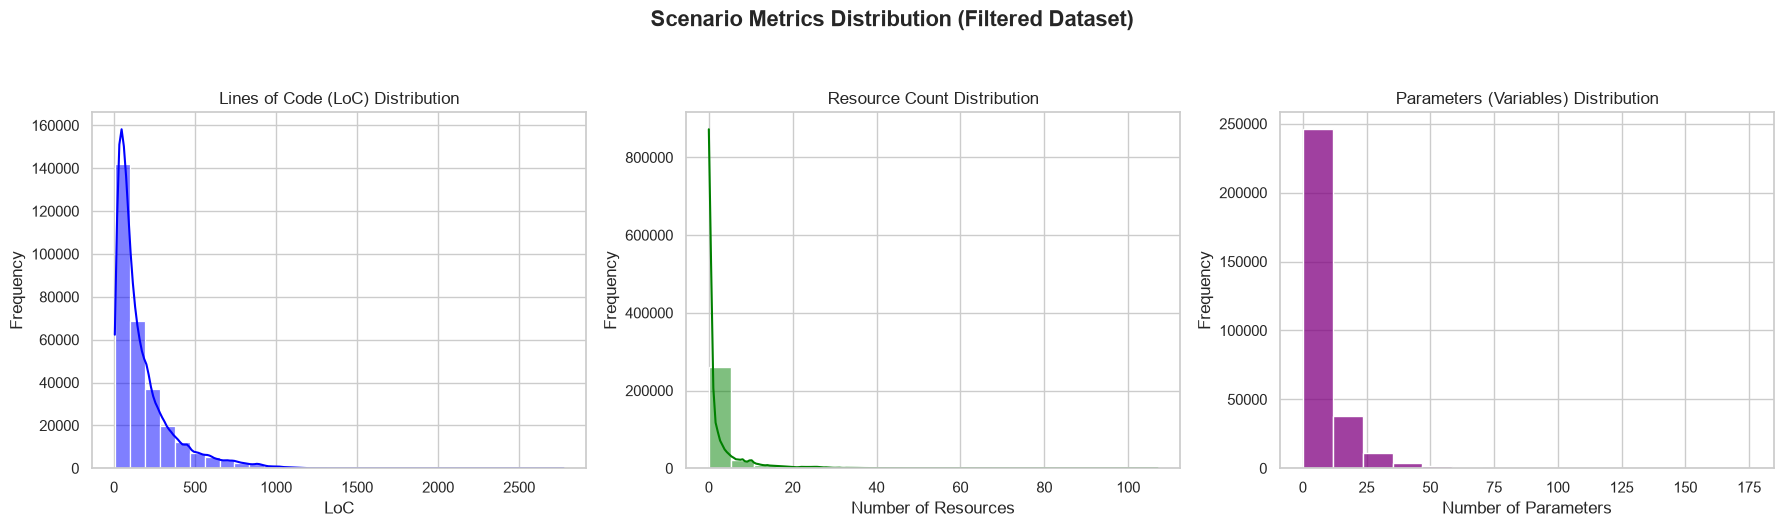

In [133]:
import hcl2
import io
import re
import os
import pathlib
import signal
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PARSE_CACHE_FILE = DATASET_DIR / 'ast_parse_cache.csv'

FORCE_REPARSE = False
VERBOSE_PARSE_LOGS = False
PROGRESS_EVERY = 25

if 'raw_scenarios' not in globals():
    print("📂 'raw_scenarios' not found in memory. Attempting to recover...")
    if PARSE_CACHE_FILE.exists():
        df_rec = pd.read_csv(PARSE_CACHE_FILE)
        if 'scenario_id' in df_rec.columns and 'folder_path' in df_rec.columns:
            if 'source' not in df_rec.columns:
                df_rec['source'] = 'recovered'
            raw_scenarios = df_rec[['scenario_id', 'source', 'folder_path']].drop_duplicates().to_dict('records')
            print(f"✅ Recovered {len(raw_scenarios)} scenarios from existing parse cache.")
        else:
            raw_scenarios = []
    else:
        raw_scenarios = []
        if 'MULTI_ROOT_DIR' in globals() and MULTI_ROOT_DIR.exists():
            for d in MULTI_ROOT_DIR.iterdir():
                if d.is_dir():
                    raw_scenarios.append({
                        'scenario_id': d.name,
                        'source': 'recovered_from_disk',
                        'folder_path': str(d)
                    })
            print(f"✅ Recovered {len(raw_scenarios)} scenarios by scanning local folders.")
        else:
            print("⚠️ Could not recover scenarios. Please run earlier cells.")

file_has_header = PARSE_CACHE_FILE.exists()

if FORCE_REPARSE:
    print("⚠️ FORCE_REPARSE is True. Ignoring existing cache and rescanning all scenarios...")
    processed_ids = set()
    file_has_header = False
    if PARSE_CACHE_FILE.exists():
        PARSE_CACHE_FILE.unlink()
elif file_has_header:
    df_cache_ids = pd.read_csv(PARSE_CACHE_FILE, usecols=['scenario_id'])
    processed_ids = set(df_cache_ids['scenario_id'])
    print(f'✅ Loaded {len(processed_ids)} previously parsed scenario IDs from cache.')
else:
    processed_ids = set()

scenarios_to_process = [rec for rec in raw_scenarios if rec['scenario_id'] not in processed_ids
                        and not str(rec['scenario_id']).endswith('_manualfix')]
print(f'Calculating LoC, tokens, and AST features for {len(scenarios_to_process)} new scenarios...')

class TimeoutException(Exception):
    pass

def timeout_handler(signum, frame):
    raise TimeoutException("Parser timed out!")

def parse_hcl2_safe(content, timeout_sec=2):
    if len(content.encode('utf-8')) > 150_000:
        return None

    old_handler = signal.signal(signal.SIGALRM, timeout_handler)
    signal.alarm(timeout_sec)

    try:
        return hcl2.load(io.StringIO(content))
    except TimeoutException:
        return None
    except Exception:
        return None
    finally:
        signal.alarm(0)
        signal.signal(signal.SIGALRM, old_handler)

new_count = 0
batch_data = []

RE_AWS_RESOURCE = re.compile(r'^\s*resource\s+"(aws_[a-zA-Z0-9_]+)"', re.MULTILINE)
RE_VARIABLE     = re.compile(r'^\s*variable\s+"', re.MULTILINE)

for rec in scenarios_to_process:
    scenario_id = rec['scenario_id']
    folder = pathlib.Path(rec['folder_path'])
    tf_files = list(folder.glob('*.tf'))

    if VERBOSE_PARSE_LOGS or (new_count % PROGRESS_EVERY == 0):
        print(f"[{new_count + 1}/{len(scenarios_to_process)}] Processing {scenario_id} ({len(tf_files)} files)")

    merged_content = "\n\n".join(f.read_text(encoding='utf-8', errors='ignore') for f in tf_files)
    loc = merged_content.count('\n') + 1

    if len(merged_content) > 1_000_000:
        tokens = 999_999
    else:
        try:
            tokens = len(TOKENIZER.encode(merged_content))
        except Exception:
            tokens = 0

    n_res = 0
    n_var = 0
    file_errors = 0

    for f in tf_files:
        content = f.read_text(encoding='utf-8', errors='ignore')
        ast = parse_hcl2_safe(content, timeout_sec=2)

        if ast is not None:
            for res_block in ast.get("resource", []):
                for res_type in res_block.keys():
                    if str(res_type).strip('"').startswith("aws_"):
                        n_res += 1
            
            n_var += len(ast.get("variable", []))
        else:
            file_errors += 1
            try:
                n_res += len(RE_AWS_RESOURCE.findall(content))
                n_var += len(RE_VARIABLE.findall(content))
            except Exception:
                file_errors += 1

    batch_data.append({
        'scenario_id': scenario_id,
        'source': rec['source'],
        'folder_path': rec['folder_path'],
        'loc': loc,
        'tokens': tokens,
        'n_resources': n_res,
        'n_params': n_var
    })

    new_count += 1
    processed_ids.add(scenario_id)

    if new_count % PROGRESS_EVERY == 0:
        print(f"  -> processed {new_count}/{len(scenarios_to_process)} scenarios; cache size={len(processed_ids)}")

    if new_count % 50 == 0:
        df_batch = pd.DataFrame(batch_data)
        df_batch.to_csv(PARSE_CACHE_FILE, mode='a', header=not file_has_header, index=False)
        file_has_header = True
        batch_data.clear()
        print(f'💾 Cache saved: {len(processed_ids)} scenarios processed')

if batch_data:
    df_batch = pd.DataFrame(batch_data)
    df_batch.to_csv(PARSE_CACHE_FILE, mode='a', header=not file_has_header, index=False)
    batch_data.clear()
    print(f'✅ Finished parsing and saved all {len(processed_ids)} scenarios to cache.')

if PARSE_CACHE_FILE.exists():
    df_all = pd.read_csv(PARSE_CACHE_FILE)
    df_filtered = df_all[(df_all['loc'] >= MIN_LOC) & (df_all['tokens'] <= MAX_TOKENS)].copy()

    print('\nFiltering Results:')
    print(f'  Original count : {len(df_all)}')
    print(f'  Filtered count : {len(df_filtered)} (dropped {len(df_all) - len(df_filtered)})')

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Scenario Metrics Distribution (Filtered Dataset)', fontsize=16, fontweight='bold', y=1.05)

    sns.histplot(df_filtered['loc'], bins=30, kde=True, ax=axes[0], color='blue')
    axes[0].set_title('Lines of Code (LoC) Distribution')
    axes[0].set_xlabel('LoC')
    axes[0].set_ylabel('Frequency')

    sns.histplot(df_filtered['n_resources'], bins=20, kde=True, ax=axes[1], color='green')
    axes[1].set_title('Resource Count Distribution')
    axes[1].set_xlabel('Number of Resources')
    axes[1].set_ylabel('Frequency')

    sns.histplot(df_filtered['n_params'], bins=15, kde=False, ax=axes[2], color='purple')
    axes[2].set_title('Parameters (Variables) Distribution')
    axes[2].set_xlabel('Number of Parameters')
    axes[2].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()

## §13 Size Filter (LoC & token budget)

Filtering Results:
  Parsed (cache)        : 313613
  AWS-targeted & parsed : 147463
  Size-filtered         : 142901 (dropped 4562)


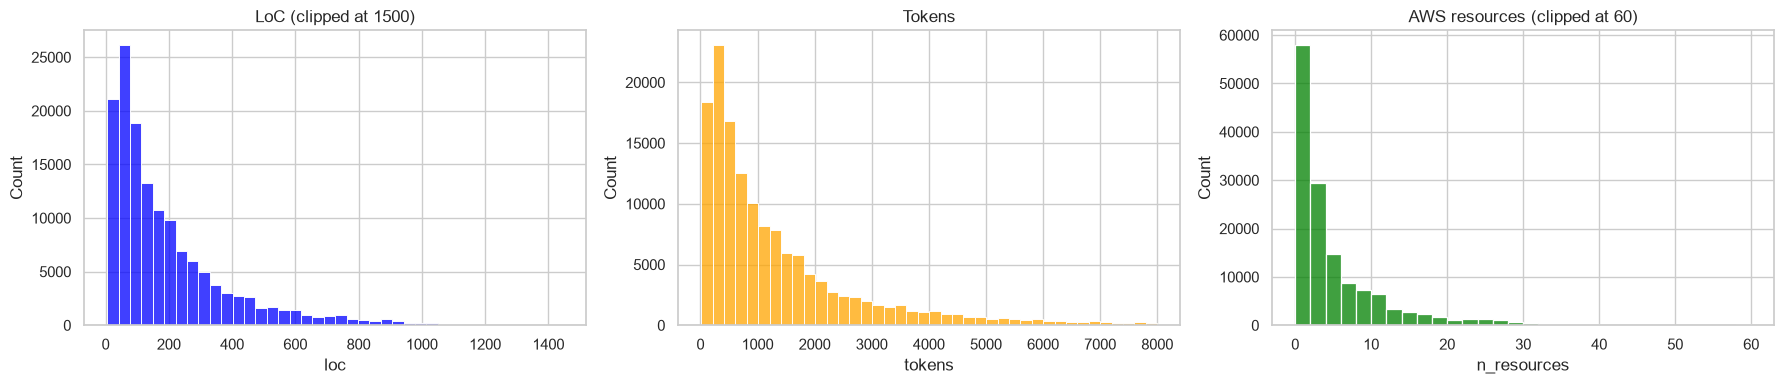

In [134]:
df_all = pd.read_csv(PARSE_CACHE_FILE)
n_parsed = len(df_all)
if 'AWS_SCENARIO_IDS' in globals():
    df_all = df_all[df_all['scenario_id'].isin(AWS_SCENARIO_IDS)].copy()
df_filtered = df_all[(df_all['loc'] >= MIN_LOC) & (df_all['tokens'] <= MAX_TOKENS)].copy()

print('Filtering Results:')
print(f'  Parsed (cache)        : {n_parsed}')
print(f'  AWS-targeted & parsed : {len(df_all)}')
print(f'  Size-filtered         : {len(df_filtered)} (dropped {len(df_all) - len(df_filtered)})')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df_filtered['loc'].clip(upper=1500), bins=40, ax=axes[0], color='blue')
axes[0].set_title('LoC (clipped at 1500)')
sns.histplot(df_filtered['tokens'], bins=40, ax=axes[1], color='orange')
axes[1].set_title('Tokens')
sns.histplot(df_filtered['n_resources'].clip(upper=60), bins=30, ax=axes[2], color='green')
axes[2].set_title('AWS resources (clipped at 60)')
plt.tight_layout()
plt.show()

## §14 Difficulty Assignment & Diverse Pre-Sampling

In [135]:
display(pd.DataFrame([
    {'level': 5, 'min_loc': 400, 'min_aws_resources': 12},
    {'level': 4, 'min_loc': 250, 'min_aws_resources': 8},
    {'level': 3, 'min_loc': 150, 'min_aws_resources': 4},
    {'level': 2, 'min_loc': 80,  'min_aws_resources': 2},
    {'level': 1, 'min_loc': 0,   'min_aws_resources': 0},
]).set_index('level'))

_ex = df_filtered[(df_filtered['loc'] >= DISCARD_MIN_LOC) & (df_filtered['n_resources'] >= DISCARD_MIN_RESOURCES)].copy()
_ex['difficulty_live'] = _ex.apply(calculate_difficulty, axis=1)
display(_ex.sample(frac=1, random_state=0).groupby('difficulty_live').head(2)
        .sort_values('difficulty_live')[['scenario_id', 'loc', 'n_resources', 'difficulty_live']])

_tfl = pd.read_csv(TFLINT_CACHE_FILE, usecols=['scenario_id', 'loc', 'n_resources', 'difficulty'], low_memory=False).dropna()
_tfl = _tfl[~_tfl['scenario_id'].astype(str).str.endswith('_manualfix')]
_chk = _tfl.sample(min(2000, len(_tfl)), random_state=0)
_mism = _chk[_chk.apply(calculate_difficulty, axis=1) != _chk['difficulty'].astype(int)]
print(f"Live function vs cached difficulty on {len(_chk)} tflint_cache rows: {len(_mism)} mismatch(es).")
if len(_mism):
    display(_mism.head())

,min_loc,min_aws_resources
level,,
5,400,12
4,250,8
3,150,4
2,80,2
1,0,0


,scenario_id,loc,n_resources,difficulty_live
112506,terrads_18dd17611f27,35,2,1
17563,terrads_fa8c28dea810,77,1,1
23526,terrads_1bb5d5b1e673,149,2,2
109497,terrads_e6a25e796502,99,3,2
99849,terrads_d7fd05893619,246,7,3
68616,terrads_77332640d60c,157,6,3
28687,terrads_713721488745,320,14,4
49984,terrads_ea03d921c98e,439,10,4
108038,terrads_788003a26647,450,22,5
155242,gh_0e204424,517,19,5


Live function vs cached difficulty on 2000 tflint_cache rows: 0 mismatch(es).


In [136]:
BATCH_COLS = ['scenario_id', 'source', 'folder_path', 'loc', 'tokens', 'n_resources', 'n_params',
              'difficulty', 'source_category', 'manual_fix_original_scenario_id', 'manual_fix_note']

if TFLINT_CACHE_FILE.exists():
    excluded_ids = set(pd.read_csv(TFLINT_CACHE_FILE, usecols=['scenario_id'], low_memory=False)['scenario_id'])
    print(f"Loaded {len(excluded_ids)} previously evaluated scenarios to exclude.")
else:
    excluded_ids = set()
    print("No evaluation history found. Starting fresh.")

df_fresh_candidates = df_filtered[~df_filtered['scenario_id'].isin(excluded_ids)].copy()

df_hard = df_fresh_candidates[
    (df_fresh_candidates['loc'] >= DISCARD_MIN_LOC) &
    (df_fresh_candidates['n_resources'] >= DISCARD_MIN_RESOURCES)
].copy()
print(f"Dropped trivial scenarios. Remaining fresh candidates: {len(df_hard)}")

if not df_hard.empty:
    df_hard['difficulty'] = df_hard.apply(calculate_difficulty, axis=1)

    if AWS_SERVICES_CACHE.exists():
        _svc = pd.read_csv(AWS_SERVICES_CACHE, keep_default_na=False)
        svc_map = dict(zip(_svc['scenario_id'], _svc['aws_services']))
    else:
        svc_map = {}
    _todo = df_hard.loc[~df_hard['scenario_id'].isin(svc_map), ['scenario_id', 'folder_path']]
    if len(_todo):
        print(f"Computing aws_services for {len(_todo)} candidate(s) (cached in {AWS_SERVICES_CACHE.name})...")
        _buf = []
        for sid, fp in tqdm(_todo.itertuples(index=False), total=len(_todo), desc='aws_services'):
            svc_map[sid] = get_aws_services(fp)
            _buf.append({'scenario_id': sid, 'aws_services': svc_map[sid]})
            if len(_buf) >= 2000:
                _append_rows_to_cache(AWS_SERVICES_CACHE, _buf, ['scenario_id', 'aws_services'])
                _buf.clear()
        _append_rows_to_cache(AWS_SERVICES_CACHE, _buf, ['scenario_id', 'aws_services'])
    df_hard['aws_services'] = df_hard['scenario_id'].map(svc_map).fillna('')

sampled_dfs = []
for level in range(1, 6):
    level_df = df_hard[df_hard['difficulty'] == level] if not df_hard.empty else df_hard
    n_available = len(level_df)
    if n_available == 0:
        continue
    n_to_sample = min(TARGET_SAMPLE_PER_LEVEL, n_available)
    picked = sample_diverse(level_df, n_to_sample, group_col='aws_services', seed=42)
    sampled_dfs.append(picked)
    print(f"Level {level}: Sampled {len(picked)} new scenarios out of {n_available} available "
          f"({picked['aws_services'].nunique()} distinct aws_services groups).")

_mf = df_manual_fixes[~df_manual_fixes['scenario_id'].isin(excluded_ids)] if 'df_manual_fixes' in globals() else pd.DataFrame()
if len(_mf):
    print(f"➕ Force-including {len(_mf)} manual fix(es) not yet TFLint-checked.")
    sampled_dfs.append(_mf)

if sampled_dfs:
    df_new_batch = pd.concat(sampled_dfs, ignore_index=True, sort=False)
    df_new_batch = df_new_batch.drop_duplicates('scenario_id', keep='last')
    df_new_batch = df_new_batch.sample(frac=1, random_state=42).reset_index(drop=True)
else:
    df_new_batch = pd.DataFrame(columns=BATCH_COLS)
df_new_batch = df_new_batch.reindex(columns=BATCH_COLS)
df_new_batch.to_csv(VALIDATION_QUEUE, index=False)
print(f"\n✅ Validation batch: {len(df_new_batch)} scenario(s) -> {VALIDATION_QUEUE}")
if len(df_new_batch):
    print(df_new_batch['difficulty'].value_counts().sort_index().rename('per level').to_string())

Loaded 97651 previously evaluated scenarios to exclude.
Dropped trivial scenarios. Remaining fresh candidates: 18221
Computing aws_services for 5 candidate(s) (cached in aws_services_cache.csv)...


aws_services:   0%|          | 0/5 [00:00<?, ?it/s]

Level 1: Sampled 100 new scenarios out of 18218 available (100 distinct aws_services groups).
Level 5: Sampled 3 new scenarios out of 3 available (3 distinct aws_services groups).
➕ Force-including 46 manual fix(es) not yet TFLint-checked.

✅ Validation batch: 149 scenario(s) -> iac_benchmark/dataset/validation_pipeline_batch.csv
difficulty
1    102
2     14
3     15
4     11
5      7


## §15 TFLint Validation

In [4]:
_dbg = pick_debug_row()
_passed, _log, _raw = run_tflint(_dbg['folder_path'], return_raw=True)
print(f"Scenario: {_dbg['scenario_id']}  ({_dbg['folder_path']})")
print(f"tflint --init stderr (tail): {(_raw['init_stderr'] or b'').decode(errors='ignore')[-300:]!r}")
print(f"tflint lint returncode: {_raw['lint_returncode']}\n")

_raw_out = _raw['lint_stdout'] or _raw['lint_stderr']
try:
    _data = json.loads(_raw_out)
    _issues = [{
        'rule': (i.get('rule') or {}).get('name'),
        'severity': (i.get('rule') or {}).get('severity'),
        'line': (i.get('range') or {}).get('start', {}).get('line'),
        'counts_as_error': str((i.get('rule') or {}).get('severity', 'error')).lower() == 'error',
        'message': (i.get('message') or '')[:120],
    } for i in _data.get('issues', [])]
    print(f"Parsed JSON: {len(_issues)} issue(s), {len(_data.get('errors', []))} tflint error(s)")
    if _issues:
        display(pd.DataFrame(_issues))
    if _data.get('errors'):
        print("tflint 'errors' (e.g. parse failures):")
        for e in _data['errors'][:5]:
            print(f"  - {str(e.get('message'))[:200]}")
except json.JSONDecodeError:
    print("NON-JSON output (stage falls back to returncode == 0):")
    print(_raw_out[:1500])

print(f"\nParsed result -> tflint_passed={_passed}")
print(f"tflint_log:\n{_log or '(empty)'}")

_cached = cached_row(TFLINT_CACHE_FILE, _dbg['scenario_id'], usecols=['scenario_id', 'tflint_passed', 'tflint_log'])
if _cached is None:
    print("\ncached: (not in tflint_cache.csv)")
else:
    print(f"\ncached tflint_passed={_cached['tflint_passed']}")
    if str(_cached['tflint_passed']).lower() != str(_passed).lower():
        print("⚠️ MISMATCH with the cache (tool/plugin version change or file edited?).")
    else:
        print("✅ live result matches the cache.")

Scenario: terrads_f455759ec10b  (iac_benchmark/scenarios/terrads_f455759ec10b)
tflint --init stderr (tail): ''
tflint lint returncode: 2

Parsed JSON: 3 issue(s), 0 tflint error(s)


,rule,severity,line,counts_as_error,message
0,terraform_unused_declarations,warning,1,False,"data ""aws_caller_identity"" ""current"" is declar..."
1,terraform_required_version,warning,1,False,"terraform ""required_version"" attribute is requ..."
2,terraform_required_providers,warning,34,False,"Missing version constraint for provider ""aws"" ..."



Parsed result -> tflint_passed=True
tflint_log:
(empty)

cached tflint_passed=True
✅ live result matches the cache.


In [5]:
INPUT_CSV = VALIDATION_QUEUE
PROGRESS_EVERY = 25

if not INPUT_CSV.exists():
    raise FileNotFoundError(f"Input batch not found at {INPUT_CSV}")

df_input = pd.read_csv(INPUT_CSV)

if TFLINT_CACHE_FILE.exists():
    df_cache = pd.read_csv(TFLINT_CACHE_FILE)
    processed_ids = set(df_cache['scenario_id'])
    results = df_cache.to_dict('records')
    print(f"✅ Loaded {len(processed_ids)} previously TFLint-scanned scenarios.")
else:
    processed_ids = set()
    results = []

scenarios_to_process = [row.to_dict() for _, row in df_input.iterrows() if row['scenario_id'] not in processed_ids]
print(f"Running TFLint on {len(scenarios_to_process)} unchecked scenarios...")

new_count = 0
for rec in scenarios_to_process:
    tflint_passed, tflint_log = run_tflint(rec['folder_path'])

    rec['tflint_passed'] = tflint_passed
    rec['tflint_log'] = tflint_log

    results.append(rec)
    processed_ids.add(rec['scenario_id'])
    new_count += 1

    if new_count % PROGRESS_EVERY == 0:
        print(f"  -> processed {new_count}/{len(scenarios_to_process)} scenarios")
    if new_count % 50 == 0:
        pd.DataFrame(results).to_csv(TFLINT_CACHE_FILE, index=False)

df_results = pd.DataFrame(results)
if not df_results.empty and (new_count > 0 or not TFLINT_PASSED_CSV.exists()):
    df_results.to_csv(TFLINT_CACHE_FILE, index=False)
    df_tflint_passed = df_results[df_results['tflint_passed'] == True].copy()
    df_tflint_passed.to_csv(TFLINT_PASSED_CSV, index=False)
    print(f"\n✅ TFLint complete. Cumulative Passed: {len(df_tflint_passed)} / {len(df_results)}")
else:
    print(f"\n✅ No new scenarios linted -- caches unchanged "
          f"(cumulative passed: {int((df_results['tflint_passed'] == True).sum()) if not df_results.empty else 0} / {len(df_results)}).")

_batch = df_results[df_results['scenario_id'].isin(df_input['scenario_id'])] if not df_results.empty else df_results
if len(_batch):
    print(f"This batch: {int((_batch['tflint_passed'] == True).sum())} / {len(_batch)} passed TFLint.")

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_85961/3548732556.py:18: DtypeWarning: Columns (0: source_category, 1: manual_fix_original_scenario_id, 2: manual_fix_note) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cache = pd.read_csv(TFLINT_CACHE_FILE)


✅ Loaded 97800 previously TFLint-scanned scenarios.
Running TFLint on 0 unchecked scenarios...

✅ No new scenarios linted -- caches unchanged (cumulative passed: 89507 / 97800).
This batch: 154 / 154 passed TFLint.


## §16 terraform validate (new gate)

In [6]:
_dbg = pick_debug_row()
_vrec, _vraw = run_terraform_validate(_dbg['folder_path'], return_raw=True)
print(f"Scenario: {_dbg['scenario_id']}  ({_dbg['folder_path']})")
print(f"$ {_vraw['init_cmd']}  -> returncode {_vraw['init_returncode']}")
print("init output (tail):")
print((_vraw['init_output'] or '')[-1200:])

if _vraw['validate_returncode'] is not None:
    print(f"\n$ terraform validate -json -no-color -> returncode {_vraw['validate_returncode']}")
    try:
        _vdoc = json.loads(_vraw['validate_stdout'])
        _vdoc_short = {**_vdoc, 'diagnostics': _vdoc.get('diagnostics', [])[:10]}
        print(json.dumps(_vdoc_short, indent=2)[:4000])
    except json.JSONDecodeError:
        print("NON-JSON validate output (stage treats this as FAIL):")
        print((_vraw['validate_stdout'] or _vraw['validate_stderr'])[:1500])

print("\nParsed record:")
for k, v in _vrec.items():
    print(f"  {k:<22} {v if k != 'validate_log' else (v or '(empty)')}")

_cached = cached_row(TF_VALIDATE_CACHE, _dbg['scenario_id'])
if _cached is None:
    print("\ncached: (not in tf_validate_cache.csv yet)")
else:
    same = str(_cached['validate_passed']).lower() == str(_vrec['validate_passed']).lower()
    print(f"\ncached validate_passed={_cached['validate_passed']} -> {'✅ matches' if same else '⚠️ MISMATCH'}")

Scenario: terrads_f455759ec10b  (iac_benchmark/scenarios/terrads_f455759ec10b)
$ terraform init -backend=false -input=false -no-color  -> returncode 0
init output (tail):
Initializing provider plugins...
- Finding latest version of hashicorp/aws...
- Using hashicorp/aws v6.65.0 from the shared cache directory
Terraform has created a lock file .terraform.lock.hcl to record the provider
selections it made above. Include this file in your version control repository
so that Terraform can guarantee to make the same selections by default when
you run "terraform init" in the future.



Due to your customized provider installation methods, Terraform was forced to
calculate lock file checksums locally for the following providers:
  - hashicorp/aws

The current .terraform.lock.hcl file only includes checksums for
darwin_arm64, so Terraform running on another platform will fail to install
these providers.

To calculate additional checksums for another platform, run:
  terraform providers lock -pl

In [7]:
VALIDATE_EXTRA_SCENARIO_IDS = []

df_tfl_passed = pd.read_csv(TFLINT_PASSED_CSV, low_memory=False).drop_duplicates('scenario_id', keep='last')
_tfl_passed_ids = set(df_tfl_passed['scenario_id'])

_scope = {
    'validation batch': set(pd.read_csv(VALIDATION_QUEUE, usecols=['scenario_id'])['scenario_id']) if VALIDATION_QUEUE.exists() else set(),
    'frozen real-AWS benchmark': set(pd.read_csv(REAL_AWS_PROMPTS_CSV, usecols=['scenario_id'])['scenario_id']) if REAL_AWS_PROMPTS_CSV.exists() else set(),
    'manual fixes': set(df_manual_fixes['scenario_id']) if 'df_manual_fixes' in globals() else set(),
    'reference composition': (set(pd.read_csv(RESTORE_REFERENCE_CSV, usecols=['scenario_id'])['scenario_id'])
                              if RESTORE_REFERENCE_COMPOSITION and RESTORE_REFERENCE_CSV.exists() else set()),
    'extra': set(VALIDATE_EXTRA_SCENARIO_IDS),
}
for name, ids in _scope.items():
    missing = ids - _tfl_passed_ids
    print(f"  {name:<27} {len(ids):>5} id(s), {len(ids & _tfl_passed_ids):>5} TFLint-passed"
          + (f", {len(missing)} not TFLint-passed (skipped)" if missing else ''))
target_ids = set().union(*_scope.values()) & _tfl_passed_ids
targets = df_tfl_passed[df_tfl_passed['scenario_id'].isin(target_ids)]

validate_scenarios(targets.to_dict('records'), max_new=VALIDATE_MAX_NEW)

_statuses = get_validate_status_map()
_t_status = targets['scenario_id'].map(_statuses).fillna('untested')
print(f"\nTarget set status: {_t_status.value_counts().to_dict()}")
for name, ids in _scope.items():
    s = pd.Series([_statuses.get(i, 'untested') for i in ids & _tfl_passed_ids], dtype=object)
    if len(s):
        print(f"  {name:<27} {s.value_counts().to_dict()}")

_vcache = load_validate_cache()
_fails = _vcache[~_as_bool_series(_vcache['validate_passed']) & _vcache['scenario_id'].isin(target_ids)]
if len(_fails):
    _sig = _fails['validate_log'].fillna('').astype(str).map(
        lambda t: ('INIT FAILED: ' if t.startswith('INIT FAILED') else '') +
                  (re.search(r'Error: ([^\n|]{0,70})', t).group(1).strip() if re.search(r'Error: ([^\n|]{0,70})', t)
                   else (t.split('|')[2].strip()[:70] if t.count('|') >= 2 else t[:70])))
    print("\nTop failure signatures in the target set:")
    print(_sig.value_counts().head(15).to_string())

_passed_ids = set(_vcache.loc[_as_bool_series(_vcache['validate_passed']), 'scenario_id'])
df_validate_passed = df_tfl_passed[df_tfl_passed['scenario_id'].isin(_passed_ids)].copy()
df_validate_passed.to_csv(TF_VALIDATE_PASSED_CSV, index=False)
print(f"\n✅ {TF_VALIDATE_PASSED_CSV.name}: {len(df_validate_passed):,} cumulative validate-passed scenario(s) "
      f"(of {len(_vcache):,} ever validated).")

  validation batch              154 id(s),   154 TFLint-passed
  frozen real-AWS benchmark     250 id(s),   250 TFLint-passed
  manual fixes                    0 id(s),     0 TFLint-passed
  reference composition         250 id(s),   248 TFLint-passed, 2 not TFLint-passed (skipped)
  extra                           0 id(s),     0 TFLint-passed
terraform validate: 522 cached, 0 to run (6 workers).

Target set status: {'pass': 488, 'fail': 34}
  validation batch            {np.str_('pass'): 120, np.str_('fail'): 34}
  frozen real-AWS benchmark   {np.str_('pass'): 250}
  reference composition       {np.str_('pass'): 248}

Top failure signatures in the target set:
validate_log
INIT FAILED: Unsupported Terraform Core version                                        6
INIT FAILED: Unreadable module directory                                               6
Invalid resource type                                                                  4
INIT FAILED: Terraform encountered problems during 

## §17 Trivy Security Scan & Severity Gate

In [8]:
_dbg = pick_debug_row()
_ok, _counts, _traw = run_trivy(_dbg['folder_path'], return_raw=True)
print(f"Scenario: {_dbg['scenario_id']}  ({_dbg['folder_path']})")
print(f"trivy returncode={_traw['returncode']}  stdout={len(_traw['stdout'])} chars  stderr={len(_traw['stderr'])} chars")

try:
    _tdoc = json.loads(_traw['stdout'])
    _rows = []
    for r in _tdoc.get('Results', []) or []:
        for m in r.get('Misconfigurations', []) or []:
            cm = m.get('CauseMetadata') or {}
            _rows.append({
                'file': r.get('Target'),
                'id': m.get('AVDID') or m.get('ID'),
                'severity': m.get('Severity'),
                'title': (m.get('Title') or '')[:70],
                'resource': cm.get('Resource'),
                'lines': f"{cm.get('StartLine')}-{cm.get('EndLine')}",
            })
    print(f"JSON parsed ✅ -- {len(_rows)} misconfiguration(s)")
    if _rows:
        _order = {'CRITICAL': 0, 'HIGH': 1, 'MEDIUM': 2, 'LOW': 3}
        display(pd.DataFrame(_rows).sort_values('severity', key=lambda s: s.map(_order).fillna(9)).reset_index(drop=True))
except json.JSONDecodeError:
    print("⚠️ NON-JSON output -- the stage would record scan_success=(returncode==0) with ALL counts 0.")
    print((_traw['stdout'] or _traw['stderr'])[:1500])

print(f"\nParsed -> trivy_scan_success={_ok} counts={_counts}")
_gate = [s for s in ['critical', 'high'] if _counts[s] > 0]
print(f"Severity gate (critical/high): {'❌ BLOCKED by ' + ', '.join(_gate) if _gate else '✅ passes'}")

_cached = cached_row(TRIVY_CACHE_FILE, _dbg['scenario_id'],
                     usecols=['scenario_id', 'trivy_scan_success', 'trivy_critical', 'trivy_high', 'trivy_medium', 'trivy_low'])
if _cached is None:
    print("\ncached: (not in trivy_cache.csv)")
else:
    _cc = {k: int(_cached[f'trivy_{k}']) for k in ['critical', 'high', 'medium', 'low']}
    _lc = {k: _counts[k] for k in _cc}
    print(f"\ncached counts={_cc}")
    print("✅ live counts match the cache." if _cc == _lc else "⚠️ MISMATCH with cache (Trivy checks bundle drift or file edited?).")

Scenario: terrads_f455759ec10b  (iac_benchmark/scenarios/terrads_f455759ec10b)
trivy returncode=0  stdout=3889 chars  stderr=536 chars
JSON parsed ✅ -- 1 misconfiguration(s)


,file,id,severity,title,resource,lines
0,kms.tf,AWS-0065,MEDIUM,A KMS key is not configured to auto-rotate.,aws_kms_key.foo_kms,9-9



Parsed -> trivy_scan_success=True counts={'critical': 0, 'high': 0, 'medium': 1, 'low': 0, 'unknown': 0}
Severity gate (critical/high): ✅ passes

cached counts={'critical': 0, 'high': 0, 'medium': 1, 'low': 0}
✅ live counts match the cache.


In [9]:
INPUT_CSV = TF_VALIDATE_PASSED_CSV
PROGRESS_EVERY = 25

if not INPUT_CSV.exists():
    raise FileNotFoundError(f"Input batch not found at {INPUT_CSV}")

df_input = pd.read_csv(INPUT_CSV)

if TRIVY_CACHE_FILE.exists():
    df_cache = pd.read_csv(TRIVY_CACHE_FILE)
    processed_ids = set(df_cache['scenario_id'])
    results = df_cache.to_dict('records')
    print(f"✅ Loaded {len(processed_ids)} previously Trivy-scanned scenarios.")
else:
    processed_ids = set()
    results = []

scenarios_to_process = [row.to_dict() for _, row in df_input.iterrows() if row['scenario_id'] not in processed_ids]
print(f"Running Trivy on {len(scenarios_to_process)} unchecked scenarios...")

new_count = 0
for rec in scenarios_to_process:
    trivy_scan_success, counts = run_trivy(rec['folder_path'])

    rec['trivy_scan_success'] = trivy_scan_success
    for sev_level, count in counts.items():
        rec[f'trivy_{sev_level}'] = count

    results.append(rec)
    processed_ids.add(rec['scenario_id'])
    new_count += 1

    if new_count % PROGRESS_EVERY == 0:
        print(f"  -> processed {new_count}/{len(scenarios_to_process)} scenarios")
    if new_count % 50 == 0:
        pd.DataFrame(results).to_csv(TRIVY_CACHE_FILE, index=False)

df_results = pd.DataFrame(results)
if not df_results.empty and (new_count > 0 or not TRIVY_SCANNED_CSV.exists()):
    df_results.to_csv(TRIVY_CACHE_FILE, index=False)
    df_trivy_scanned = df_results[df_results['trivy_scan_success'] == True].copy()
    df_trivy_scanned.to_csv(TRIVY_SCANNED_CSV, index=False)
    print(f"\n✅ Trivy complete. Successfully Scanned: {len(df_trivy_scanned)} / {len(df_results)}")
else:
    print(f"\n✅ No new scenarios scanned -- caches unchanged ({len(df_results)} cached rows).")

/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_85961/2991199181.py:17: DtypeWarning: Columns (0: tflint_log, 1: source_category, 2: manual_fix_original_scenario_id, 3: manual_fix_note) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cache = pd.read_csv(TRIVY_CACHE_FILE)


✅ Loaded 89270 previously Trivy-scanned scenarios.
Running Trivy on 0 unchecked scenarios...

✅ No new scenarios scanned -- caches unchanged (89270 cached rows).


In [10]:
import pandas as pd

TRIVY_SCANNED_CSV = DATASET_DIR / 'trivy_scanned_batch.csv'
TRIVY_FILTERED_CSV = DATASET_DIR / 'trivy_filtered_batch.csv'

if not TRIVY_SCANNED_CSV.exists():
    raise FileNotFoundError(f"Trivy scanned batch not found at {TRIVY_SCANNED_CSV}")

df_trivy = pd.read_csv(TRIVY_SCANNED_CSV)

DISALLOWED_SEVERITIES = ["critical", "high"]
print(f"Filtering out scenarios containing ANY of these severities: {DISALLOWED_SEVERITIES}")

mask = pd.Series([True] * len(df_trivy), index=df_trivy.index)
for sev in DISALLOWED_SEVERITIES:
    col_name = f'trivy_{sev}'
    if col_name in df_trivy.columns:
        mask = mask & (df_trivy[col_name] == 0)

df_trivy_filtered = df_trivy[mask].copy()
df_trivy_filtered.to_csv(TRIVY_FILTERED_CSV, index=False)

print(f"✅ Filter complete. Kept {len(df_trivy_filtered)} / {len(df_trivy)} secure scenarios.")

Filtering out scenarios containing ANY of these severities: ['critical', 'high']
✅ Filter complete. Kept 36963 / 89140 secure scenarios.


/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_85961/3243736491.py:11: DtypeWarning: Columns (0: tflint_log, 1: source_category, 2: manual_fix_original_scenario_id, 3: manual_fix_note) have mixed types. Specify dtype option on import or set low_memory=False.
  df_trivy = pd.read_csv(TRIVY_SCANNED_CSV)


## §18 LocalStack Deployability (optional — no filter)

In [11]:
if RUN_LOCALSTACK or RUN_LOCALSTACK_DEBUG:
    try:
        _h = requests.get("http://localhost:4566/_localstack/health", timeout=5)
        print(f"LocalStack health: HTTP {_h.status_code}")
    except requests.exceptions.RequestException as e:
        print(f"❌ LocalStack not reachable on :4566 -- {e}")
    _id = subprocess.run(['aws', 'sts', 'get-caller-identity', '--endpoint-url', 'http://localhost:4566'],
                         capture_output=True, text=True, env=LOCALSTACK_RUN_ENV)
    print(_id.stdout or _id.stderr)
else:
    print("⏸️  RUN_LOCALSTACK / RUN_LOCALSTACK_DEBUG are False -- skipping LocalStack checks.")

⏸️  RUN_LOCALSTACK / RUN_LOCALSTACK_DEBUG are False -- skipping LocalStack checks.


In [145]:
_dbg = pick_debug_row()
_cached = cached_row(DEPLOY_CACHE_FILE, _dbg['scenario_id'], usecols=['scenario_id', 'deploy_passed', 'deploy_log'])
print(f"Scenario: {_dbg['scenario_id']}")
if _cached is None:
    print("cached: (never deployed to LocalStack)")
else:
    print(f"cached deploy_passed={_cached['deploy_passed']}")
    print(format_log(str(_cached['deploy_log'])))

if RUN_LOCALSTACK_DEBUG:
    _p, _log = deploy_localstack(_dbg['folder_path'])
    print(f"\nLIVE deploy_passed={_p}")
    print(format_log(_log))
else:
    print("\n(set RUN_LOCALSTACK_DEBUG = True in §0 to deploy this sample to LocalStack live)")

Scenario: terrads_f455759ec10b
cached deploy_passed=True
--- INIT LOG ---
Initializing provider plugins...
- Finding latest version of hashicorp/aws...
- Installing hashicorp/aws v6.55.0...
- Installed hashicorp/aws v6.55.0 (signed by HashiCorp)
Terraform has created a lock file .terraform.lock.hcl to record the provider
selections it made above. Include this file in your version control repository
so that Terraform can guarantee to make the same selections by default when
you run "terraform init" in the future.

Terraform has been successfully initialized!

You may now begin working with Terraform. Try running "terraform plan" to see
any changes th

...[LOG TRUNCATED]...

             + Version   = "2012-10-17"
            }
        )
      + region                             = "us-east-1"
      + rotation_period_in_days            = (known after apply)
      + tags_all                           = (known after apply)
    }

Plan: 2 to add, 0 to change, 0 to destroy.
aws_kms_key.foo_k

In [146]:
LOCALSTACK_SCOPE = 'batch'
PROGRESS_EVERY = 25
SAVE_EVERY = 10
STORE_FULL_DEPLOY_LOGS = True

if not RUN_LOCALSTACK:
    print("⏸️  RUN_LOCALSTACK is False -- skipping LocalStack deployability (optional stage, no filter).")
else:
    df_input = pd.read_csv(TRIVY_FILTERED_CSV, low_memory=False)
    df_input = df_input[df_input['scenario_id'].map(get_validate_status_map()) == 'pass']
    if LOCALSTACK_SCOPE == 'batch':
        df_input = df_input[df_input['scenario_id'].isin(pd.read_csv(VALIDATION_QUEUE, usecols=['scenario_id'])['scenario_id'])]
    print(f"LocalStack input ({LOCALSTACK_SCOPE}): {len(df_input)} Trivy-clean + validate-passed scenario(s).")

    file_has_header = DEPLOY_CACHE_FILE.exists()

    if file_has_header:
        df_cache_ids = pd.read_csv(DEPLOY_CACHE_FILE, usecols=['scenario_id'])
        processed_ids = set(df_cache_ids['scenario_id'])
        print(f"✅ Loaded {len(processed_ids)} previously deployed scenario IDs.")
    else:
        processed_ids = set()

    scenarios_to_process = [row.to_dict() for _, row in df_input.iterrows() if row['scenario_id'] not in processed_ids]
    print(f"Deploying {len(scenarios_to_process)} unchecked scenarios to LocalStack...\n")

    if len(scenarios_to_process) > 0:
        print("Pre-warming AWS provider cache...")
        with tempfile.TemporaryDirectory() as warmup_dir:
            (Path(warmup_dir) / "main.tf").write_text('provider "aws" { region = "us-east-1" }')
            subprocess.run(["tflocal", "init", "-backend=false", "-input=false", "-no-color"], cwd=warmup_dir, capture_output=True, env=run_env)
        print("✅ Cache warmed up! Starting deployments...\n")

    new_count = 0
    batch_data = []

    for rec in scenarios_to_process:
        scenario_id = rec['scenario_id']

        if new_count % PROGRESS_EVERY == 0:
            print(f"[{new_count + 1}/{len(scenarios_to_process)}] {scenario_id}")

        deploy_passed, combined_log = deploy_localstack(rec['folder_path'])

        print(f"  -> passed={deploy_passed}")

        rec['deploy_passed'] = deploy_passed
        rec['deploy_log'] = format_log(combined_log) if (STORE_FULL_DEPLOY_LOGS or not deploy_passed) else ""

        batch_data.append(rec)
        processed_ids.add(scenario_id)
        new_count += 1

        reset_localstack()

        if new_count % SAVE_EVERY == 0:
            df_batch = pd.DataFrame(batch_data)

            if file_has_header and DEPLOY_CACHE_FILE.exists():
                existing_cols = pd.read_csv(DEPLOY_CACHE_FILE, nrows=0).columns
                df_batch = df_batch.reindex(columns=existing_cols)

            df_batch.to_csv(DEPLOY_CACHE_FILE, mode='a', header=not file_has_header, index=False)
            file_has_header = True
            batch_data.clear()

    if batch_data:
        df_batch = pd.DataFrame(batch_data)
        if file_has_header and DEPLOY_CACHE_FILE.exists():
            existing_cols = pd.read_csv(DEPLOY_CACHE_FILE, nrows=0).columns
            df_batch = df_batch.reindex(columns=existing_cols)
        df_batch.to_csv(DEPLOY_CACHE_FILE, mode='a', header=not file_has_header, index=False)
        batch_data.clear()

    if new_count and DEPLOY_CACHE_FILE.exists():
        df_results = pd.read_csv(DEPLOY_CACHE_FILE)
        df_deploy_passed = df_results[df_results['deploy_passed'] == True].copy()
        df_deploy_passed.to_csv(DEPLOY_PASSED_CSV, index=False)
        print(f"\n✅ LocalStack deploy complete. Cumulative Deployable: {len(df_deploy_passed)} / {len(df_results)}")
    else:
        print("\n✅ No new scenarios were deployed.")

⏸️  RUN_LOCALSTACK is False -- skipping LocalStack deployability (optional stage, no filter).


## §19 Real-AWS Deployability

### §19a Real-AWS candidate pool

In [12]:
import pandas as pd
import difflib
from pathlib import Path
from collections import defaultdict

TRIVY_FILTERED_PATH = DATASET_DIR / 'trivy_filtered_batch.csv'
LICENCE_CACHE_PATH = DATASET_DIR / 'licence_cache.csv'
REAL_AWS_POOL_CSV = DATASET_DIR / 'tf_real_aws_candidate_pool.csv'

if not TRIVY_FILTERED_PATH.exists():
    raise FileNotFoundError(
        f"{TRIVY_FILTERED_PATH} not found -- run IaCGOD_Benchmark_Terraform.ipynb's "
        f"Cells 11 (TFLint) -> 12 (Trivy) -> 12.5 (severity filter) at least once first."
    )

df_pool = pd.read_csv(TRIVY_FILTERED_PATH, low_memory=False)
print(f"TFLint-passed + Trivy-clean (0 critical/high) candidates: {len(df_pool):,}")

EXEMPT_LICENCE_SOURCES = {'Zenodo/TerraDS', 'autoiac-project/iac-eval', 'AmazonScience/Multi-IaC-Eval'}
ALLOWED_SPDX_LICENCE = {'MIT', 'MIT-0', 'Apache-2.0', 'BSD-2-Clause', 'BSD-3-Clause',
                         'ISC', 'MPL-2.0', 'CC0-1.0', 'Unlicense', 'WTFPL'}
COPYLEFT_SPDX_LICENCE = {'GPL-2.0', 'GPL-3.0', 'LGPL-2.1', 'LGPL-3.0', 'AGPL-3.0'}
ELIGIBLE_SPDX = ALLOWED_SPDX_LICENCE | COPYLEFT_SPDX_LICENCE

if LICENCE_CACHE_PATH.exists():
    licence_map = pd.read_csv(LICENCE_CACHE_PATH, index_col='slug')['spdx'].to_dict()
else:
    licence_map = {}
    print("⚠️ licence_cache.csv not found -- treating every non-exempt source as ineligible.")

def is_licence_eligible(source):
    if source in EXEMPT_LICENCE_SOURCES:
        return True
    return licence_map.get(source) in ELIGIBLE_SPDX

df_pool = df_pool[df_pool['source'].apply(is_licence_eligible)].copy()
print(f"Licence-eligible: {len(df_pool):,}")

MANUAL_EXCLUDE_SET = {p for paths in MANUAL_EXCLUDE_FOLDER_PATHS.values() for p in paths}

df_pool = df_pool[~df_pool['folder_path'].isin(MANUAL_EXCLUDE_SET)]
df_pool = df_pool.drop_duplicates('scenario_id').reset_index(drop=True)
print(f"After quality exclusions: {len(df_pool):,}")

refresh_pool_validate_status(df_pool)
_n_vfail = int((df_pool['validate_status'] == 'fail').sum())
df_pool = df_pool[df_pool['validate_status'] != 'fail'].reset_index(drop=True)
print(f"terraform validate: dropped {_n_vfail:,} validate-failed; remaining by status: "
      f"{df_pool['validate_status'].value_counts().to_dict()}")

def get_aws_services(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return ""
    services = set()
    for tf_file in folder.glob('*.tf'):
        content = tf_file.read_text(encoding='utf-8', errors='ignore')
        services.update(re.findall(r'(?:resource|data)\s+"(aws_[a-zA-Z0-9_]+)"', content))
    return ", ".join(sorted(services))

df_pool['aws_services'] = df_pool['folder_path'].apply(get_aws_services)

print('\nPer-difficulty-level pool size:')
print(df_pool['difficulty'].value_counts().sort_index().to_string())

df_pool.to_csv(REAL_AWS_POOL_CSV, index=False)
print(f"\n💾 Saved pool -> {REAL_AWS_POOL_CSV} ({len(df_pool):,} rows)")

def sample_diverse(df_candidates, target, group_col='aws_services', seed=42, existing_group_counts=None):
    df_shuffled = df_candidates.sample(frac=1, random_state=seed).reset_index(drop=True)
    grouped = [(k, g.to_dict('records')) for k, g in df_shuffled.groupby(group_col)]
    import random
    random.seed(seed)
    random.shuffle(grouped)
    if existing_group_counts:
        grouped.sort(key=lambda kg: existing_group_counts.get(kg[0], 0))
    group_rows = [g for _, g in grouped]
    sampled = []
    while len(sampled) < target and group_rows:
        next_group_rows = []
        for g_list in group_rows:
            if len(sampled) >= target: break
            if g_list: sampled.append(g_list.pop(0))
            if g_list: next_group_rows.append(g_list)
        group_rows = next_group_rows
    return pd.DataFrame(sampled)

def _block_key(row):
    return (row['n_resources'], frozenset(str(row.get('aws_services', '')).split(', ')))

TFLint-passed + Trivy-clean (0 critical/high) candidates: 36,963
Licence-eligible: 36,963
After quality exclusions: 36,943
terraform validate: dropped 290 validate-failed; remaining by status: {'untested': 35682, 'pass': 971}

Per-difficulty-level pool size:
difficulty
1.0    15316
2.0    11418
3.0     6538
4.0     2162
5.0     1219

💾 Saved pool -> iac_benchmark/dataset/tf_real_aws_candidate_pool.csv (36,653 rows)


### §19b Real-AWS testing queue (prioritised, budget-capped, lazily validated)

In [13]:
import pandas as pd

GT_DEPLOY_CACHE_PATH = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'
CURRENT_BENCHMARK_CSV = REAL_AWS_PROMPTS_CSV

TARGET_PER_LEVEL = 50
TEST_BUDGET_PER_LEVEL = 50

_TRANSIENT_ERROR_PATTERNS = [
    'Could not connect to the endpoint',
    'connection reset by peer',
    'RequestTimeout',
]

_LOCALSTACK_PASSED_BASE_IDS = (set(pd.read_csv(DEPLOY_PASSED_CSV, usecols=['scenario_id'])['scenario_id'].map(_base_id))
                               if DEPLOY_PASSED_CSV.exists() else set())
print(f"🧪 {len(_LOCALSTACK_PASSED_BASE_IDS):,} LocalStack-passed scenario(s) get 2nd-tier queue priority.")

if CURRENT_BENCHMARK_CSV.exists():
    _current_benchmark_paths = set(pd.read_csv(CURRENT_BENCHMARK_CSV, usecols=['folder_path'])['folder_path'])
    print(f"📌 {len(_current_benchmark_paths)} scenario(s) from the current frozen LocalStack "
          f"benchmark will be prioritized for real-AWS testing first.")
else:
    _current_benchmark_paths = set()
    print(f"⚠️ {CURRENT_BENCHMARK_CSV.name} not found -- nothing to prioritize; queue will draw "
          f"straight from the pool.")

if not GT_DEPLOY_CACHE_PATH.exists():
    print(f"⚠️ {GT_DEPLOY_CACHE_PATH.name} not found yet -- every candidate below is untested.")
    gt_cache = pd.DataFrame(columns=['scenario_id', 'deploy_pass', 'init_error', 'apply_error'])
else:
    gt_cache = pd.read_csv(GT_DEPLOY_CACHE_PATH)
    for _c in ('init_error', 'apply_error'):
        if _c not in gt_cache.columns:
            gt_cache[_c] = ''

merged = df_pool.merge(
    gt_cache[['scenario_id', 'deploy_pass', 'init_error', 'apply_error']].drop_duplicates('scenario_id'),
    on='scenario_id', how='left'
)
merged['_in_current_benchmark'] = merged['folder_path'].isin(_current_benchmark_paths)

is_transient = pd.Series(False, index=merged.index)
for _pat in _TRANSIENT_ERROR_PATTERNS:
    is_transient |= (
        merged['init_error'].astype(str).str.contains(_pat, na=False)
        | merged['apply_error'].astype(str).str.contains(_pat, na=False)
    )

merged['_tested'] = merged['deploy_pass'].notna()
merged['_needs_test'] = (~merged['_tested']) | (is_transient & (merged['deploy_pass'] != True))

queue_by_level = {}
print(f"\n{'Lvl':>3}  {'pool':>6}  {'tested':>6}  {'pass':>5}  {'shortfall':>9}  {'queued':>6}  {'from-current':>12}")
for level in range(1, 6):
    lvl = merged[merged['difficulty'] == level]
    pool_n = len(lvl)
    tested_n = int(lvl['_tested'].sum())
    pass_n = len(assemblable_passing(lvl))
    shortfall = max(0, TARGET_PER_LEVEL - pass_n)

    if shortfall == 0:
        queue_by_level[level] = []
        print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {shortfall:>9}  {0:>6}  {0:>12}"
              f"   (already has {TARGET_PER_LEVEL} real-AWS-passing candidates)")
        continue

    budget = max(TEST_BUDGET_PER_LEVEL, max(shortfall, shortfall * 5))
    candidates = lvl[lvl['_needs_test']].copy()
    candidates = drop_near_duplicates_of(candidates, lvl[lvl['deploy_pass'] == True], label=f'L{level}: ')

    if candidates.empty:
        queue_by_level[level] = []
        print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {shortfall:>9}  {0:>6}  {0:>12}"
              f"   (no untested candidates left in the pool -- need more raw candidates for this level)")
        continue

    current_first = candidates[candidates['_in_current_benchmark']]
    rest = candidates[~candidates['_in_current_benchmark']]
    passing_service_counts = lvl.loc[lvl['deploy_pass'] == True, 'aws_services'].value_counts().to_dict()
    rest_ls = rest[rest['scenario_id'].map(_base_id).isin(_LOCALSTACK_PASSED_BASE_IDS)]
    rest_other = rest[~rest.index.isin(rest_ls.index)]
    ordered_rest = pd.concat([
        sample_diverse(rest_ls, len(rest_ls), group_col='aws_services', existing_group_counts=passing_service_counts) if len(rest_ls) else rest_ls,
        sample_diverse(rest_other, len(rest_other), group_col='aws_services', existing_group_counts=passing_service_counts) if len(rest_other) else rest_other,
    ], ignore_index=True)
    ordered = pd.concat([current_first, ordered_rest], ignore_index=True)

    queued_df = lazy_validate_until(ordered, budget) if LAZY_VALIDATE_QUEUE else ordered.head(budget)
    queued = queued_df['folder_path'].tolist()
    n_from_current = int(queued_df['_in_current_benchmark'].sum())
    queue_by_level[level] = queued
    print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {shortfall:>9}  {len(queued):>6}  {n_from_current:>12}")

REAL_AWS_TEST_QUEUE = [f for files in queue_by_level.values() for f in files]
print(f"\n{len(REAL_AWS_TEST_QUEUE)} candidate(s) queued across all under-target levels "
      f"(see REAL_AWS_TEST_QUEUE / queue_by_level).")
if REAL_AWS_TEST_QUEUE:
    print("Feed these folder_paths into the deploy-check section's TARGET_FOLDER_PATHS (default: "
          "this queue) to actually test them on real AWS.")

refresh_pool_validate_status(df_pool)

🧪 431 LocalStack-passed scenario(s) get 2nd-tier queue priority.
📌 250 scenario(s) from the current frozen LocalStack benchmark will be prioritized for real-AWS testing first.

Lvl    pool  tested   pass  shortfall  queued  from-current
   AWS resource gate: dropped 4 that create fewer than 1 aws_* resource(s); kept 0 with an unknown count (plan failed)
  1   15316     227     50          0       0             0   (already has 50 real-AWS-passing candidates)
   AWS resource gate: dropped 25 that create fewer than 1 aws_* resource(s); kept 0 with an unknown count (plan failed)
  2   11418     188     52          0       0             0   (already has 50 real-AWS-passing candidates)
   AWS resource gate: dropped 18 that create fewer than 1 aws_* resource(s); kept 0 with an unknown count (plan failed)
  3    6538     170     53          0       0             0   (already has 50 real-AWS-passing candidates)
   AWS resource gate: dropped 13 that create fewer than 1 aws_* resource(s); kept 0

,scenario_id,source,folder_path,tflint_passed,trivy_scan_success,trivy_critical,trivy_high,trivy_medium,trivy_low,trivy_unknown,...,source_category,manual_fix_original_scenario_id,manual_fix_note,loc,tokens,n_resources,n_params,difficulty,validate_status,aws_services
0,gh_5cd5e506,Tianyi2/IRIS,iac_benchmark/scenarios/gh_5cd5e506,True,True,0,0,0,0,0,...,NaN,NaN,NaN,299.0,1921.0,16.0,1.0,4.0,untested,"aws_caller_identity, aws_dynamodb_table, aws_i..."
1,gh_8a5b3a92,Tianyi2/IRIS,iac_benchmark/scenarios/gh_8a5b3a92,True,True,0,0,1,0,0,...,NaN,NaN,NaN,105.0,571.0,4.0,1.0,2.0,untested,"aws_cloudfront_distribution, aws_shield_applic..."
2,gh_6eb03ad5,Tianyi2/IRIS,iac_benchmark/scenarios/gh_6eb03ad5,True,True,0,0,0,1,0,...,NaN,NaN,NaN,83.0,608.0,3.0,1.0,2.0,untested,"aws_iam_access_key, aws_iam_policy_document, a..."
3,gh_07d89cba,Tianyi2/IRIS,iac_benchmark/scenarios/gh_07d89cba,True,True,0,0,0,0,0,...,NaN,NaN,NaN,412.0,3071.0,5.0,3.0,3.0,untested,"aws_caller_identity, aws_eks_cluster, aws_eks_..."
4,gh_1b146b89,Tianyi2/IRIS,iac_benchmark/scenarios/gh_1b146b89,True,True,0,0,0,0,0,...,NaN,NaN,NaN,78.0,383.0,4.0,3.0,1.0,untested,"aws_appmesh_gateway_route, aws_appmesh_mesh, a..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36648,terrads_aacf53e04510_manualfix,Zenodo/TerraDS,iac_benchmark/scenarios_greenfield/terrads_aac...,True,True,0,0,1,1,0,...,manual-fix,terrads_aacf53e04510,Real-AWS triage (2026-09-16),401.0,2319.0,16.0,13.0,5.0,pass,"aws_caller_identity, aws_dynamodb_table, aws_i..."
36649,terrads_1e0d2eaf4b06,Zenodo/TerraDS,iac_benchmark/scenarios/terrads_1e0d2eaf4b06,True,True,0,0,0,1,0,...,NaN,NaN,NaN,80.0,483.0,6.0,0.0,2.0,pass,"aws_cloudwatch_log_group, aws_flow_log, aws_ia..."
36650,gh_a3ead51d,y-miyazaki/terraform-aws-base,iac_benchmark/scenarios/gh_a3ead51d,True,True,0,0,0,0,0,...,NaN,NaN,NaN,301.0,2196.0,10.0,4.0,4.0,pass,"aws_iam_instance_profile, aws_iam_policy, aws_..."
36651,terrads_2c6aa23abe53,Zenodo/TerraDS,iac_benchmark/scenarios/terrads_2c6aa23abe53,True,True,0,0,0,0,0,...,NaN,NaN,NaN,301.0,2279.0,10.0,4.0,4.0,pass,"aws_default_tags, aws_iam_instance_profile, aw..."


### §19b-2 Manually-fixed & known-retriable scenarios merged into the queue

In [14]:
MANUAL_FIX_RETRY_SCENARIOS = [
    'terrads_562cb5eeef36',
    'terrads_805b50902d20',
    'terrads_b2e5a557a4d3',
    'terrads_1fb56c661e65',
    'terrads_542f00bc222b',
    'terrads_2bd05651769e',
    'terrads_5d2d473593dc',
    'terrads_68c4380b53f2',
    'terrads_319adcef4c22',
    'terrads_894a9c7ef48c',
    'terrads_6f2cb595a46a',
    'terrads_1db4706734d9',
    'terrads_51c59e2a63d8',
    'terrads_988d6d5493b4',
    'terrads_1ab0fa194791',
    'gh_209bf4fc',
    'gh_0af37618',
    'gh_92c96bde',
    'terrads_b7c7bfa5a44c',
    'terrads_52b67e410bd8',
    'terrads_bcebc593f734',
    'terrads_8590a5006532',
    'terrads_ab29a89ae386',
    'terrads_e0431c1caace',
    'terrads_a6b6f6412452',
    'terrads_bb382f0f3fd1',
    'terrads_c8bf6bcc3019',
    'terrads_967b5442ed58',
    'terrads_01d04d611b22',
    'terrads_01334dedc4eb',
    'terrads_202ad9eccfce',
    'terrads_9eab77581581',
    'terrads_d4ddfb19fb0e',
    'terrads_e4f73489147c',
    'terrads_7ed20d06a531',
    'terrads_253bca1f8ff4',
    'terrads_b399f0e51686',
    'terrads_bf3ef706d7fd',
    'terrads_83b303c27ebb',
    'terrads_ec610e61db0b',
    'terrads_d85ca07b31c2',
    'terrads_77969f786de6',
    'terrads_f7dfae889c31',
    'terrads_c67c98b7c774',

    'terrads_2d2afe6a783a',

    'terrads_ed0c2b24efec',

    'terrads_c4daceb0552b',
    'gh_441bac48',
    'terrads_f614a79f9787',

    'terrads_e4f73489147c',

    'terrads_9018d22f359d',
    'terrads_bb382f0f3fd1',
    'terrads_7ed20d06a531',


    'terrads_509509f0ed1d',

    'terrads_fd8da25a797c',

    'terrads_70d282650f68',

    'terrads_2ebe6a484d17',

    'terrads_e16a4c4a9d6a',
    'gh_95846011',

    'terrads_9624201ef204',
    'terrads_a814b1b5efbb',
    'terrads_5932eb0434a9',
    'terrads_4d9cd0f353e8',
    'terrads_baff715ab3ae',
    'terrads_eb98ef1eb786',
    'terrads_f495522033f4',
    'terrads_044f2e05f3be',
    'terrads_11585d5feec9',
    'terrads_0d11f28a24de',
    'terrads_ecc253c5a28d',
    'terrads_b967f51ed414',
    'terrads_c169d7dc8408',
    'terrads_bb4d84eff333',
    'terrads_11afd6481582',
    'terrads_166c6e738ef4',
    'terrads_f213eab0b0ae',
    'terrads_d59fc6466e4d',
    'terrads_8232f3968789',
    'gh_276b70ed',
    'terrads_c3eeb57f2360',
    'terrads_bec22c9b53a3',
    'terrads_e5f2660ad7c6',
    'terrads_f5dc478c28fc',
    'gh_ab1ef9fa',
    'terrads_38d8ddf0fa1a',
    'terrads_e95135663a60',
    'terrads_ed4cd6b11223',
    'terrads_b30c1caf1228',
    'terrads_8120bc886017',
    'terrads_dbae0e8c3d47',
    'terrads_143156588e4c',
    'terrads_7d28a0f75c8a',
    'terrads_fd042c5229a8',
    'gh_7edd0214',
    'terrads_4863a06293ef',
    'terrads_14508b8ccca0',
    'terrads_98354806d294',
    'terrads_dc67dda870a8',
    'terrads_2ae78178d5da',
    'terrads_0b9f0f62a297',
    'terrads_149a1569b27d',
    'terrads_7beb8fe82e0b',
    'terrads_3bb55a58253c',
    'terrads_6eaa13d7ded8',
    'terrads_bad3a931a6df',
    'terrads_9f6120edb9e3',
    'terrads_3a3f6b341d53',
    'terrads_648b80939205',
    'terrads_f9a9f82f2a7f',
    'terrads_46128321df65',
    'terrads_6d8f53cc8cb8',
    'terrads_e5e82af0d4fe',
    'terrads_e9cda917e032',
    'terrads_c70eab62ec74',
    'terrads_443eb61a2ecc',
    'terrads_f8f4b2cc757b',
    'gh_df708845',
    'terrads_62a770010985',
    'terrads_b33136e74cdd',
    'terrads_26c279e86cb7',
    'terrads_89aec6fb9cbd',
    'terrads_7b1d7a9d4fb4',
    'terrads_6153625f04bc',
    'terrads_c21738b03cfa',
    'terrads_194e03801e9f',
    'terrads_57f153546799',
    'terrads_6406e3f1274f',
    'terrads_288b47bc49bf',
    'terrads_31f016b2b588',
    'terrads_e7bc513bc339',
    'gh_8e904a77',
    'terrads_8bad01c5fde3',
    'terrads_a468a2eaa19c',
    'gh_66adc687',
    'terrads_d8bc612be4e0',
    'terrads_476389a343ed',
    'terrads_8ff7104356c8',
    'terrads_183b09ab0900',
    'terrads_267b43cb236d',
    'terrads_e9ee10871093',
    'terrads_9db354f8baad',
    'gh_ca1f02c4',
    'terrads_42437f9951d9',
    'terrads_ad4506b9624e',
    'terrads_26b30ec21803',
    'terrads_caddd030d226',
    'terrads_2373bd72870a',
    'terrads_b7c89fdf0ecb',
    'terrads_8c37ece6a9a8',
    'terrads_b816dfe68b72',
    'terrads_958ff5e3b18b',
    'terrads_19a858f3bf34',
    'terrads_482a30062465',
    'terrads_f64ab088279e',
    'gh_2b8a976a',
    'gh_254c2fd7',
    'terrads_fa0321d3426d',
    'terrads_d72f6bbf765a',
    'terrads_af7ade14eeb9',
    'terrads_0ec84b941dbc',
    'terrads_a2f8e4e2513d',
    'terrads_88dc033be3cb',
    'terrads_8f0e0a48a439',
    'terrads_0e7129fc7ae3',
    'terrads_d0e8038f5df2',
    'terrads_d8bc612be4e0',
    'terrads_9018d22f359d',
    'terrads_aacf53e04510',
    'terrads_fd8da25a797c',
    'gh_441bac48',
    'terrads_0cbe861f6c91',
    'terrads_253bca1f8ff4',
    'terrads_6516229c5944',
    'terrads_ac339d92172b',
    'terrads_b1409427bd33',
    'terrads_c4daceb0552b',
    'terrads_c5f20f79e141',
    'terrads_e4f73489147c',
    'terrads_e9ee10871093',
    'terrads_9891f692b836',
    'terrads_1886448da873',
    'terrads_7881fd6adc1b',
    'gh_3ec69cfa',
    'terrads_bf99d2d68ca6',
    'gh_1d5f4d32',
    'terrads_eb7424763771',
    'terrads_c65b90756666',
    'gh_88540324',
    'terrads_2b3dc3e26799',
    'terrads_31b9a6dde088',
    'terrads_765efd6394eb',
    'terrads_3a6e83253440',
    'terrads_91c0ea8d2c68',
    'terrads_dc2f8b198974',
    'gh_4e5f2e8f',
    'terrads_c6fa801d3646',
    'terrads_58f499b02851',
    'terrads_c41e7c31c21b',
    'terrads_9e572059444f',
    'gh_4005bfbf',
    'terrads_1214ad0ade64',
    'terrads_de2463de7604',
    'terrads_862e56e7423d',
    'terrads_3857b74fe599',
    'terrads_73cb6ac4fe1b',
    'terrads_b68c7d05617d',
    'terrads_2b3dddaeb18d',
    'gh_8963e028',
    'terrads_0ee2a2760917',
    'terrads_0b839c616027',
    'terrads_5c95653f2b2b',
    'terrads_419e0e37caea',
    'terrads_b16fe326aefb',
    'gh_64b06b2d',
    'terrads_e6f040aa6f83',
    'terrads_3e8cb545e8ce',
    'terrads_cef8614423be',
    'gh_254d7b8f',
    'gh_8159ec72',
    'terrads_cc2314d436a6',
    'gh_45acd642',
    'gh_48c5e87c',
    'gh_288218eb',
    'terrads_f5e9cc30bc08',
    'gh_75c55509',
]

_manualfix_ids = {f'{sid}_manualfix' for sid in MANUAL_FIX_RETRY_SCENARIOS}
_pool_by_scenario_id = df_pool.set_index('scenario_id') if 'scenario_id' in df_pool.columns else None

MANUAL_FIX_RETRY_PATHS = []
print(f"{'scenario_id':<35} {'status':<16} folder_path")
for sid in MANUAL_FIX_RETRY_SCENARIOS:
    manualfix_id = f'{sid}_manualfix'
    if _pool_by_scenario_id is not None and manualfix_id in _pool_by_scenario_id.index:
        row = _pool_by_scenario_id.loc[manualfix_id]
        folder_path = row['folder_path'] if not isinstance(row, type(df_pool)) else row.iloc[0]['folder_path']
        MANUAL_FIX_RETRY_PATHS.append(folder_path)
        print(f"{manualfix_id:<35} {'in pool':<16} {folder_path}")
    else:
        print(f"{manualfix_id:<35} {'NOT YET IN POOL':<16} (run builder notebook Cell 10b -> 11 -> 12 -> 12.5, then rerun section 1)")

REAL_AWS_TEST_QUEUE = sorted(set(REAL_AWS_TEST_QUEUE) | set(MANUAL_FIX_RETRY_PATHS))

print(f"\n{len(MANUAL_FIX_RETRY_PATHS)}/{len(MANUAL_FIX_RETRY_SCENARIOS)} manually-fixed scenario(s) found in the pool "
      f"and merged into REAL_AWS_TEST_QUEUE ({len(REAL_AWS_TEST_QUEUE)} total). Section 4 (Real-AWS Deploy Check) "
      f"reads TARGET_FOLDER_PATHS = REAL_AWS_TEST_QUEUE at its own top, so these retries will be included "
      f"automatically the next time it runs -- no further change needed there.")

LOCALSTACK_PASSED_UNTESTED_PATHS = [
    'iac_benchmark/scenarios/terrads_7efc89daa754',
    'iac_benchmark/scenarios/terrads_73811111c805',
    'iac_benchmark/scenarios/terrads_651ca158389b',
    'iac_benchmark/scenarios/terrads_bf7e6364d218',
    'iac_benchmark/scenarios/terrads_862539b68d31',
    'iac_benchmark/scenarios/gh_1ee90df5',
    'iac_benchmark/scenarios/terrads_2a6112337102',
    'iac_benchmark/scenarios/terrads_8e800f697ea1',
    'iac_benchmark/scenarios/terrads_64527809683a',
    'iac_benchmark/scenarios/terrads_7d74a6f0b206',
    'iac_benchmark/scenarios/terrads_1f228199d2eb',
    'iac_benchmark/scenarios/terrads_2ca68a938aca',
    'iac_benchmark/scenarios/terrads_48d5b890970c',
    'iac_benchmark/scenarios/terrads_9d4b58acf755',
    'iac_benchmark/scenarios/terrads_4db0470be411',
    'iac_benchmark/scenarios/terrads_3c85773c9eab',
    'iac_benchmark/scenarios/terrads_7b39dda6d5f9',
    'iac_benchmark/scenarios/terrads_d5f4e13c4cbd',
    'iac_benchmark/scenarios/terrads_481495886a47',
    'iac_benchmark/scenarios/terrads_319adcef4c22',
    'iac_benchmark/scenarios/gh_e79950cd',
    'iac_benchmark/scenarios/terrads_1376de37aca5',
    'iac_benchmark/scenarios/terrads_9e572059444f',
    'iac_benchmark/scenarios/terrads_4089a1f61090',
    'iac_benchmark/scenarios/terrads_a057c9e2e57d',
    'iac_benchmark/scenarios/terrads_66378f1b94ed',
    'iac_benchmark/scenarios/terrads_234fc0148fb8',
    'iac_benchmark/scenarios/terrads_a67a58967c46',
    'iac_benchmark/scenarios/terrads_fa8106c90954',
    'iac_benchmark/scenarios/terrads_2bd05651769e',
    'iac_benchmark/scenarios/terrads_24d8fa9ce040',
    'iac_benchmark/scenarios/terrads_512081ca0b97',
    'iac_benchmark/scenarios/terrads_16c051534cd7',
    'iac_benchmark/scenarios/terrads_2c52536ae23c',
    'iac_benchmark/scenarios/terrads_88f699ba24eb',
    'iac_benchmark/scenarios/terrads_78b2234acc8f',
    'iac_benchmark/scenarios/terrads_18e633ed9d1b',
    'iac_benchmark/scenarios/terrads_210c7daf0cad',
    'iac_benchmark/scenarios/terrads_9427acc9d3b5',
    'iac_benchmark/scenarios/terrads_1bcceb924025',
    'iac_benchmark/scenarios/terrads_163eb4784c2f',
    'iac_benchmark/scenarios/terrads_cec095d5f16f',
    'iac_benchmark/scenarios/terrads_bd91aaba41f6',
    'iac_benchmark/scenarios/terrads_a9d4ed95f5f8',
    'iac_benchmark/scenarios/terrads_35e3746f1ec5',
    'iac_benchmark/scenarios/terrads_43d1fd9fde17',
    'iac_benchmark/scenarios/terrads_e8302bd349ab',
    'iac_benchmark/scenarios/terrads_48f6754f4ef0',
    'iac_benchmark/scenarios/terrads_578e81867406',
    'iac_benchmark/scenarios/gh_d4fc4c33',
    'iac_benchmark/scenarios/terrads_1c5ba1abacdd',
    'iac_benchmark/scenarios/terrads_4c0cd0c7a234',
    'iac_benchmark/scenarios/terrads_27d3754bfc48',
    'iac_benchmark/scenarios/terrads_5db0d088771f',
    'iac_benchmark/scenarios/terrads_47347e2f2931',
    'iac_benchmark/scenarios/terrads_3801ccc86051',
    'iac_benchmark/scenarios/gh_92c96bde',
    'iac_benchmark/scenarios/gh_d76e97de',
    'iac_benchmark/scenarios/terrads_06680f50bbe9',
    'iac_benchmark/scenarios/terrads_e43385f0db48',
    'iac_benchmark/scenarios/terrads_b9e95b2e6d91',
    'iac_benchmark/scenarios/terrads_066ffaa0d493',
    'iac_benchmark/scenarios/gh_3aa7c310',
    'iac_benchmark/scenarios/gh_ae08fc1d',
    'iac_benchmark/scenarios/terrads_33216653b5c4',
    'iac_benchmark/scenarios/terrads_d89487dba473',
    'iac_benchmark/scenarios/terrads_03d965f3bc67',
    'iac_benchmark/scenarios/terrads_9ffbd7231422',
    'iac_benchmark/scenarios/terrads_b71678df0144',
    'iac_benchmark/scenarios/terrads_371c56464a73',
    'iac_benchmark/scenarios/terrads_9e293dc6998f',
    'iac_benchmark/scenarios/terrads_6abd3f196095',
    'iac_benchmark/scenarios/terrads_6f5bfdfe9458',
    'iac_benchmark/scenarios/terrads_ebde94342eb5',
    'iac_benchmark/scenarios/terrads_19e9f954c91d',
    'iac_benchmark/scenarios/gh_4005bfbf',
    'iac_benchmark/scenarios/terrads_6f0b78972620',
    'iac_benchmark/scenarios/terrads_c69fe1795840',
    'iac_benchmark/scenarios/terrads_d86cbe8c6793',
    'iac_benchmark/scenarios/gh_72a05acf',
    'iac_benchmark/scenarios/gh_4e510832',
    'iac_benchmark/scenarios/terrads_312c1441c0ad',
    'iac_benchmark/scenarios/terrads_c0bb73444140',
    'iac_benchmark/scenarios/terrads_131ab26b2d9a',
    'iac_benchmark/scenarios/terrads_c23a4bffa94b',
]

INIT_TIMEOUT_RETRY_PATHS = [
    'iac_benchmark/scenarios/terrads_2cf4c191fb3a',
    'iac_benchmark/scenarios/terrads_92d7508cc64b',
]
_timeout_pool_paths = set(df_pool['folder_path']) if 'folder_path' in df_pool.columns else set()
_timeout_found = [p for p in INIT_TIMEOUT_RETRY_PATHS if p in _timeout_pool_paths]
REAL_AWS_TEST_QUEUE = sorted(set(REAL_AWS_TEST_QUEUE) | set(_timeout_found))
print(f"✅ {len(_timeout_found)}/{len(INIT_TIMEOUT_RETRY_PATHS)} confirmed-transient init-timeout "
      f"candidate(s) merged into REAL_AWS_TEST_QUEUE ({len(REAL_AWS_TEST_QUEUE)} total).")

L5_TRUNCATED_DIAGNOSTICS_RETRY_PATHS = [
    'iac_benchmark/scenarios/terrads_aacf53e04510',
    'iac_benchmark/scenarios/terrads_15dc7dba11b2',
    'iac_benchmark/scenarios/terrads_e4f73489147c',
    'iac_benchmark/scenarios/terrads_bb382f0f3fd1',
    'iac_benchmark/scenarios/terrads_77969f786de6',
    'iac_benchmark/scenarios/terrads_01334dedc4eb',
    'iac_benchmark/scenarios/terrads_d85ca07b31c2',
    'iac_benchmark/scenarios/terrads_9018d22f359d',
    'iac_benchmark/scenarios/terrads_7ed20d06a531',
    'iac_benchmark/scenarios/terrads_375e81039f24',
    'iac_benchmark/scenarios/terrads_9eab77581581',
    'iac_benchmark/scenarios/terrads_bf3ef706d7fd',
    'iac_benchmark/scenarios/terrads_b26db08be605',
    'iac_benchmark/scenarios/terrads_3460cbdc48ca',
    'iac_benchmark/scenarios/terrads_265d051c70be',
    'iac_benchmark/scenarios/terrads_8c3d60955e7f',
]
_trunc_pool_paths = set(df_pool['folder_path']) if 'folder_path' in df_pool.columns else set()
_trunc_found = [p for p in L5_TRUNCATED_DIAGNOSTICS_RETRY_PATHS if p in _trunc_pool_paths]
REAL_AWS_TEST_QUEUE = sorted(set(REAL_AWS_TEST_QUEUE) | set(_trunc_found))
print(f"✅ {len(_trunc_found)}/{len(L5_TRUNCATED_DIAGNOSTICS_RETRY_PATHS)} L5 truncated-diagnostics "
      f"retry candidate(s) merged into REAL_AWS_TEST_QUEUE ({len(REAL_AWS_TEST_QUEUE)} total).")


_ls_pool_paths = set(df_pool['folder_path']) if 'folder_path' in df_pool.columns else set()
_ls_found = [p for p in LOCALSTACK_PASSED_UNTESTED_PATHS if p in _ls_pool_paths]
_ls_missing = [p for p in LOCALSTACK_PASSED_UNTESTED_PATHS if p not in _ls_pool_paths]
if _ls_missing:
    print(f"⚠️ {len(_ls_missing)} LocalStack-passed candidate(s) not found in the current pool "
          f"(df_pool) -- may need section 1 refreshed first: {_ls_missing[:5]}")
REAL_AWS_TEST_QUEUE = sorted(set(REAL_AWS_TEST_QUEUE) | set(_ls_found))
print(f"✅ {len(_ls_found)}/{len(LOCALSTACK_PASSED_UNTESTED_PATHS)} LocalStack-passed, never-real-AWS-tested "
      f"candidate(s) merged into REAL_AWS_TEST_QUEUE ({len(REAL_AWS_TEST_QUEUE)} total).")


if LAZY_VALIDATE_QUEUE:
    REAL_AWS_TEST_QUEUE = lazy_validate_paths(REAL_AWS_TEST_QUEUE, df_pool)
    refresh_pool_validate_status(df_pool)
print(f"REAL_AWS_TEST_QUEUE: {len(REAL_AWS_TEST_QUEUE)} folder_path(s) ready for §19e.")

scenario_id                         status           folder_path
terrads_562cb5eeef36_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_562cb5eeef36
terrads_805b50902d20_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_805b50902d20
terrads_b2e5a557a4d3_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_b2e5a557a4d3
terrads_1fb56c661e65_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_1fb56c661e65
terrads_542f00bc222b_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_542f00bc222b
terrads_2bd05651769e_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_2bd05651769e
terrads_5d2d473593dc_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_5d2d473593dc
terrads_68c4380b53f2_manualfix      in pool          iac_benchmark/scenarios_greenfield/terrads_68c4380b53f2
terrads_319adcef4c22_manualfix      in pool          iac_benchm

### §19c Pre-flight: enable account-level services (gated by `RUN_PREFLIGHT_SETUP`)

In [15]:
import os
import boto3
import botocore

AWS_PROFILE = os.environ.get('AWS_PROFILE', 'default')
AWS_REGION = os.environ.get('AWS_REGION', 'us-east-1')

_PREFLIGHT_STACK_NAME = 'tf-eval-gt-config-prereq'

_CONFIG_PREREQ_TEMPLATE = """
AWSTemplateFormatVersion: '2010-09-09'
Description: Minimal AWS Config recorder + delivery channel prerequisite, so
  Config-rule-based ground-truth scenarios have something to attach to.
Resources:
  ConfigBucket:
    Type: AWS::S3::Bucket
    Properties:
      BucketName: !Sub 'tf-eval-gt-config-${AWS::AccountId}-${AWS::Region}'
  ConfigRole:
    Type: AWS::IAM::Role
    Properties:
      AssumeRolePolicyDocument:
        Version: '2012-10-17'
        Statement:
          - Effect: Allow
            Principal:
              Service: config.amazonaws.com
            Action: sts:AssumeRole
      ManagedPolicyArns:
        - arn:aws:iam::aws:policy/service-role/AWS_ConfigRole
      Policies:
        - PolicyName: ConfigBucketDelivery
          PolicyDocument:
            Version: '2012-10-17'
            Statement:
              - Effect: Allow
                Action:
                  - s3:PutObject
                  - s3:GetBucketAcl
                Resource:
                  - !GetAtt ConfigBucket.Arn
                  - !Sub '${ConfigBucket.Arn}/*'
  ConfigRecorder:
    Type: AWS::Config::ConfigurationRecorder
    Properties:
      Name: default
      RoleARN: !GetAtt ConfigRole.Arn
      RecordingGroup:
        AllSupported: true
        IncludeGlobalResourceTypes: true
  DeliveryChannel:
    Type: AWS::Config::DeliveryChannel
    Properties:
      S3BucketName: !Ref ConfigBucket
"""


def _preflight_config():
    cfn = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('cloudformation')
    configservice = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('config')

    existing = configservice.describe_configuration_recorders().get('ConfigurationRecorders', [])
    if existing:
        print(f"✅ AWS Config already has a recorder ({existing[0]['name']}) -- nothing to do.")
        return

    try:
        desc = cfn.describe_stacks(StackName=_PREFLIGHT_STACK_NAME)
        status = desc['Stacks'][0]['StackStatus']
        print(f"✅ Prereq stack {_PREFLIGHT_STACK_NAME!r} already exists (status={status}).")
        return
    except botocore.exceptions.ClientError:
        pass

    print(f'🔧 Creating AWS Config prerequisite stack {_PREFLIGHT_STACK_NAME!r}...')
    cfn.create_stack(
        StackName=_PREFLIGHT_STACK_NAME,
        TemplateBody=_CONFIG_PREREQ_TEMPLATE,
        Capabilities=['CAPABILITY_IAM', 'CAPABILITY_NAMED_IAM'],
    )
    waiter = cfn.get_waiter('stack_create_complete')
    waiter.wait(StackName=_PREFLIGHT_STACK_NAME, WaiterConfig={'Delay': 10, 'MaxAttempts': 60})
    print('✅ Config recorder + delivery channel created.')

    configservice.start_configuration_recorder(ConfigurationRecorderName='default')
    print('✅ Configuration recorder started.')


def _preflight_security_hub():
    securityhub = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('securityhub')
    try:
        securityhub.describe_hub()
        print('✅ Security Hub already enabled -- nothing to do.')
        return
    except botocore.exceptions.ClientError as e:
        code_ = e.response.get('Error', {}).get('Code', '')
        if code_ not in ('InvalidAccessException', 'ResourceNotFoundException'):
            raise

    print('🔧 Enabling Security Hub...')
    securityhub.enable_security_hub(EnableDefaultStandards=False)
    print('✅ Security Hub enabled (default standards left off to avoid extra check volume/cost).')


def _preflight_inspector_ec2():
    inspector2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('inspector2')
    sts = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('sts')
    account_id = sts.get_caller_identity()['Account']

    status = inspector2.batch_get_account_status(accountIds=[account_id])
    resource_state = status['accounts'][0]['resourceState'] if status['accounts'] else {}
    ec2_state = resource_state.get('ec2', {}).get('status')
    if ec2_state == 'ENABLED':
        print('✅ Amazon Inspector already enabled for EC2 -- nothing to do.')
        return

    print('🔧 Enabling Amazon Inspector for EC2...')
    inspector2.enable(accountIds=[account_id], resourceTypes=['EC2'])
    print('✅ Amazon Inspector enabled for EC2 (needed for ImageBuilder AMI distribution).')


def _preflight_ami_block_public_access():
    ec2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('ec2')
    current = ec2.get_image_block_public_access_state()
    if current.get('ImageBlockPublicAccessState') == 'unblocked':
        print('✅ EC2 AMI block-public-access already disabled -- nothing to do.')
        return

    print('🔧 Disabling EC2 "Block Public Access for AMIs"...')
    ec2.disable_image_block_public_access()
    print('✅ AMI block-public-access disabled (needed for ImageBuilder distribution to succeed).')


if not RUN_PREFLIGHT_SETUP:
    print('⏸️  RUN_PREFLIGHT_SETUP is False -- skipping. Set to True (alongside RUN_DEPLOYMENT)')
    print('   to enable AWS Config + Security Hub + Inspector-for-EC2 + AMI public-access before the deploy-check loop runs.')
else:
    _preflight_config()
    _preflight_security_hub()
    _preflight_inspector_ec2()
    _preflight_ami_block_public_access()
    print('\nℹ️  GuardDuty was intentionally NOT pre-enabled -- any scenario creating its own')
    print('   detector would conflict with a pre-existing one (one per account per region).')

🔧 Creating AWS Config prerequisite stack 'tf-eval-gt-config-prereq'...
✅ Config recorder + delivery channel created.
✅ Configuration recorder started.
🔧 Enabling Security Hub...
✅ Security Hub enabled (default standards left off to avoid extra check volume/cost).
🔧 Enabling Amazon Inspector for EC2...
✅ Amazon Inspector enabled for EC2 (needed for ImageBuilder AMI distribution).
✅ EC2 AMI block-public-access already disabled -- nothing to do.

ℹ️  GuardDuty was intentionally NOT pre-enabled -- any scenario creating its own
   detector would conflict with a pre-existing one (one per account per region).


In [16]:
!aws sts get-caller-identity --profile {AWS_PROFILE}

{
    "UserId": "AIDAY56SNJ72PKENJUIXP",
    "Account": "614084726772",
    "Arn": "arn:aws:iam::614084726772:user/senatwo"
}


### §19d Debug: real-AWS deploy helpers on one scenario (read-only)

In [17]:
DEPLOY_TIMEOUT_MIN = 60
DESTROY_TIMEOUT_MIN = 30
DESTROY_AFTER_DEPLOY = True
SAVE_EVERY = 2

DEPLOY_CACHE_PATH = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'

_run_env = os.environ.copy()
_run_env['AWS_PROFILE'] = AWS_PROFILE
_run_env['AWS_DEFAULT_REGION'] = AWS_REGION
_run_env['PATH'] = f"/opt/homebrew/bin:{_run_env.get('PATH', '')}"


def _extract_error(text: str) -> str:
    text = (text or '').strip()
    if not text:
        return ''
    missing_vars = re.findall(
        r'Error:\s*No value for required variable\s*\n\s*\n\s*on\s+\S+\s+line\s+\d+:\s*\n\s*\d+:\s*variable\s+"([^"]+)"',
        text,
    )
    if len(missing_vars) >= 3:
        preamble = text[:text.find('Error:')].strip()
        summary = (
            f"Error: No value for required variable(s) -- {len(missing_vars)} total: "
            + ', '.join(missing_vars)
        )
        combined = (preamble + '\n\n' + summary).strip() if preamble else summary
        return combined[:4000]
    last_error_idx = text.rfind('\nError:')
    if last_error_idx == -1:
        last_error_idx = text.rfind('Error:')
    if last_error_idx != -1:
        context_start = max(0, last_error_idx - 200)
        return text[context_start:context_start + 6000].strip()
    return text[:6000]


def _deploy_timeout_multiplier(content: str) -> int:
    if 'aws_eks_cluster' in content or 'aws_eks_node_group' in content:
        return 3
    if 'aws_imagebuilder_image' in content or 'aws_imagebuilder_distribution_configuration' in content:
        return 3
    if content.count('aws_route53_record') > 20:
        return 2
    if 'aws_cloudfront_distribution' in content:
        return 3
    return 1


def _run_terraform(args, cwd, timeout_sec):
    try:
        r = subprocess.run(['terraform'] + args, cwd=cwd, env=_run_env,
                            capture_output=True, text=True, timeout=timeout_sec)
        return r.returncode, r.stdout, r.stderr
    except subprocess.TimeoutExpired:
        return None, '', f'TIMEOUT after {timeout_sec}s running: terraform {" ".join(args)}'
    except FileNotFoundError:
        return None, '', 'terraform CLI not found on PATH'


def _deploy_scenario(folder_path: str) -> dict:
    src_folder = BASE_DIR / folder_path if not str(folder_path).startswith(str(BASE_DIR)) else Path(folder_path)
    if not src_folder.exists():
        return {'init_pass': None, 'init_error': 'ground truth folder missing',
                'deploy_pass': None, 'deploy_status': 'skipped', 'apply_error': 'ground truth folder missing',
                'destroy_pass': None, 'destroy_error': 'not_attempted'}

    with tempfile.TemporaryDirectory(prefix='tf_real_aws_') as tmpdir:
        for f in src_folder.glob('*.tf'):
            shutil.copy2(f, Path(tmpdir) / f.name)
        content = "\n\n".join(f.read_text(encoding='utf-8', errors='ignore') for f in src_folder.glob('*.tf'))

        rc, out, err = _run_terraform(['init', '-input=false', '-no-color'], tmpdir, 300)
        if rc != 0:
            return {'init_pass': False, 'init_error': _extract_error(out + err),
                    'deploy_pass': None, 'deploy_status': 'init_failed', 'apply_error': '',
                    'destroy_pass': None, 'destroy_error': 'not_attempted (init never succeeded)'}

        timeout_sec = DEPLOY_TIMEOUT_MIN * 60 * _deploy_timeout_multiplier(content)
        rc, out, err = _run_terraform(['apply', '-auto-approve', '-input=false', '-no-color'], tmpdir, timeout_sec)
        stack_existed = True
        if rc == 0:
            result = {'init_pass': True, 'init_error': '', 'deploy_pass': True,
                      'deploy_status': 'CREATE_COMPLETE', 'apply_error': ''}
            result['n_aws_deployed'] = count_deployed_aws_resources(tmpdir)
            if result['n_aws_deployed'] is not None and result['n_aws_deployed'] < MIN_AWS_RESOURCES:
                result.update(deploy_pass=False, deploy_status='NO_AWS_RESOURCES',
                              apply_error=f"apply succeeded but created {result['n_aws_deployed']} aws_* "
                                          f"resource(s): every resource is gated off by its defaults")
        else:
            result = {'init_pass': True, 'init_error': '', 'deploy_pass': False,
                      'deploy_status': 'APPLY_FAILED' if rc is not None else 'APPLY_TIMEOUT',
                      'apply_error': _extract_error(out + err)}

        if DESTROY_AFTER_DEPLOY:
            drc, dout, derr = _run_terraform(['destroy', '-auto-approve', '-input=false', '-no-color'],
                                              tmpdir, DESTROY_TIMEOUT_MIN * 60)
            if drc == 0:
                result['destroy_pass'] = True
                result['destroy_error'] = ''
            else:
                result['destroy_pass'] = False
                result['destroy_error'] = _extract_error(dout + derr)
                print(f"\n🚨 FAILED TO CLEAN UP resources for {folder_path!r} "
                      f"(profile={AWS_PROFILE!r}, region={AWS_REGION!r}) -- state left in a temp dir that "
                      f"was already removed. Check the AWS Console manually for leftover resources tagged "
                      f"or named after this scenario: {derr[:300]}")
        else:
            result['destroy_pass'] = None
            result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
        return result


_dbg = pick_debug_row(allow_manualfix=True)
_content = read_tf_content(_dbg['folder_path'])
print(f"Scenario: {_dbg['scenario_id']}  ({_dbg['folder_path']})")
print(f"_deploy_timeout_multiplier -> {_deploy_timeout_multiplier(_content)}x "
      f"({DEPLOY_TIMEOUT_MIN * _deploy_timeout_multiplier(_content)} min apply budget)")

_cached = cached_row(GT_DEPLOY_CACHE_PATH, _dbg['scenario_id'])
if _cached is None:
    print("cached: (never real-AWS tested)")
else:
    print(f"cached: deploy_pass={_cached.get('deploy_pass')} status={_cached.get('deploy_status')} "
          f"destroy_pass={_cached.get('destroy_pass')}")
    for col in ['init_error', 'apply_error', 'destroy_error']:
        txt = '' if pd.isna(_cached.get(col)) else str(_cached.get(col))
        if txt:
            print(f"\n--- cached {col} ({len(txt)} chars, already condensed by _extract_error) ---")
            print(txt[:1500])

_demo = "\n".join(f'Error: No value for required variable\n\n  on variables.tf line {i}:\n   {i}: variable "var_{i}" {{\n'
                  for i in range(1, 6))
print(f"\n_extract_error() demo on 5 missing-variable blocks:\n  {_extract_error(_demo)}")

if RUN_REAL_AWS_DEBUG_PLAN:
    print(f"\n🔎 terraform init + plan (read-only) with profile={AWS_PROFILE!r} region={AWS_REGION!r}")
    with tempfile.TemporaryDirectory(prefix='tf_real_aws_debug_') as _tmp:
        for f in Path(_dbg['folder_path']).glob('*.tf'):
            shutil.copy2(f, Path(_tmp) / f.name)
        rc, out, err = _run_terraform(['init', '-input=false', '-no-color'], _tmp, 300)
        print(f"init rc={rc}")
        if rc == 0:
            rc, out, err = _run_terraform(['plan', '-input=false', '-no-color', '-lock=false'], _tmp, 600)
            print(f"plan rc={rc}")
        print(_extract_error(out + err) if rc != 0 else (out.strip().splitlines() or ['(no output)'])[-1])
else:
    print("\n(set RUN_REAL_AWS_DEBUG_PLAN = True in §0 to run a read-only init+plan on this sample)")

Scenario: terrads_c33c3130a39a_manualfix  (iac_benchmark/scenarios_greenfield/terrads_c33c3130a39a)
_deploy_timeout_multiplier -> 1x (60 min apply budget)
cached: deploy_pass=True status=CREATE_COMPLETE destroy_pass=True

_extract_error() demo on 5 missing-variable blocks:
  Error: No value for required variable(s) -- 5 total: var_1, var_2, var_3, var_4, var_5

🔎 terraform init + plan (read-only) with profile='senatwo' region='us-east-1'
init rc=0
plan rc=0
guarantee to take exactly these actions if you run "terraform apply" now.


### §19e Real-AWS deploy check (gated by `RUN_DEPLOYMENT`)

In [18]:
TARGET_FOLDER_PATHS = REAL_AWS_TEST_QUEUE

import os
import shutil
import tempfile
import subprocess
import re
import pandas as pd
from pathlib import Path

AWS_PROFILE = os.environ.get('AWS_PROFILE', 'default')
AWS_REGION = os.environ.get('AWS_REGION', 'us-east-1')
DEPLOY_TIMEOUT_MIN = 20
DESTROY_TIMEOUT_MIN = 15
DESTROY_AFTER_DEPLOY = True
SAVE_EVERY = 5

DEPLOY_CACHE_PATH = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'

_run_env = os.environ.copy()
_run_env['AWS_PROFILE'] = AWS_PROFILE
_run_env['AWS_DEFAULT_REGION'] = AWS_REGION
_run_env['PATH'] = f"/opt/homebrew/bin:{_run_env.get('PATH', '')}"


def _extract_error(text: str) -> str:
    text = (text or '').strip()
    if not text:
        return ''
    missing_vars = re.findall(
        r'Error:\s*No value for required variable\s*\n\s*\n\s*on\s+\S+\s+line\s+\d+:\s*\n\s*\d+:\s*variable\s+"([^"]+)"',
        text,
    )
    if len(missing_vars) >= 3:
        preamble = text[:text.find('Error:')].strip()
        summary = (
            f"Error: No value for required variable(s) -- {len(missing_vars)} total: "
            + ', '.join(missing_vars)
        )
        combined = (preamble + '\n\n' + summary).strip() if preamble else summary
        return combined[:4000]
    last_error_idx = text.rfind('\nError:')
    if last_error_idx == -1:
        last_error_idx = text.rfind('Error:')
    if last_error_idx != -1:
        context_start = max(0, last_error_idx - 200)
        return text[context_start:context_start + 6000].strip()
    return text[:6000]


def _deploy_timeout_multiplier(content: str) -> int:
    if 'aws_eks_cluster' in content or 'aws_eks_node_group' in content:
        return 3
    if 'aws_imagebuilder_image' in content or 'aws_imagebuilder_distribution_configuration' in content:
        return 3
    if content.count('aws_route53_record') > 20:
        return 2
    if 'aws_cloudfront_distribution' in content:
        return 3
    return 1


def _run_terraform(args, cwd, timeout_sec):
    try:
        r = subprocess.run(['terraform'] + args, cwd=cwd, env=_run_env,
                            capture_output=True, text=True, timeout=timeout_sec)
        return r.returncode, r.stdout, r.stderr
    except subprocess.TimeoutExpired:
        return None, '', f'TIMEOUT after {timeout_sec}s running: terraform {" ".join(args)}'
    except FileNotFoundError:
        return None, '', 'terraform CLI not found on PATH'


def _deploy_scenario(folder_path: str) -> dict:
    src_folder = BASE_DIR / folder_path if not str(folder_path).startswith(str(BASE_DIR)) else Path(folder_path)
    if not src_folder.exists():
        return {'init_pass': None, 'init_error': 'ground truth folder missing',
                'deploy_pass': None, 'deploy_status': 'skipped', 'apply_error': 'ground truth folder missing',
                'destroy_pass': None, 'destroy_error': 'not_attempted'}

    with tempfile.TemporaryDirectory(prefix='tf_real_aws_') as tmpdir:
        for f in src_folder.glob('*.tf'):
            shutil.copy2(f, Path(tmpdir) / f.name)
        content = "\n\n".join(f.read_text(encoding='utf-8', errors='ignore') for f in src_folder.glob('*.tf'))

        rc, out, err = _run_terraform(['init', '-input=false', '-no-color'], tmpdir, 300)
        if rc != 0:
            return {'init_pass': False, 'init_error': _extract_error(out + err),
                    'deploy_pass': None, 'deploy_status': 'init_failed', 'apply_error': '',
                    'destroy_pass': None, 'destroy_error': 'not_attempted (init never succeeded)'}

        timeout_sec = DEPLOY_TIMEOUT_MIN * 60 * _deploy_timeout_multiplier(content)
        rc, out, err = _run_terraform(['apply', '-auto-approve', '-input=false', '-no-color'], tmpdir, timeout_sec)
        stack_existed = True
        if rc == 0:
            result = {'init_pass': True, 'init_error': '', 'deploy_pass': True,
                      'deploy_status': 'CREATE_COMPLETE', 'apply_error': ''}
            result['n_aws_deployed'] = count_deployed_aws_resources(tmpdir)
            if result['n_aws_deployed'] is not None and result['n_aws_deployed'] < MIN_AWS_RESOURCES:
                result.update(deploy_pass=False, deploy_status='NO_AWS_RESOURCES',
                              apply_error=f"apply succeeded but created {result['n_aws_deployed']} aws_* "
                                          f"resource(s): every resource is gated off by its defaults")
        else:
            result = {'init_pass': True, 'init_error': '', 'deploy_pass': False,
                      'deploy_status': 'APPLY_FAILED' if rc is not None else 'APPLY_TIMEOUT',
                      'apply_error': _extract_error(out + err)}

        if DESTROY_AFTER_DEPLOY:
            drc, dout, derr = _run_terraform(['destroy', '-auto-approve', '-input=false', '-no-color'],
                                              tmpdir, DESTROY_TIMEOUT_MIN * 60)
            if drc == 0:
                result['destroy_pass'] = True
                result['destroy_error'] = ''
            else:
                result['destroy_pass'] = False
                result['destroy_error'] = _extract_error(dout + derr)
                print(f"\n🚨 FAILED TO CLEAN UP resources for {folder_path!r} "
                      f"(profile={AWS_PROFILE!r}, region={AWS_REGION!r}) -- state left in a temp dir that "
                      f"was already removed. Check the AWS Console manually for leftover resources tagged "
                      f"or named after this scenario: {derr[:300]}")
        else:
            result['destroy_pass'] = None
            result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
        return result


if not RUN_DEPLOYMENT:
    print('⏸️  RUN_DEPLOYMENT is False -- skipping. This cell only DEFINES the deploy')
    print('   logic; it will not touch AWS until you explicitly set RUN_DEPLOYMENT = True')
    print('   above (and, ideally, first narrow TARGET_FOLDER_PATHS to a small subset).')
else:
    identity = subprocess.run(['aws', 'sts', 'get-caller-identity', '--profile', AWS_PROFILE],
                               capture_output=True, text=True)
    print(f"⚠️  About to deploy against AWS (profile='{AWS_PROFILE}', region='{AWS_REGION}'):")
    print(identity.stdout)
    print(f"   Every scenario's resources will be destroyed immediately after its outcome is "
          f"recorded (DESTROY_AFTER_DEPLOY={DESTROY_AFTER_DEPLOY}).")

    df_todo = df_pool[df_pool['folder_path'].isin(TARGET_FOLDER_PATHS)].copy()
    df_todo['validate_status'] = df_todo['scenario_id'].map(get_validate_status_map()).fillna('untested')
    _n_not_valid = int((df_todo['validate_status'] != 'pass').sum())
    if _n_not_valid:
        print(f"🚫 Skipping {_n_not_valid} target(s) without a terraform validate pass (see §16 / §19b).")
    df_todo = df_todo[df_todo['validate_status'] == 'pass']

    FORCE_RETRY_SCENARIO_IDS = [
        'terrads_562cb5eeef36',
        'terrads_805b50902d20',
        'terrads_1fb56c661e65',
        'terrads_542f00bc222b',
        'terrads_2bd05651769e',
        'terrads_5d2d473593dc',
        'terrads_68c4380b53f2',
        'terrads_319adcef4c22',
        'terrads_894a9c7ef48c',
        'terrads_6f2cb595a46a',
        'terrads_1db4706734d9',
        'terrads_988d6d5493b4',
        'terrads_1ab0fa194791',
        'terrads_443eb61a2ecc',
        'terrads_9624201ef204',
        'terrads_8bad01c5fde3',
        'terrads_eb98ef1eb786',
        'terrads_e9ee10871093',
        'terrads_ad4506b9624e',
        'terrads_8c37ece6a9a8',
        'terrads_c4daceb0552b',
        'terrads_f614a79f9787',
        'terrads_ecc253c5a28d',
        'terrads_88dc033be3cb',
        'terrads_d0e8038f5df2',
        'terrads_7d28a0f75c8a',
        'terrads_143156588e4c',
        'gh_ab1ef9fa',
        'gh_92c96bde',
        'terrads_b7c7bfa5a44c',
        'terrads_52b67e410bd8',
        'terrads_bcebc593f734',
        'terrads_8590a5006532',
        'terrads_e0431c1caace',
        'terrads_a6b6f6412452',
        'terrads_c21738b03cfa',
        'terrads_194e03801e9f',
        'terrads_6406e3f1274f',
        'terrads_d8bc612be4e0',
        'terrads_aacf53e04510',
        'terrads_e4f73489147c',
        'terrads_bb382f0f3fd1',
        'terrads_77969f786de6',
        'terrads_01334dedc4eb',
        'terrads_d85ca07b31c2',
        'terrads_9018d22f359d',
        'terrads_7ed20d06a531',
        'terrads_9eab77581581',
        'terrads_bf3ef706d7fd',
        'terrads_509509f0ed1d',
        'terrads_70d282650f68',
        'terrads_ed0c2b24efec',
        'terrads_2d2afe6a783a',
        'terrads_0bc9721da849',
    ]

    FORCE_RETRY_EVEN_IF_PASSING = [
        'terrads_0bc9721da849',
    ]

    AUTO_RETRY_CONNECTIVITY_ERRORS = True
    _TRANSIENT_ERROR_PATTERNS = [
        'Could not connect to the endpoint',
        'connection reset by peer',
        'RequestTimeout',
        'ThrottlingException',
        'RequestLimitExceeded',
        'i/o timeout',
        'no such host',
        'ground truth folder missing',
    ]

    if DEPLOY_CACHE_PATH.exists():
        _cache_df = pd.read_csv(DEPLOY_CACHE_PATH)
        cached_ids = set(_cache_df['scenario_id'])
        import re as _re
        def _base_id(sid):
            return _re.sub(r'_manualfix$', '', str(sid))
        _force_retry_base_ids = {_base_id(s) for s in FORCE_RETRY_SCENARIO_IDS}
        _fr_candidates = df_todo[df_todo['scenario_id'].apply(_base_id).isin(_force_retry_base_ids)]
        force_retry_ids = set()
        for _base in _force_retry_base_ids:
            _rows = _fr_candidates[_fr_candidates['scenario_id'].apply(_base_id) == _base]
            if _rows.empty:
                continue
            _mf = _rows[_rows['scenario_id'].str.endswith('_manualfix')]
            force_retry_ids.add((_mf if not _mf.empty else _rows).iloc[0]['scenario_id'])
        _passing_ids = set(_cache_df.loc[_cache_df['deploy_pass'] == True, 'scenario_id'])
        _keep_passing = {_base_id(s) for s in FORCE_RETRY_EVEN_IF_PASSING}
        _spent = {s for s in force_retry_ids
                  if s in _passing_ids and _base_id(s) not in _keep_passing}
        if _spent:
            print(f"✅ {len(_spent)} force-retry entry(ies) already passing -- not re-deployed "
                  f"(name them in FORCE_RETRY_EVEN_IF_PASSING if the ground truth changed): "
                  f"{sorted(_spent)[:5]}{' ...' if len(_spent) > 5 else ''}")
        force_retry_ids -= _spent
        n_explicit_retry = len(force_retry_ids)
        if AUTO_RETRY_CONNECTIVITY_ERRORS:
            _is_transient = pd.Series(False, index=_cache_df.index)
            for _pattern in _TRANSIENT_ERROR_PATTERNS:
                _is_transient |= (
                    _cache_df.get('init_error', pd.Series('', index=_cache_df.index)).astype(str).str.contains(_pattern, na=False)
                    | _cache_df.get('apply_error', pd.Series('', index=_cache_df.index)).astype(str).str.contains(_pattern, na=False)
                )
            _folder_missing = (
                _cache_df.get('init_error', pd.Series('', index=_cache_df.index)).astype(str).str.contains('ground truth folder missing', na=False)
                | _cache_df.get('apply_error', pd.Series('', index=_cache_df.index)).astype(str).str.contains('ground truth folder missing', na=False)
            ) & ~_cache_df['folder_path'].astype(str).map(lambda p: Path(p).exists())
            _connectivity_ids = set(_cache_df.loc[_is_transient & ~_folder_missing, 'scenario_id'])
            if _connectivity_ids - force_retry_ids:
                print(f'🔌 Auto-retrying {len(_connectivity_ids - force_retry_ids):,} row(s) whose cached '
                      f'result matches a known-transient error signature, not a real content bug.')
            force_retry_ids |= _connectivity_ids
        skip_ids = cached_ids - force_retry_ids
        print(f'📂 Resuming from cache — {len(skip_ids):,} already have a result (skipped), '
              f'{n_explicit_retry:,} explicitly forced for retry, '
              f'{len(force_retry_ids) - n_explicit_retry:,} auto-retried (connectivity artifacts).')
        if force_retry_ids:
            _kept = pd.read_csv(DEPLOY_CACHE_PATH)
            _kept = _kept[~_kept['scenario_id'].isin(force_retry_ids)]
            _kept.to_csv(DEPLOY_CACHE_PATH, index=False)
    else:
        skip_ids = set()

    df_todo = df_todo[~df_todo['scenario_id'].isin(skip_ids)]
    print(f'{len(df_todo)} scenario(s) left to test.')

    file_has_header = DEPLOY_CACHE_PATH.exists() and DEPLOY_CACHE_PATH.stat().st_size > 0
    if file_has_header and 'n_aws_deployed' not in pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns:
        _c = pd.read_csv(DEPLOY_CACHE_PATH, low_memory=False)
        _c['n_aws_deployed'] = np.nan
        _c.to_csv(DEPLOY_CACHE_PATH, index=False)
    batch_data = []
    new_count = 0
    n_orphaned = 0

    try:
        from tqdm.notebook import tqdm
    except Exception:
        tqdm = lambda it, **kw: it

    for _, row in tqdm(df_todo.iterrows(), total=len(df_todo), desc='Real-AWS Deployability Check'):
        rec = {'scenario_id': row['scenario_id'], 'folder_path': row['folder_path'],
               'difficulty': row['difficulty']}
        rec.update(_deploy_scenario(row['folder_path']))

        if rec.get('destroy_pass') is False:
            n_orphaned += 1

        batch_data.append(rec)
        new_count += 1

        if new_count % SAVE_EVERY == 0:
            df_batch = pd.DataFrame(batch_data)
            if file_has_header:
                df_batch = df_batch.reindex(columns=pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns)
            df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)
            file_has_header = True
            batch_data.clear()

    if batch_data:
        df_batch = pd.DataFrame(batch_data)
        if file_has_header:
            df_batch = df_batch.reindex(columns=pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns)
        df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)

    print(f'\n✅ Done. Results cached at {DEPLOY_CACHE_PATH}. Rerun section 2 to see the updated '
          f'shortfall, then section 7 to reassemble the real-AWS benchmark.')
    if n_orphaned:
        print(f'🚨 {n_orphaned} scenario(s) FAILED to tear down cleanly this run -- see the warnings '
              f'above and check the AWS Console directly.')
    else:
        print('🧹 Every scenario deployed this run was confirmed torn down.')

⚠️  About to deploy against AWS (profile='senatwo', region='us-east-1'):
{
    "UserId": "AIDAY56SNJ72PKENJUIXP",
    "Account": "614084726772",
    "Arn": "arn:aws:iam::614084726772:user/senatwo"
}

   Every scenario's resources will be destroyed immediately after its outcome is recorded (DESTROY_AFTER_DEPLOY=True).
✅ 43 force-retry entry(ies) already passing -- not re-deployed (name them in FORCE_RETRY_EVEN_IF_PASSING if the ground truth changed): ['gh_ab1ef9fa_manualfix', 'terrads_143156588e4c_manualfix', 'terrads_194e03801e9f_manualfix', 'terrads_1ab0fa194791_manualfix', 'terrads_1db4706734d9_manualfix'] ...
📂 Resuming from cache — 2,592 already have a result (skipped), 6 explicitly forced for retry, 0 auto-retried (connectivity artifacts).
13 scenario(s) left to test.


Real-AWS Deployability Check:   0%|          | 0/13 [00:00<?, ?it/s]


🚨 FAILED TO CLEAN UP resources for 'iac_benchmark/scenarios_greenfield/terrads_8c3d60955e7f' (profile='senatwo', region='us-east-1') -- state left in a temp dir that was already removed. Check the AWS Console manually for leftover resources tagged or named after this scenario: 
Error: deleting S3 Bucket (614084726772-us-west-2-awsconfig): operation error S3: DeleteBucket, https response error StatusCode: 409, RequestID: RK27AS10VK1S5FCG, HostID: JIJotmwIUjIlKJ8lMPj8SEJMoncHBw+GOodoMacfVELXL9y1Vwl4gTc0A2LWvPQu9iX/mwDI9z8=, api error BucketNotEmpty: The bucket you tried to 

🚨 FAILED TO CLEAN UP resources for 'iac_benchmark/scenarios_greenfield/terrads_ac339d92172b' (profile='senatwo', region='us-east-1') -- state left in a temp dir that was already removed. Check the AWS Console manually for leftover resources tagged or named after this scenario: 
Error: deleting EC2 EIP (eipalloc-0ae15680abd8af74b): operation error EC2: ReleaseAddress, https response error StatusCode: 400, RequestID: 

### §19f Real-AWS failure analytics

Checked so far: 1483 / 36653 pool candidates (4.0%)
  ✅ Deployed successfully : 351 (23.7%)
  ❌ Deploy failed         : 859 (57.9%)
  ⚠️  Init/error/skip       : 273 (18.4%)

🚨 618 scenario(s) FAILED TO TEAR DOWN and may still exist in AWS:


,folder_path,destroy_error
0,iac_benchmark/scenarios/gh_44d3e419,"Error: No value for required variable\n\n on variables.tf line 1:\n 1: variable ""application_name"" {\n\nThe root ..."
1,iac_benchmark/scenarios/gh_09b5c52c,"Error: No value for required variable(s) -- 24 total: operator, environment, service, app_mesh_id, app_mesh_name, cl..."
2,iac_benchmark/scenarios/gh_79c7ca45,"Error: No value for required variable\n\n on variables.tf line 3:\n 3: variable ""function_name"" {\n\nThe root mod..."
3,iac_benchmark/scenarios/gh_095a6ba4,"Error: No value for required variable\n\n on variables.tf line 23:\n 23: variable ""environment"" {\n\nThe root modu..."
4,iac_benchmark/scenarios/gh_c6697224,"Error: No value for required variable\n\n on variables.tf line 1:\n 1: variable ""bucket_name"" {\n\nThe root modul..."
...,...,...
613,iac_benchmark/scenarios_greenfield/terrads_70d282650f68,"C2: DetachNetworkInterface, https response error StatusCode: 400, RequestID: b332879b-c9a6-408e-a994-3a2094de7582, a..."
614,iac_benchmark/scenarios_greenfield/terrads_ac339d92172b,module.vpc.aws_eip.nat[0]: Destroying... [id=eipalloc-0ae15680abd8af74b]\nmodule.vpc.aws_subnet.public[1]: Destructi...
615,iac_benchmark/scenarios_greenfield/terrads_b4c86b74a08f,"ed attribute\n\n on service.tf line 21, in locals:\n 21: awslogs-region = data.aws_region.this.name..."
616,iac_benchmark/scenarios_greenfield/terrads_ad4506b9624e,et.public[3]: Destruction complete after 1s\naws_subnet.public[1]: Destruction complete after 1s\naws_subnet.public[...


   Check the AWS Console directly.


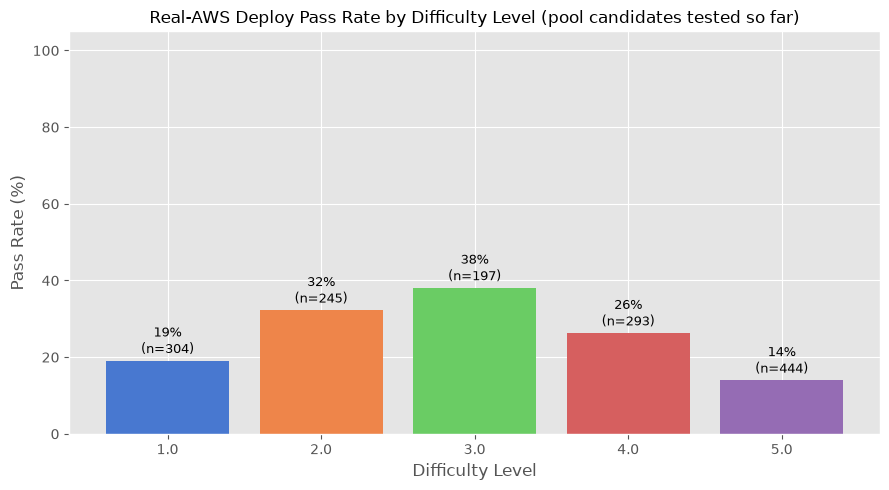

,difficulty,folder_path,deploy_status,error_preview
0,5.0,iac_benchmark/scenarios_greenfield/terrads_8cca5da8d3bc,APPLY_FAILED,"t 'available, storage-optimization'. last error: %!s(<nil>)\n\n with aws_db_instance.tfe_db,\n ..."
1,5.0,iac_benchmark/scenarios/terrads_fa151455649e,APPLY_FAILED,"ariable ""organization_id"" {\n\nThe root module input variable ""organization_id"" is not set, and ..."
2,5.0,iac_benchmark/scenarios/terrads_adae6b931906,APPLY_FAILED,"Error: No value for required variable\n\n on variables.tf line 59:\n 59: variable ""bucket_pref..."
3,5.0,iac_benchmark/scenarios/terrads_b9912ffbd649,APPLY_FAILED,Error: Conflicting configuration arguments\n\n with aws_iam_role.tfer--stacksets-exec-3a13bad69...
4,5.0,iac_benchmark/scenarios/terrads_b5c85ba6fd65,APPLY_FAILED,"Error: No value for required variable(s) -- 5 total: service_name, base_region, base_region_alia..."
...,...,...,...,...
854,1.0,iac_benchmark/scenarios/terrads_33d9f206dd34,APPLY_FAILED,"Error: No value for required variable\n\n on main.tf line 1:\n 1: variable ""vpc_id"" {\n\nThe ..."
855,1.0,iac_benchmark/scenarios/terrads_646803ae7b65,APPLY_FAILED,"Error: No value for required variable\n\n on vars.tf line 6:\n 6: variable ""iam_roles"" {\n\nT..."
856,1.0,iac_benchmark/scenarios/terrads_dd324d7e570f,APPLY_FAILED,"Error: No value for required variable\n\n on variables.tf line 1:\n 1: variable ""rest_api_id""..."
857,1.0,iac_benchmark/scenarios/gh_64c2978a,APPLY_FAILED,"Error: No value for required variable(s) -- 4 total: lambda_function_arn, schedule_expression, n..."


/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_85961/1849725926.py:81: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()





Candidates likely worth a minimal-fix triage pass (mechanical, verifiable, single-cause failures -- not external dependencies):
  [332x] No value for required variable                    
         - iac_benchmark/scenarios/gh_44d3e419
         - iac_benchmark/scenarios/gh_79c7ca45
         - iac_benchmark/scenarios/gh_095a6ba4
         - iac_benchmark/scenarios/gh_c6697224
         - iac_benchmark/scenarios/gh_c8f58bf6
         ... and 327 more
  [26x] Unsupported argument                              
         - iac_benchmark/scenarios/terrads_a200cd51c798
         - iac_benchmark/scenarios/terrads_4fdc92a34d48
         - iac_benchmark/scenarios/terrads_bd860fbf1fba
         - iac_benchmark/scenarios/terrads_89cecfaa2caf
         - iac_benchmark/scenarios/terrads_a08d097e2d02
         ... and 21 more
  [15x] Error in function call                            
         - iac_benchmark/scenarios/terrads_39aed2e73cac
         - iac_benchmark/scenarios/terrads_d92ead86217d
         - iac_

In [19]:
GT_DEPLOY_CACHE_PATH_ANALYTICS = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'

if not GT_DEPLOY_CACHE_PATH_ANALYTICS.exists():
    print(f'⚠️ {GT_DEPLOY_CACHE_PATH_ANALYTICS.name} not found -- run the deploy-check section above '
          f'first (with RUN_DEPLOYMENT = True) to generate results.')
else:
    gt_results_analytics = pd.read_csv(GT_DEPLOY_CACHE_PATH_ANALYTICS)
    gt = df_pool.merge(gt_results_analytics[['scenario_id', 'deploy_pass', 'deploy_status', 'apply_error',
                                              'destroy_pass', 'destroy_error']],
                        on='scenario_id', how='inner')

    n_checked = len(gt)
    n_total = len(df_pool)
    n_pass = (gt['deploy_pass'] == True).sum()
    n_fail = (gt['deploy_pass'] == False).sum()
    n_error = gt['deploy_pass'].isna().sum()

    print(f'Checked so far: {n_checked} / {n_total} pool candidates ({n_checked / n_total:.1%})' if n_total else '')
    print(f'  ✅ Deployed successfully : {n_pass} ({n_pass / n_checked:.1%})' if n_checked else '')
    print(f'  ❌ Deploy failed         : {n_fail} ({n_fail / n_checked:.1%})' if n_checked else '')
    print(f'  ⚠️  Init/error/skip       : {n_error} ({n_error / n_checked:.1%})' if n_checked else '')

    if 'destroy_pass' in gt.columns:
        orphaned = gt[gt['destroy_pass'] == False]
        if not orphaned.empty:
            print(f"\n🚨 {len(orphaned)} scenario(s) FAILED TO TEAR DOWN and may still exist in AWS:")
            cols = [c for c in ['folder_path', 'destroy_error'] if c in orphaned.columns]
            with pd.option_context('display.max_colwidth', 120, 'display.width', 220):
                display(orphaned[cols].reset_index(drop=True))
            print('   Check the AWS Console directly.')
        else:
            n_attempted = gt['destroy_pass'].notna().sum()
            print(f'\n🧹 Cleanup: {n_attempted} scenario(s) attempted teardown, 0 orphaned.')

    pass_by_diff = gt.groupby('difficulty')['deploy_pass'].apply(lambda s: (s == True).mean() * 100)
    counts_by_diff = gt.groupby('difficulty').size()

    plt.figure(figsize=(9, 5))
    bars = plt.bar(pass_by_diff.index.astype(str), pass_by_diff.values, color=sns.color_palette('muted'))
    plt.title('Real-AWS Deploy Pass Rate by Difficulty Level (pool candidates tested so far)', fontsize=12)
    plt.xlabel('Difficulty Level')
    plt.ylabel('Pass Rate (%)')
    plt.ylim(0, 105)
    for bar, diff in zip(bars, pass_by_diff.index):
        n = counts_by_diff[diff]
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                  f'{bar.get_height():.0f}%\n(n={n})', ha='center', fontsize=9)
    plt.tight_layout()
    plt.show()

    failed = gt[gt['deploy_pass'] == False].copy()
    if not failed.empty:
        failed['error_preview'] = failed['apply_error'].astype(str).str.slice(0, 100)
        cols = [c for c in ['difficulty', 'folder_path', 'deploy_status', 'error_preview'] if c in failed.columns]
        with pd.option_context('display.max_colwidth', 100, 'display.width', 220):
            display(failed.sort_values('difficulty', ascending=False)[cols].reset_index(drop=True))
    else:
        print('\n🎉 No failures among checked candidates so far.')

    if not failed.empty:
        def _error_signature(msg):
            m = re.search(r'Error:\s*([^\n]{0,60})', str(msg))
            if m:
                return m.group(1).strip()
            return ' '.join(str(msg).split()[:6]) or 'Unknown'

        failed['error_signature'] = failed['apply_error'].apply(_error_signature)
        sig_counts = failed['error_signature'].value_counts()

        plt.figure(figsize=(10, max(3, 0.4 * len(sig_counts))))
        sns.barplot(y=sig_counts.index, x=sig_counts.values, hue=sig_counts.index,
                    palette='Reds_r', legend=False)
        plt.title('Failure Signatures Among Failed Candidates', fontsize=13)
        plt.xlabel('# Scenarios')
        plt.ylabel('')
        plt.tight_layout()
        plt.show()

        print('\nCandidates likely worth a minimal-fix triage pass (mechanical, verifiable, '
              'single-cause failures -- not external dependencies):')
        for sig, cnt in sig_counts.items():
            examples = failed[failed['error_signature'] == sig]['folder_path'].tolist()
            print(f'  [{cnt:2d}x] {sig:<50s}')
            for ex in examples[:5]:
                print(f'         - {ex}')
            if len(examples) > 5:
                print(f'         ... and {len(examples) - 5} more')

### §19g Retry skipped & network-error scenarios

In [20]:
import os

_TRANSIENT_ERROR_PATTERNS_RETRY = [
    'Could not connect to the endpoint',
    'connection reset by peer',
    'RequestTimeout',
    'ThrottlingException',
    'RequestLimitExceeded',
    'i/o timeout',
    'no such host',
]

GT_DEPLOY_CACHE_PATH_RETRY = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'

if not GT_DEPLOY_CACHE_PATH_RETRY.exists():
    print(f'⚠️ {GT_DEPLOY_CACHE_PATH_RETRY.name} not found -- nothing to retry yet.')
    RETRY_SKIPPED_NETWORK_PATHS = []
else:
    _cache = pd.read_csv(GT_DEPLOY_CACHE_PATH_RETRY)
    for _c in ('init_error', 'apply_error'):
        if _c not in _cache.columns:
            _cache[_c] = ''

    _skipped = _cache[_cache['deploy_status'] == 'skipped'].copy()
    _skipped['_folder_exists_now'] = _skipped['folder_path'].apply(lambda p: os.path.exists(p))
    _skipped_retriable = _skipped[_skipped['_folder_exists_now']]
    _skipped_stuck = _skipped[~_skipped['_folder_exists_now']]

    _is_transient = pd.Series(False, index=_cache.index)
    for _pattern in _TRANSIENT_ERROR_PATTERNS_RETRY:
        _is_transient |= (
            _cache['init_error'].astype(str).str.contains(_pattern, na=False)
            | _cache['apply_error'].astype(str).str.contains(_pattern, na=False)
        )
    _network_retriable = _cache[_is_transient & (_cache['deploy_status'] != 'skipped') & (_cache['deploy_pass'] != True)]

    RETRY_SKIPPED_NETWORK_PATHS = sorted(set(_skipped_retriable['folder_path']) | set(_network_retriable['folder_path']))

    print(f"📁 Skipped (folder missing when checked): {len(_skipped)} total")
    print(f"   ✅ {len(_skipped_retriable)} now have a folder on disk -- safe to retry")
    if len(_skipped_stuck):
        print(f"   🚧 {len(_skipped_stuck)} STILL missing on disk -- retrying these is pointless until the "
              f"folder actually exists (check whether the source repo needs re-cloning):")
        for p in _skipped_stuck['folder_path'].tolist()[:10]:
            print(f"        - {p}")
        if len(_skipped_stuck) > 10:
            print(f"        ... and {len(_skipped_stuck) - 10} more")

    print(f"\n🔌 {len(_network_retriable)} additional row(s) matched a known-transient network/throttling "
          f"error signature (not already counted as skipped).")

    print(f"\n{len(RETRY_SKIPPED_NETWORK_PATHS)} folder_path(s) total queued for retry -- merging into "
          f"REAL_AWS_TEST_QUEUE (same mechanism as §2b) so §4 picks them up automatically.")
    try:
        REAL_AWS_TEST_QUEUE = sorted(set(REAL_AWS_TEST_QUEUE) | set(RETRY_SKIPPED_NETWORK_PATHS))
    except NameError:
        REAL_AWS_TEST_QUEUE = list(RETRY_SKIPPED_NETWORK_PATHS)

KeyError: 'folder_path'

### §19h Cost-safety sweep: aws-nuke (gated by `RUN_NUKE_SWEEP`)

In [61]:
import os
import subprocess
from datetime import datetime

AWS_PROFILE = os.environ.get('AWS_PROFILE', 'default')
NUKE_CONFIG_PATH = Path('nuke-config.yml')
NUKE_LOG_DIR = DATASET_DIR / 'nuke_logs'

if not RUN_NUKE_SWEEP:
    print('⏸️  RUN_NUKE_SWEEP is False -- skipping. This is a full-account, unattended')
    print('   `aws-nuke run --no-dry-run --no-prompt` -- test manually with a plain dry run')
    print("   first, then set RUN_NUKE_SWEEP = True when you're confident in the config.")
else:
    if not NUKE_CONFIG_PATH.exists():
        raise FileNotFoundError(f'{NUKE_CONFIG_PATH} not found -- expected it next to this notebook.')

    NUKE_LOG_DIR.mkdir(parents=True, exist_ok=True)
    _ts = datetime.now().strftime('%Y%m%dT%H%M%S')
    log_path = NUKE_LOG_DIR / f"nuke_{_ts}.log"

    cmd = [
        'aws-nuke', 'run',
        '--profile', AWS_PROFILE,
        '-c', str(NUKE_CONFIG_PATH),
        '--no-alias-check',
        '--no-dry-run',
        '--no-prompt',
    ]
    print(f'🧨 Running: {" ".join(cmd)}')
    print(f'   Full output -> {log_path}')

    result = subprocess.run(cmd, capture_output=True, text=True, timeout=1800)
    _cmd_str = " ".join(cmd)
    log_path.write_text(f"$ {_cmd_str}\n\n--- stdout ---\n{result.stdout}\n\n--- stderr ---\n{result.stderr}\n")

    print(f'\nExit code: {result.returncode}')
    print('--- last 40 lines of output ---')
    for line in (result.stdout + result.stderr).splitlines()[-40:]:
        print(line)

    if result.returncode != 0:
        print(f'\n🚨 aws-nuke exited non-zero -- read the full log at {log_path} before assuming the account is clean.')
    else:
        print(f'\n✅ Sweep completed. Full log at {log_path}.')

⏸️  RUN_NUKE_SWEEP is False -- skipping. This is a full-account, unattended
   `aws-nuke run --no-dry-run --no-prompt` -- test manually with a plain dry run
   first, then set RUN_NUKE_SWEEP = True when you're confident in the config.


### §19i Post-flight: disable services enabled by pre-flight (gated by `RUN_POSTFLIGHT_TEARDOWN`)

In [ ]:
import os
import boto3
import botocore

AWS_PROFILE = os.environ.get('AWS_PROFILE', 'default')
AWS_REGION = os.environ.get('AWS_REGION', 'us-east-1')

_PREFLIGHT_STACK_NAME = 'tf-eval-gt-config-prereq'


def _postflight_config():
    cfn = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('cloudformation')
    configservice = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('config')
    s3 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('s3')

    try:
        desc = cfn.describe_stacks(StackName=_PREFLIGHT_STACK_NAME)
        status = desc['Stacks'][0]['StackStatus']
    except botocore.exceptions.ClientError:
        print(f"✅ Prereq stack {_PREFLIGHT_STACK_NAME!r} does not exist -- nothing to tear down.")
        return

    print(f"🔧 Tearing down AWS Config prerequisite stack {_PREFLIGHT_STACK_NAME!r} (status={status})...")
    try:
        configservice.stop_configuration_recorder(ConfigurationRecorderName='default')
        print("   Stopped configuration recorder.")
    except botocore.exceptions.ClientError as e:
        _err_code = e.response.get('Error', {}).get('Code', '')
        print(f"   (recorder already stopped or missing: {_err_code})")

    bucket_name = None
    for res in cfn.list_stack_resources(StackName=_PREFLIGHT_STACK_NAME)['StackResourceSummaries']:
        if res['LogicalResourceId'] == 'ConfigBucket':
            bucket_name = res['PhysicalResourceId']
            break
    if bucket_name:
        paginator = s3.get_paginator('list_object_versions')
        to_delete = []
        for page in paginator.paginate(Bucket=bucket_name):
            for v in page.get('Versions', []) + page.get('DeleteMarkers', []):
                to_delete.append({'Key': v['Key'], 'VersionId': v['VersionId']})
        for i in range(0, len(to_delete), 1000):
            batch = to_delete[i:i + 1000]
            if batch:
                s3.delete_objects(Bucket=bucket_name, Delete={'Objects': batch})
        if to_delete:
            print(f"   Emptied {len(to_delete)} object(s) from {bucket_name} before stack deletion.")

    cfn.delete_stack(StackName=_PREFLIGHT_STACK_NAME)
    waiter = cfn.get_waiter('stack_delete_complete')
    waiter.wait(StackName=_PREFLIGHT_STACK_NAME, WaiterConfig={'Delay': 10, 'MaxAttempts': 60})
    print("✅ Config recorder + delivery channel + bucket + role deleted.")


def _postflight_security_hub():
    securityhub = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('securityhub')
    try:
        securityhub.describe_hub()
    except botocore.exceptions.ClientError as e:
        code_ = e.response.get('Error', {}).get('Code', '')
        if code_ in ('InvalidAccessException', 'ResourceNotFoundException'):
            print('✅ Security Hub already disabled -- nothing to do.')
            return
        raise

    print('🔧 Disabling Security Hub...')
    securityhub.disable_security_hub()
    print('✅ Security Hub disabled.')


def _postflight_inspector_ec2():
    inspector2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('inspector2')
    sts = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('sts')
    account_id = sts.get_caller_identity()['Account']

    status = inspector2.batch_get_account_status(accountIds=[account_id])
    resource_state = status['accounts'][0]['resourceState'] if status['accounts'] else {}
    ec2_state = resource_state.get('ec2', {}).get('status')
    if ec2_state in (None, 'DISABLED', 'DISABLING'):
        print('✅ Amazon Inspector for EC2 already disabled -- nothing to do.')
        return

    print('🔧 Disabling Amazon Inspector for EC2...')
    inspector2.disable(accountIds=[account_id], resourceTypes=['EC2'])
    print('✅ Amazon Inspector for EC2 disabled.')


def _postflight_ami_block_public_access():
    ec2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('ec2')
    current = ec2.get_image_block_public_access_state()
    if current.get('ImageBlockPublicAccessState') == 'block-new-sharing':
        print('✅ EC2 AMI block-public-access already restored -- nothing to do.')
        return

    print('🔧 Restoring EC2 "Block Public Access for AMIs" to its default...')
    ec2.enable_image_block_public_access(ImageBlockPublicAccessState='block-new-sharing')
    print('✅ AMI block-public-access restored.')


if not RUN_POSTFLIGHT_TEARDOWN:
    print('⏸️  RUN_POSTFLIGHT_TEARDOWN is False -- skipping. Set to True to disable everything the')
    print('   pre-flight cell turned on, so none of it keeps billing between benchmark runs.')
else:
    _postflight_config()
    _postflight_security_hub()
    _postflight_inspector_ec2()
    _postflight_ami_block_public_access()
    print('\n✅ Post-flight teardown complete -- account restored to its pre-benchmark state.')

## §20 Final Benchmark Assembly (real-AWS files, resample-aware, dedup-aware)

In [21]:
import pandas as pd
import numpy as np
import difflib
from pathlib import Path
from collections import defaultdict
import shutil
from datetime import datetime

ASSEMBLY_DRY_RUN=False

REAL_AWS_CUSTOM_CSV = DATASET_DIR / 'final_benchmark_real_aws_custom.csv'
REAL_AWS_PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
GT_DEPLOY_CACHE_PATH = DATASET_DIR / 'tf_ground_truth_deploy_check_aws.csv'

TARGETS_PER_LEVEL = {1: 50, 2: 50, 3: 50, 4: 50, 5: 50}
DUP_THRESHOLD = 0.90

def read_tf_content(folder_path_str):
    folder = Path(folder_path_str)
    if not folder.exists():
        return ""
    tf_files = sorted(folder.glob('*.tf'))
    return "\n\n".join(f.read_text(encoding='utf-8', errors='ignore').strip() for f in tf_files)

if not REAL_AWS_PROMPTS_CSV.exists():
    print(f"ℹ️ {REAL_AWS_PROMPTS_CSV.name} not found -- performing an INITIAL assembly (every level sampled up to target).")
if not GT_DEPLOY_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"{GT_DEPLOY_CACHE_PATH} not found -- run section 4 (Real-AWS Deploy Check) at least "
        f"once first. This cell only ever keeps/backfills real-AWS-verified (deploy_pass=True) "
        f"scenarios, never an untested one."
    )
if 'df_pool' not in dir():
    raise NameError("df_pool not found -- run section 1 (Real-AWS Candidate Pool) first in this kernel.")

if REAL_AWS_PROMPTS_CSV.exists():
    df_final = pd.read_csv(REAL_AWS_PROMPTS_CSV)
else:
    df_final = pd.DataFrame(columns=list(df_pool.columns) + ['deploy_pass', 'row_number', 'user_prompt', 'tf_code'])
print(f"Loaded frozen real-AWS benchmark: {len(df_final)} scenarios.")

dup_row_numbers = int(df_final['row_number'].duplicated().sum())
if dup_row_numbers:
    raise ValueError(f"❌ {dup_row_numbers} duplicate row_number value(s) already present in "
                      f"{REAL_AWS_PROMPTS_CSV.name} -- fix before proceeding.")

existing_row_map = dict(zip(df_final['folder_path'], df_final['row_number']))
existing_prompt_map = dict(zip(df_final['folder_path'], df_final['user_prompt']))
max_existing_row_number = int(df_final['row_number'].max()) if not df_final.empty else 0

gt_cache = pd.read_csv(GT_DEPLOY_CACHE_PATH)[['scenario_id', 'deploy_pass']].drop_duplicates('scenario_id')
df_deployable_real = df_pool.merge(gt_cache, on='scenario_id', how='inner')
df_deployable_real = df_deployable_real[(df_deployable_real['deploy_pass'] == True) &
                                        (df_deployable_real['scenario_id'].map(get_validate_status_map()) == 'pass')].copy()
df_deployable_real = require_aws_resources(df_deployable_real, label='assembly: ', plan_missing=PLAN_GATE_QUEUE)
print(f"Real-AWS-verified (deploy_pass=True) + TFLint/Trivy-clean candidate pool: "
      f"{len(df_deployable_real):,}")
_TRIVY_IGNORE_RE = re.compile(r'(?:trivy|tfsec):ignore', re.I)


def _has_trivy_ignore(folder_path_str):
    _d = pathlib.Path(folder_path_str)
    if not _d.exists():
        return False
    return any(_TRIVY_IGNORE_RE.search(_f.read_text(errors='ignore')) for _f in _d.glob('*.tf'))


_suppressed_mask = df_deployable_real['folder_path'].map(_has_trivy_ignore)
if int(_suppressed_mask.sum()):
    print(f"🚫 {int(_suppressed_mask.sum())} candidate(s) excluded: ground truth carries a "
          f"'#trivy:ignore:' comment.")
df_deployable_real = df_deployable_real[~_suppressed_mask].copy()
print(f"Suppression-free candidate pool: {len(df_deployable_real):,}")

freed_row_numbers_by_level = defaultdict(list)
old_paths = set(df_final['folder_path'])
deployable_paths = set(df_deployable_real['folder_path'])
dropped_paths = old_paths - deployable_paths

if dropped_paths:
    print(f"\n🔍 {len(dropped_paths)} previously-kept row(s) no longer qualify (insecure, "
          f"licence-ineligible, or excluded) -- will be dropped and backfilled:")
    for fp in sorted(dropped_paths)[:15]:
        print(f"   - {fp}")
    if len(dropped_paths) > 15:
        print(f"   ... and {len(dropped_paths) - 15} more.")
else:
    print("\n✅ Every previously-kept row still qualifies.")

_vstat = get_validate_status_map()
_trivy_clean_paths = set(pd.read_csv(TRIVY_FILTERED_CSV, usecols=['folder_path'], low_memory=False)['folder_path'])
_gt_pass_ids = set(gt_cache.loc[gt_cache['deploy_pass'] == True, 'scenario_id'])
_final_first = df_final.drop_duplicates('folder_path').set_index('folder_path')
drop_reasons = {}
for fp in dropped_paths:
    _r = _final_first.loc[fp]
    _sid, _src = _r.get('scenario_id'), _r.get('source')
    if fp in MANUAL_EXCLUDE_SET:
        drop_reasons[fp] = 'excluded (MANUAL_EXCLUDE_FOLDER_PATHS)'
    elif fp not in _trivy_clean_paths:
        drop_reasons[fp] = 'not TFLint+Trivy-clean'
    elif not is_licence_eligible(_src):
        drop_reasons[fp] = 'licence-ineligible'
    elif _vstat.get(_sid) == 'fail':
        drop_reasons[fp] = 'terraform validate failed'
    elif _sid not in _vstat:
        drop_reasons[fp] = 'terraform validate untested'
    elif _sid not in _gt_pass_ids:
        drop_reasons[fp] = 'not real-AWS deploy-passed'
    elif aws_resource_counts([_sid]).get(_sid, MIN_AWS_RESOURCES) < MIN_AWS_RESOURCES:
        drop_reasons[fp] = 'creates no AWS resource (or count unknown)'
    else:
        drop_reasons[fp] = 'other (not in pool)'
if drop_reasons:
    print("\nDrop reasons:")
    print(pd.Series(drop_reasons).value_counts().to_string())

_mass_drop_frac = (len(dropped_paths) / len(old_paths)) if old_paths else 0.0
MASS_DROP_BLOCKED = _mass_drop_frac > MASS_DROP_THRESHOLD and not ALLOW_MASS_DROP
if MASS_DROP_BLOCKED:
    print(f"\n🛑 {len(dropped_paths)}/{len(old_paths)} ({_mass_drop_frac:.0%}) frozen rows would be dropped -- above "
          f"MASS_DROP_THRESHOLD={MASS_DROP_THRESHOLD:.0%}. Writing will be REFUSED unless ALLOW_MASS_DROP=True. "
          f"If most reasons are 'terraform validate untested', run §16 first.")


old_difficulty_map = dict(zip(df_final['folder_path'], df_final['difficulty']))
for fp in dropped_paths:
    lvl = old_difficulty_map.get(fp)
    if lvl is not None and fp in existing_row_map:
        freed_row_numbers_by_level[int(lvl)].append(existing_row_map[fp])

df_final = df_final[~df_final['folder_path'].isin(dropped_paths)].copy()

truth_difficulty_map = dict(zip(df_pool['folder_path'], df_pool['difficulty']))
truth_services_map = dict(zip(df_pool['folder_path'], df_pool['aws_services']))
df_final['difficulty'] = df_final['folder_path'].map(truth_difficulty_map).fillna(df_final['difficulty']).astype(int)
df_final['aws_services'] = df_final['folder_path'].map(truth_services_map).fillna(df_final.get('aws_services', ''))

final_dfs = []
next_row_number = max_existing_row_number + 1
scenarios_dropped = list(dropped_paths)
scenarios_added = []

def _base_id(s):
    s = str(s)
    return s[:-len('_manualfix')] if s.endswith('_manualfix') else s

def _blank_prompt(p):
    return p is None or (isinstance(p, float) and np.isnan(p)) or str(p).strip() == ''

_prompt_overrides = {}
if PROMPT_OVERRIDES_CSV.exists():
    _po = pd.read_csv(PROMPT_OVERRIDES_CSV)
    _prompt_overrides = dict(zip(_po['base_scenario_id'], _po['user_prompt']))

def _prompt_for(scenario_id, current, reference):
    b = _base_id(scenario_id)
    if str(scenario_id).endswith('_manualfix') and b in _prompt_overrides:
        return _prompt_overrides[b]
    return reference if _blank_prompt(current) else current

reference_row_numbers, _ref_bases_all, _restore_renumbered_paths = set(), set(), set()
if RESTORE_REFERENCE_COMPOSITION and RESTORE_REFERENCE_CSV.exists():
    df_ref = pd.read_csv(RESTORE_REFERENCE_CSV)
    df_ref['base'] = df_ref['scenario_id'].map(_base_id)
    df_ref['row_number'] = df_ref['row_number'].astype(int)
    reference_row_numbers = set(df_ref['row_number'])
    _ref_bases_all = set(df_ref['base'])
    _ref = df_ref.set_index('base')

    _q = df_deployable_real.assign(_b=df_deployable_real['scenario_id'].map(_base_id),
                                   _mf=df_deployable_real['scenario_id'].astype(str).str.endswith('_manualfix'))
    _q = _q.sort_values('_mf', ascending=False).drop_duplicates('_b').set_index('_b')
    _pool_ids = set(df_pool['scenario_id'])

    df_final['row_number'] = df_final['row_number'].astype(int)
    _present_base = df_final['scenario_id'].map(_base_id)

    _target_rn = {}
    for i in df_final.index[_present_base.isin(_ref_bases_all)]:
        b = _present_base[i]
        df_final.at[i, 'user_prompt'] = _prompt_for(df_final.at[i, 'scenario_id'], df_final.at[i, 'user_prompt'],
                                                   _ref.loc[b, 'user_prompt'])
        if int(df_final.at[i, 'row_number']) != int(_ref.loc[b, 'row_number']):
            _target_rn[i] = int(_ref.loc[b, 'row_number'])

    _restore_recs, restore_unqualified = [], {}
    for b in df_ref['base']:
        if b in set(_present_base):
            continue
        if b in _q.index:
            rec = _q.loc[b].drop(labels=['_mf']).to_dict()
            rec['row_number'] = int(_ref.loc[b, 'row_number'])
            rec['user_prompt'] = _prompt_for(rec['scenario_id'], None, _ref.loc[b, 'user_prompt'])
            rec['tf_code'] = read_tf_content(rec['folder_path'])
            _restore_recs.append(rec)
            continue
        cand = f"{b}_manualfix" if f"{b}_manualfix" in _pool_ids else b
        if cand not in _pool_ids:
            restore_unqualified[b] = 'not in pool (TFLint/Trivy/licence/exclusion)'
        elif _vstat.get(cand) == 'fail':
            restore_unqualified[b] = 'terraform validate failed'
        elif cand not in _vstat:
            restore_unqualified[b] = 'terraform validate untested'
        elif cand not in _gt_pass_ids:
            restore_unqualified[b] = 'not real-AWS deploy-passed (untested or failed)'
        else:
            restore_unqualified[b] = 'other (not in df_deployable_real)'

    _claimed = set(_target_rn.values()) | {r['row_number'] for r in _restore_recs}
    _displace = df_final[(~_present_base.isin(_ref_bases_all)) & df_final['row_number'].isin(_claimed)]
    _vacated = sorted({int(df_final.at[i, 'row_number']) for i in _target_rn} - _claimed - reference_row_numbers)
    next_row_number = max(next_row_number, max(reference_row_numbers) + 1)
    for i, rn in _target_rn.items():
        df_final.at[i, 'row_number'] = rn
    _displaced_moves = []
    for i in _displace.index:
        if _vacated:
            _new_rn = _vacated.pop(0)
        else:
            _new_rn, next_row_number = next_row_number, next_row_number + 1
        _displaced_moves.append((df_final.at[i, 'folder_path'], int(df_final.at[i, 'row_number']), _new_rn))
        df_final.at[i, 'row_number'] = _new_rn
    _restore_renumbered_paths = {df_final.at[i, 'folder_path'] for i in _target_rn} | {fp for fp, _, _ in _displaced_moves}
    if _restore_recs:
        _new = pd.DataFrame(_restore_recs)
        _new['difficulty'] = _new['difficulty'].astype(int)
        df_final = pd.concat([df_final, _new], ignore_index=True, sort=False)
        scenarios_added.extend(_new['folder_path'])

    freed_row_numbers_by_level = defaultdict(list, {
        lvl: [n for n in nums if int(n) not in reference_row_numbers] for lvl, nums in freed_row_numbers_by_level.items()})

    print(f"\n♻️ Reference composition ({RESTORE_REFERENCE_CSV.name}, {len(df_ref)} rows):")
    print(f"   {int(_present_base.isin(_ref_bases_all).sum())} present, {len(_target_rn)} moved back to their reference row_number, "
          f"{len(_restore_recs)} restored, {len(_displaced_moves)} non-reference row(s) moved off a reference row_number, "
          f"{len(restore_unqualified)} not (yet) qualifying.")
    for r in _restore_recs:
        print(f"   + L{r['difficulty']} row {r['row_number']}: {r['scenario_id']}")
    for fp, _old_rn, _new_rn in _displaced_moves:
        print(f"   ~ moved off reference row {_old_rn} -> row {_new_rn}: {fp}")
    if restore_unqualified:
        print("   Not qualifying yet (by reason):")
        print('   ' + pd.Series(restore_unqualified).value_counts().to_string().replace('\n', '\n   '))


print("\n⚖️ Balancing difficulty levels (dedup-aware, row-number-stable)...\n")

for level in range(1, 6):
    target = TARGETS_PER_LEVEL.get(level, 0)
    df_lvl = df_final[df_final['difficulty'] == level].copy()
    n_kept = len(df_lvl)

    kept_by_block = defaultdict(list)
    for _, r in df_lvl.iterrows():
        kept_by_block[_block_key(r)].append(read_tf_content(r['folder_path']))

    if n_kept == target:
        print(f"  ✅ Level {level}: Perfect at exactly {target} kept scenarios.")
        final_dfs.append(df_lvl)

    elif n_kept < target:
        shortfall = target - n_kept
        candidates = df_deployable_real[
            (df_deployable_real['difficulty'] == level) &
            (~df_deployable_real['folder_path'].isin(df_final['folder_path']))
        ].copy()

        ordered = sample_diverse(candidates, len(candidates)).to_dict('records') if len(candidates) else []

        accepted = []
        accepted_content_by_block = defaultdict(list)
        for rec in ordered:
            if len(accepted) >= shortfall:
                break
            content = read_tf_content(rec['folder_path'])
            key = _block_key(rec)
            against = kept_by_block.get(key, []) + accepted_content_by_block.get(key, [])
            is_dup = any(difflib.SequenceMatcher(None, content, other).quick_ratio() >= DUP_THRESHOLD for other in against)
            if not is_dup:
                rec['tf_code'] = content
                accepted.append(rec)
                accepted_content_by_block[key].append(content)
                scenarios_added.append(rec['folder_path'])

        sampled = pd.DataFrame(accepted)
        n_reused = 0
        if not sampled.empty:
            freed_here = [n for n in freed_row_numbers_by_level.get(level, []) if int(n) not in reference_row_numbers]
            n_reused = min(len(sampled), len(freed_here))
            assigned = list(freed_here[:n_reused])
            for _ in range(len(sampled) - n_reused):
                assigned.append(next_row_number)
                next_row_number += 1
            sampled['row_number'] = assigned
            sampled['user_prompt'] = np.nan
            df_lvl = pd.concat([df_lvl, sampled], ignore_index=True)

        n_short = shortfall - len(accepted)
        if n_short > 0:
            print(f"  ⚠️ Level {level}: Needed {shortfall}, only found {len(accepted)} real-AWS-verified "
                  f"non-duplicate candidate(s) ({n_short} short -- left explicitly under-filled, "
                  f"never padded with an untested/failing row).")
        print(f"  ➕ Level {level}: Kept {n_kept}, sampled {len(sampled)} new diverse scenarios to "
              f"reach {len(df_lvl)} ({n_reused} reused freed row_number(s)).")
        final_dfs.append(df_lvl)

    else:
        excess = n_kept - target
        df_lvl_indexed = df_lvl.set_index('aws_services')
        _ref_paths_lvl = set(df_lvl.loc[df_lvl['scenario_id'].map(_base_id).isin(_ref_bases_all), 'folder_path'])
        for _ in range(excess):
            _trimmable = df_lvl_indexed[~df_lvl_indexed['folder_path'].isin(_ref_paths_lvl)]
            if _trimmable.empty:
                _trimmable = df_lvl_indexed
            top_arch = _trimmable.index.value_counts().idxmax()
            row_to_drop = _trimmable.loc[[top_arch]].iloc[0]
            scenarios_dropped.append(row_to_drop['folder_path'])
            df_lvl_indexed = df_lvl_indexed[df_lvl_indexed['folder_path'] != row_to_drop['folder_path']]
        df_lvl = df_lvl_indexed.reset_index()
        print(f"  ➖ Level {level}: Dropped {excess} excess scenarios (prioritizing redundancy) to reach {target}.")
        final_dfs.append(df_lvl)

df_balanced = pd.concat(final_dfs, ignore_index=True)
if _prompt_overrides:
    _ob = df_balanced['scenario_id'].map(_base_id)
    _om = df_balanced['scenario_id'].astype(str).str.endswith('_manualfix') & _ob.isin(set(_prompt_overrides))
    df_balanced.loc[_om, 'user_prompt'] = _ob[_om].map(_prompt_overrides)

if 'tf_code' in df_balanced.columns:
    missing_code = df_balanced['tf_code'].isna() | (df_balanced['tf_code'] == '')
    if missing_code.any():
        df_balanced.loc[missing_code, 'tf_code'] = df_balanced.loc[missing_code, 'folder_path'].apply(read_tf_content)
else:
    df_balanced['tf_code'] = df_balanced['folder_path'].apply(read_tf_content)

df_balanced = df_balanced.sort_values('row_number').reset_index(drop=True)

_carried_forward = set(existing_row_map.keys()) & set(df_balanced['folder_path'])
_new_row_number_map = dict(zip(df_balanced['folder_path'], df_balanced['row_number']))
_stability_violations = {
    p: (existing_row_map[p], _new_row_number_map[p])
    for p in _carried_forward
    if existing_row_map[p] != _new_row_number_map[p] and p not in _restore_renumbered_paths
}
if _stability_violations:
    raise AssertionError(
        f"Row-number stability violated for {len(_stability_violations)} carried-forward "
        f"row(s) -- refusing to write {REAL_AWS_PROMPTS_CSV.name}. Sample violations "
        f"(folder_path: (old_row_number, new_row_number)): "
        f"{dict(list(_stability_violations.items())[:5])}"
    )
print(f"\n✅ Row-number stability guard: all {len(_carried_forward)} carried-forward row(s) kept their exact row_number.")

if ASSEMBLY_DRY_RUN:
    print(f"\n🧪 ASSEMBLY_DRY_RUN=True -- nothing written. Would write {len(df_balanced)} scenarios to "
          f"{REAL_AWS_PROMPTS_CSV.name} / {REAL_AWS_CUSTOM_CSV.name}.")
elif MASS_DROP_BLOCKED:
    raise RuntimeError(
        f"Refusing to write {REAL_AWS_PROMPTS_CSV.name}: {len(dropped_paths)}/{len(old_paths)} frozen rows would be "
        f"dropped ({_mass_drop_frac:.0%} > {MASS_DROP_THRESHOLD:.0%}). See 'Drop reasons' above; set "
        f"ALLOW_MASS_DROP=True only if this is intended."
    )
else:
    _ts = datetime.now().strftime('%Y%m%d_%H%M%S')
    if REAL_AWS_PROMPTS_CSV.exists():
        shutil.copy2(REAL_AWS_PROMPTS_CSV, REAL_AWS_PROMPTS_CSV.with_suffix(f'.bak_{_ts}.csv'))

    df_balanced.to_csv(REAL_AWS_PROMPTS_CSV, index=False)
    df_balanced.to_csv(REAL_AWS_CUSTOM_CSV, index=False)

    print(f"\n🎉 Real-AWS benchmark reassembled with {len(df_balanced)} scenarios.")
    print(f"📁 Updated: {REAL_AWS_PROMPTS_CSV.name}")
    print(f"📁 Updated: {REAL_AWS_CUSTOM_CSV.name}")

print("\n📝 Changelog:")
if scenarios_dropped:
    print(f"🔴 Dropped {len(set(scenarios_dropped))} scenario(s) this run:")
    for f in sorted(set(scenarios_dropped)): print(f"   - {f}")
else:
    print("🔴 Dropped 0 scenarios this run.")
if scenarios_added:
    print(f"\n🟢 Added {len(scenarios_added)} scenario(s) this run:")
    for f in sorted(scenarios_added): print(f"   + {f}")
else:
    print("\n🟢 Added 0 scenarios this run.")

print("\nCurrent per-level composition:")
level_counts = df_balanced['difficulty'].value_counts().sort_index().to_dict()
for level in range(1, 6):
    have = level_counts.get(level, 0)
    target = TARGETS_PER_LEVEL.get(level, 0)
    flag = "✅" if have >= target else f"🚧 short by {target - have}"
    print(f"  L{level}: {have}/{target}  {flag}")

missing_prompts = int((df_balanced['user_prompt'].isna() | (df_balanced['user_prompt'].astype(str).str.strip() == '')).sum())
if missing_prompts:
    print(f"\n⚠️ {missing_prompts} row(s) need a prompt -- run section 6b (merge from "
          f"review-benchmark/tf_output.csv) or generate_llm_prompts.py pointed at this file via "
          f"TF_PROMPTS_CSV, then section 7b (near-duplicate check), then section 8 (format eval).")
else:
    print("\n🚀 Next: section 7b (near-duplicate check), then section 8 (format eval).")

Loaded frozen real-AWS benchmark: 250 scenarios.
assembly: plan (AWS resource count): 0 to run (2 workers).
   assembly: AWS resource gate: dropped 66 that create fewer than 1 aws_* resource(s); kept 3 with an unknown count (plan failed)
Real-AWS-verified (deploy_pass=True) + TFLint/Trivy-clean candidate pool: 285
🚫 6 candidate(s) excluded: ground truth carries a '#trivy:ignore:' comment.
Suppression-free candidate pool: 279

🔍 2 previously-kept row(s) no longer qualify (insecure, licence-ineligible, or excluded) -- will be dropped and backfilled:
   - iac_benchmark/scenarios/gh_60daefa3
   - iac_benchmark/scenarios/terrads_b9159bfdb8e7

Drop reasons:
excluded (MANUAL_EXCLUDE_FOLDER_PATHS)    1
other (not in pool)                       1

♻️ Reference composition (final_benchmark_real_aws_with_prompts_12Sep.csv, 250 rows):
   187 present, 0 moved back to their reference row_number, 6 restored, 0 non-reference row(s) moved off a reference row_number, 57 not (yet) qualifying.
   + L2.0 r

## §21 Post-Resample Near-Duplicate Check

In [22]:
import difflib
from collections import defaultdict

PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'

df_check = pd.read_csv(PROMPTS_CSV)
df_check['content'] = df_check['folder_path'].apply(read_tf_content)

blocks = defaultdict(list)
for _, row in df_check.iterrows():
    blocks[_block_key(row)].append(row)

DUP_THRESHOLD = 0.90
content_dup_pairs = []
for key, rows in blocks.items():
    if len(rows) < 2:
        continue
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            a, b = rows[i], rows[j]
            ratio = difflib.SequenceMatcher(None, a['content'], b['content']).quick_ratio()
            if ratio >= DUP_THRESHOLD:
                content_dup_pairs.append((a, b, ratio))

path_groups = defaultdict(list)
for _, row in df_check.iterrows():
    path_groups[row['folder_path']].append(row)
path_dups = {p: rows for p, rows in path_groups.items() if len(rows) > 1}

any_found = bool(content_dup_pairs) or bool(path_dups)

if content_dup_pairs:
    print(f"⚠️ Content-similarity check: {len(content_dup_pairs)} near-duplicate pair(s) (quick_ratio >= {DUP_THRESHOLD}):")
    for a, b, ratio in sorted(content_dup_pairs, key=lambda t: -t[2]):
        print(f"\n  similarity={ratio:.3f}")
        print(f"    row {a['row_number']} (difficulty {a['difficulty']}): {a['folder_path']}")
        print(f"    row {b['row_number']} (difficulty {b['difficulty']}): {b['folder_path']}")
else:
    print(f"✅ Content-similarity check: no pairs found (quick_ratio >= {DUP_THRESHOLD}).")

print()
if path_dups:
    print(f"⚠️ Same-folder-path check: {len(path_dups)} folder(s) used by more than one row:")
    for p, rows in path_dups.items():
        print(f"\n  folder: {p}")
        for row in rows:
            print(f"    row {row['row_number']} (difficulty {row['difficulty']})")
else:
    print("✅ Same-folder-path check: no folder is used by more than one row.")

if any_found:
    print("\nTo resolve: add the folder_path you want dropped to MANUAL_EXCLUDE_FOLDER_PATHS in "
          "section 1 and rerun sections 1 and 7.")

✅ Content-similarity check: no pairs found (quick_ratio >= 0.9).

✅ Same-folder-path check: no folder is used by more than one row.


## §22 Establish the Final Evaluation Dataset

In [25]:
import pandas as pd

PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
FINAL_EVAL_CSV = DATASET_DIR / 'tf_eval_benchmark_real_aws.csv'

if not PROMPTS_CSV.exists():
    raise FileNotFoundError(f"⚠️ {PROMPTS_CSV} not found. Run section 7 (Real-AWS Benchmark Assembly) "
                             f"first, then generate_llm_prompts.py (pointed at this file via "
                             f"TF_PROMPTS_CSV) to backfill prompts for newly sampled rows.")

df_prompts = pd.read_csv(PROMPTS_CSV)
print(f"Loaded {len(df_prompts)} total scenarios from {PROMPTS_CSV.name}")

missing_prompts = df_prompts['user_prompt'].isna().sum()
if missing_prompts:
    print(f"⚠️ {missing_prompts} row(s) still have no generated prompt -- run:")
    print(f"   TF_PROMPTS_CSV={PROMPTS_CSV} python3 generate_llm_prompts.py")

df_out = pd.DataFrame({
    'row_number': df_prompts['row_number'],
    'ground_truth_path': df_prompts['folder_path'],
    'prompt': df_prompts['user_prompt'],
    'difficulty': df_prompts['difficulty'],
})
df_out = df_out.sort_values('row_number').reset_index(drop=True)

dupe_rows = df_out['row_number'].duplicated().sum()
if dupe_rows:
    raise ValueError(f"❌ {dupe_rows} duplicate row_number value(s) detected in the final dataset.")

df_out.to_csv(FINAL_EVAL_CSV, index=False)

print(f"\n✅ Successfully formatted {len(df_out)} rows for evaluation.")
print(f"📁 Saved to: {FINAL_EVAL_CSV}\n")
display(df_out.head())

Loaded 250 total scenarios from final_benchmark_real_aws_with_prompts.csv

✅ Successfully formatted 250 rows for evaluation.
📁 Saved to: iac_benchmark/dataset/tf_eval_benchmark_real_aws.csv



,row_number,ground_truth_path,prompt,difficulty
0,0,iac_benchmark/scenarios_greenfield/terrads_c33...,We need a Terraform template that creates an A...,1
1,1,iac_benchmark/scenarios_greenfield/gh_7edd0214,We need a Terraform template that creates an A...,1
2,2,iac_benchmark/scenarios/terrads_f455759ec10b,We need a Terraform template that creates a sy...,1
3,3,iac_benchmark/scenarios_greenfield/terrads_894...,"We need a Terraform template that creates, ins...",1
4,4,iac_benchmark/scenarios/terrads_cab079b29b84,We need a Terraform template that creates an I...,1


In [26]:
import pandas as pd

DIFF345_EVAL_CSV = DATASET_DIR / 'tf_eval_benchmark_real_aws_diff345.csv'
DIFF345_V1_CSV = DATASET_DIR / 'tf_eval_benchmark_real_aws_diff345_v1.csv'

if not FINAL_EVAL_CSV.exists():
    raise FileNotFoundError(f"⚠️ {FINAL_EVAL_CSV} not found. Run section 8 (Format Real-AWS "
                             f"Dataset for Evaluation) first.")

df_full_eval = pd.read_csv(FINAL_EVAL_CSV)
df_new345 = df_full_eval[df_full_eval['difficulty'].isin([3, 4, 5])].copy()
df_new345 = df_new345.sort_values('row_number').reset_index(drop=True)

if not DIFF345_EVAL_CSV.exists():
    print(f"ℹ️ {DIFF345_EVAL_CSV.name} doesn't exist yet -- nothing to snapshot as "
          f"{DIFF345_V1_CSV.name} or diff against (this must be the first time section 8b has "
          f"run). Skipping changelog and containment check; all {len(df_new345)} rows will be "
          f"written fresh.")
else:
    df_old345 = pd.read_csv(DIFF345_EVAL_CSV)

    df_old345.to_csv(DIFF345_V1_CSV, index=False)
    print(f"💾 Snapshotted the pre-this-run diff345 ({len(df_old345)} rows) -> {DIFF345_V1_CSV.name}\n")

    old_by_rn = df_old345.set_index('row_number')
    new_by_rn = df_new345.set_index('row_number')

    old_rns = set(old_by_rn.index)
    new_rns = set(new_by_rn.index)
    added_rns = sorted(new_rns - old_rns)
    removed_rns = sorted(old_rns - new_rns)
    shared_rns = sorted(old_rns & new_rns)

    changed = []
    for rn in shared_rns:
        o, n = old_by_rn.loc[rn], new_by_rn.loc[rn]
        reasons = []
        if o['ground_truth_path'] != n['ground_truth_path']:
            reasons.append('ground truth changed')
        if o['prompt'] != n['prompt']:
            reasons.append('prompt changed')
        if o['difficulty'] != n['difficulty']:
            reasons.append('difficulty changed')
        if reasons:
            changed.append({
                'row_number': rn,
                'reason': ' + '.join(reasons),
                'old_ground_truth_path': o['ground_truth_path'],
                'new_ground_truth_path': n['ground_truth_path'],
            })

    changed_row_numbers = sorted(c['row_number'] for c in changed)

    print(f"Diff345 changelog (v1 -> new):")
    print(f"  Added row_numbers   : {added_rns if added_rns else '(none)'}")
    print(f"  Removed row_numbers : {removed_rns if removed_rns else '(none)'}")
    print(f"  Changed row_numbers : {changed_row_numbers if changed_row_numbers else '(none)'}")
    print(f"  Unchanged           : {len(shared_rns) - len(changed)} / {len(shared_rns)} shared rows")

    if added_rns:
        print(f"\nAdded rows ({len(added_rns)}):")
        for rn in added_rns:
            n = new_by_rn.loc[rn]
            print(f"  row {rn}: new scenario — {n['ground_truth_path']}")

    if removed_rns:
        print(f"\nRemoved rows ({len(removed_rns)}):")
        for rn in removed_rns:
            o = old_by_rn.loc[rn]
            print(f"  row {rn}: no longer in the L3/4/5 slice — {o['ground_truth_path']}")

    if changed:
        print(f"\nChanged rows ({len(changed)}):")
        for c in changed:
            print(f"  row {c['row_number']}: {c['reason']}")
            if c['old_ground_truth_path'] != c['new_ground_truth_path']:
                print(f"      ground_truth_path: {c['old_ground_truth_path']}")
                print(f"                      -> {c['new_ground_truth_path']}")

    df_diff345_changelog = pd.DataFrame(changed)
    if not df_diff345_changelog.empty:
        display(df_diff345_changelog)

    def _check_containment(df_v1, target_df, target_name, path_col):
        target_by_rn = target_df.set_index('row_number')
        missing = []
        for rn, r in df_v1.set_index('row_number').iterrows():
            if rn not in target_by_rn.index:
                missing.append((rn, r['ground_truth_path'], 'row_number not found'))
            elif target_by_rn.loc[rn, path_col] != r['ground_truth_path']:
                missing.append((rn, r['ground_truth_path'],
                                 f"{path_col} mismatch: {target_by_rn.loc[rn, path_col]}"))
        if missing:
            print(f"\n❌ {len(missing)}/{len(df_v1)} v1 row(s) NOT fully contained in {target_name}:")
            for rn, gt, reason in missing:
                print(f"   row {rn} ({gt}): {reason}")
        else:
            print(f"\n✅ All {len(df_v1)} v1 rows are fully contained in {target_name} "
                  f"(matching row_number + {path_col}).")
        return missing

    print("\nContainment check (is v1 still fully present elsewhere)?")
    if PROMPTS_CSV.exists():
        _check_containment(df_old345, pd.read_csv(PROMPTS_CSV), PROMPTS_CSV.name, 'folder_path')
    else:
        print(f"\n⚠️ {PROMPTS_CSV.name} not found -- cannot check containment against it.")

    _check_containment(df_old345, df_full_eval, FINAL_EVAL_CSV.name, 'ground_truth_path')

💾 Snapshotted the pre-this-run diff345 (150 rows) -> tf_eval_benchmark_real_aws_diff345_v1.csv

Diff345 changelog (v1 -> new):
  Added row_numbers   : (none)
  Removed row_numbers : (none)
  Changed row_numbers : (none)
  Unchanged           : 150 / 150 shared rows

Containment check (is v1 still fully present elsewhere)?

✅ All 150 v1 rows are fully contained in final_benchmark_real_aws_with_prompts.csv (matching row_number + folder_path).

✅ All 150 v1 rows are fully contained in tf_eval_benchmark_real_aws.csv (matching row_number + ground_truth_path).


In [27]:
import pandas as pd

DIFF345_EVAL_CSV = DATASET_DIR / 'tf_eval_benchmark_real_aws_diff345.csv'

if not FINAL_EVAL_CSV.exists():
    raise FileNotFoundError(f"⚠️ {FINAL_EVAL_CSV} not found. Run section 8 first.")

df_full_eval = pd.read_csv(FINAL_EVAL_CSV)
df_diff345 = df_full_eval[df_full_eval['difficulty'].isin([3, 4, 5])].copy()
df_diff345 = df_diff345.sort_values('row_number').reset_index(drop=True)

dupe_rows_345 = df_diff345['row_number'].duplicated().sum()
if dupe_rows_345:
    raise ValueError(f"❌ {dupe_rows_345} duplicate row_number value(s) detected in the L3/4/5 slice.")

missing_prompts_345 = df_diff345['prompt'].isna().sum()
if missing_prompts_345:
    print(f"⚠️ {missing_prompts_345} row(s) in the L3/4/5 slice still have no generated prompt.")

df_diff345.to_csv(DIFF345_EVAL_CSV, index=False)

print(f"✅ Formatted {len(df_diff345)} L3/L4/L5 rows for evaluation "
      f"({(df_diff345['difficulty'] == 3).sum()} L3, "
      f"{(df_diff345['difficulty'] == 4).sum()} L4, "
      f"{(df_diff345['difficulty'] == 5).sum()} L5).")
print(f"📁 Saved to: {DIFF345_EVAL_CSV}\n")
display(df_diff345.head())

✅ Formatted 150 L3/L4/L5 rows for evaluation (50 L3, 50 L4, 50 L5).
📁 Saved to: iac_benchmark/dataset/tf_eval_benchmark_real_aws_diff345.csv



,row_number,ground_truth_path,prompt,difficulty
0,7,iac_benchmark/scenarios_greenfield/terrads_003...,We need a Terraform template that creates a se...,3
1,84,iac_benchmark/scenarios/terrads_38c75e1144d6,We need a Terraform template that creates a ve...,3
2,85,iac_benchmark/scenarios_greenfield/terrads_1db...,We need a Terraform template that creates an A...,3
3,86,iac_benchmark/scenarios_greenfield/terrads_651...,We need a Terraform template that creates a co...,3
4,89,iac_benchmark/scenarios_greenfield/terrads_8ec...,We need a Terraform template that creates a mu...,3


In [28]:
from pathlib import Path
import pandas as pd

DATASET_DIR = Path('./iac_benchmark/dataset')
PROMPTS_CSV = REAL_AWS_PROMPTS_CSV
LICENCE_CACHE = DATASET_DIR / 'licence_cache.csv'

EXEMPT_LICENCE_SOURCES = {'Zenodo/TerraDS', 'autoiac-project/iac-eval', 'AmazonScience/Multi-IaC-Eval'}
ALLOWED_SPDX_LICENCE = {'MIT', 'MIT-0', 'Apache-2.0', 'BSD-2-Clause', 'BSD-3-Clause',
                         'ISC', 'MPL-2.0', 'CC0-1.0', 'Unlicense', 'WTFPL'}
COPYLEFT_SPDX_LICENCE = {'GPL-2.0', 'GPL-3.0', 'LGPL-2.1', 'LGPL-3.0', 'AGPL-3.0'}
ELIGIBLE_SPDX = ALLOWED_SPDX_LICENCE | COPYLEFT_SPDX_LICENCE

if not PROMPTS_CSV.exists():
    print(f"⚠️ {PROMPTS_CSV.name} not found -- run Cell 14 first.")
elif not LICENCE_CACHE.exists():
    print(f"⚠️ {LICENCE_CACHE.name} not found -- run Cell 3 first.")
else:
    df_audit = pd.read_csv(PROMPTS_CSV)
    licence_map = pd.read_csv(LICENCE_CACHE, index_col='slug')['spdx'].to_dict()

    def eligibility(source):
        if source in EXEMPT_LICENCE_SOURCES:
            return 'exempt (external dataset)'
        spdx = licence_map.get(source)
        if spdx in ELIGIBLE_SPDX:
            return f'eligible ({spdx})'
        if spdx is None:
            return 'INELIGIBLE (source not in licence_cache.csv)'
        return f'INELIGIBLE ({spdx})'

    df_audit['licence_status'] = df_audit['source'].apply(eligibility)
    violations = df_audit[df_audit['licence_status'].str.startswith('INELIGIBLE')]

    print(f"Audited {len(df_audit)} scenarios in {PROMPTS_CSV.name}.")
    if violations.empty:
        print("✅ Every scenario is from an eligible-licence repo or an exempt external dataset.")
    else:
        print(f"⚠️ {len(violations)} scenario(s) are sourced from a repo WITHOUT an eligible licence:")
        display(violations[['row_number', 'scenario_id', 'source', 'difficulty', 'licence_status']])
        print("\nTo resolve: rerun Cell 14 (it drops these automatically every run), or investigate why Cell 3's licence cache disagrees with what ended up here.")

Audited 250 scenarios in final_benchmark_real_aws_with_prompts.csv.
✅ Every scenario is from an eligible-licence repo or an exempt external dataset.


## §23 Analytics

In [15]:
LOCALSTACK_BENCHMARK_CSV = DATASET_DIR / 'final_benchmark_with_prompts.csv'
REAL_AWS_BENCHMARK_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'

df_localstack = (pd.read_csv(LOCALSTACK_BENCHMARK_CSV) if LOCALSTACK_BENCHMARK_CSV.exists() else
                 pd.DataFrame(columns=['scenario_id', 'source', 'folder_path', 'loc', 'tokens', 'n_resources',
                                       'n_params', 'difficulty', 'user_prompt', 'row_number', 'aws_services']))
df_localstack['benchmark'] = 'LocalStack'
print(f"Loaded {len(df_localstack)} scenarios from {LOCALSTACK_BENCHMARK_CSV.name}")

if REAL_AWS_BENCHMARK_CSV.exists():
    df_real_aws = pd.read_csv(REAL_AWS_BENCHMARK_CSV)
    df_real_aws['benchmark'] = 'Real-AWS'
    print(f"Loaded {len(df_real_aws)} scenarios from {REAL_AWS_BENCHMARK_CSV.name}")
else:
    df_real_aws = pd.DataFrame(columns=list(df_localstack.columns))
    print(f"⚠️ {REAL_AWS_BENCHMARK_CSV.name} not found yet -- run the real-AWS assembly section "
          f"above at least once. Comparison charts below will show the LocalStack benchmark only.")

for _d, _name in ((df_localstack, 'LocalStack'), (df_real_aws, 'Real-AWS')):
    if len(_d) and len(_d) != _d['row_number'].nunique():
        print(f"⚠️ {_name} benchmark has duplicate row_number values -- check it before trusting its charts below.")

BENCHMARK_PALETTE = {'LocalStack': '#4c72b0', 'Real-AWS': '#dd8452'}
BENCHMARK_ORDER = ['LocalStack', 'Real-AWS']

df_compare = pd.concat([df_localstack, df_real_aws], ignore_index=True, sort=False)

print('\nScenario count by benchmark:')
print(df_compare['benchmark'].value_counts().reindex(BENCHMARK_ORDER).to_string())
print('\nDifficulty distribution by benchmark:')
print(df_compare.groupby('benchmark')['difficulty'].value_counts().unstack().reindex(BENCHMARK_ORDER).to_string())

def _word_count(x):
    return len(str(x).split()) if pd.notna(x) else 0

def _char_count(x):
    return len(str(x)) if pd.notna(x) else 0

df_compare['prompt_word_count'] = df_compare['user_prompt'].apply(_word_count)
df_compare['prompt_char_count'] = df_compare['user_prompt'].apply(_char_count)
df_compare['has_prompt'] = df_compare['user_prompt'].notna()

df_compare = df_compare[df_compare['benchmark'] == 'Real-AWS']

Loaded 250 scenarios from final_benchmark_with_prompts.csv
Loaded 250 scenarios from final_benchmark_real_aws_with_prompts.csv

Scenario count by benchmark:
benchmark
LocalStack    250
Real-AWS      250

Difficulty distribution by benchmark:
difficulty  1.0  2.0  3.0  4.0  5.0
benchmark                          
LocalStack   50   50   50   50   50
Real-AWS     50   50   50   50   50


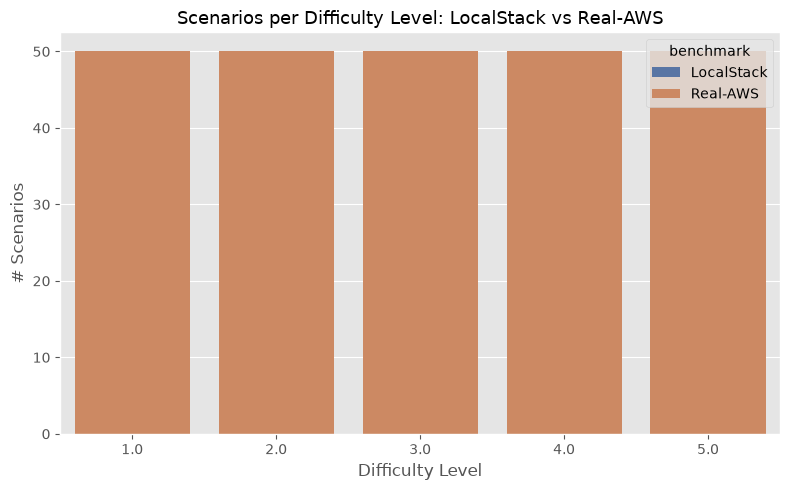

In [16]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_compare, x='difficulty', hue='benchmark', hue_order=BENCHMARK_ORDER,
              palette=BENCHMARK_PALETTE)
plt.title('Scenarios per Difficulty Level: LocalStack vs Real-AWS', fontsize=13)
plt.xlabel('Difficulty Level')
plt.ylabel('# Scenarios')
plt.tight_layout()
plt.show()

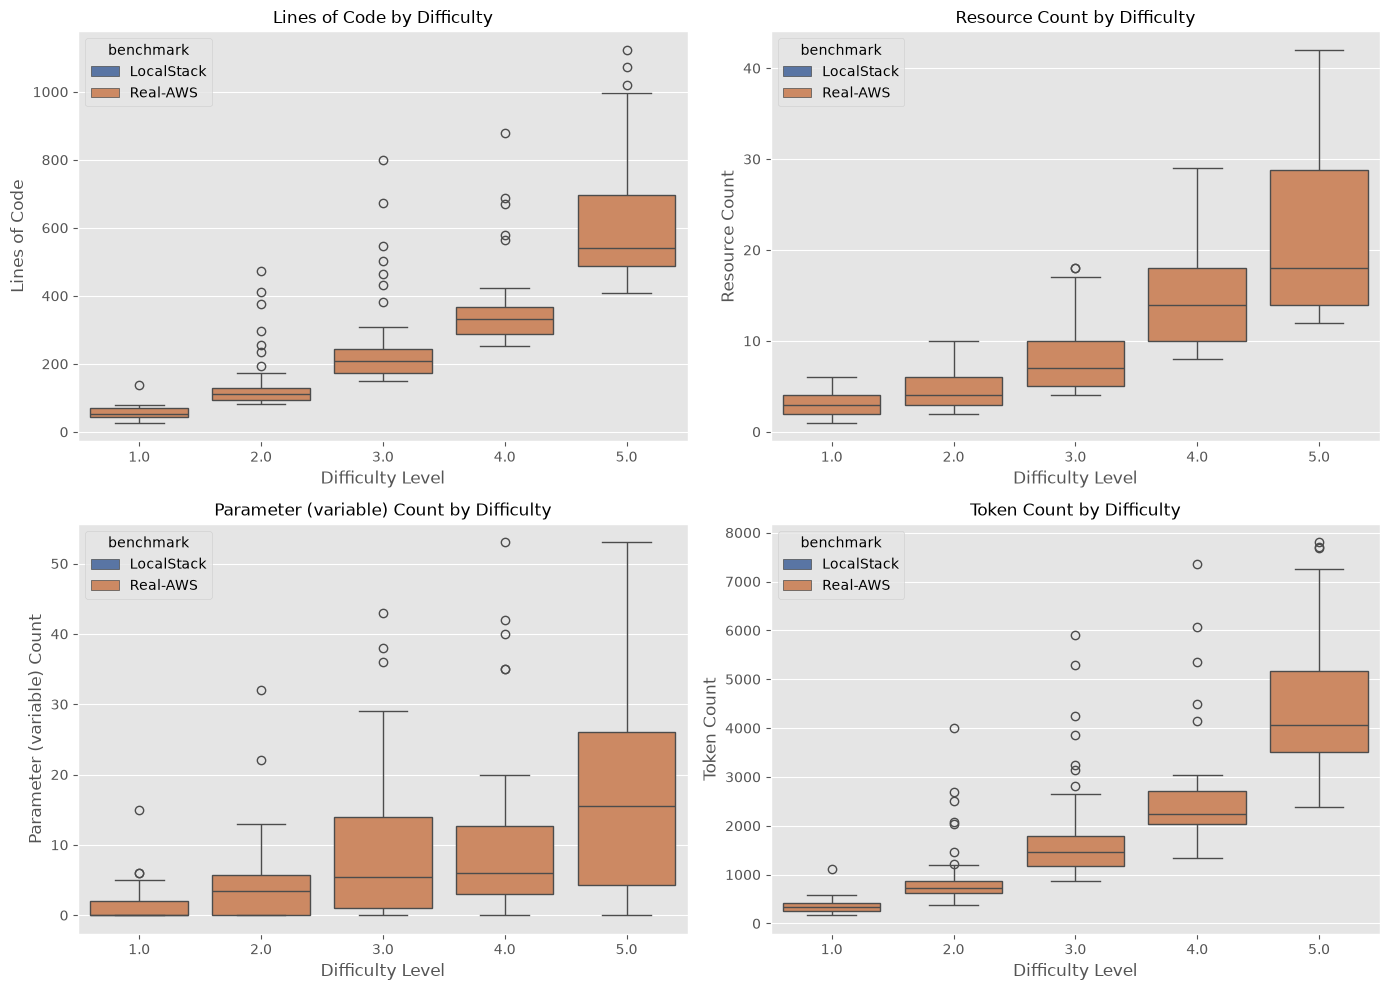

Median values by benchmark and difficulty:

-- loc --
difficulty   1.0    2.0    3.0    4.0    5.0
benchmark                                   
LocalStack   NaN    NaN    NaN    NaN    NaN
Real-AWS    54.0  110.5  209.5  330.5  540.0

-- n_resources --
difficulty  1.0  2.0  3.0   4.0   5.0
benchmark                            
LocalStack  NaN  NaN  NaN   NaN   NaN
Real-AWS    3.0  4.0  7.0  14.0  18.0

-- n_params --
difficulty  1.0  2.0  3.0  4.0   5.0
benchmark                           
LocalStack  NaN  NaN  NaN  NaN   NaN
Real-AWS    0.0  3.5  5.5  6.0  15.5

-- tokens --
difficulty    1.0    2.0     3.0     4.0     5.0
benchmark                                       
LocalStack    NaN    NaN     NaN     NaN     NaN
Real-AWS    328.5  734.5  1466.0  2248.0  4059.0


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col, title in zip(
    axes.flat,
    ['loc', 'n_resources', 'n_params', 'tokens'],
    ['Lines of Code', 'Resource Count', 'Parameter (variable) Count', 'Token Count'],
):
    if col not in df_compare.columns:
        continue
    sns.boxplot(data=df_compare, x='difficulty', y=col, hue='benchmark', hue_order=BENCHMARK_ORDER,
                palette=BENCHMARK_PALETTE, ax=ax)
    ax.set_title(f'{title} by Difficulty', fontsize=12)
    ax.set_xlabel('Difficulty Level')
    ax.set_ylabel(title)
plt.tight_layout()
plt.show()

print('Median values by benchmark and difficulty:')
for col in ['loc', 'n_resources', 'n_params', 'tokens']:
    if col in df_compare.columns:
        print(f"\n-- {col} --")
        print(df_compare.groupby(['benchmark', 'difficulty'])[col].median().unstack().reindex(BENCHMARK_ORDER).to_string())

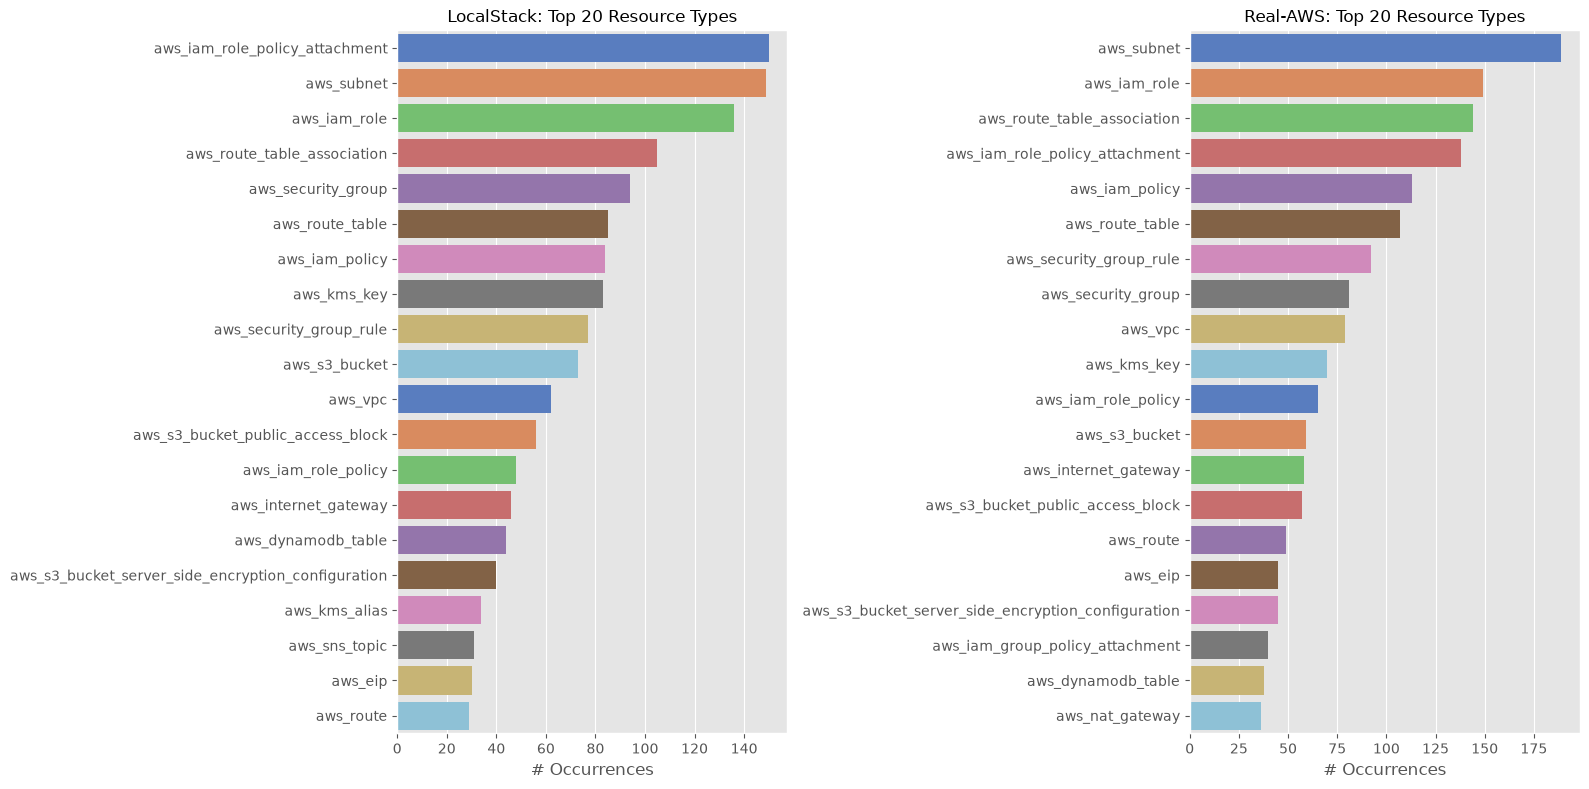

In [18]:
import re
from collections import Counter

def _resource_types(folder_path_str):
    folder = Path(folder_path_str)
    types = []
    if not folder.exists():
        return types
    for tf_file in folder.glob('*.tf'):
        content = tf_file.read_text(encoding='utf-8', errors='ignore')
        types.extend(re.findall(r'resource\s+"(aws_[a-zA-Z0-9_]+)"', content))
    return types

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, (bench_name, df_b) in zip(axes, [('LocalStack', df_localstack), ('Real-AWS', df_real_aws)]):
    if df_b.empty:
        ax.set_title(f'{bench_name}: no data yet')
        continue
    counter = Counter()
    for fp in df_b['folder_path']:
        counter.update(_resource_types(fp))
    top20 = counter.most_common(20)
    if not top20:
        ax.set_title(f'{bench_name}: no resources found')
        continue
    names, counts = zip(*top20)
    sns.barplot(y=list(names), x=list(counts), hue=list(names), palette='muted', legend=False, ax=ax)
    ax.set_title(f'{bench_name}: Top 20 Resource Types', fontsize=12)
    ax.set_xlabel('# Occurrences')
plt.tight_layout()
plt.show()

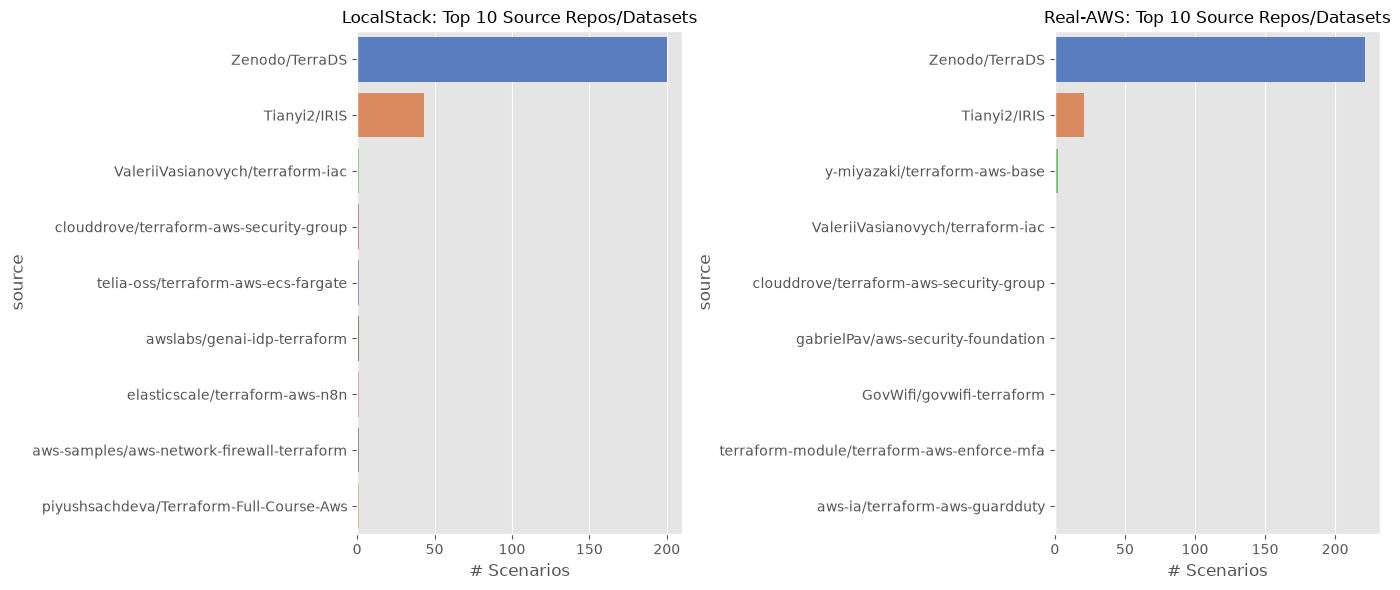

Distinct sources:
  LocalStack: 9 distinct source repos/datasets
  Real-AWS: 9 distinct source repos/datasets


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (bench_name, df_b) in zip(axes, [('LocalStack', df_localstack), ('Real-AWS', df_real_aws)]):
    if df_b.empty or 'source' not in df_b.columns:
        ax.set_title(f'{bench_name}: no data yet')
        continue
    top_sources = df_b['source'].value_counts().head(10)
    sns.barplot(y=top_sources.index, x=top_sources.values, hue=top_sources.index,
                palette='muted', legend=False, ax=ax)
    ax.set_title(f'{bench_name}: Top 10 Source Repos/Datasets', fontsize=12)
    ax.set_xlabel('# Scenarios')
plt.tight_layout()
plt.show()

print('Distinct sources:')
for bench_name, df_b in [('LocalStack', df_localstack), ('Real-AWS', df_real_aws)]:
    if not df_b.empty and 'source' in df_b.columns:
        print(f"  {bench_name}: {df_b['source'].nunique()} distinct source repos/datasets")

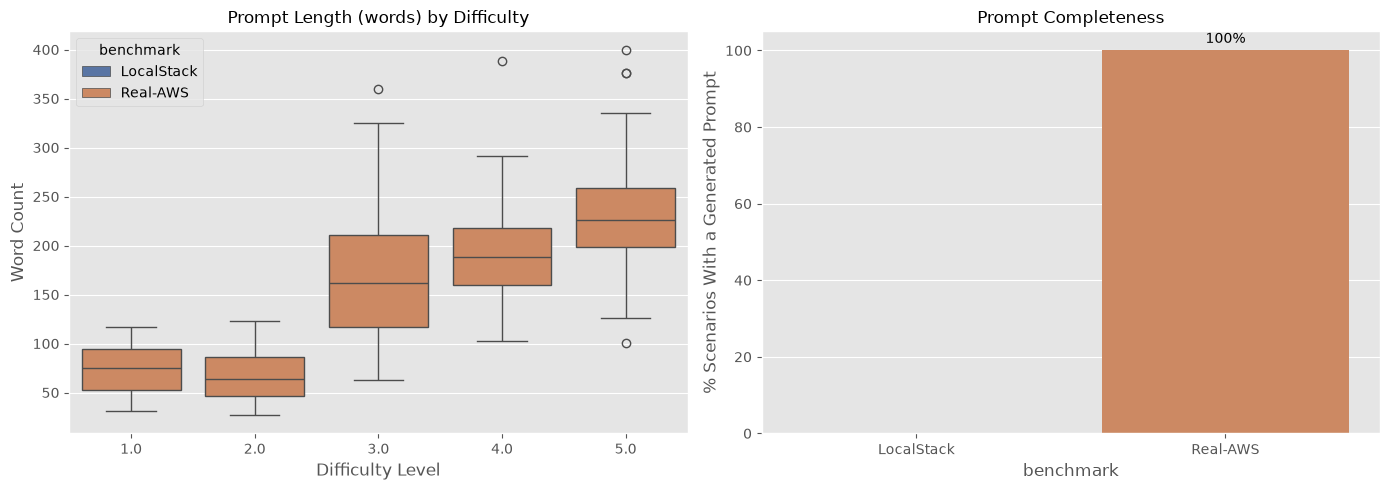

Prompt length (words) by benchmark:
            count   mean    50%   min    max
benchmark                                   
LocalStack    NaN    NaN    NaN   NaN    NaN
Real-AWS    250.0  147.5  138.5  27.0  400.0


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_compare, x='difficulty', y='prompt_word_count', hue='benchmark',
            hue_order=BENCHMARK_ORDER, palette=BENCHMARK_PALETTE, ax=axes[0])
axes[0].set_title('Prompt Length (words) by Difficulty', fontsize=12)
axes[0].set_xlabel('Difficulty Level')
axes[0].set_ylabel('Word Count')

completeness = df_compare.groupby('benchmark')['has_prompt'].mean().reindex(BENCHMARK_ORDER) * 100
sns.barplot(x=completeness.index, y=completeness.values,
            hue=completeness.index, palette=BENCHMARK_PALETTE, legend=False, ax=axes[1])
axes[1].set_title('Prompt Completeness', fontsize=12)
axes[1].set_ylabel('% Scenarios With a Generated Prompt')
axes[1].set_ylim(0, 105)
for i, v in enumerate(completeness.values):
    axes[1].text(i, v + 2, f'{v:.0f}%', ha='center')

plt.tight_layout()
plt.show()

print('Prompt length (words) by benchmark:')
print(df_compare.groupby('benchmark')['prompt_word_count'].describe()[['count', 'mean', '50%', 'min', 'max']].round(1)
      .reindex(BENCHMARK_ORDER).to_string())

Task was destroyed but it is pending!
task: <Task pending name='Task-170' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/iksena/miniconda3/lib/python3.13/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-171' coro=<Kernel.shell_main() running at /Users/iksena/miniconda3/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/iksena/miniconda3/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py:563]>
/Users/iksena/miniconda3/lib/python3.13/site-packages/IPython/core/inputtransformer2.py:628: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  tokens_by_line.append([])
Task was destroyed but it is pending!
task: <Task pending name='Task-171' coro=<Kernel.shell_main() running at /Users/iksena/miniconda3/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


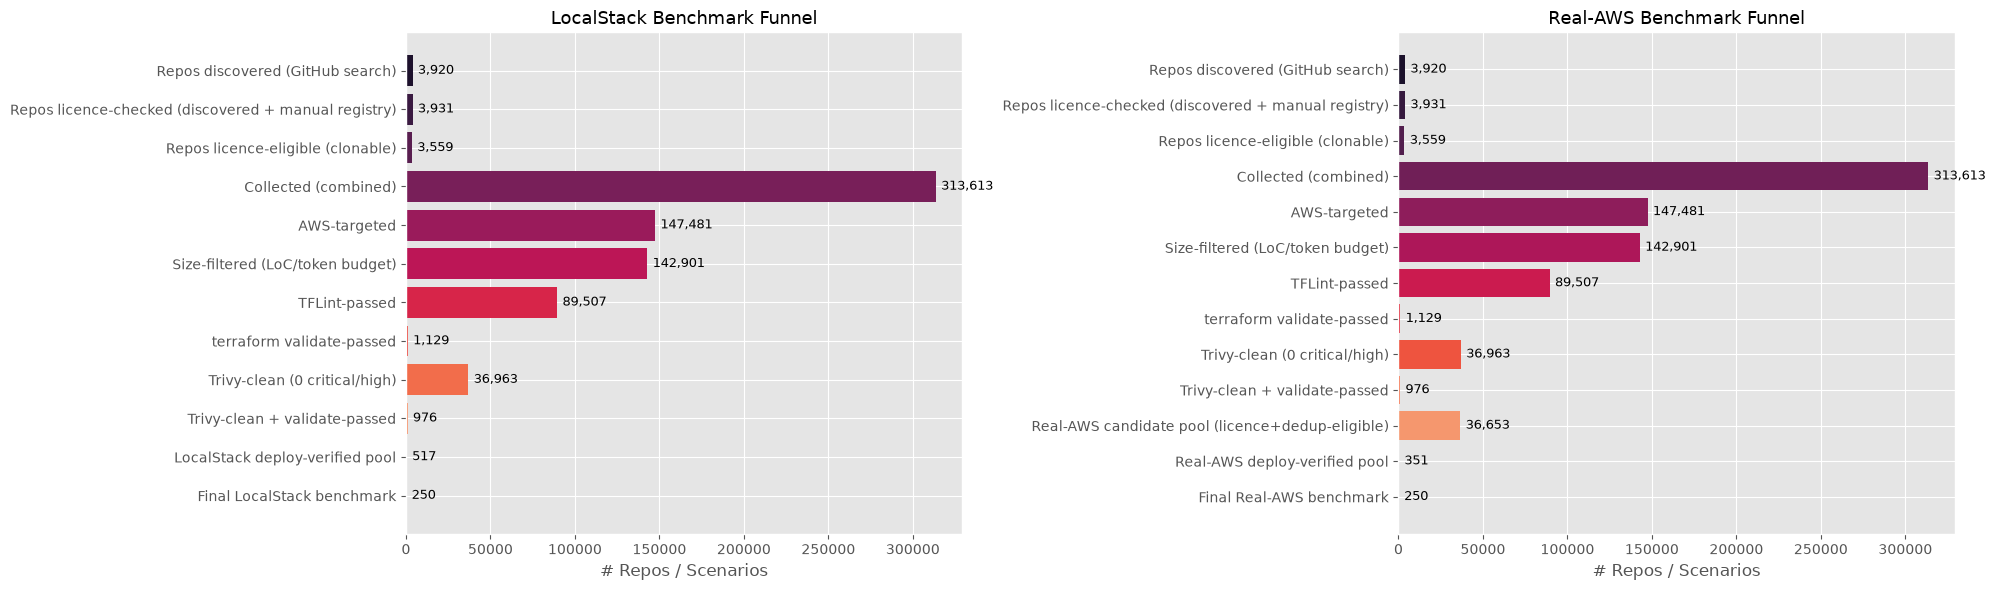

,Stage,LocalStack,Real-AWS
0,Repos discovered (GitHub search),3920.0,3920.0
1,Repos licence-checked (discovered + manual reg...,3931.0,3931.0
2,Repos licence-eligible (clonable),3559.0,3559.0
3,Collected (combined),313613.0,313613.0
4,AWS-targeted,147481.0,147481.0
5,Size-filtered (LoC/token budget),142901.0,142901.0
6,TFLint-passed,89507.0,89507.0
7,terraform validate-passed,1129.0,1129.0
8,Trivy-clean (0 critical/high),36963.0,36963.0
9,Trivy-clean + validate-passed,976.0,976.0


LocalStack overall yield: 250 / 313,613 collected = 0.08%
Real-AWS overall yield:   250 / 313,613 collected = 0.08%
Repo-to-benchmark yield: 250 LocalStack / 250 Real-AWS scenarios drawn from 3,920 discovered repos (3,559 licence-eligible).


In [26]:
def _csv_len(path, **kw):
    return len(pd.read_csv(path, low_memory=False, **kw)) if Path(path).exists() else np.nan

DISCOVERED_REPOS_CACHE_FUNNEL = DATASET_DIR / 'discovered_repos_cache.json'
LICENCE_CACHE_FUNNEL = DATASET_DIR / 'licence_cache.csv'

repo_stages = []
if DISCOVERED_REPOS_CACHE_FUNNEL.exists():
    with open(DISCOVERED_REPOS_CACHE_FUNNEL, 'r', encoding='utf-8') as _f:
        repo_stages.append(('Repos discovered (GitHub search)', len(json.load(_f))))
if LICENCE_CACHE_FUNNEL.exists():
    _licence_df_funnel = pd.read_csv(LICENCE_CACHE_FUNNEL, low_memory=False)
    repo_stages.append(('Repos licence-checked (discovered + manual registry)', len(_licence_df_funnel)))
    repo_stages.append(('Repos licence-eligible (clonable)',
                         int((_licence_df_funnel['eligible'] == True).sum())))

shared_stages = list(repo_stages)

_n_collected = _csv_len(PARSE_CACHE_FILE)
shared_stages.append(('Collected (combined)', _n_collected))

_aws_ids = set()
if AWS_CHECK_CACHE.exists():
    _aws_cache = pd.read_csv(AWS_CHECK_CACHE, low_memory=False)
    _aws_ids = set(_aws_cache.loc[_as_bool_series(_aws_cache['is_aws'].astype(str)), 'scenario_id'])
    shared_stages.append(('AWS-targeted', len(_aws_ids)))

if PARSE_CACHE_FILE.exists() and _aws_ids:
    _parsed = pd.read_csv(PARSE_CACHE_FILE, low_memory=False, usecols=['scenario_id', 'loc', 'tokens'])
    _parsed = _parsed[_parsed['scenario_id'].isin(_aws_ids)]
    _sized = _parsed[(_parsed['loc'] >= MIN_LOC) & (_parsed['tokens'] <= MAX_TOKENS)]
    shared_stages.append(('Size-filtered (LoC/token budget)', len(_sized)))

_tfl_pass_ids = set()
if TFLINT_CACHE_FILE.exists():
    _tfl = pd.read_csv(TFLINT_CACHE_FILE, low_memory=False, usecols=['scenario_id', 'tflint_passed'])
    _tfl_pass_ids = set(_tfl.loc[_tfl['tflint_passed'] == True, 'scenario_id'])
    shared_stages.append(('TFLint-passed', len(_tfl_pass_ids)))

_vc = load_validate_cache()
_vpass_ids = set(_vc.loc[_as_bool_series(_vc['validate_passed']), 'scenario_id']) if len(_vc) else set()
shared_stages.append(('terraform validate-passed', len(_vpass_ids)))

_trivy_clean_ids = set()
if TRIVY_FILTERED_CSV.exists():
    _trivy_clean = pd.read_csv(TRIVY_FILTERED_CSV, low_memory=False, usecols=['scenario_id'])
    _trivy_clean_ids = set(_trivy_clean['scenario_id'])
    shared_stages.append(('Trivy-clean (0 critical/high)', len(_trivy_clean_ids)))

_gate_ids = _trivy_clean_ids & _vpass_ids
shared_stages.append(('Trivy-clean + validate-passed', len(_gate_ids)))

localstack_stages = list(shared_stages)
if DEPLOY_PASSED_CSV.exists():
    localstack_stages.append(('LocalStack deploy-verified pool', _csv_len(DEPLOY_PASSED_CSV)))
localstack_stages.append(('Final LocalStack benchmark', len(df_localstack)))

real_aws_stages = list(shared_stages)
if REAL_AWS_POOL_CSV.exists():
    _real_aws_pool_funnel = pd.read_csv(REAL_AWS_POOL_CSV, low_memory=False, usecols=['scenario_id'])
    _pool_ids_funnel = set(_real_aws_pool_funnel['scenario_id'])
    real_aws_stages.append(('Real-AWS candidate pool (licence+dedup-eligible)', len(_pool_ids_funnel)))
    if GT_DEPLOY_CACHE_PATH.exists():
        _gt_funnel = pd.read_csv(GT_DEPLOY_CACHE_PATH, low_memory=False, usecols=['scenario_id', 'deploy_pass'])
        _n_real_aws_verified = int(
            _gt_funnel.loc[_gt_funnel['scenario_id'].isin(_pool_ids_funnel), 'deploy_pass'].eq(True).sum())
        real_aws_stages.append(('Real-AWS deploy-verified pool', _n_real_aws_verified))
real_aws_stages.append(('Final Real-AWS benchmark', len(df_real_aws)))

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, stages, title in zip(
    axes, [localstack_stages, real_aws_stages],
    ['LocalStack Benchmark Funnel', 'Real-AWS Benchmark Funnel'],
):
    funnel_df = pd.DataFrame(stages, columns=['Stage', 'Count']).dropna()
    bars = ax.barh(funnel_df['Stage'], funnel_df['Count'], color=sns.color_palette('rocket', len(funnel_df)))
    ax.invert_yaxis()
    ax.set_xlabel('# Repos / Scenarios')
    ax.set_title(title, fontsize=13)
    _max = funnel_df['Count'].max() if len(funnel_df) else 0
    for bar, count in zip(bars, funnel_df['Count']):
        ax.text(bar.get_width() + _max * 0.01, bar.get_y() + bar.get_height() / 2,
                 f'{int(count):,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

_ls_map = dict(localstack_stages)
_ra_map = dict(real_aws_stages)
_stage_order = list(dict.fromkeys([s for s, _ in localstack_stages] + [s for s, _ in real_aws_stages]))
display(pd.DataFrame(
    [(s, _ls_map.get(s), _ra_map.get(s)) for s in _stage_order],
    columns=['Stage', 'LocalStack', 'Real-AWS'],
))

if _n_collected:
    print(f'LocalStack overall yield: {len(df_localstack):,} / {_n_collected:,} collected = '
          f'{len(df_localstack) / _n_collected:.2%}')
    if len(df_real_aws):
        print(f'Real-AWS overall yield:   {len(df_real_aws):,} / {_n_collected:,} collected = '
              f'{len(df_real_aws) / _n_collected:.2%}')
if repo_stages:
    print(f'Repo-to-benchmark yield: {len(df_localstack):,} LocalStack / {len(df_real_aws):,} Real-AWS scenarios '
          f'drawn from {repo_stages[0][1]:,} discovered repos '
          f'({repo_stages[-1][1]:,} licence-eligible).')

In [22]:
summary_rows = []
for bench_name, df_b in [('LocalStack', df_localstack), ('Real-AWS', df_real_aws)]:
    if df_b.empty:
        continue
    summary_rows.append({
        'Benchmark': bench_name,
        'Total Scenarios': len(df_b),
        'Levels Full (50/50)': int((df_b['difficulty'].value_counts() >= 50).sum()) if len(df_b) else 0,
        'Avg LOC': round(df_b['loc'].mean(), 1) if 'loc' in df_b.columns else None,
        'Avg #Resources': round(df_b['n_resources'].mean(), 1) if 'n_resources' in df_b.columns else None,
        'Avg #Params': round(df_b['n_params'].mean(), 1) if 'n_params' in df_b.columns else None,
        'Distinct Sources': df_b['source'].nunique() if 'source' in df_b.columns else None,
        'Prompts Complete': f"{df_b['user_prompt'].notna().mean():.1%}" if 'user_prompt' in df_b.columns else None,
    })

summary_df = pd.DataFrame(summary_rows).set_index('Benchmark')
display(summary_df)
print(summary_df.to_markdown())

,Total Scenarios,Levels Full (50/50),Avg LOC,Avg #Resources,Avg #Params,Distinct Sources,Prompts Complete
Benchmark,,,,,,,
LocalStack,250,5,312.0,10.1,11.2,9,91.6%
Real-AWS,250,5,283.5,10.5,8.6,9,100.0%


| Benchmark   |   Total Scenarios |   Levels Full (50/50) |   Avg LOC |   Avg #Resources |   Avg #Params |   Distinct Sources | Prompts Complete   |
|:------------|------------------:|----------------------:|----------:|-----------------:|--------------:|-------------------:|:-------------------|
| LocalStack  |               250 |                     5 |     312   |             10.1 |          11.2 |                  9 | 91.6%              |
| Real-AWS    |               250 |                     5 |     283.5 |             10.5 |           8.6 |                  9 | 100.0%             |


,Benchmark,Scenarios,Avg LoC,Avg # Resources,AWS Services,Difficulty Levels
0,This benchmark (LocalStack),250,312.0,10.1,67,5.0
1,This benchmark (Real-AWS),250,283.5,10.5,61,5.0
2,DPIaC-Eval,153,155.0,7.0,58,5.0
3,IaC-Eval,458,42.0,4.0,~60,6.0
4,Multi-IaC-Eval (TF),446,49.4,3.5,47,NaN


Note: Multi-IaC-Eval's AWS Services count includes a coarse fallback for `awscc_*` resource types (not covered by the aws_*-only registry mapping) -- not directly apples-to-apples with the other rows' registry-only service counts.


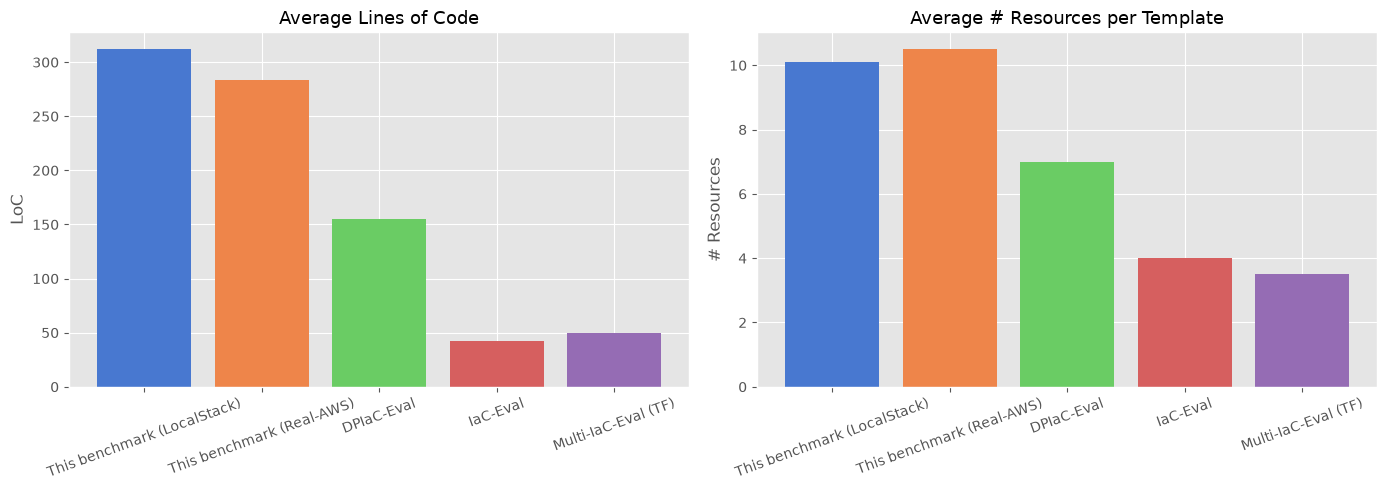

In [23]:
import json

_TF_REGISTRY_DOCS_PATH = Path('../tf_registry_docs.json')
_resource_to_service = {}
if _TF_REGISTRY_DOCS_PATH.exists():
    _registry_docs = json.loads(_TF_REGISTRY_DOCS_PATH.read_text())
    _resource_to_service = {k: v.get('subcategory') for k, v in _registry_docs.items() if v.get('subcategory')}
else:
    print(f"⚠️ {_TF_REGISTRY_DOCS_PATH} not found -- AWS Services row will fall back to raw "
          f"resource-type counts (NOT directly comparable to DPIaC-Eval/IaC-Eval's service counts).")

def _n_unique_services(df_b):
    if df_b.empty or 'aws_services' not in df_b.columns:
        return None
    resource_types = set()
    for s in df_b['aws_services'].dropna():
        resource_types.update(x.strip() for x in str(s).split(',') if x.strip())
    if _resource_to_service:
        services = {_resource_to_service.get(rt, rt) for rt in resource_types}
        return len(services)
    return len(resource_types)

n_unique_services_by_bench = {
    'LocalStack': _n_unique_services(df_localstack),
    'Real-AWS': _n_unique_services(df_real_aws),
}

MULTI_IAC_EVAL_TF_CACHE_PATH = DATASET_DIR / 'multi_iac_eval_tf_cache.json'
multi_iac_eval_tf_stats = {'Scenarios': None, 'Avg LoC': None, 'Avg # Resources': None, 'AWS Services': None}
_RESOURCE_BLOCK_RE = re.compile(r'resource\s+"([a-zA-Z0-9_]+)"')

if MULTI_IAC_EVAL_TF_CACHE_PATH.exists():
    with open(MULTI_IAC_EVAL_TF_CACHE_PATH, 'r', encoding='utf-8') as f:
        _multi_iac_eval_tf_raw = json.load(f)

    if _multi_iac_eval_tf_raw:
        _mie_locs = []
        _mie_n_resources = []
        _mie_svc_counter = Counter()
        for _rec in _multi_iac_eval_tf_raw:
            _content = _rec.get('content') or ''
            _mie_locs.append(_content.count('\n') + 1)
            _types = _RESOURCE_BLOCK_RE.findall(_content)
            _mie_n_resources.append(len(_types))
            for _t in _types:
                if _t in _resource_to_service:
                    _svc = _resource_to_service[_t]
                elif '_' in _t:
                    _parts = _t.split('_')
                    _svc = _parts[1] if _parts[0] in ('aws', 'awscc') and len(_parts) > 1 else _parts[0]
                else:
                    _svc = _t
                _mie_svc_counter[_svc] += 1

        multi_iac_eval_tf_stats = {
            'Scenarios': len(_multi_iac_eval_tf_raw),
            'Avg LoC': round(sum(_mie_locs) / len(_mie_locs), 1),
            'Avg # Resources': round(sum(_mie_n_resources) / len(_mie_n_resources), 1),
            'AWS Services': len(_mie_svc_counter),
        }
else:
    print(f'  {MULTI_IAC_EVAL_TF_CACHE_PATH} not found -- Multi-IaC-Eval row will be blank. '
          f'Run §7 of this notebook / TF_Benchmark_Pipeline.ipynb at least once first.')

comparison = pd.DataFrame({
    'Benchmark': ['This benchmark (LocalStack)', 'This benchmark (Real-AWS)', 'DPIaC-Eval', 'IaC-Eval',
                  'Multi-IaC-Eval (TF)'],
    'Scenarios': [
        len(df_localstack),
        len(df_real_aws) or None,
        153, 458, multi_iac_eval_tf_stats['Scenarios'],
    ],
    'Avg LoC': [
        round(df_localstack['loc'].mean(), 1),
        round(df_real_aws['loc'].mean(), 1) if len(df_real_aws) else None,
        155, 42, multi_iac_eval_tf_stats['Avg LoC'],
    ],
    'Avg # Resources': [
        round(df_localstack['n_resources'].mean(), 1),
        round(df_real_aws['n_resources'].mean(), 1) if len(df_real_aws) else None,
        7, 4, multi_iac_eval_tf_stats['Avg # Resources'],
    ],
    'AWS Services': [
        n_unique_services_by_bench.get('LocalStack'),
        n_unique_services_by_bench.get('Real-AWS') or None,
        58, '~60', multi_iac_eval_tf_stats['AWS Services'],
    ],
    'Difficulty Levels': [5, 5 if len(df_real_aws) else None, 5, 6, None],
})
display(comparison)
print('Note: Multi-IaC-Eval\'s AWS Services count includes a coarse fallback for `awscc_*` '
      'resource types (not covered by the aws_*-only registry mapping) -- not directly '
      'apples-to-apples with the other rows\' registry-only service counts.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bench_names = comparison['Benchmark']
avg_loc_plot = pd.to_numeric(comparison['Avg LoC'], errors='coerce').fillna(0)
avg_res_plot = pd.to_numeric(comparison['Avg # Resources'], errors='coerce').fillna(0)

axes[0].bar(bench_names, avg_loc_plot, color=sns.color_palette('muted'))
axes[0].set_title('Average Lines of Code', fontsize=13)
axes[0].set_ylabel('LoC')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(bench_names, avg_res_plot, color=sns.color_palette('muted'))
axes[1].set_title('Average # Resources per Template', fontsize=13)
axes[1].set_ylabel('# Resources')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Appendix: Maintenance Utilities (all gated off)

In [24]:
RUN_TFLINT_WARNING_CLEANUP = False

if not RUN_TFLINT_WARNING_CLEANUP:
    print('⏸️  RUN_TFLINT_WARNING_CLEANUP is False -- skipping TFLint warning-only cache cleanup.')
else:
    import pandas as pd
    from pathlib import Path

    DATASET_DIR = Path('./iac_benchmark/dataset') 
    TFLINT_CACHE_FILE = DATASET_DIR / 'tflint_cache.csv'

    if TFLINT_CACHE_FILE.exists():
        df_cache = pd.read_csv(TFLINT_CACHE_FILE)
        original_count = len(df_cache)
    
        def has_only_warnings(log_text):
            if not isinstance(log_text, str) or not log_text.strip():
                return False
            
            text_upper = log_text.upper()
            has_warn = 'WARNING:' in text_upper
            has_err = 'ERROR' in text_upper or 'SYSTEM ERROR' in text_upper or 'TIMEOUT' in text_upper
        
            return has_warn and not has_err

        mask_to_keep = ~df_cache['tflint_log'].apply(has_only_warnings)
        df_cleaned = df_cache[mask_to_keep].copy()
    
        df_cleaned.to_csv(TFLINT_CACHE_FILE, index=False)
    
        dropped_count = original_count - len(df_cleaned)
        print(f"🧹 TFLint cache cleaned successfully!")
        print(f"  -> Original rows : {original_count}")
        print(f"  -> Dropped rows  : {dropped_count} (warning-only logs)")
        print(f"  -> New cache size: {len(df_cleaned)}\n")
        print("Next step: Re-run Cell 11 to re-evaluate the dropped scenarios with the clean logic.")
    else:
        print(f"⚠️ Cache file not found at {TFLINT_CACHE_FILE}")

⏸️  RUN_TFLINT_WARNING_CLEANUP is False -- skipping TFLint warning-only cache cleanup.


In [25]:
RUN_RETRO_METRIC_UPDATE = False

if not RUN_RETRO_METRIC_UPDATE:
    print('⏸️  RUN_RETRO_METRIC_UPDATE is False -- skipping retroactive metric propagation.')
else:
    import pandas as pd
    from pathlib import Path

    DATASET_DIR = Path('./iac_benchmark/dataset')
    PARSE_CACHE_FILE = DATASET_DIR / 'ast_parse_cache.csv'

    if not PARSE_CACHE_FILE.exists():
        raise FileNotFoundError(f"⚠️ {PARSE_CACHE_FILE.name} not found. Run Cell 8 first to generate the source of truth.")

    df_ast = pd.read_csv(PARSE_CACHE_FILE)

    def calculate_difficulty(row):
        loc = row['loc']
        res = row['n_resources']
        if loc >= 400 and res >= 12: return 5
        elif loc >= 250 and res >= 8:  return 4
        elif loc >= 150 and res >= 4:  return 3
        elif loc >= 80  and res >= 2:  return 2
        else: return 1

    df_ast['difficulty'] = df_ast.apply(calculate_difficulty, axis=1)

    truth_cols = ['scenario_id', 'loc', 'tokens', 'n_resources', 'n_params', 'difficulty']
    df_truth = df_ast[truth_cols].copy()

    caches_to_update = [
        'validation_pipeline_batch.csv',
        'tflint_cache.csv',
        'tflint_passed_batch.csv',
        'trivy_cache.csv',
        'trivy_scanned_batch.csv',
        'trivy_filtered_batch.csv',
        'deploy_cache.csv',
        'deploy_passed_batch.csv',
        'level5_deploy_failures.csv'
    ]

    print("🔄 Propagating corrected metrics & difficulty to all caches...\n")

    for cache_name in caches_to_update:
        cache_path = DATASET_DIR / cache_name
    
        if cache_path.exists():
            try:
                df_target = pd.read_csv(cache_path)
                _mf_rows = (df_target[df_target['scenario_id'].astype(str).str.endswith('_manualfix')]
                            if 'scenario_id' in df_target.columns else df_target.iloc[0:0])
                df_target = df_target.drop(_mf_rows.index)
            
                if 'scenario_id' in df_target.columns:
                    original_len = len(df_target)
                
                    cols_to_drop = [c for c in truth_cols if c in df_target.columns and c != 'scenario_id']
                
                    if cols_to_drop:
                        df_target = df_target.drop(columns=cols_to_drop)
                
                    df_updated = df_target.merge(df_truth, on='scenario_id', how='left')
                
                    orphans = df_updated['difficulty'].isna().sum()
                    if orphans > 0:
                        df_updated = df_updated.dropna(subset=['difficulty'])
                
                    df_updated = pd.concat([df_updated, _mf_rows], ignore_index=True, sort=False)
                    df_updated.to_csv(cache_path, index=False)
                
                    orphan_msg = f" (Dropped {orphans} orphaned scenarios)" if orphans > 0 else ""
                    print(f"  ✅ Updated {cache_name:30} -> {len(df_updated)} rows{orphan_msg}")
                else:
                    print(f"  ⚠️ Skipped {cache_name:30} -> No 'scenario_id' column found.")
                
            except Exception as e:
                print(f"  ❌ Failed to update {cache_name}: {e}")
            
    print("\n🎉 All caches successfully synchronized with strict AWS resource counts and difficulty!")

⏸️  RUN_RETRO_METRIC_UPDATE is False -- skipping retroactive metric propagation.
